# Objective 01 — Newtonian Gravity at One Instant

 We first define a planetary system, then calculate pairwise forces, total acceleration, and the center of mass. Finally, we generate a diagram and a numerical report. **We are not integrating orbits yet.**

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

## Objective 1A — Describe our system
Each row contains one body. The first column of a position gives its x-coordinate, and the second gives its y-coordinate. Our units are normalized, with gravitational constant G = 1.

In [3]:
# Each row of positions and velocities represents one object.
# For example positions[1] = [1.0, 0.0] means planet 1 is at x=1, y=0.
# Velocity is included so we learn the full structure of a dynamical state.
# We will use it to MOVE the bodies in the next objective; it does not enter
# Newtonian gravitational acceleration at a given instant.

G = 1.0
NAMES = ("Star", "Planet A", "Planet B")
MASSES = np.array([1.0, 0.001, 0.002], dtype=float)
POSITIONS = np.array([
    [0.0, 0.0],     # Star
    [1.0, 0.0],     # Planet A
    [0.0, 1.6],     # Planet B
], dtype=float)
VELOCITIES = np.array([
    [0.0, 0.0],     # Star (illustrative snapshot, not a stable orbit)
    [0.0, 1.0],     # Planet A
    [-0.8, 0.0],    # Planet B
], dtype=float)

## Objective 1B — Check the inputs
Before doing physics, verify that masses and vectors have sensible dimensions and values.

In [4]:
def validate_system(masses: np.ndarray,
                    positions: np.ndarray,
                    velocities: np.ndarray) -> None:
    """Reject malformed inputs rather than producing misleading answers."""
    if masses.ndim != 1:
        raise ValueError("masses must be a one-dimensional array")
    n = len(masses)
    if n < 2:
        raise ValueError("at least two bodies are needed for this example")
    if positions.shape != (n, 2) or velocities.shape != (n, 2):
        raise ValueError("positions and velocities must each have shape (N, 2)")
    if not (np.all(np.isfinite(masses))
            and np.all(np.isfinite(positions))
            and np.all(np.isfinite(velocities))):
        raise ValueError("all masses, positions, and velocities must be finite")
    if np.any(masses <= 0):
        raise ValueError("all masses must be strictly positive")
    for i in range(n):
        for j in range(i + 1, n):
            if np.array_equal(positions[i], positions[j]):
                raise ValueError(f"{i} and {j} occupy the same position")

## Objective 1C — Gravity between two bodies
The force on body i points toward body j. Reverse the bodies and the force changes sign, as Newton’s third law requires.

In [5]:
def gravitational_force_on_i_from_j(
    r_i: np.ndarray, r_j: np.ndarray, m_i: float, m_j: float, G_value: float = G
) -> np.ndarray:
    """Vector force ON i DUE TO j: F_ij = G m_i m_j (r_j-r_i)/|r_j-r_i|^3."""
    displacement = r_j - r_i       # Direction: from object i toward object j.
    distance = np.linalg.norm(displacement)
    if distance == 0:
        raise ValueError("gravitational point masses cannot occupy the same point")
    return G_value * m_i * m_j * displacement / distance**3

## Objective 1D — Add the effects of every body
Sum the gravitational acceleration contributions from all other bodies. This is the main physics engine we will reuse later.

In [6]:
def gravitational_accelerations(
    positions: np.ndarray, masses: np.ndarray, G_value: float = G
) -> np.ndarray:
    """Return a[i] = sum_j G*m[j]*(r[j]-r[i]) / |r[j]-r[i]|^3.

    Why does the body's own mass not appear in its acceleration?
    Because F = m_i*a_i, and Newtonian gravitational force contains m_i.
    Dividing the total force by m_i cancels that factor. A body's acceleration
    still depends on other bodies' masses and on their relative positions.
    """
    n = len(masses)
    a = np.zeros_like(positions, dtype=float)
    for i in range(n):
        for j in range(n):
            if i == j:
                continue  # An object does not exert gravitational force on itself.
            difference = positions[j] - positions[i]
            distance = np.linalg.norm(difference)
            if distance == 0:
                raise ValueError("overlapping point masses give undefined force")
            a[i] += G_value * masses[j] * difference / distance**3
    return a

## Objective 1E — Center of mass and momentum
These quantities help us check whether the state of our gravitational system makes physical sense.

In [7]:
def center_of_mass(positions: np.ndarray, masses: np.ndarray) -> np.ndarray:
    """Weighted average location: sum_i(m_i*r_i)/sum_i(m_i)."""
    return np.sum(masses[:, None] * positions, axis=0) / np.sum(masses)


def total_momentum(velocities: np.ndarray, masses: np.ndarray) -> np.ndarray:
    """Vector momentum: sum_i m_i*v_i. Useful in later orbit calculations."""
    return np.sum(masses[:, None] * velocities, axis=0)

## Objective 1F — Explain and draw the result
We will output a readable report and plot the velocity and acceleration arrows. Their lengths are rescaled for legibility, not to preserve absolute magnitudes.

In [8]:
def make_report(masses, positions, velocities, a) -> str:
    lines = [
        "OBJECTIVE 01 — NEWTONIAN GRAVITY AT A SINGLE INSTANT",
        "=" * 58,
        "Units are normalized: G = 1. This is NOT an orbital simulation yet.",
        "",
        "Each body has a mass m, position r=(x,y), velocity v=(vx,vy),",
        "and an acceleration a=(ax,ay) caused by other objects.",
        "",
    ]
    for i, name in enumerate(NAMES):
        lines += [
            f"{name}:",
            f"  mass             = {masses[i]:.6f}",
            f"  position         = {positions[i]}",
            f"  velocity         = {velocities[i]}",
            f"  acceleration     = {a[i]}",
            f"  |acceleration|   = {np.linalg.norm(a[i]):.9f}",
            "",
        ]

    lines += ["PAIRWISE FORCES (Newton's third law)"]
    for i in range(len(masses)):
        for j in range(i + 1, len(masses)):
            force_ij = gravitational_force_on_i_from_j(
                positions[i], positions[j], masses[i], masses[j]
            )
            force_ji = gravitational_force_on_i_from_j(
                positions[j], positions[i], masses[j], masses[i]
            )
            lines.append(f"  {NAMES[j]} on {NAMES[i]}: {force_ij}")
            lines.append(f"  {NAMES[i]} on {NAMES[j]}: {force_ji}")
            lines.append(f"  Sum (approximately zero): {force_ij + force_ji}")

    com = center_of_mass(positions, masses)
    p = total_momentum(velocities, masses)
    net_internal_force = np.sum(masses[:, None] * a, axis=0)
    lines += [
        "",
        f"Center of mass = {com}",
        f"Total momentum = {p}",
        f"Sum of all gravitational forces = {net_internal_force}",
        "(The last sum should be approximately zero: internal forces cancel.)",
        "",
        "WHAT TO NOTICE:",
        "* The arrow for acceleration points toward the combined pull of other bodies.",
        "* A large mass can have a small acceleration, even when its force is real.",
        "* Acceleration is not the same as velocity; a body can move in one",
        "  direction while gravity bends its motion toward another direction.",
        "* None of this yet proves whether an orbit is stable or chaotic.",
    ]
    return "\n".join(lines)


def make_figure(masses, positions, velocities, accelerations, output_path):
    """Draw current positions, blue velocity arrows, and red gravity arrows."""
    fig, ax = plt.subplots(figsize=(9.3, 7.0))
    fig.patch.set_facecolor("#08152b")
    ax.set_facecolor("#0e1f38")

    # Arrow scaling is VISUAL ONLY. Physical values appear in the report.
    velocity_scale = 0.43
    gravity_scale = 0.34 / max(np.linalg.norm(accelerations, axis=1).max(), 1e-12)
    colors = ("#f7c96d", "#8fd1ff", "#d7a5ff")

    for i, name in enumerate(NAMES):
        x, y = positions[i]
        marker_size = 340 if i == 0 else 115
        ax.scatter(x, y, s=marker_size, c=colors[i], edgecolor="white",
                   linewidth=0.8, zorder=5)
        ax.annotate(name, (x, y), xytext=(10, 13), textcoords="offset points",
                    color="white", fontsize=11, weight="bold")
        ax.arrow(x, y, velocities[i, 0] * velocity_scale,
                 velocities[i, 1] * velocity_scale,
                 color="#6bc4e9", width=0.008, head_width=0.045,
                 length_includes_head=True, zorder=4)
        ax.arrow(x, y, accelerations[i, 0] * gravity_scale,
                 accelerations[i, 1] * gravity_scale,
                 color="#ff806b", width=0.008, head_width=0.045,
                 length_includes_head=True, zorder=4)

    com = center_of_mass(positions, masses)
    ax.scatter(*com, s=100, marker="x", c="white", linewidths=2, zorder=6)
    ax.text(0.02, 0.03, "BLUE = velocity     CORAL = gravity acceleration     X = center of mass",
            transform=ax.transAxes, color="white", fontsize=10,
            bbox=dict(facecolor="#102b47", edgecolor="none", alpha=0.9, pad=8))
    ax.set_xlim(-0.5, 1.7)
    ax.set_ylim(-0.5, 2.15)
    ax.set_aspect("equal")
    ax.set_xlabel("x (normalized length)", color="white")
    ax.set_ylabel("y (normalized length)", color="white")
    ax.set_title("Objective 01 | A Snapshot of a Three-Body System",
                 color="white", fontsize=15, pad=18)
    ax.tick_params(colors="white")
    for spine in ax.spines.values():
        spine.set_color("#7c97b1")
    ax.grid(alpha=0.17, color="white", linestyle="--")
    fig.tight_layout()
    fig.savefig(output_path, dpi=180, facecolor=fig.get_facecolor())
    plt.close(fig)

## Objective 1G — Run the calculation
This cell checks that all internal forces cancel to numerical precision, prints the complete report, saves the output files in `objective_01_output`, and displays the figure.

OBJECTIVE 01 — NEWTONIAN GRAVITY AT A SINGLE INSTANT
Units are normalized: G = 1. This is NOT an orbital simulation yet.

Each body has a mass m, position r=(x,y), velocity v=(vx,vy),
and an acceleration a=(ax,ay) caused by other objects.

Star:
  mass             = 1.000000
  position         = [0. 0.]
  velocity         = [0. 0.]
  acceleration     = [0.001      0.00078125]
  |acceleration|   = 0.001268996

Planet A:
  mass             = 0.001000
  position         = [1. 0.]
  velocity         = [0. 1.]
  acceleration     = [-1.00029775e+00  4.76403542e-04]
  |acceleration|   = 1.000297866

Planet B:
  mass             = 0.002000
  position         = [0.  1.6]
  velocity         = [-0.8  0. ]
  acceleration     = [ 1.48876107e-04 -3.90863202e-01]
  |acceleration|   = 0.390863230

PAIRWISE FORCES (Newton's third law)
  Planet A on Star: [0.001 0.   ]
  Star on Planet A: [-0.001  0.   ]
  Sum (approximately zero): [0. 0.]
  Planet B on Star: [0.         0.00078125]
  Star on Planet B: 

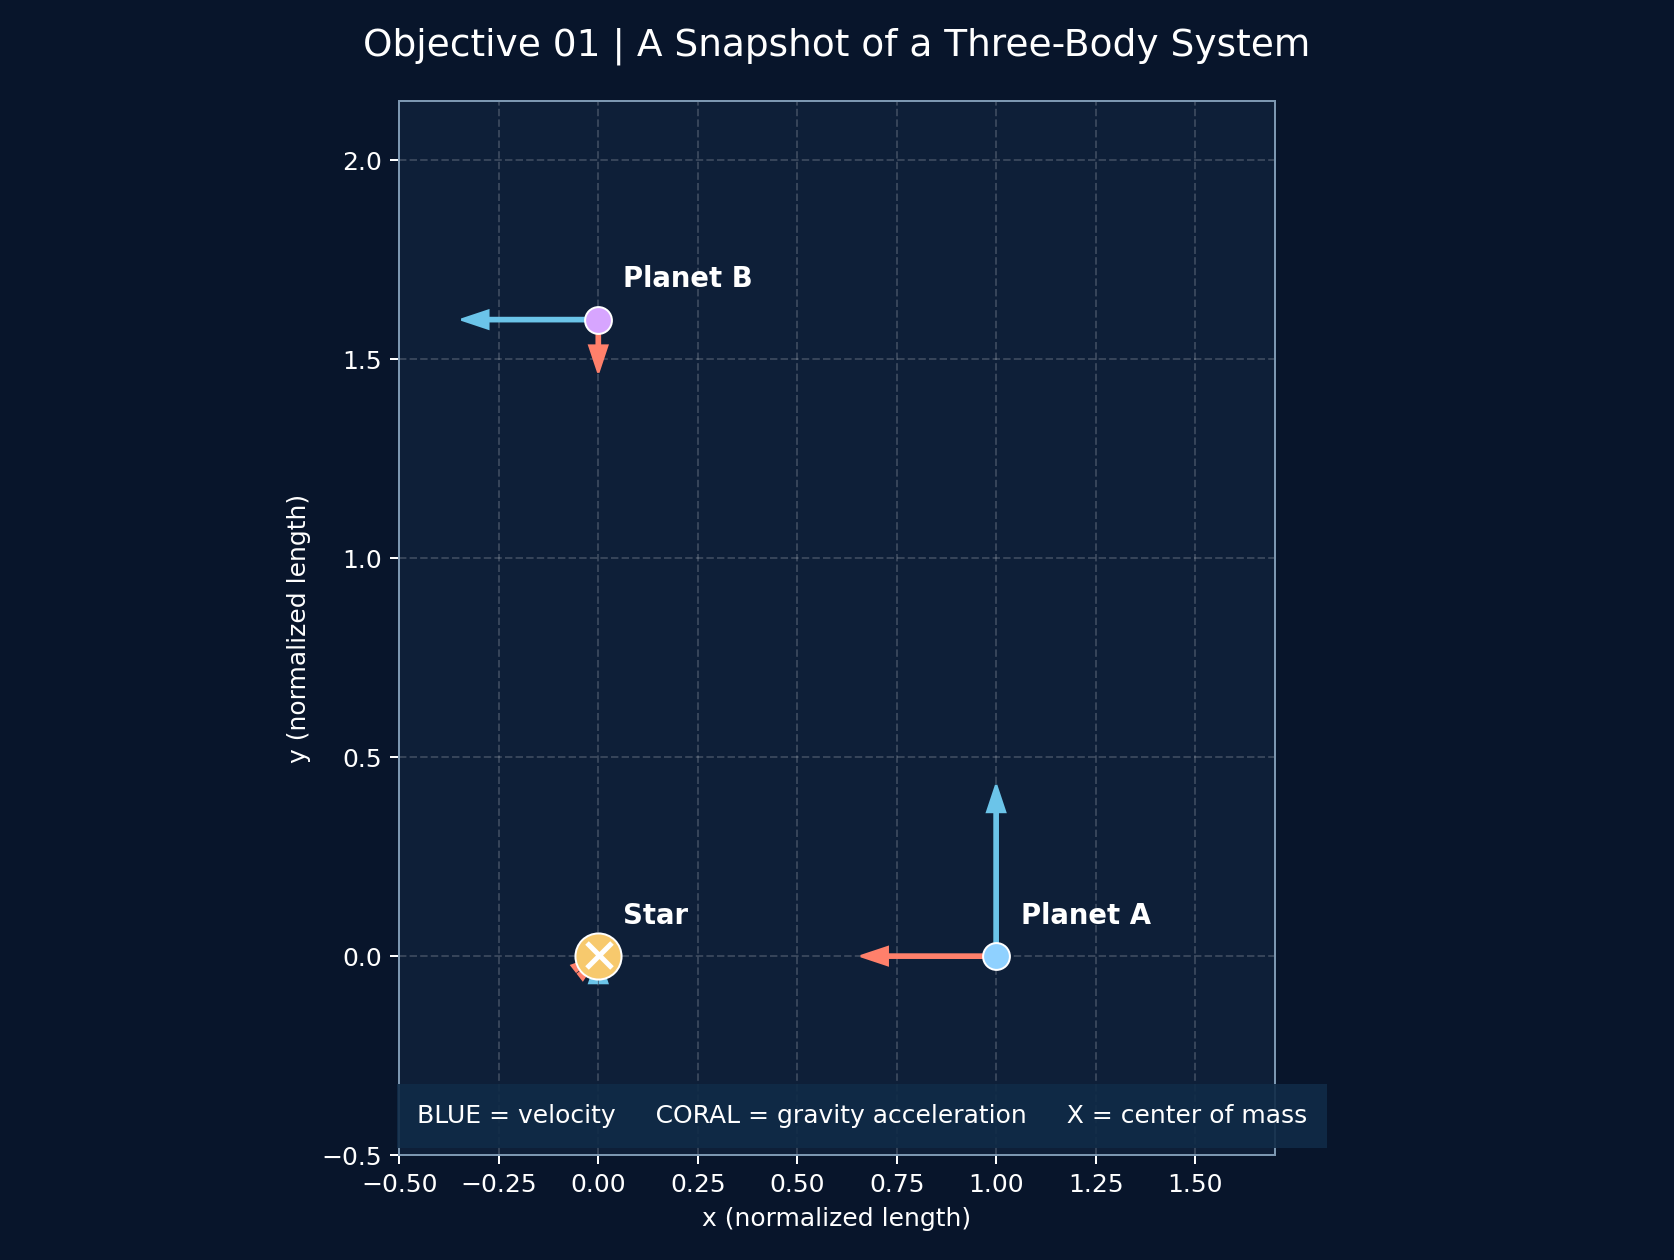

In [9]:
validate_system(MASSES, POSITIONS, VELOCITIES)
accelerations = gravitational_accelerations(POSITIONS, MASSES)
net_force = np.sum(MASSES[:, None] * accelerations, axis=0)
assert np.allclose(net_force, [0, 0], atol=1e-12, rtol=0), "Internal forces do not cancel"

output_dir = Path.cwd() / "objective_01_output"
output_dir.mkdir(parents=True, exist_ok=True)
report = make_report(MASSES, POSITIONS, VELOCITIES, accelerations)
(output_dir / "results.txt").write_text(report + "\n", encoding="utf-8")
make_figure(MASSES, POSITIONS, VELOCITIES, accelerations, output_dir / "acceleration_vectors.png")
print(report)
print("\nSaved output to:", output_dir)
from IPython.display import display, Image
display(Image(filename=str(output_dir / "acceleration_vectors.png")))


# Objective 02 — Simulating Gravitational Motion

## 2.1 From a snapshot to a moving system

In Objective 01, we calculated gravitational acceleration for a system containing one star and two planets.

However, a gravitational acceleration is only an instantaneous quantity. It tells us how the velocity is changing at one particular moment.

To simulate motion, we must continuously update two quantities:

1. **Position:** Where is each object?
2. **Velocity:** How fast is each object moving, and in which direction?

Newton's second law tells us that gravitational acceleration changes velocity.

Velocity, in turn, changes position.

This creates a repeating process:

**Calculate gravity → Update velocity and position → Calculate gravity again → Repeat.**

We will first implement this process using the Forward Euler method.

This algorithm is intentionally simple. It will help us understand how numerical integration works before we move to more accurate methods.



## 2.2 How does a computer update motion?

Velocity describes the rate of change of position:

$$
\mathbf{v}=\frac{d\mathbf{r}}{dt}
$$

Acceleration describes the rate of change of velocity:

$$
\mathbf{a}=\frac{d\mathbf{v}}{dt}
$$

For a sufficiently small time interval $\Delta t$, we can approximate these derivatives.

The position update becomes:

$$
\boxed{\mathbf{r}_{n+1}=\mathbf{r}_n+\mathbf{v}_n\Delta t}
$$

The velocity update becomes:

$$
\boxed{\mathbf{v}_{n+1}=\mathbf{v}_n+\mathbf{a}_n\Delta t}
$$

Here:

- $n$ represents the current timestep.
- $n+1$ represents the next timestep.
- $\mathbf{r}$ is position.
- $\mathbf{v}$ is velocity.
- $\mathbf{a}$ is gravitational acceleration.
- $\Delta t$ is the duration of one timestep.

Both updates use information from the beginning of the timestep.

### A simple numerical example

Suppose a planet has:

$$
x=5,\qquad v_x=2,\qquad a_x=-0.5
$$

We choose:

$$
\Delta t=0.1
$$

The updated position is:

$$
x_{\mathrm{new}}=5+(2)(0.1)=5.2
$$

The updated velocity is:

$$
v_{x,\mathrm{new}}=2+(-0.5)(0.1)=1.95
$$

After one timestep:

- Position changes from 5 to 5.2.
- Velocity changes from 2 to 1.95.

The planet moves forward, but its velocity decreases because acceleration acts in the opposite direction.

This is the basic idea behind Euler integration.


In [10]:

def euler_step(positions, velocities, masses, dt):
    """
    Advance the gravitational system by one timestep.

    Parameters
    ----------
    positions : ndarray, shape (N, 2)
        Current positions of all bodies.

    velocities : ndarray, shape (N, 2)
        Current velocities of all bodies.

    masses : ndarray, shape (N,)
        Masses of the bodies.

    dt : float
        Duration of one timestep.

    Returns
    -------
    new_positions, new_velocities
        State of the system after one Euler step.
    """

    # 1. Calculate gravity at the current positions.
    accelerations = gravitational_accelerations(
        positions, masses
    )

    # 2. Update positions using OLD velocities.
    new_positions = positions + velocities * dt

    # 3. Update velocities using OLD accelerations.
    new_velocities = velocities + accelerations * dt

    return new_positions, new_velocities



## 2.3 A single Euler step is not an orbit

One Euler step moves every body forward by a small amount.

However, gravity changes as the objects move.

For example, if a planet approaches its star, the gravitational acceleration becomes stronger because:

$$
a=\frac{GM}{r^2}
$$

When the distance $r$ decreases, gravitational acceleration increases.

Therefore, we cannot calculate gravity once and reuse the same acceleration forever.

After each position update, we must calculate gravitational acceleration again.

To do this, we place our Euler step inside a loop.

If the timestep is $\Delta t=0.01$ and we perform 1,000 steps, the simulated duration is:

$$
T_{\mathrm{simulation}}=1000(0.01)=10
$$

The computer will approximate the system's motion from $t=0$ to $t=10$.

The values are expressed in our chosen simulation units.


In [11]:

def simulate_euler(initial_positions,
                   initial_velocities,
                   masses,
                   dt,
                   n_steps):

    # Create independent copies of the initial state.
    positions = initial_positions.copy()
    velocities = initial_velocities.copy()

    # Store the initial snapshot.
    position_history = [positions.copy()]
    velocity_history = [velocities.copy()]

    # Advance the system through time.
    for step in range(n_steps):

        positions, velocities = euler_step(
            positions,
            velocities,
            masses,
            dt
        )

        # Save each new snapshot.
        position_history.append(positions.copy())
        velocity_history.append(velocities.copy())

    return (
        np.array(position_history),
        np.array(velocity_history)
    )


In [13]:
import numpy as np

# Normalized gravitational constant
G_value = 1.0

# Three bodies: one star and two planets
masses = np.array([
    1.0,      # Star
    0.001,    # Planet 1
    0.0005    # Planet 2
])

# Initial positions in 2D
positions = np.array([
    [0.0, 0.0],   # Star
    [1.0, 0.0],   # Planet 1
    [0.0, 1.7]    # Planet 2
])

# Initial velocities
velocities = np.array([
    [0.0, 0.0],    # Star
    [0.0, 1.0],    # Planet 1
    [-0.77, 0.0]   # Planet 2
])

print("Positions:\n", positions)
print("\nVelocities:\n", velocities)
print("\nMasses:\n", masses)

Positions:
 [[0.  0. ]
 [1.  0. ]
 [0.  1.7]]

Velocities:
 [[ 0.    0.  ]
 [ 0.    1.  ]
 [-0.77  0.  ]]

Masses:
 [1.e+00 1.e-03 5.e-04]


In [14]:

# Preserve the original three-body snapshot.
initial_positions = positions.copy()
initial_velocities = velocities.copy()

# Simulation settings
dt = 0.01
n_steps = 2000

# Run Euler integration.
position_history, velocity_history = simulate_euler(
    initial_positions,
    initial_velocities,
    masses,
    dt,
    n_steps
)

# Create the corresponding time array.
times = np.arange(n_steps + 1) * dt

print("Number of bodies:", len(masses))
print("Number of timesteps:", n_steps)
print("Simulated time:", times[-1])
print("Position history shape:", position_history.shape)


Number of bodies: 3
Number of timesteps: 2000
Simulated time: 20.0
Position history shape: (2001, 3, 2)



## 2.4 Visualizing the three-body motion

Each snapshot contains the position of every body.

For three bodies in two dimensions, the data at one instant has the structure:

$$
\begin{bmatrix}
x_1 & y_1\\
x_2 & y_2\\
x_3 & y_3
\end{bmatrix}
$$

After repeated integration, we have hundreds or thousands of these position matrices.

By plotting the sequence of positions for each body, we can visualize its approximate trajectory.

These curves represent the motion predicted by our numerical algorithm, not necessarily the exact physical trajectories.

We must test accuracy before trusting the results.


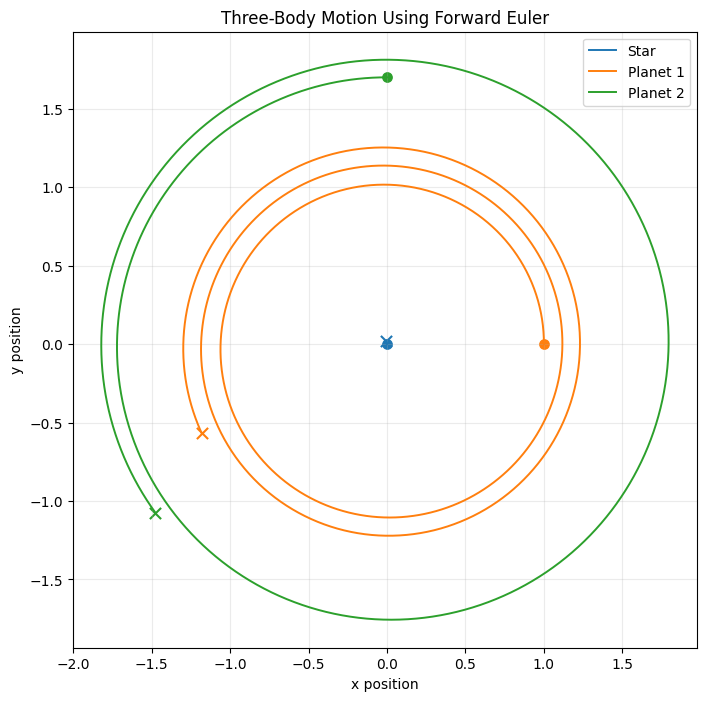

In [15]:

import matplotlib.pyplot as plt

body_labels = ["Star", "Planet 1", "Planet 2"]

fig, ax = plt.subplots(figsize=(9, 8))

for i in range(len(masses)):

    x = position_history[:, i, 0]
    y = position_history[:, i, 1]

    # Plot the trajectory.
    line, = ax.plot(
        x, y,
        linewidth=1.4,
        label=body_labels[i] if i < len(body_labels) else f"Body {i}"
    )

    # Mark the initial position.
    ax.scatter(
        x[0], y[0],
        color=line.get_color(),
        s=45,
        marker="o"
    )

    # Mark the final position.
    ax.scatter(
        x[-1], y[-1],
        color=line.get_color(),
        s=65,
        marker="x"
    )

ax.set_xlabel("x position")
ax.set_ylabel("y position")
ax.set_title("Three-Body Motion Using Forward Euler")

ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid(alpha=0.25)

plt.show()



## 2.5 Why Euler integration introduces errors

Forward Euler assumes that velocity remains approximately constant while position is updated over a timestep.

But in reality, gravitational acceleration is continuously changing velocity.

Therefore, the actual trajectory curves continuously, whereas Euler approximates the motion using a sequence of discrete updates.

A larger timestep means the algorithm takes larger approximating steps.

A smaller timestep generally improves short-time accuracy, although it requires more calculations.

Forward Euler has:

- Local truncation error of order $O(\Delta t^2)$ per step.
- Global error of order $O(\Delta t)$ over a fixed, finite simulation interval under standard smoothness assumptions.

This means that, in the appropriate convergence regime, halving the timestep should approximately halve the global error.

However, long-term gravitational simulations can behave more subtly.

The next experiment will compare different timesteps using identical physical initial conditions.


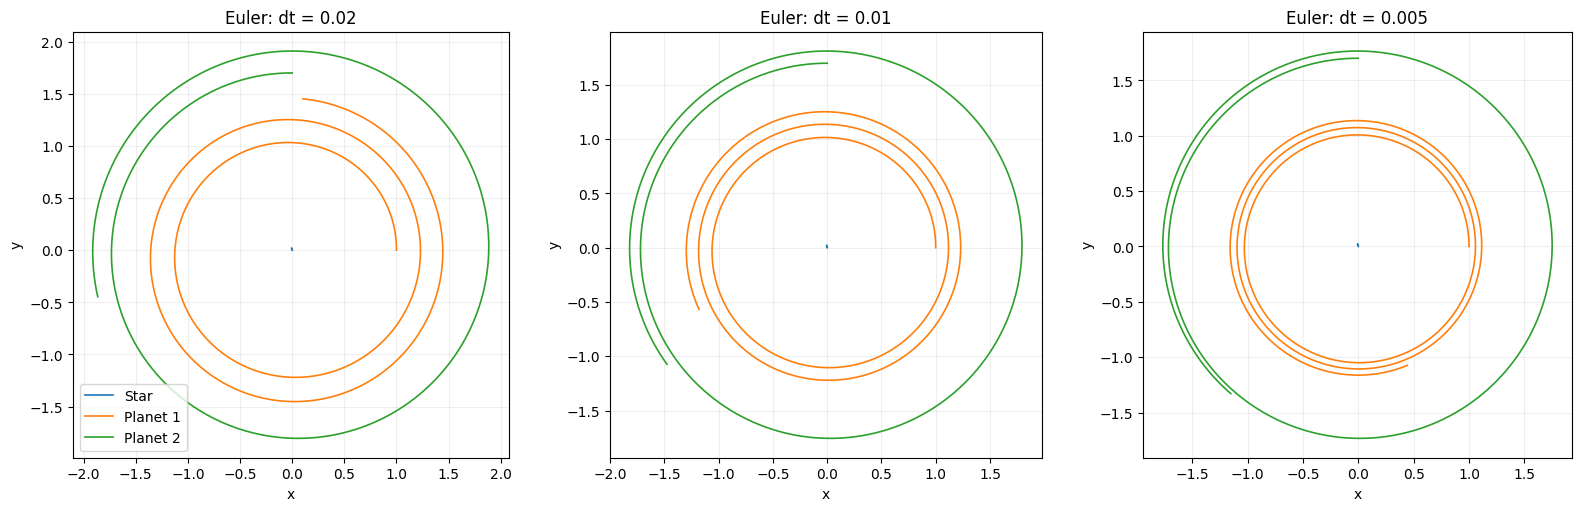

In [16]:

# Keep the physical simulation duration fixed.
total_time = 20.0

timesteps = [0.02, 0.01, 0.005]

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
    constrained_layout=True
)

for ax, step_size in zip(axes, timesteps):

    steps = int(round(total_time / step_size))

    pos_hist, vel_hist = simulate_euler(
        initial_positions,
        initial_velocities,
        masses,
        step_size,
        steps
    )

    for i in range(len(masses)):
        ax.plot(
            pos_hist[:, i, 0],
            pos_hist[:, i, 1],
            linewidth=1.2,
            label=body_labels[i] if i < len(body_labels) else f"Body {i}"
        )

    ax.set_title(f"Euler: dt = {step_size}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)

axes[0].legend()

plt.show()



## 2.6 Does the computer conserve energy?

For an isolated Newtonian gravitational system, the total mechanical energy is conserved.

Total energy is:

$$
E=K+U
$$

Here, $K$ is kinetic energy and $U$ is gravitational potential energy.

Kinetic energy measures the energy associated with motion:

$$
K=\frac12\sum_i m_i|\mathbf v_i|^2
$$

Potential energy measures gravitational interactions:

$$
U=-G\sum_{i<j}\frac{m_i m_j}{r_{ij}}
$$

The negative sign reflects the gravitational attraction when the potential energy is defined to approach zero at infinite separation.

As planets move, kinetic and potential energy exchange.

For example, a planet approaching a star gains speed. Its kinetic energy increases while its gravitational potential energy becomes more negative.

For an isolated physical system:

$$
E(t)=E(0)
$$

A numerical simulation may violate this condition because of approximation errors.

We can therefore monitor the energy throughout the simulation as one important accuracy diagnostic.


In [17]:

def calculate_total_energy(positions, velocities, masses):

    # Kinetic energy
    kinetic = 0.5 * np.sum(
        masses * np.sum(velocities**2, axis=1)
    )

    # Gravitational potential energy
    potential = 0.0

    for i in range(len(masses)):
        for j in range(i + 1, len(masses)):

            separation = np.linalg.norm(
                positions[j] - positions[i]
            )

            if separation == 0:
                raise ValueError("Two bodies occupy the same position.")

            potential -= (
                G_value * masses[i] * masses[j] / separation
            )

    return kinetic + potential


In [18]:

energy_history = np.array([
    calculate_total_energy(
        position_history[k],
        velocity_history[k],
        masses
    )
    for k in range(len(position_history))
])

initial_energy = energy_history[0]

if initial_energy != 0:
    relative_energy_error = (
        np.abs(energy_history - initial_energy)
        / abs(initial_energy)
    )
else:
    relative_energy_error = np.abs(
        energy_history - initial_energy
    )

print("Initial energy:", initial_energy)
print("Final energy:", energy_history[-1])
print("Maximum energy error:", np.max(relative_energy_error))


Initial energy: -0.0006461461571221054
Final energy: -0.0005192644829781882
Maximum energy error: 0.19636683240374003


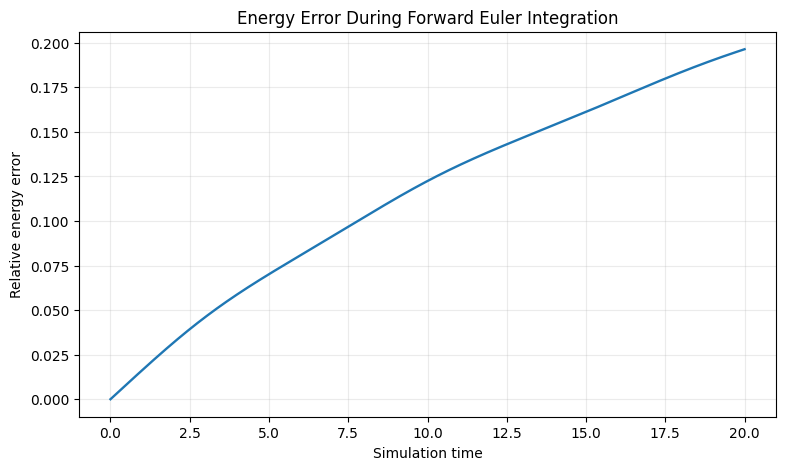

In [19]:

plt.figure(figsize=(9, 5))

plt.plot(
    times,
    relative_energy_error,
    linewidth=1.7
)

plt.xlabel("Simulation time")
plt.ylabel(
    "Relative energy error"
    if initial_energy != 0
    else "Absolute energy error"
)

plt.title("Energy Error During Forward Euler Integration")
plt.grid(alpha=0.25)

plt.show()


dt = 0.0400 | Final energy error = 0.389317
dt = 0.0200 | Final energy error = 0.289039
dt = 0.0100 | Final energy error = 0.196367
dt = 0.0050 | Final energy error = 0.120914
dt = 0.0025 | Final energy error = 0.069302


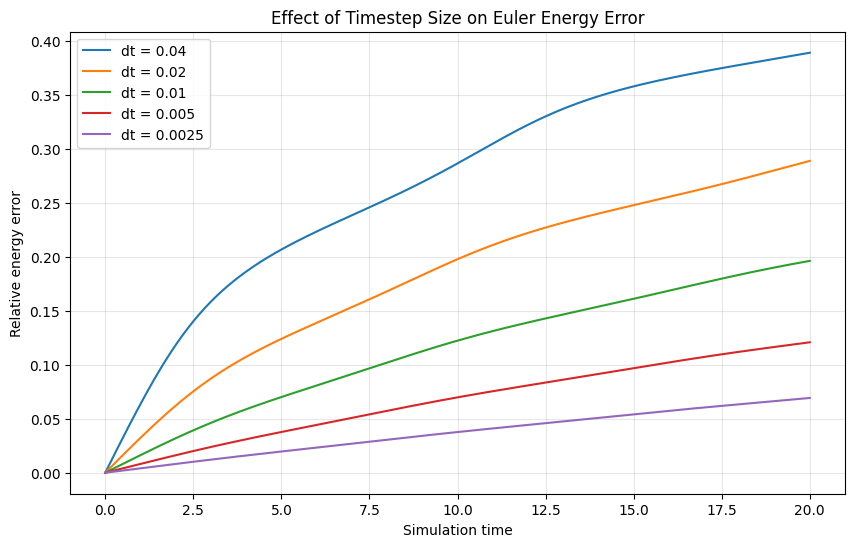

In [20]:

# Objective 02 — Timestep convergence experiment

dt_values = [0.04, 0.02, 0.01, 0.005, 0.0025]
total_time = 20.0

plt.figure(figsize=(10, 6))

for dt in dt_values:

    n_steps = int(round(total_time / dt))

    pos_hist, vel_hist = simulate_euler(
        initial_positions,
        initial_velocities,
        masses,
        dt,
        n_steps
    )

    energies = np.array([
        calculate_total_energy(
            pos_hist[k],
            vel_hist[k],
            masses
        )
        for k in range(len(pos_hist))
    ])

    E0 = energies[0]

    error = np.abs(energies - E0) / abs(E0)

    time_array = np.arange(n_steps + 1) * dt

    plt.plot(
        time_array,
        error,
        label=f"dt = {dt}"
    )

    print(
        f"dt = {dt:.4f} | "
        f"Final energy error = {error[-1]:.6f}"
    )

plt.xlabel("Simulation time")
plt.ylabel("Relative energy error")
plt.title("Effect of Timestep Size on Euler Energy Error")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



# Objective 03 — Leapfrog Integration

## 3.1 Why do we need another integration method?

In Objective 02, we implemented Forward Euler integration to simulate the motion of three gravitationally interacting bodies.

Our experiments showed that reducing the timestep reduces numerical energy error. However, even after thousands of steps, Euler still produces substantial error.

The issue isn't Newton's law of gravity. The issue is how we approximate the continuous motion on a computer.

We now introduce **Leapfrog integration**, a numerical method particularly useful for long-term Hamiltonian simulations.

Leapfrog is a second-order, time-reversible, symplectic integrator when implemented with a fixed timestep for the separable Newtonian gravitational Hamiltonian.

Its defining feature is that it updates velocity and position in a carefully ordered sequence.

We will compare Leapfrog against Euler using identical initial conditions and simulation durations.



## 3.2 How Leapfrog works

Forward Euler updates position and velocity using information from the beginning of the timestep.

Leapfrog takes a different approach.

Imagine moving a planet forward in time.

Instead of updating everything at once, we:

1. Update its velocity for half a timestep.
2. Move it forward for one complete timestep.
3. Recalculate gravity at the new position.
4. Update its velocity for the remaining half timestep.

This is called the **Kick–Drift–Kick** formulation.

### First half-kick

$$
\mathbf{v}_{n+1/2}
=
\mathbf{v}_n+
\frac{\Delta t}{2}\mathbf{a}_n
$$

### Full drift

$$
\mathbf{r}_{n+1}
=
\mathbf{r}_n+
\Delta t\,\mathbf{v}_{n+1/2}
$$

### Second half-kick

$$
\mathbf{v}_{n+1}
=
\mathbf{v}_{n+1/2}
+
\frac{\Delta t}{2}\mathbf{a}_{n+1}
$$

The gravitational acceleration at the end of the timestep is recalculated using the new positions.

This ordering is important.

It gives the method favorable long-term geometric properties that Forward Euler does not possess.


In [21]:

def leapfrog_step(positions, velocities, masses, dt):

    # Gravity at the beginning of the timestep
    a_initial = gravitational_accelerations(
        positions, masses
    )

    # Half-kick: update velocities by half a step
    v_half = velocities + 0.5 * dt * a_initial

    # Drift: update positions using half-step velocities
    new_positions = positions + dt * v_half

    # Gravity at the updated positions
    a_final = gravitational_accelerations(
        new_positions, masses
    )

    # Second half-kick
    new_velocities = v_half + 0.5 * dt * a_final

    return new_positions, new_velocities


In [22]:

def simulate_leapfrog(
    initial_positions,
    initial_velocities,
    masses,
    dt,
    n_steps
):

    positions = initial_positions.copy()
    velocities = initial_velocities.copy()

    position_history = [positions.copy()]
    velocity_history = [velocities.copy()]

    for step in range(n_steps):

        positions, velocities = leapfrog_step(
            positions,
            velocities,
            masses,
            dt
        )

        position_history.append(positions.copy())
        velocity_history.append(velocities.copy())

    return (
        np.array(position_history),
        np.array(velocity_history)
    )


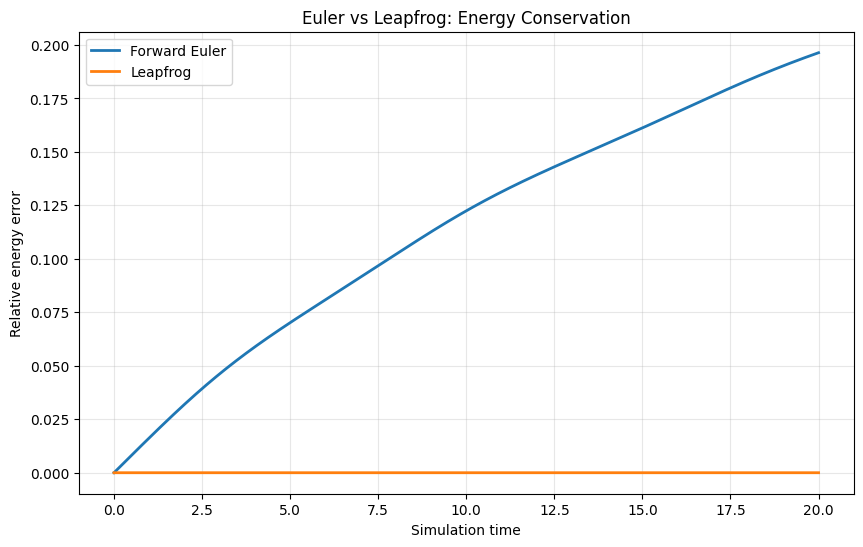

Final Euler error: 0.19636683240374003
Final Leapfrog error: 1.5080111219416746e-07


In [23]:

# Use identical initial conditions
dt = 0.01
total_time = 20.0
n_steps = int(round(total_time / dt))

# Euler
euler_pos, euler_vel = simulate_euler(
    initial_positions,
    initial_velocities,
    masses,
    dt,
    n_steps
)

# Leapfrog
leapfrog_pos, leapfrog_vel = simulate_leapfrog(
    initial_positions,
    initial_velocities,
    masses,
    dt,
    n_steps
)

def energy_error_history(pos_hist, vel_hist, masses):

    energies = np.array([
        calculate_total_energy(
            pos_hist[k],
            vel_hist[k],
            masses
        )
        for k in range(len(pos_hist))
    ])

    E0 = energies[0]

    return np.abs(energies - E0) / abs(E0)


euler_error = energy_error_history(
    euler_pos, euler_vel, masses
)

leapfrog_error = energy_error_history(
    leapfrog_pos, leapfrog_vel, masses
)

time_array = np.arange(n_steps + 1) * dt

plt.figure(figsize=(10, 6))

plt.plot(
    time_array,
    euler_error,
    label="Forward Euler",
    linewidth=2
)

plt.plot(
    time_array,
    leapfrog_error,
    label="Leapfrog",
    linewidth=2
)

plt.xlabel("Simulation time")
plt.ylabel("Relative energy error")
plt.title("Euler vs Leapfrog: Energy Conservation")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Final Euler error:", euler_error[-1])
print("Final Leapfrog error:", leapfrog_error[-1])


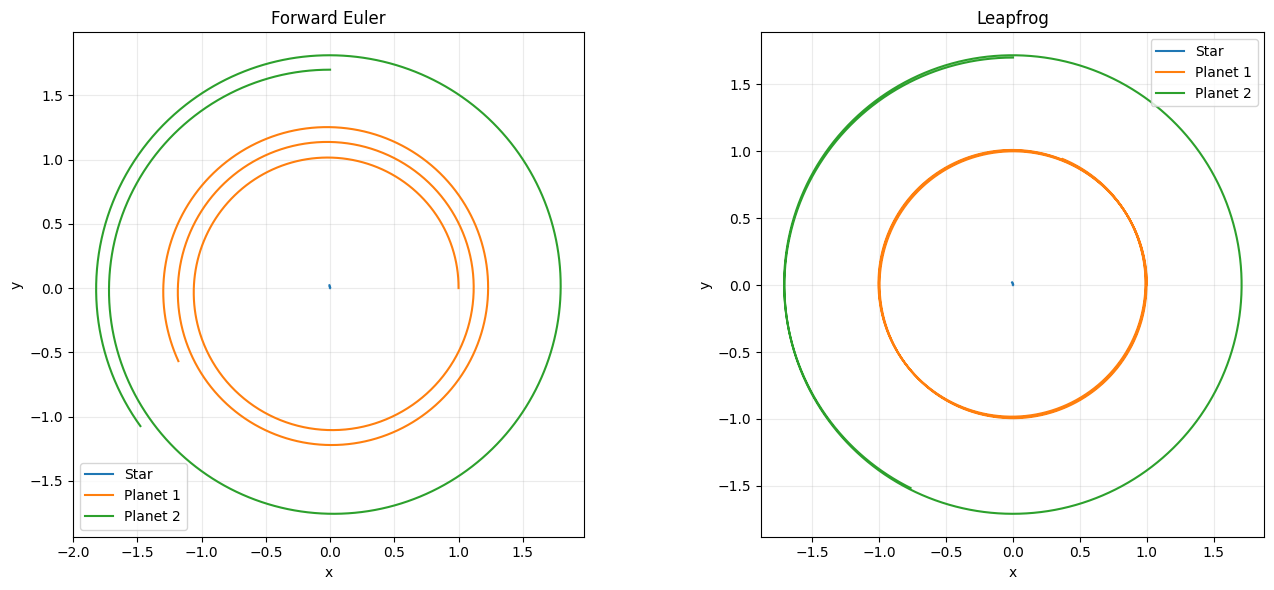

In [24]:

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for i in range(len(masses)):

    label = ["Star", "Planet 1", "Planet 2"][i]

    axes[0].plot(
        euler_pos[:, i, 0],
        euler_pos[:, i, 1],
        label=label
    )

    axes[1].plot(
        leapfrog_pos[:, i, 0],
        leapfrog_pos[:, i, 1],
        label=label
    )

axes[0].set_title("Forward Euler")
axes[1].set_title("Leapfrog")

for ax in axes:
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal", adjustable="box")
    ax.legend()
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()



## 3.3 Quantifying the difference between Euler and Leapfrog

Our trajectory plots show that Forward Euler produces substantial orbital drift, while Leapfrog maintains nearly closed trajectories.

However, visual inspection is not enough to establish numerical accuracy.

We will now compare both integrators using three quantities:

1. The final relative energy error.
2. The maximum relative energy error throughout the simulation.
3. The change in total angular momentum.

Energy and angular momentum should remain constant in an isolated Newtonian gravitational system.

These measurements will help determine whether Leapfrog preserves the physical properties of our system more accurately than Euler.

They do not, by themselves, establish whether the system is chaotic.


In [25]:

# Reuse the existing energy-error arrays from Objective 03.

print("ENERGY CONSERVATION COMPARISON")
print("-" * 48)

print(f"{'Metric':<26} {'Euler':>10} {'Leapfrog':>10}")

print(
    f"{'Final relative error':<26}"
    f"{euler_error[-1]:>10.6f}"
    f"{leapfrog_error[-1]:>10.6f}"
)

print(
    f"{'Maximum relative error':<26}"
    f"{np.max(euler_error):>10.6f}"
    f"{np.max(leapfrog_error):>10.6f}"
)

if leapfrog_error[-1] > 0:
    improvement = euler_error[-1] / leapfrog_error[-1]

    print(
        f"\nFinal error ratio (Euler/Leapfrog): "
        f"{improvement:.2f}"
    )


ENERGY CONSERVATION COMPARISON
------------------------------------------------
Metric                          Euler   Leapfrog
Final relative error        0.196367  0.000000
Maximum relative error      0.196367  0.000000

Final error ratio (Euler/Leapfrog): 1302157.72


In [26]:

def calculate_angular_momentum(positions, velocities, masses):

    x = positions[:, 0]
    y = positions[:, 1]

    vx = velocities[:, 0]
    vy = velocities[:, 1]

    return np.sum(
        masses * (x * vy - y * vx)
    )


def angular_momentum_history(pos_hist, vel_hist, masses):

    return np.array([
        calculate_angular_momentum(
            pos_hist[k],
            vel_hist[k],
            masses
        )
        for k in range(len(pos_hist))
    ])


L_euler = angular_momentum_history(
    euler_pos, euler_vel, masses
)

L_leapfrog = angular_momentum_history(
    leapfrog_pos, leapfrog_vel, masses
)

L0 = L_euler[0]

if abs(L0) > 1e-14:
    euler_L_error = np.abs(L_euler - L0) / abs(L0)
    leapfrog_L_error = np.abs(L_leapfrog - L0) / abs(L0)
    error_label = "Relative angular momentum error"
else:
    euler_L_error = np.abs(L_euler - L0)
    leapfrog_L_error = np.abs(L_leapfrog - L0)
    error_label = "Absolute angular momentum error"

print("Euler maximum angular momentum error:", euler_L_error.max())
print("Leapfrog maximum angular momentum error:", leapfrog_L_error.max())


Euler maximum angular momentum error: 0.099919999079888
Leapfrog maximum angular momentum error: 4.456074205440574e-15


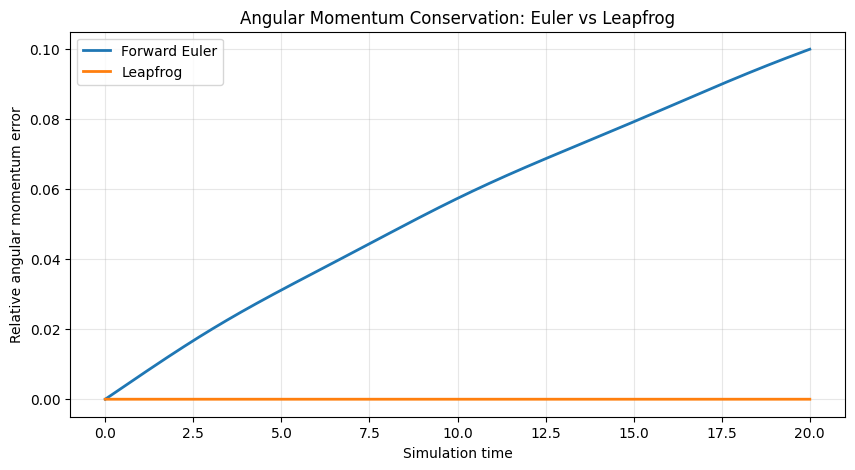

In [27]:

plt.figure(figsize=(10, 5))

plt.plot(
    time_array,
    euler_L_error,
    label="Forward Euler",
    linewidth=2
)

plt.plot(
    time_array,
    leapfrog_L_error,
    label="Leapfrog",
    linewidth=2
)

plt.xlabel("Simulation time")
plt.ylabel(error_label)
plt.title("Angular Momentum Conservation: Euler vs Leapfrog")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


Maximum Leapfrog error: 4.456074205440574e-15
Final Leapfrog error: 3.2765251510592454e-15


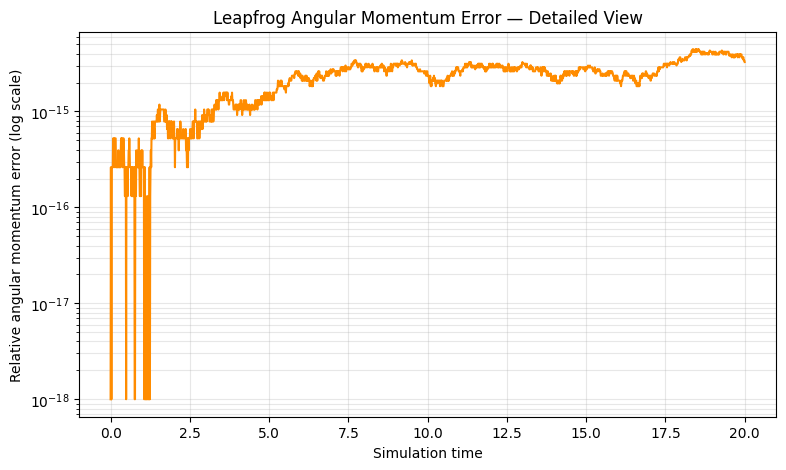

In [28]:

# Examine Leapfrog angular momentum error more closely.

print("Maximum Leapfrog error:",
      np.max(leapfrog_L_error))

print("Final Leapfrog error:",
      leapfrog_L_error[-1])

plt.figure(figsize=(9, 5))

plt.semilogy(
    time_array,
    np.maximum(leapfrog_L_error, 1e-18),
    color="darkorange",
    linewidth=1.5
)

plt.xlabel("Simulation time")
plt.ylabel("Relative angular momentum error (log scale)")
plt.title("Leapfrog Angular Momentum Error — Detailed View")

plt.grid(alpha=0.3, which="both")
plt.show()



# Objective 04 — Fourth-Order Runge–Kutta (RK4)

## 4.1 Why introduce another integrator?

We have implemented two numerical methods:

- **Forward Euler:** First-order accuracy, but substantial long-term numerical drift.
- **Leapfrog:** Second-order accuracy and symplectic structure, with excellent angular-momentum conservation in our experiment.

Now we introduce RK4, a fourth-order integration method.

RK4 estimates how a system changes by evaluating the governing differential equations at four locations within each timestep.

For a smooth physical system, its global error over a fixed time interval generally scales as:

$$
O(\Delta t^4)
$$

This is a higher order of accuracy than Leapfrog's:

$$
O(\Delta t^2)
$$

However, higher order does not automatically mean better long-term dynamical behavior.

Unlike Leapfrog, standard RK4 is not symplectic.

This comparison will help us investigate the difference between **local numerical accuracy** and **long-term preservation of physical structure**.


In [29]:

def rk4_step(positions, velocities, masses, dt):

    def derivatives(r, v):
        return v, gravitational_accelerations(r, masses)

    # First evaluation
    k1_r, k1_v = derivatives(positions, velocities)

    # Second evaluation: midpoint
    k2_r, k2_v = derivatives(
        positions + 0.5 * dt * k1_r,
        velocities + 0.5 * dt * k1_v
    )

    # Third evaluation: another midpoint
    k3_r, k3_v = derivatives(
        positions + 0.5 * dt * k2_r,
        velocities + 0.5 * dt * k2_v
    )

    # Fourth evaluation: end of timestep
    k4_r, k4_v = derivatives(
        positions + dt * k3_r,
        velocities + dt * k3_v
    )

    new_positions = positions + (dt / 6.0) * (
        k1_r + 2*k2_r + 2*k3_r + k4_r
    )

    new_velocities = velocities + (dt / 6.0) * (
        k1_v + 2*k2_v + 2*k3_v + k4_v
    )

    return new_positions, new_velocities


In [30]:

def simulate_with_integrator(
    integrator,
    initial_positions,
    initial_velocities,
    masses,
    dt,
    n_steps
):

    positions = initial_positions.copy()
    velocities = initial_velocities.copy()

    position_history = [positions.copy()]
    velocity_history = [velocities.copy()]

    for _ in range(n_steps):

        positions, velocities = integrator(
            positions,
            velocities,
            masses,
            dt
        )

        position_history.append(positions.copy())
        velocity_history.append(velocities.copy())

    return (
        np.array(position_history),
        np.array(velocity_history)
    )


In [31]:

dt = 0.01
total_time = 20.0
n_steps = int(round(total_time / dt))

integrators = {
    "Euler": euler_step,
    "Leapfrog": leapfrog_step,
    "RK4": rk4_step
}

results = {}

for name, method in integrators.items():

    pos_hist, vel_hist = simulate_with_integrator(
        method,
        initial_positions,
        initial_velocities,
        masses,
        dt,
        n_steps
    )

    results[name] = {
        "positions": pos_hist,
        "velocities": vel_hist,
        "energy_error": energy_error_history(
            pos_hist, vel_hist, masses
        )
    }

print("All three simulations completed.")


All three simulations completed.


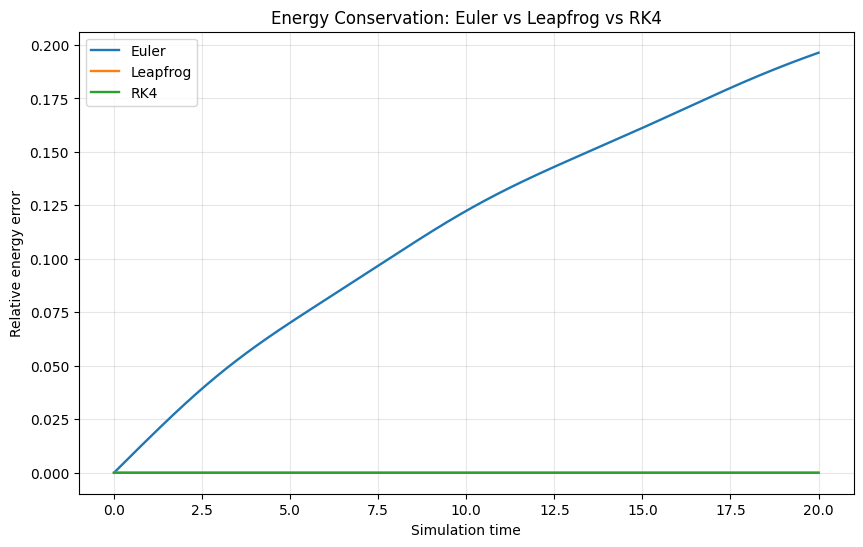

Euler      | Final energy error: 1.96366832e-01
Leapfrog   | Final energy error: 1.50801112e-07
RK4        | Final energy error: 4.26339053e-11


In [32]:

plt.figure(figsize=(10, 6))

for name, data in results.items():

    plt.plot(
        np.arange(n_steps + 1) * dt,
        data["energy_error"],
        label=name,
        linewidth=1.7
    )

plt.xlabel("Simulation time")
plt.ylabel("Relative energy error")
plt.title("Energy Conservation: Euler vs Leapfrog vs RK4")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

for name, data in results.items():

    print(
        f"{name:10s} | "
        f"Final energy error: "
        f"{data['energy_error'][-1]:.8e}"
    )


Euler      | Maximum angular momentum error: 9.99199991e-02
Leapfrog   | Maximum angular momentum error: 4.45607421e-15
RK4        | Maximum angular momentum error: 1.70959908e-11


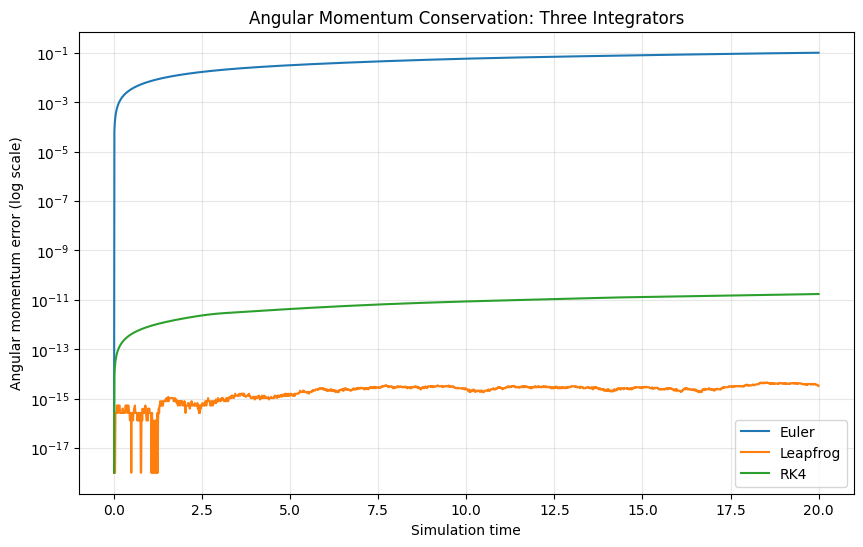

In [33]:

plt.figure(figsize=(10, 6))

for name, data in results.items():

    L_history = angular_momentum_history(
        data["positions"],
        data["velocities"],
        masses
    )

    L0 = L_history[0]

    if abs(L0) > 1e-14:
        L_error = np.abs(L_history - L0) / abs(L0)
    else:
        L_error = np.abs(L_history - L0)

    plt.semilogy(
        np.arange(n_steps + 1) * dt,
        np.maximum(L_error, 1e-18),
        label=name,
        linewidth=1.5
    )

    print(
        f"{name:10s} | "
        f"Maximum angular momentum error: "
        f"{L_error.max():.8e}"
    )

plt.xlabel("Simulation time")
plt.ylabel("Angular momentum error (log scale)")
plt.title("Angular Momentum Conservation: Three Integrators")

plt.legend()
plt.grid(alpha=0.3, which="both")
plt.show()



# Objective 05 — Numerical Convergence

## 5.1 How do we know whether a simulation is accurate?

So far, we have measured energy and angular momentum conservation.

These are useful tests, but they cannot tell us exactly how close a simulated trajectory is to the correct physical solution.

To measure trajectory accuracy, we need a system whose motion can be predicted mathematically.

A circular two-body orbit provides an ideal reference.

We can compare a numerically calculated orbit against an exact solution and measure the difference.

For a smooth system over a fixed time interval, the global numerical error often follows:

$$
\epsilon(\Delta t)\propto\Delta t^p
$$

where $p$ is the order of the numerical integrator.

For our methods:

- Euler: $p=1$
- Leapfrog: $p=2$
- RK4: $p=4$

If we halve the timestep, the expected error reduction in the asymptotic convergence regime is:

$$
\frac{\epsilon(\Delta t)}{\epsilon(\Delta t/2)}
\approx 2^p
$$

Therefore:

- Euler: approximately 2 times smaller.
- Leapfrog: approximately 4 times smaller.
- RK4: approximately 16 times smaller.

We will test whether our own implementations reproduce these theoretical predictions.


In [34]:

# Exact circular two-body setup

G_value = 1.0

m1 = 1.0
m2 = 0.001

two_body_masses = np.array([m1, m2])

M = m1 + m2
a = 1.0

omega = np.sqrt(G_value * M / a**3)
period = 2 * np.pi / omega

r1 = -m2 / M * a
r2 = m1 / M * a

two_body_positions = np.array([
    [r1, 0.0],
    [r2, 0.0]
])

two_body_velocities = np.array([
    [0.0, omega * r1],
    [0.0, omega * r2]
])

print("Orbital period:", period)
print("Initial positions:\n", two_body_positions)
print("Initial velocities:\n", two_body_velocities)


Orbital period: 6.280046068758708
Initial positions:
 [[-0.000999  0.      ]
 [ 0.999001  0.      ]]
Initial velocities:
 [[ 0.         -0.0009995 ]
 [ 0.          0.99950037]]


In [35]:

def exact_two_body_positions(t):

    theta = omega * t

    return np.array([
        [
            r1 * np.cos(theta),
            r1 * np.sin(theta)
        ],
        [
            r2 * np.cos(theta),
            r2 * np.sin(theta)
        ]
    ])


In [36]:

import matplotlib.pyplot as plt

steps_per_orbit = np.array([
    20, 40, 80, 160, 320, 640
])

integrators = {
    "Euler": euler_step,
    "Leapfrog": leapfrog_step,
    "RK4": rk4_step
}

convergence_results = {}

for name, method in integrators.items():

    errors = []
    dt_values = []

    for steps in steps_per_orbit:

        dt = period / steps

        pos_hist, vel_hist = simulate_with_integrator(
            method,
            two_body_positions,
            two_body_velocities,
            two_body_masses,
            dt,
            int(steps)
        )

        numerical_final = pos_hist[-1]

        exact_final = exact_two_body_positions(period)

        # RMS position error across the two bodies
        error = np.sqrt(
            np.mean(
                np.sum(
                    (numerical_final - exact_final)**2,
                    axis=1
                )
            )
        )

        errors.append(error)
        dt_values.append(dt)

    convergence_results[name] = {
        "dt": np.array(dt_values),
        "error": np.array(errors)
    }


Euler      | Estimated convergence order: 0.617
Leapfrog   | Estimated convergence order: 1.992
RK4        | Estimated convergence order: 4.272


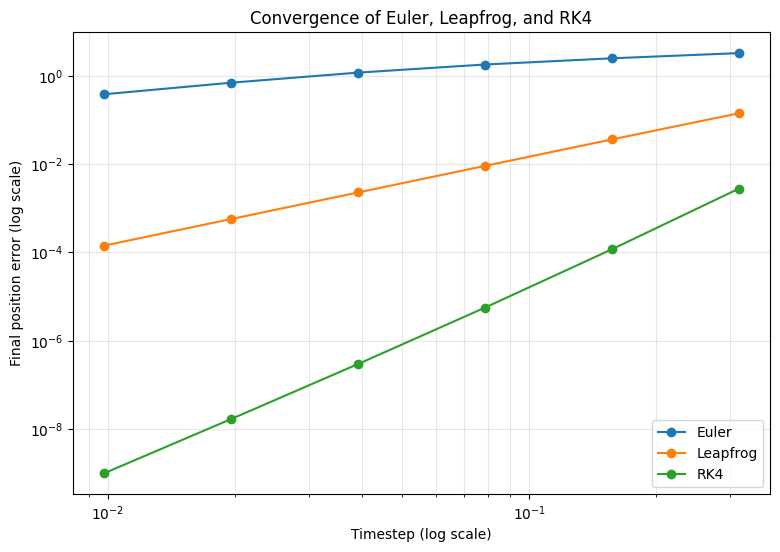

In [37]:

plt.figure(figsize=(9, 6))

for name, data in convergence_results.items():

    plt.loglog(
        data["dt"],
        data["error"],
        "o-",
        label=name
    )

    # Fit slope: log(error) = p * log(dt) + constant
    slope, intercept = np.polyfit(
        np.log(data["dt"]),
        np.log(data["error"]),
        1
    )

    print(
        f"{name:10s} | "
        f"Estimated convergence order: {slope:.3f}"
    )

plt.xlabel("Timestep (log scale)")
plt.ylabel("Final position error (log scale)")
plt.title("Convergence of Euler, Leapfrog, and RK4")

plt.legend()
plt.grid(alpha=0.3, which="both")
plt.show()


In [38]:

# Calculate the measured convergence order
# for each numerical integrator.

expected_orders = {
    "Euler": 1,
    "Leapfrog": 2,
    "RK4": 4
}

print("NUMERICAL CONVERGENCE VALIDATION")
print("-" * 55)

for name, data in convergence_results.items():

    dt_values = data["dt"]
    errors = data["error"]

    # Linear fit on logarithmic data
    measured_order = np.polyfit(
        np.log(dt_values),
        np.log(errors),
        1
    )[0]

    expected_order = expected_orders[name]

    print(
        f"{name:10s} | "
        f"Measured: {measured_order:.4f} | "
        f"Expected: {expected_order}"
    )


NUMERICAL CONVERGENCE VALIDATION
-------------------------------------------------------
Euler      | Measured: 0.6165 | Expected: 1
Leapfrog   | Measured: 1.9921 | Expected: 2
RK4        | Measured: 4.2724 | Expected: 4



# Objective 06 — Sensitivity to Initial Conditions

## 6.1 Can a tiny difference change the future of a planetary system?

Imagine two universes.

Both contain exactly the same star and two planets.

In Universe A, the planets begin at their original positions.

In Universe B, we move one planet by an almost unimaginably small distance.

Everything else remains the same.

At first, the two planetary systems should behave almost identically.

But gravitational systems are nonlinear. This means that small changes in the positions of objects change their gravitational interactions, which can influence their subsequent motion.

Some gravitational systems exhibit **chaos**, where extremely small differences in initial conditions can grow exponentially.

However, not every growing difference means chaos.

Even perfectly regular orbits can gradually separate because their orbital periods differ slightly.

Our aim is to investigate this sensitivity computationally and eventually determine when the observed separation is physical and when it is caused by numerical error.

### Research question

How does a tiny perturbation to one planet's initial position affect the subsequent motion of a gravitational three-body system?

### Our strategy

We will:

1. Construct a star with two approximately circular planetary orbits.
2. Create an almost identical copy of the system.
3. Introduce a tiny position perturbation.
4. Evolve both systems using the same integrator.
5. Measure the difference between their trajectories.
6. Examine how that difference changes over time.

This is an initial sensitivity experiment, not yet a definitive test of chaos.


In [39]:

import numpy as np
import matplotlib.pyplot as plt

# Use the same gravitational constant as earlier objectives.
G_value = 1.0

# Masses: star, inner planet, outer planet
chaos_masses = np.array([
    1.0,
    0.001,
    0.0005
], dtype=float)

# Approximate initial orbital radii
a_inner = 1.0
a_outer = 1.7

# Initial positions
chaos_positions = np.array([
    [0.0, 0.0],
    [a_inner, 0.0],
    [0.0, a_outer]
], dtype=float)

# Approximate circular speeds about the central star
v_inner = np.sqrt(
    G_value * (chaos_masses[0] + chaos_masses[1]) / a_inner
)

v_outer = np.sqrt(
    G_value * (chaos_masses[0] + chaos_masses[2]) / a_outer
)

# Counterclockwise tangential velocities
chaos_velocities = np.array([
    [0.0, 0.0],
    [0.0, v_inner],
    [-v_outer, 0.0]
], dtype=float)

# Shift the entire system to its center-of-mass frame.
total_mass = chaos_masses.sum()

center_of_mass = np.sum(
    chaos_masses[:, None] * chaos_positions,
    axis=0
) / total_mass

center_of_mass_velocity = np.sum(
    chaos_masses[:, None] * chaos_velocities,
    axis=0
) / total_mass

chaos_positions -= center_of_mass
chaos_velocities -= center_of_mass_velocity

print("Initial positions:\n", chaos_positions)
print("\nInitial velocities:\n", chaos_velocities)
print("\nMasses:", chaos_masses)
print("\nCenter of mass:",
      np.average(chaos_positions, axis=0, weights=chaos_masses))


Initial positions:
 [[-9.98502247e-04 -8.48726910e-04]
 [ 9.99001498e-01 -8.48726910e-04]
 [-9.98502247e-04  1.69915127e+00]]

Initial velocities:
 [[ 3.83003847e-04 -9.99001373e-04]
 [ 3.83003847e-04  9.99500874e-01]
 [-7.66773702e-01 -9.99001373e-04]]

Masses: [1.e+00 1.e-03 5.e-04]

Center of mass: [-2.33959550e-19 -1.08257831e-19]



## 6.2 Introducing an extremely small perturbation

Our next step is to create two almost identical planetary systems.

Let the original state of the system be:

$$
\mathbf{X}_A(0)
$$

The perturbed system is:

$$
\mathbf{X}_B(0)
=
\mathbf{X}_A(0)+\delta\mathbf{X}_0
$$

The quantity $\delta\mathbf{X}_0$ represents a tiny difference in the initial conditions.

For our experiment, we will change only the outer planet's x-coordinate.

We choose:

$$
\delta x=10^{-8}
$$

This means the outer planet's initial x-coordinate differs by just:

$$
0.00000001
$$

in our normalized distance units.

This change is extremely small compared with the orbital radii.

We then evolve both systems using identical gravitational equations and identical numerical settings.

If their trajectories eventually become different, we will investigate how quickly and why.

Importantly, even regular orbital systems may show growing separation. We will not classify chaos based on trajectory divergence alone.


In [40]:

# Universe A: Original system
positions_A = chaos_positions.copy()
velocities_A = chaos_velocities.copy()

# Universe B: Almost identical system
positions_B = chaos_positions.copy()
velocities_B = chaos_velocities.copy()

# Perturb the x-coordinate of the outer planet.
perturbation = 1e-8

positions_B[2, 0] += perturbation

print("Universe A outer planet:", positions_A[2])
print("Universe B outer planet:", positions_B[2])

print(
    "Initial outer-planet position difference:",
    np.linalg.norm(positions_B[2] - positions_A[2])
)


Universe A outer planet: [-9.98502247e-04  1.69915127e+00]
Universe B outer planet: [-9.98492247e-04  1.69915127e+00]
Initial outer-planet position difference: 9.999999999940612e-09


In [41]:

# Simulation settings
chaos_dt = 0.01
chaos_total_time = 300.0

chaos_n_steps = int(
    round(chaos_total_time / chaos_dt)
)

# Run Universe A
pos_A, vel_A = simulate_with_integrator(
    rk4_step,
    positions_A,
    velocities_A,
    chaos_masses,
    chaos_dt,
    chaos_n_steps
)

# Run Universe B
pos_B, vel_B = simulate_with_integrator(
    rk4_step,
    positions_B,
    velocities_B,
    chaos_masses,
    chaos_dt,
    chaos_n_steps
)

chaos_times = (
    np.arange(chaos_n_steps + 1) * chaos_dt
)

print("Simulation completed.")
print("Number of timesteps:", chaos_n_steps)
print("Final simulation time:", chaos_times[-1])
print("History shape:", pos_A.shape)


Simulation completed.
Number of timesteps: 30000
Final simulation time: 300.0
History shape: (30001, 3, 2)



## 6.3 Measuring how two universes separate

We have two simulations, A and B.

At every timestep, each contains the positions and velocities of three bodies.

We want one number that describes how different the two systems have become.

A simple approach is to compare the positions of the planets relative to the star.

This removes differences caused only by the overall translation of the entire system.

For planet $i$:

$$
\mathbf{q}_i=\mathbf{r}_i-\mathbf{r}_{star}
$$

We can compare the relative positions in Universes A and B:

$$
\Delta\mathbf{q}_i(t)
=
\mathbf{q}_{i,B}(t)-\mathbf{q}_{i,A}(t)
$$

The combined positional separation is:

$$
D_r(t)=
\sqrt{
\sum_{i=1}^{2}
\left|\Delta\mathbf{q}_i(t)\right|^2
}
$$

If this quantity increases, the two simulated planetary configurations are becoming different.

However, we must distinguish **position separation** from separation in the full dynamical state.

Later, when calculating Lyapunov exponents, we will also include velocities and use properly normalized phase-space distances.

For now, the positional separation gives us an intuitive starting point.


In [44]:
# Positions of both planets relative to their star
relative_A = pos_A[:, 1:, :] - pos_A[:, 0:1, :]
relative_B = pos_B[:, 1:, :] - pos_B[:, 0:1, :]

# Difference between the two systems
position_difference = relative_B - relative_A

# Combined positional separation
separation = np.sqrt(
    np.sum(position_difference**2, axis=(1, 2))
)

print("Initial separation:", separation[0])
print("Final separation:", separation[-1])
print("Maximum separation:", separation.max())

Initial separation: 9.999999999940612e-09
Final separation: 1.9680910491155876e-08
Maximum separation: 3.050417583361641e-08


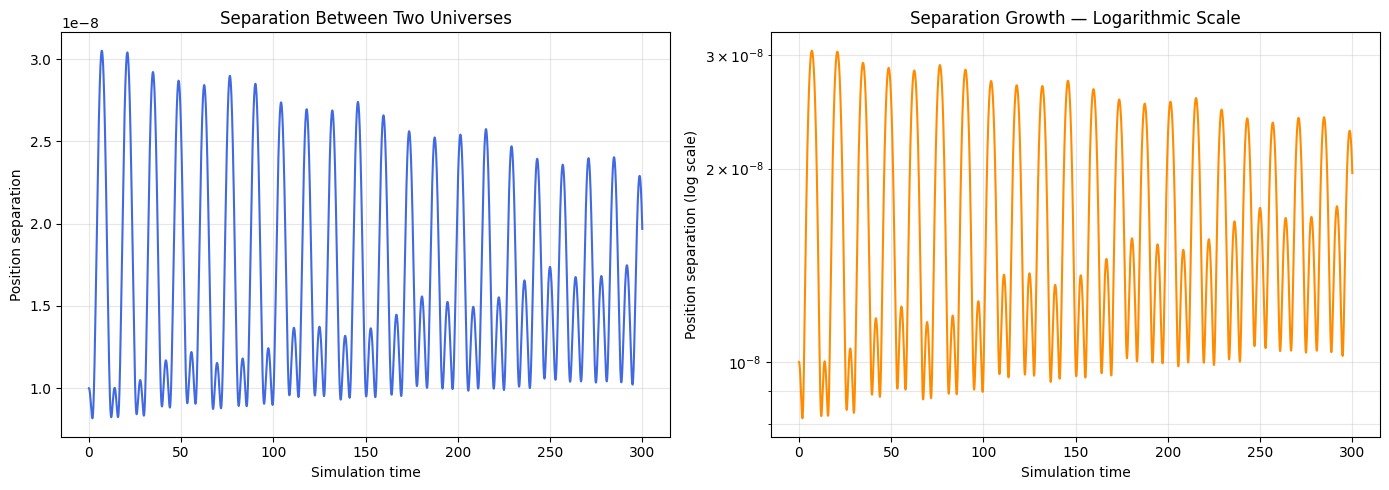

In [45]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Linear scale
axes[0].plot(
    chaos_times,
    separation,
    color="royalblue",
    linewidth=1.5
)

axes[0].set_title("Separation Between Two Universes")
axes[0].set_xlabel("Simulation time")
axes[0].set_ylabel("Position separation")
axes[0].grid(alpha=0.3)

# Plot 2: Logarithmic scale
axes[1].semilogy(
    chaos_times,
    np.maximum(separation, 1e-16),
    color="darkorange",
    linewidth=1.5
)

axes[1].set_title("Separation Growth — Logarithmic Scale")
axes[1].set_xlabel("Simulation time")
axes[1].set_ylabel("Position separation (log scale)")
axes[1].grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()


## 6.4 Testing numerical convergence of trajectory separation

We have observed that two nearly identical three-body systems exhibit small, oscillating positional separation.

However, we cannot yet determine whether these oscillations are reliably reproduced by our numerical algorithm.

To investigate this, we will repeat the same experiment using different timesteps.

We will keep everything else fixed:

- The gravitational equations
- The masses
- The initial positions and velocities
- The initial perturbation
- The integration method (RK4)
- The total simulation time

Only the timestep will change.

If the calculated separation approaches a consistent result as the timestep becomes smaller, we gain confidence that the observed behavior is not primarily caused by discretization error.

We will compare both the separation magnitudes and the actual differences between the planetary position vectors.


In [46]:

# Numerical convergence of three-body sensitivity

dt_values = [0.02, 0.01, 0.005]

total_time = 300.0
output_interval = 0.1

separation_results = {}
difference_results = {}

for dt_test in dt_values:

    n_steps = int(round(total_time / dt_test))

    # Integrate original Universe A
    pA, vA = simulate_with_integrator(
        rk4_step,
        positions_A,
        velocities_A,
        chaos_masses,
        dt_test,
        n_steps
    )

    # Integrate perturbed Universe B
    pB, vB = simulate_with_integrator(
        rk4_step,
        positions_B,
        velocities_B,
        chaos_masses,
        dt_test,
        n_steps
    )

    # Compare planet positions relative to their own star
    rel_A = pA[:, 1:, :] - pA[:, :1, :]
    rel_B = pB[:, 1:, :] - pB[:, :1, :]

    difference = rel_B - rel_A

    # Store outputs at common times
    stride = int(round(output_interval / dt_test))

    sampled_difference = difference[::stride]

    sampled_time = (
        np.arange(len(sampled_difference))
        * output_interval
    )

    sampled_separation = np.linalg.norm(
        sampled_difference.reshape(
            len(sampled_difference), -1
        ),
        axis=1
    )

    separation_results[dt_test] = {
        "time": sampled_time,
        "separation": sampled_separation
    }

    difference_results[dt_test] = sampled_difference

    print(
        f"dt = {dt_test:.3f} | "
        f"Final separation = {sampled_separation[-1]:.10e}"
    )


dt = 0.020 | Final separation = 1.9671811591e-08
dt = 0.010 | Final separation = 1.9680910491e-08
dt = 0.005 | Final separation = 1.9689156903e-08


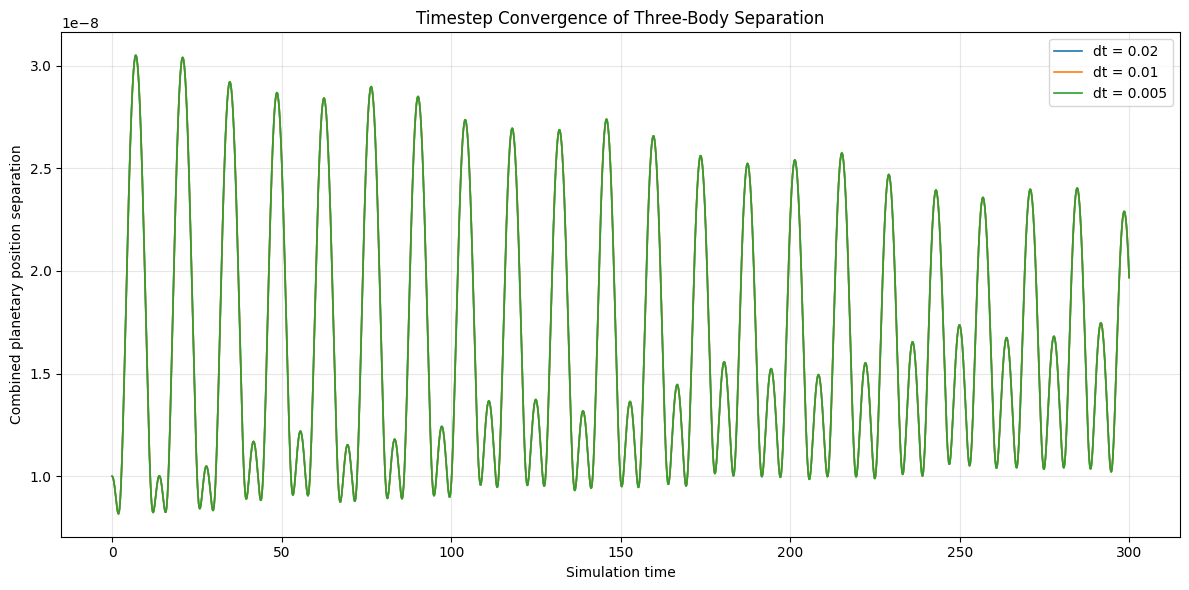

In [47]:

plt.figure(figsize=(12, 6))

for dt_test, data in separation_results.items():

    plt.plot(
        data["time"],
        data["separation"],
        label=f"dt = {dt_test}",
        linewidth=1.2
    )

plt.xlabel("Simulation time")
plt.ylabel("Combined planetary position separation")
plt.title("Timestep Convergence of Three-Body Separation")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [48]:

reference = difference_results[0.005]

print("COMPARISON WITH FINEST TIMESTEP")
print("-" * 52)

for dt_test in [0.02, 0.01]:

    current = difference_results[dt_test]

    discrepancy = np.linalg.norm(
        (current - reference).reshape(
            len(current), -1
        ),
        axis=1
    )

    scale = np.max(
        np.linalg.norm(
            reference.reshape(len(reference), -1),
            axis=1
        )
    )

    print(f"\ndt = {dt_test}")
    print("Maximum discrepancy:", discrepancy.max())
    print(
        "Discrepancy / peak reference separation:",
        discrepancy.max() / scale
    )


COMPARISON WITH FINEST TIMESTEP
----------------------------------------------------

dt = 0.02
Maximum discrepancy: 1.8356028975932405e-11
Discrepancy / peak reference separation: 0.000601772992879304

dt = 0.01
Maximum discrepancy: 8.782894871154821e-12
Discrepancy / peak reference separation: 0.0002879331330152608



## 6.5 How small is too small?

We have compared two almost identical planetary systems using an initial perturbation of $10^{-8}$.

The calculated differences are small, but subtracting nearly identical floating-point numbers can become numerically delicate.

We will repeat the sensitivity experiment using several perturbation magnitudes:

$$
\delta_0\in\{10^{-5},10^{-6},10^{-7},10^{-8}\}
$$

For each perturbation, we will compare the results from two timestep sizes.

Our aim is to determine whether the discrepancy between the numerical solutions becomes unusually large relative to the physical separation as the initial perturbation decreases.

This provides a practical diagnostic of the precision limits of our current approach.


In [49]:

perturbations = [1e-5, 1e-6, 1e-7, 1e-8]
comparison_dts = [0.01, 0.005]

total_time = 300.0

precision_results = []

for delta in perturbations:

    differences = {}

    for dt_test in comparison_dts:

        n_steps = int(round(total_time / dt_test))

        pB_initial = positions_A.copy()
        pB_initial[2, 0] += delta

        # Evolve the original system
        pA, vA = simulate_with_integrator(
            rk4_step,
            positions_A,
            velocities_A,
            chaos_masses,
            dt_test,
            n_steps
        )

        # Evolve the perturbed system
        pB, vB = simulate_with_integrator(
            rk4_step,
            pB_initial,
            velocities_A,
            chaos_masses,
            dt_test,
            n_steps
        )

        # Final positions relative to each system's star
        rel_A = pA[-1, 1:, :] - pA[-1, :1, :]
        rel_B = pB[-1, 1:, :] - pB[-1, :1, :]

        differences[dt_test] = rel_B - rel_A

    # Difference between coarse and fine results
    numerical_difference = np.linalg.norm(
        differences[0.01] - differences[0.005]
    )

    # Physical separation in the finer simulation
    physical_separation = np.linalg.norm(
        differences[0.005]
    )

    ratio = numerical_difference / physical_separation

    precision_results.append(
        (delta, numerical_difference, physical_separation, ratio)
    )

    print(
        f"delta={delta:.0e} | "
        f"numerical discrepancy={numerical_difference:.3e} | "
        f"relative discrepancy={ratio:.3e}"
    )


delta=1e-05 | numerical discrepancy=7.913e-12 | relative discrepancy=4.023e-07
delta=1e-06 | numerical discrepancy=6.094e-12 | relative discrepancy=3.097e-06
delta=1e-07 | numerical discrepancy=9.893e-12 | relative discrepancy=5.027e-05
delta=1e-08 | numerical discrepancy=8.783e-12 | relative discrepancy=4.461e-04


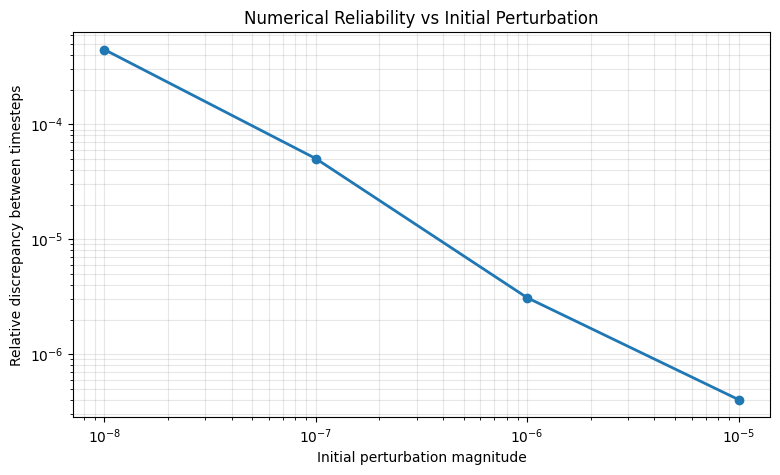

In [50]:

deltas = np.array([r[0] for r in precision_results])
ratios = np.array([r[3] for r in precision_results])

plt.figure(figsize=(9, 5))

plt.loglog(
    deltas,
    ratios,
    "o-",
    linewidth=2
)

plt.xlabel("Initial perturbation magnitude")
plt.ylabel("Relative discrepancy between timesteps")
plt.title("Numerical Reliability vs Initial Perturbation")

plt.grid(alpha=0.3, which="both")
plt.show()



# Objective 07 — Variational Equations

## 7.1 Measuring an infinitesimal perturbation directly

Previously, we simulated two nearly identical systems and subtracted their trajectories.

Our results showed that the relative numerical discrepancy increased when the initial perturbation became extremely small.

There is another approach.

Instead of computing two complete trajectories, we can evolve:

1. The original gravitational system.
2. An infinitesimal perturbation to that system.

The perturbation follows the **variational equations**, which describe the linearized response of the equations of motion.

For our Newtonian system:

$$
\frac{d\delta\mathbf r_i}{dt}=\delta\mathbf v_i
$$

$$
\delta\mathbf a_i =
G\sum_{j\ne i}m_j
\left[
\frac{\delta\mathbf r_j-\delta\mathbf r_i}{r_{ij}^3}
-
3\frac{\mathbf r_{ij}\cdot(\delta\mathbf r_j-\delta\mathbf r_i)}{r_{ij}^5}
\mathbf r_{ij}
\right]
$$

This gives us the evolution of an infinitesimal change without subtracting two independently simulated trajectories.

We still need accurate numerical integration. Variational equations reduce one source of numerical difficulty, but do not eliminate truncation or roundoff errors.


In [51]:

def variational_accelerations(
    positions,
    delta_positions,
    masses
):
    """
    Calculate how gravitational accelerations respond
    to infinitesimal position perturbations.
    """

    N = len(masses)

    delta_a = np.zeros_like(positions)

    for i in range(N):
        for j in range(N):

            if i == j:
                continue

            # Relative position between bodies
            r = positions[j] - positions[i]

            # Relative infinitesimal displacement
            dr = delta_positions[j] - delta_positions[i]

            distance = np.linalg.norm(r)

            if distance == 0:
                raise ValueError("Overlapping bodies")

            # Linearized gravitational acceleration
            term1 = dr / distance**3

            term2 = (
                3 * np.dot(r, dr) * r
                / distance**5
            )

            delta_a[i] += (
                G_value * masses[j] * (term1 - term2)
            )

    return delta_a


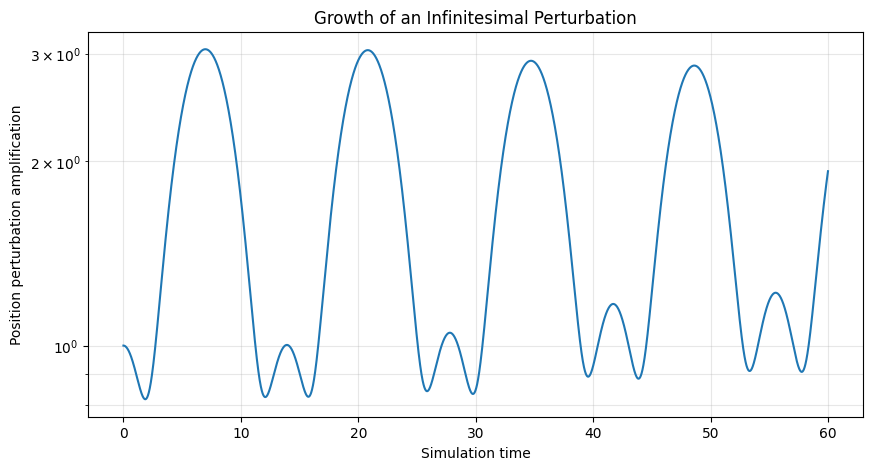

In [52]:

def variational_rk4_step(r, v, dr, dv, masses, dt):

    def rhs(r, v, dr, dv):
        return (
            v,
            gravitational_accelerations(r, masses),
            dv,
            variational_accelerations(r, dr, masses)
        )

    state = (r, v, dr, dv)

    k1 = rhs(*state)

    s2 = tuple(
        s + 0.5 * dt * k
        for s, k in zip(state, k1)
    )
    k2 = rhs(*s2)

    s3 = tuple(
        s + 0.5 * dt * k
        for s, k in zip(state, k2)
    )
    k3 = rhs(*s3)

    s4 = tuple(
        s + dt * k
        for s, k in zip(state, k3)
    )
    k4 = rhs(*s4)

    return tuple(
        s + (dt / 6.0) * (
            a + 2*b + 2*c + d
        )
        for s, a, b, c, d in zip(
            state, k1, k2, k3, k4
        )
    )


# Initial conditions from Objective 06
r = positions_A.copy()
v = velocities_A.copy()

# Unit perturbation in the outer planet's x position
dr = np.zeros_like(r)
dv = np.zeros_like(v)

dr[2, 0] = 1.0

dt_var = 0.01
total_time_var = 60.0
n_steps_var = int(round(total_time_var / dt_var))

tangent_history = []

for step in range(n_steps_var + 1):

    # Relative perturbations of both planets
    # measured with respect to the star
    relative_dr = dr[1:] - dr[0]

    tangent_history.append(
        np.linalg.norm(relative_dr)
    )

    if step < n_steps_var:
        r, v, dr, dv = variational_rk4_step(
            r, v, dr, dv,
            chaos_masses, dt_var
        )

tangent_history = np.array(tangent_history)
tangent_times = np.arange(n_steps_var + 1) * dt_var

plt.figure(figsize=(10, 5))

plt.semilogy(
    tangent_times,
    tangent_history,
    linewidth=1.5
)

plt.xlabel("Simulation time")
plt.ylabel("Position perturbation amplification")
plt.title("Growth of an Infinitesimal Perturbation")
plt.grid(alpha=0.3, which="both")
plt.show()



## 7.2 From positional perturbations to phase-space perturbations

A gravitational system is described by positions and velocities.

Therefore, an infinitesimal perturbation contains two components:

- $\delta\mathbf r$: changes in position
- $\delta\mathbf v$: changes in velocity

To measure their combined size, we need a consistent scale because positions and velocities have different physical units.

We introduce a characteristic time $T_*$ and define:

$$
D(t)=\sqrt{\sum_i\left(
|\delta\mathbf r_i|^2+
T_*^2|\delta\mathbf v_i|^2
\right)}
$$

Here we choose $T_*=1$ in normalized simulation units.

A positive Lyapunov exponent corresponds to exponential growth of infinitesimal phase-space perturbations in the long-time limit.

But during a finite simulation, perturbations can temporarily grow even in regular systems.

Therefore, we will estimate a **finite-time Lyapunov exponent**, not immediately declare a system chaotic.


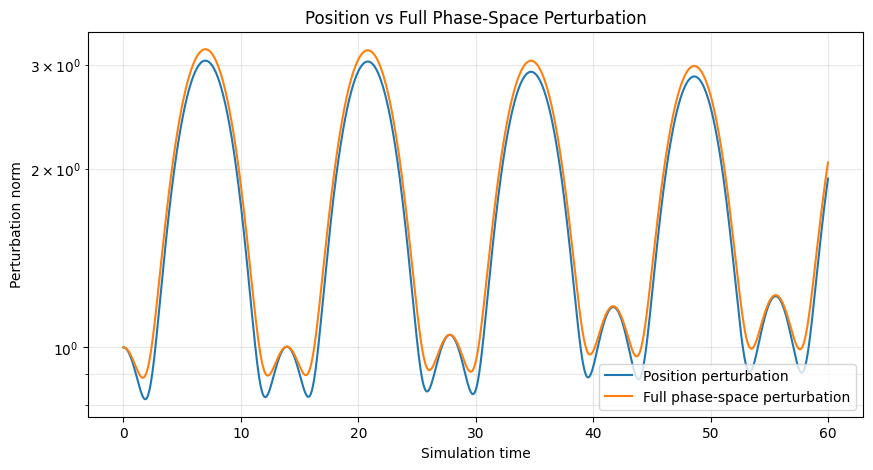

In [53]:

# Characteristic time for scaling velocity perturbations
T_scale = 1.0

def phase_space_norm(dr, dv):
    return np.sqrt(
        np.sum(dr**2) +
        T_scale**2 * np.sum(dv**2)
    )


r = positions_A.copy()
v = velocities_A.copy()

dr = np.zeros_like(r)
dv = np.zeros_like(v)

dr[2, 0] = 1.0

dt_var = 0.01
total_time = 60.0
n_steps = int(round(total_time / dt_var))

phase_norm_history = []
position_norm_history = []

for step in range(n_steps + 1):

    phase_norm_history.append(
        phase_space_norm(dr, dv)
    )

    position_norm_history.append(
        np.linalg.norm(dr)
    )

    if step < n_steps:
        r, v, dr, dv = variational_rk4_step(
            r, v, dr, dv,
            chaos_masses, dt_var
        )

phase_norm_history = np.array(phase_norm_history)
position_norm_history = np.array(position_norm_history)

t = np.arange(n_steps + 1) * dt_var

plt.figure(figsize=(10, 5))

plt.semilogy(
    t,
    position_norm_history,
    label="Position perturbation"
)

plt.semilogy(
    t,
    phase_norm_history,
    label="Full phase-space perturbation"
)

plt.xlabel("Simulation time")
plt.ylabel("Perturbation norm")
plt.title("Position vs Full Phase-Space Perturbation")
plt.legend()
plt.grid(alpha=0.3, which="both")
plt.show()


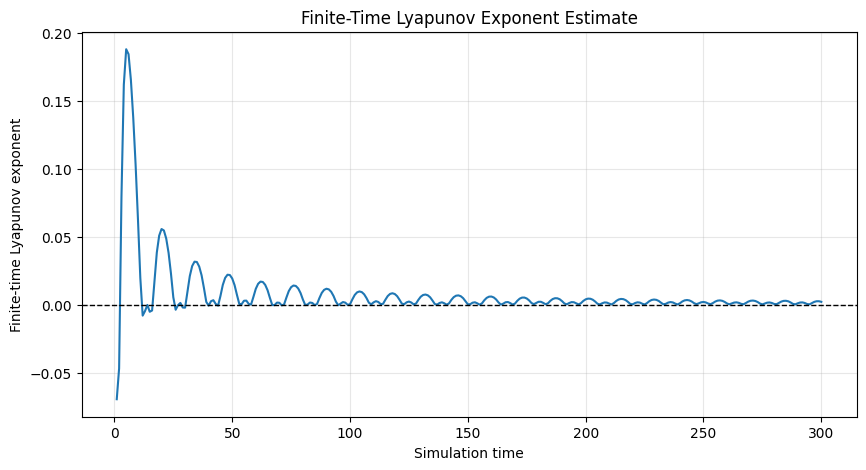

Final FTLE estimate: 0.0024266882746550324


In [54]:

def estimate_ftle(
    initial_r,
    initial_v,
    masses,
    dt=0.01,
    total_time=300.0,
    renorm_interval=1.0
):
    r = initial_r.copy()
    v = initial_v.copy()

    dr = np.zeros_like(r)
    dv = np.zeros_like(v)

    # Initial perturbation direction
    dr[2, 0] = 1.0

    norm0 = phase_space_norm(dr, dv)
    dr /= norm0
    dv /= norm0

    steps_per_block = int(round(renorm_interval / dt))
    total_steps = int(round(total_time / dt))

    if steps_per_block < 1 or total_steps < 1:
        raise ValueError("Time settings produce no integration steps.")

    accumulated_log_growth = 0.0
    elapsed = 0.0

    times = []
    ftle_values = []

    steps_completed = 0

    while steps_completed < total_steps:

        block_steps = min(
            steps_per_block,
            total_steps - steps_completed
        )

        for _ in range(block_steps):
            r, v, dr, dv = variational_rk4_step(
                r, v, dr, dv, masses, dt
            )

        growth = phase_space_norm(dr, dv)

        if not np.isfinite(growth) or growth <= 0:
            raise FloatingPointError(
                "Invalid tangent-vector growth."
            )

        accumulated_log_growth += np.log(growth)

        # Renormalize for the next block
        dr /= growth
        dv /= growth

        steps_completed += block_steps
        elapsed = steps_completed * dt

        times.append(elapsed)
        ftle_values.append(
            accumulated_log_growth / elapsed
        )

    return np.array(times), np.array(ftle_values)


ftle_times, ftle = estimate_ftle(
    positions_A,
    velocities_A,
    chaos_masses,
    dt=0.01,
    total_time=300.0,
    renorm_interval=1.0
)

plt.figure(figsize=(10, 5))
plt.plot(ftle_times, ftle)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.xlabel("Simulation time")
plt.ylabel("Finite-time Lyapunov exponent")
plt.title("Finite-Time Lyapunov Exponent Estimate")
plt.grid(alpha=0.3)
plt.show()

print("Final FTLE estimate:", ftle[-1])



## 7.3 Numerical validation of our Lyapunov estimate

Our first finite-time Lyapunov estimate decreases toward zero.

This suggests that the planetary system may exhibit regular dynamics over the tested time interval.

However, a finite-time estimate is not an exact asymptotic Lyapunov exponent.

Before drawing conclusions, we must check numerical convergence.

We will repeat the calculation with smaller timesteps and longer integration durations.

A trustworthy result should become increasingly consistent as the timestep decreases.

We will also examine whether the FTLE continues declining as the observation time increases.

If the result remains positive and approaches a nonzero plateau over progressively longer, converged integrations, that would strengthen the evidence for chaos.

If it continues toward zero, that would support regular dynamics over the investigated timescales.


dt=0.02, T=300         | Final FTLE = 2.42668803e-03
dt=0.01, T=300         | Final FTLE = 2.42668827e-03
dt=0.005, T=300        | Final FTLE = 2.42668828e-03
dt=0.01, T=600         | Final FTLE = 1.01878069e-03


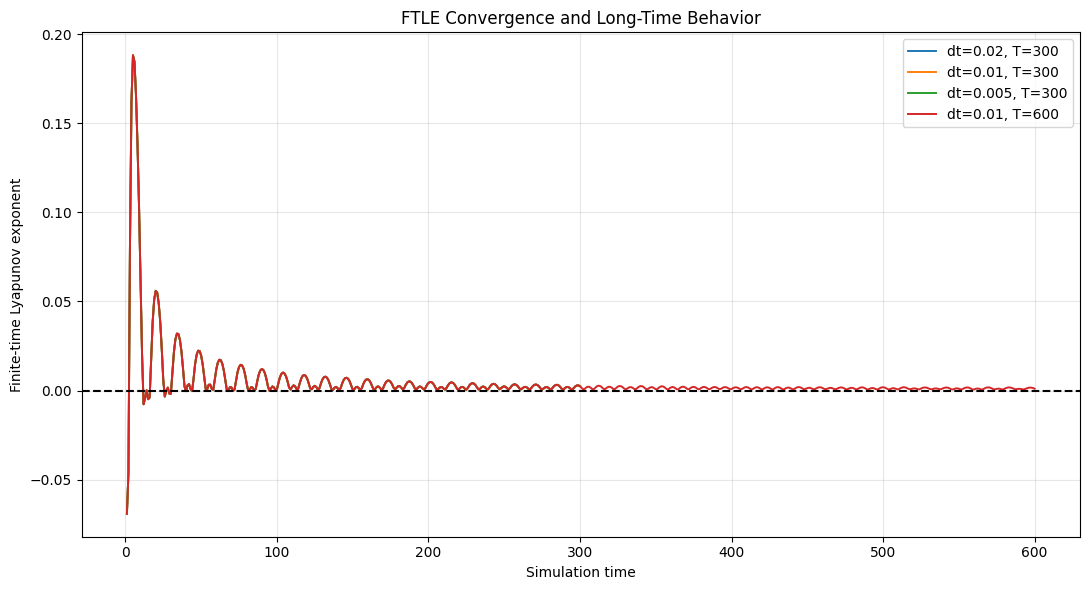

In [55]:

# Objective 07.3: FTLE validation

settings = [
    (0.02, 300.0),
    (0.01, 300.0),
    (0.005, 300.0),
    (0.01, 600.0)
]

ftle_results = {}

plt.figure(figsize=(11, 6))

for dt_test, duration in settings:

    t_values, lambda_values = estimate_ftle(
        positions_A,
        velocities_A,
        chaos_masses,
        dt=dt_test,
        total_time=duration,
        renorm_interval=1.0
    )

    label = f"dt={dt_test}, T={duration:g}"

    ftle_results[(dt_test, duration)] = {
        "time": t_values,
        "ftle": lambda_values
    }

    plt.plot(
        t_values,
        lambda_values,
        label=label,
        linewidth=1.4
    )

    print(
        f"{label:22s} | "
        f"Final FTLE = {lambda_values[-1]:.8e}"
    )

plt.axhline(0, color="black", linestyle="--")

plt.xlabel("Simulation time")
plt.ylabel("Finite-time Lyapunov exponent")
plt.title("FTLE Convergence and Long-Time Behavior")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [56]:
import numpy as np

# Make sure Cell 8 has been executed first.
# It creates the dictionary: ftle_results

print("=" * 60)
print("FTLE TIMESTEP CONVERGENCE")
print("=" * 60)

# Finest timestep serves as our numerical reference.
reference = ftle_results[(0.005, 300.0)]["ftle"][-1]

for dt_test in [0.02, 0.01, 0.005]:

    result = ftle_results[(dt_test, 300.0)]["ftle"][-1]

    difference = abs(result - reference)

    print(
        f"dt = {dt_test:.3f} | "
        f"FTLE = {result:.10e} | "
        f"Difference = {difference:.3e}"
    )


print("\n" + "=" * 60)
print("FTLE SIMULATION DURATION COMPARISON")
print("=" * 60)

# Compare identical timestep at different durations.
ftle_300 = ftle_results[(0.01, 300.0)]["ftle"][-1]
ftle_600 = ftle_results[(0.01, 600.0)]["ftle"][-1]

print(f"FTLE at T = 300: {ftle_300:.10e}")
print(f"FTLE at T = 600: {ftle_600:.10e}")

print("\nChange in FTLE:")
print(f"{ftle_600 - ftle_300:.10e}")

FTLE TIMESTEP CONVERGENCE
dt = 0.020 | FTLE = 2.4266880286e-03 | Difference = 2.505e-10
dt = 0.010 | FTLE = 2.4266882747e-03 | Difference = 4.464e-12
dt = 0.005 | FTLE = 2.4266882791e-03 | Difference = 0.000e+00

FTLE SIMULATION DURATION COMPARISON
FTLE at T = 300: 2.4266882747e-03
FTLE at T = 600: 1.0187806948e-03

Change in FTLE:
-1.4079075798e-03



# Objective 08 — Searching for Chaotic Gravitational Motion

## 8.1 Why do we need a chaotic system?

Our research investigates whether numerical methods can create misleading indications of chaos.

To study that problem, we need contrasting physical examples:

1. A configuration that behaves regularly.
2. A configuration with convincing evidence of genuine chaos.

We already have a promising regular reference.

Now we will search for a chaotic configuration using the **restricted three-body problem**.

### The physical setup

Imagine a star, a massive planet, and a tiny test particle.

The star attracts both objects.

The massive planet also attracts the test particle, continually perturbing its motion.

We assume the test particle has negligible mass, so it does not gravitationally influence the star or planet.

This allows us to study the stability of its motion without changing the massive bodies' dynamics.

### Our experiment

We will keep the star and massive planet unchanged while varying the test particle's initial orbital radius.

For each configuration, we will calculate a finite-time Lyapunov exponent.

Configurations with relatively large positive estimates will be treated as **chaos candidates**, not confirmed chaotic systems.

We will validate promising candidates using longer integrations, smaller timesteps, and additional diagnostics.


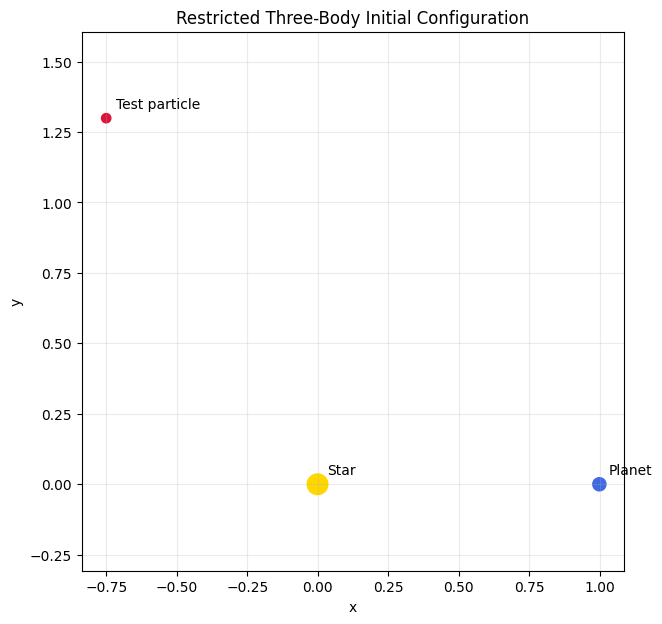

In [57]:

import numpy as np
import matplotlib.pyplot as plt

G_value = 1.0

def make_restricted_three_body(
    test_radius=1.5,
    test_angle_deg=120.0,
    planet_mass=0.001
):
    """
    Create a planar star + massive planet + massless test particle.

    Uses approximately circular heliocentric initial
    conditions for the test particle.

    The star and massive planet begin on an exact
    Newtonian circular two-body configuration.
    """

    m_star = 1.0
    m_planet = planet_mass
    m_test = 0.0

    masses = np.array([
        m_star,
        m_planet,
        m_test
    ], dtype=float)

    M = m_star + m_planet
    a_planet = 1.0

    omega = np.sqrt(
        G_value * M / a_planet**3
    )

    # Star and massive planet around their barycenter.
    r_star = np.array([
        -m_planet / M * a_planet, 0.0
    ])

    r_planet = np.array([
        m_star / M * a_planet, 0.0
    ])

    v_star = np.array([
        0.0, omega * r_star[0]
    ])

    v_planet = np.array([
        0.0, omega * r_planet[0]
    ])

    # Position of test particle relative to the star.
    angle = np.deg2rad(test_angle_deg)

    direction = np.array([
        np.cos(angle),
        np.sin(angle)
    ])

    tangent = np.array([
        -np.sin(angle),
        np.cos(angle)
    ])

    r_test = (
        r_star + test_radius * direction
    )

    # Approximate circular heliocentric velocity.
    v_circular = np.sqrt(
        G_value * m_star / test_radius
    )

    v_test = (
        v_star + v_circular * tangent
    )

    positions = np.array([
        r_star,
        r_planet,
        r_test
    ])

    velocities = np.array([
        v_star,
        v_planet,
        v_test
    ])

    return positions, velocities, masses


# Visualize one configuration.
r0, v0, m0 = make_restricted_three_body(
    test_radius=1.5
)

plt.figure(figsize=(7, 7))

plt.scatter(
    r0[:, 0],
    r0[:, 1],
    s=[220, 90, 45],
    c=["gold", "royalblue", "crimson"]
)

for i, label in enumerate([
    "Star", "Planet", "Test particle"
]):
    plt.annotate(
        label,
        (r0[i, 0], r0[i, 1]),
        xytext=(7, 7),
        textcoords="offset points"
    )

plt.xlabel("x")
plt.ylabel("y")
plt.title("Restricted Three-Body Initial Configuration")
plt.axis("equal")
plt.grid(alpha=0.25)
plt.show()



## 8.2 Searching across orbital configurations

Suppose we position the test particle at different distances from the star.

At some distances, gravitational perturbations from the massive planet may be relatively weak.

At others, repeated gravitational interactions can create unstable or chaotic behavior.

One important mechanism involves **orbital resonances**.

A resonance occurs when orbital frequencies are related by ratios of small integers.

For example, a 2:1 mean-motion resonance means that one object completes approximately two orbits during one orbit of another object.

Resonances can produce both stable and chaotic regions. Being near a resonance does not automatically imply chaos.

We will examine several initial radii and estimate how infinitesimal perturbations grow.

### What does the Lyapunov exponent tell us?

For infinitesimal perturbations:

$$
\|\delta X(t)\|\sim e^{\lambda t}
$$

If the maximal Lyapunov exponent is positive, small disturbances grow exponentially in the asymptotic limit.

But we only have finite simulation times.

Therefore, our initial scan will locate promising candidates. It will not determine their final dynamical classifications.


In [58]:

# First exploratory parameter scan

test_radii = np.array([
    1.20, 1.30, 1.40, 1.50,
    1.60, 1.70, 1.85, 2.00
])

scan_dt = 0.02
scan_duration = 120.0

scan_results = []

for radius in test_radii:

    r0, v0, m0 = make_restricted_three_body(
        test_radius=radius,
        test_angle_deg=120.0
    )

    t_values, ftle_values = estimate_ftle(
        r0,
        v0,
        m0,
        dt=scan_dt,
        total_time=scan_duration,
        renorm_interval=1.0
    )

    final_ftle = ftle_values[-1]

    scan_results.append({
        "radius": radius,
        "ftle": final_ftle
    })

    print(
        f"Radius = {radius:.2f} | "
        f"FTLE = {final_ftle:.8e}"
    )

print("\nInitial scan completed.")


Radius = 1.20 | FTLE = 1.46405083e-01
Radius = 1.30 | FTLE = 2.87654409e-02
Radius = 1.40 | FTLE = 4.08326786e-02
Radius = 1.50 | FTLE = 3.96435589e-02
Radius = 1.60 | FTLE = 3.81377471e-02
Radius = 1.70 | FTLE = 3.76831296e-02
Radius = 1.85 | FTLE = 3.65234298e-02
Radius = 2.00 | FTLE = 3.53529760e-02

Initial scan completed.


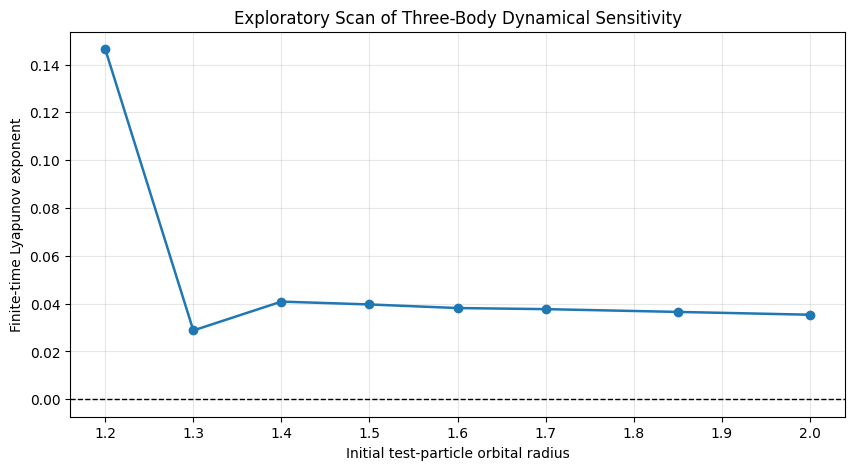

Largest finite-time FTLE candidate
---------------------------------
Radius: 1.2
FTLE: 0.1464050825554648


In [59]:

radii = np.array([
    result["radius"]
    for result in scan_results
])

ftle_values = np.array([
    result["ftle"]
    for result in scan_results
])

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    radii,
    ftle_values,
    "o-",
    linewidth=1.8,
    markersize=6
)

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Initial test-particle orbital radius")
ax.set_ylabel("Finite-time Lyapunov exponent")
ax.set_title("Exploratory Scan of Three-Body Dynamical Sensitivity")
ax.grid(alpha=0.3)

plt.show()

highest_index = np.argmax(ftle_values)

candidate_radius = radii[highest_index]
candidate_ftle = ftle_values[highest_index]

print("Largest finite-time FTLE candidate")
print("---------------------------------")
print("Radius:", candidate_radius)
print("FTLE:", candidate_ftle)


Minimum distance to star: 0.6643709239540966
Minimum distance to massive planet: 0.0016112474731034253


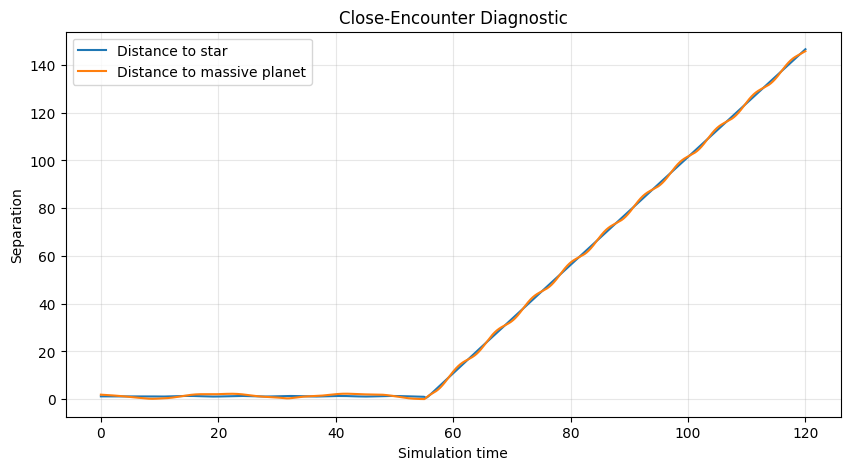

In [60]:

# Rebuild the candidate system.
candidate_r, candidate_v, candidate_m = (
    make_restricted_three_body(
        test_radius=candidate_radius,
        test_angle_deg=120.0
    )
)

# Integrate the candidate.
candidate_dt = 0.01
candidate_duration = 120.0
candidate_steps = int(
    round(candidate_duration / candidate_dt)
)

candidate_pos, candidate_vel = simulate_with_integrator(
    rk4_step,
    candidate_r,
    candidate_v,
    candidate_m,
    candidate_dt,
    candidate_steps
)

# Test-particle distance from the star.
distance_to_star = np.linalg.norm(
    candidate_pos[:, 2, :] - candidate_pos[:, 0, :],
    axis=1
)

# Test-particle distance from the massive planet.
distance_to_planet = np.linalg.norm(
    candidate_pos[:, 2, :] - candidate_pos[:, 1, :],
    axis=1
)

print(
    "Minimum distance to star:",
    distance_to_star.min()
)

print(
    "Minimum distance to massive planet:",
    distance_to_planet.min()
)

time = np.arange(candidate_steps + 1) * candidate_dt

plt.figure(figsize=(10, 5))

plt.plot(
    time,
    distance_to_star,
    label="Distance to star"
)

plt.plot(
    time,
    distance_to_planet,
    label="Distance to massive planet"
)

plt.xlabel("Simulation time")
plt.ylabel("Separation")
plt.title("Close-Encounter Diagnostic")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



## 8.3 Investigating a possible test-particle ejection

Our orbital scan produced a configuration in which the test particle moves rapidly away from the massive bodies after approximately 56 simulation time units.

This may indicate a gravitational ejection.

However, a reliable scientific conclusion requires us to investigate:

1. Whether the particle experienced a close gravitational encounter.
2. Whether its outward motion is energetically consistent with escape.
3. Whether the ejection occurs at approximately the same time when we reduce the numerical timestep.

A test particle can gain orbital energy through gravitational interactions with a moving massive planet.

Because the massive planet creates a time-dependent gravitational potential along the test particle's trajectory, the particle's energy relative to the star is not necessarily conserved.

We must also remember that our test particle has zero mass. Its contribution to the total system energy is therefore zero.

Consequently, excellent conservation of the massive star-planet system's energy does not, by itself, validate the test particle trajectory.


Closest approach time: 55.08
Minimum planet distance: 0.0016112474731034253
Star distance at closest approach: 1.0014147700156493

Final distance from star: 146.5966541715961
Final relative speed: 2.25719630269284
Final star-relative specific energy: 2.5406461363594297


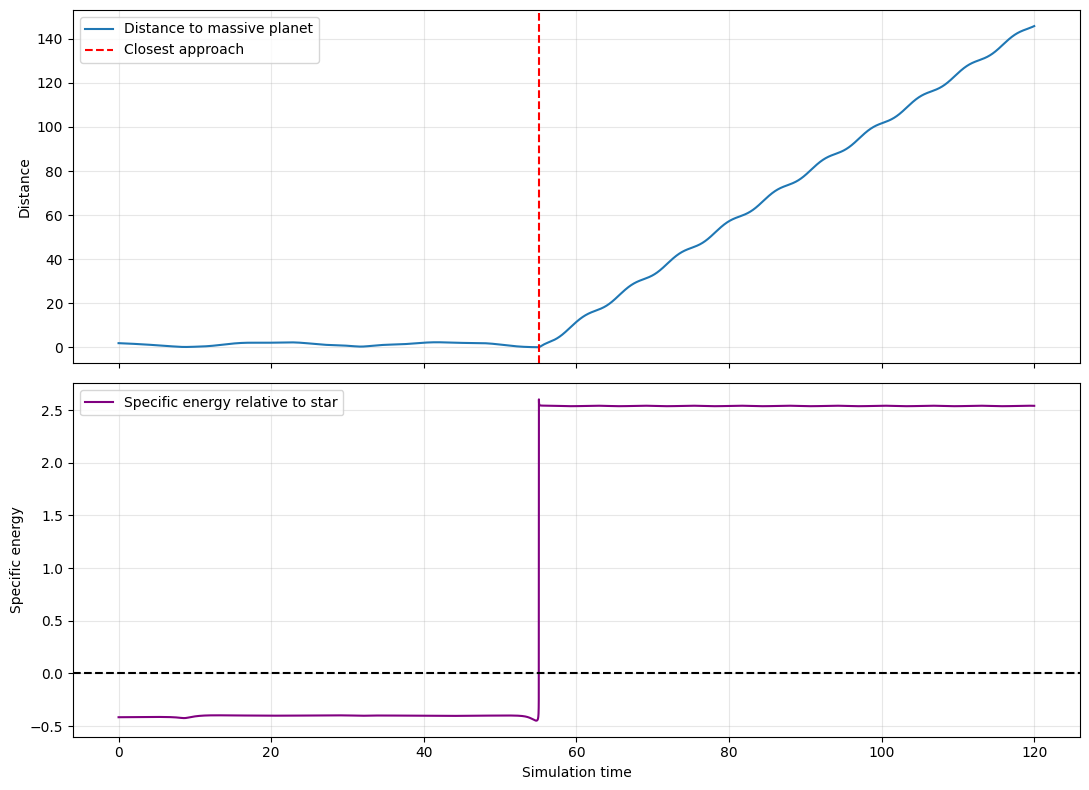

In [61]:

# Positions and velocities from our existing candidate simulation.

r_star = candidate_pos[:, 0, :]
r_planet = candidate_pos[:, 1, :]
r_test = candidate_pos[:, 2, :]

v_star = candidate_vel[:, 0, :]
v_test = candidate_vel[:, 2, :]

# Distances relative to the massive objects.
d_star = np.linalg.norm(r_test - r_star, axis=1)
d_planet = np.linalg.norm(r_test - r_planet, axis=1)

# Test-particle motion relative to the star.
relative_position = r_test - r_star
relative_velocity = v_test - v_star

relative_speed = np.linalg.norm(relative_velocity, axis=1)

# Keplerian specific energy relative to the star.
# This is a diagnostic, not a conserved quantity in our 3-body system.
mu_star = G_value * candidate_m[0]

specific_energy = (
    0.5 * relative_speed**2
    - mu_star / d_star
)

# Closest encounter with the massive planet.
closest_index = np.argmin(d_planet)

print("Closest approach time:", time[closest_index])
print("Minimum planet distance:", d_planet[closest_index])
print("Star distance at closest approach:", d_star[closest_index])

print("\nFinal distance from star:", d_star[-1])
print("Final relative speed:", relative_speed[-1])
print("Final star-relative specific energy:", specific_energy[-1])

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

axes[0].plot(time, d_planet, label="Distance to massive planet")
axes[0].axvline(
    time[closest_index],
    color="red",
    linestyle="--",
    label="Closest approach"
)
axes[0].set_ylabel("Distance")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    time,
    specific_energy,
    color="purple",
    label="Specific energy relative to star"
)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_xlabel("Simulation time")
axes[1].set_ylabel("Specific energy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


dt=0.0100 | r>10 at t=59.61000 | closest planet=1.611247e-03 | final distance=146.596654
dt=0.0050 | r>10 at t=64.75000 | closest planet=1.427671e-03 | final distance=59.831034
dt=0.0025 | r>10 at t=55.97500 | closest planet=1.357630e-03 | final distance=660.682104


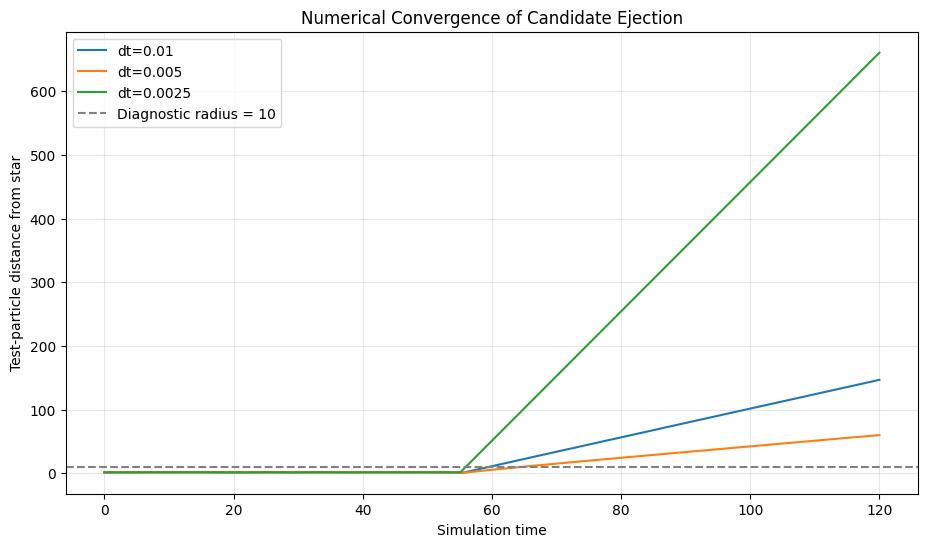

In [62]:

# Compare the candidate trajectory using finer timesteps.

dt_tests = [0.01, 0.005, 0.0025]
duration = 120.0

escape_results = {}

for dt_test in dt_tests:

    steps = int(round(duration / dt_test))

    p, v = simulate_with_integrator(
        rk4_step,
        candidate_r,
        candidate_v,
        candidate_m,
        dt_test,
        steps
    )

    t = np.arange(steps + 1) * dt_test

    star_distance = np.linalg.norm(
        p[:, 2, :] - p[:, 0, :],
        axis=1
    )

    planet_distance = np.linalg.norm(
        p[:, 2, :] - p[:, 1, :],
        axis=1
    )

    # Operational threshold, not proof of permanent escape.
    crossing = np.where(star_distance > 10.0)[0]

    crossing_time = (
        t[crossing[0]] if len(crossing) else np.nan
    )

    escape_results[dt_test] = {
        "time": t,
        "distance": star_distance,
        "crossing_time": crossing_time,
        "closest_planet": np.min(planet_distance),
        "final_distance": star_distance[-1]
    }

    print(
        f"dt={dt_test:.4f} | "
        f"r>10 at t={crossing_time:.5f} | "
        f"closest planet={np.min(planet_distance):.6e} | "
        f"final distance={star_distance[-1]:.6f}"
    )

plt.figure(figsize=(11, 6))

for dt_test, result in escape_results.items():
    plt.plot(
        result["time"],
        result["distance"],
        label=f"dt={dt_test}"
    )

plt.axhline(
    10.0,
    color="gray",
    linestyle="--",
    label="Diagnostic radius = 10"
)

plt.xlabel("Simulation time")
plt.ylabel("Test-particle distance from star")
plt.title("Numerical Convergence of Candidate Ejection")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



## 8.4 Validating a possible gravitational ejection

Our three RK4 simulations produced very different final distances for the same initial conditions.

The simulated trajectories begin departing rapidly around the same time, but their later motion does not converge as we reduce the timestep.

One possible explanation is an unresolved close encounter with the massive planet.

We will now use an adaptive numerical integrator that automatically adjusts its timestep according to an error tolerance.

Our investigation has three goals:

1. Obtain a more trustworthy reference trajectory.
2. Determine whether the test particle undergoes a close gravitational encounter.
3. Compare the adaptive solution against our original fixed-step RK4 results.

If independently refined adaptive solutions agree, while our fixed-step RK4 trajectories disagree, this supports the interpretation that the fixed timesteps were insufficient.

Agreement between adaptive solutions provides numerical evidence, not an absolute mathematical proof of the exact trajectory.


In [63]:

from scipy.integrate import solve_ivp
import numpy as np
import matplotlib.pyplot as plt

# We already have these from our earlier experiments:
# candidate_r, candidate_v, candidate_m
# gravitational_accelerations, G_value

def three_body_rhs(t, y, masses):
    """
    Differential equations for 3 bodies in 2D.

    State layout:
    first 6 values = positions
    next 6 values  = velocities
    """
    N = len(masses)

    r = y[:2*N].reshape(N, 2)
    v = y[2*N:].reshape(N, 2)

    a = gravitational_accelerations(r, masses)

    return np.concatenate([
        v.ravel(),
        a.ravel()
    ])


def run_adaptive_reference(
    r0, v0, masses,
    total_time=120.0,
    rtol=1e-11,
    atol=1e-13,
    max_step=0.1
):
    N = len(masses)

    initial_state = np.concatenate([
        r0.ravel(),
        v0.ravel()
    ])

    output_times = np.linspace(
        0, total_time, 1201
    )

    solution = solve_ivp(
        three_body_rhs,
        (0, total_time),
        initial_state,
        args=(masses,),
        method="DOP853",
        t_eval=output_times,
        rtol=rtol,
        atol=atol,
        max_step=max_step
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    positions = (
        solution.y[:2*N].T.reshape(-1, N, 2)
    )

    velocities = (
        solution.y[2*N:].T.reshape(-1, N, 2)
    )

    return solution.t, positions, velocities


# Two independently refined numerical runs
t_ref, p_ref, v_ref = run_adaptive_reference(
    candidate_r, candidate_v, candidate_m,
    rtol=1e-10,
    atol=1e-12,
    max_step=0.1
)

t_fine, p_fine, v_fine = run_adaptive_reference(
    candidate_r, candidate_v, candidate_m,
    rtol=1e-12,
    atol=1e-14,
    max_step=0.02
)

print("Adaptive integrations completed.")


Adaptive integrations completed.


ADAPTIVE REFERENCE: CLOSE ENCOUNTER DIAGNOSTIC
Closest sampled approach time: 55.100000
Minimum sampled planet distance: 1.1420071170e-02
Final distance from star: 1.370487


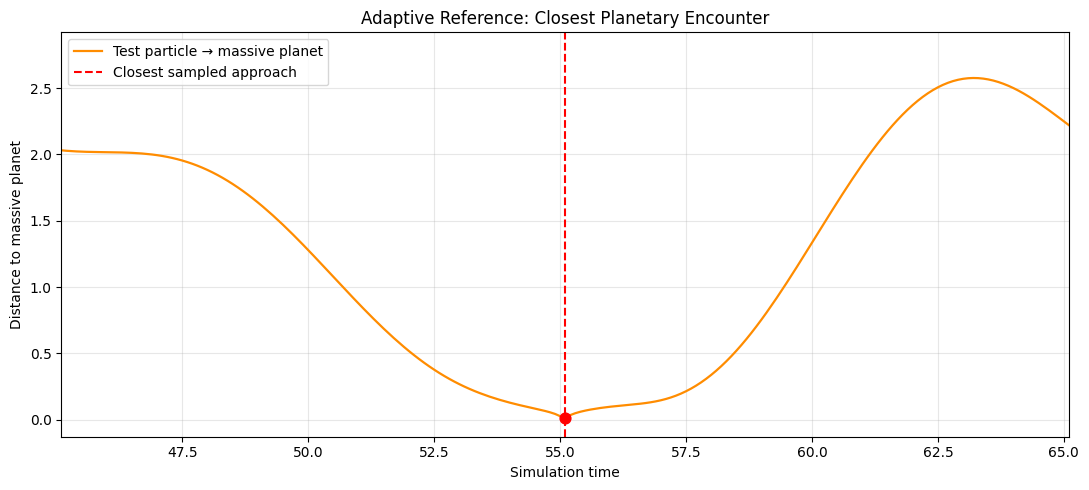

In [65]:

import numpy as np
import matplotlib.pyplot as plt

# Check that the adaptive simulation results exist.
# These variables are created in Cell 11:
# t_fine, p_fine, v_fine

if "t_fine" not in globals() or "p_fine" not in globals():
    raise RuntimeError(
        "Run Cell 11 first to generate t_fine and p_fine."
    )

# Extract positions of the three bodies.
# Body 0 = star
# Body 1 = massive planet
# Body 2 = massless test particle

star_positions = p_fine[:, 0, :]
planet_positions = p_fine[:, 1, :]
test_positions = p_fine[:, 2, :]

# Calculate distances at each recorded time.
distance_to_star = np.linalg.norm(
    test_positions - star_positions,
    axis=1
)

distance_to_planet = np.linalg.norm(
    test_positions - planet_positions,
    axis=1
)

# Find closest sampled approach to the planet.
closest_index = np.argmin(distance_to_planet)

closest_time = t_fine[closest_index]
closest_distance = distance_to_planet[closest_index]

print("=" * 55)
print("ADAPTIVE REFERENCE: CLOSE ENCOUNTER DIAGNOSTIC")
print("=" * 55)

print(f"Closest sampled approach time: {closest_time:.6f}")
print(f"Minimum sampled planet distance: {closest_distance:.10e}")
print(f"Final distance from star: {distance_to_star[-1]:.6f}")

# Plot the close encounter.
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    t_fine,
    distance_to_planet,
    color="darkorange",
    linewidth=1.6,
    label="Test particle → massive planet"
)

ax.axvline(
    closest_time,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Closest sampled approach"
)

ax.scatter(
    [closest_time],
    [closest_distance],
    color="red",
    s=60,
    zorder=5
)

# Zoom around the detected encounter rather than
# assuming it happens between t=40 and t=70.
ax.set_xlim(
    max(t_fine[0], closest_time - 10),
    min(t_fine[-1], closest_time + 10)
)

ax.set_xlabel("Simulation time")
ax.set_ylabel("Distance to massive planet")
ax.set_title("Adaptive Reference: Closest Planetary Encounter")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



## 8.5 Resolving the close encounter

Our adaptive simulation indicates that the test particle passes extremely close to the massive planet around simulation time 55.

But our previous diagnostic only examined positions recorded at discrete output times.

The closest approach may occur between those observations.

We will now use the adaptive solver's continuous interpolation to locate the minimum separation more accurately.

We will also compare solutions obtained with different numerical tolerances.

This helps determine whether the close encounter is numerically resolved.

### Physical question

How close does the test particle actually approach the massive planet, and is that minimum distance stable under numerical refinement?


CLOSEST APPROACH COMPARISON
------------------------------------------------------------

Reference
Closest approach time: 55.080752072104
Minimum distance:      2.551441446845e-05

Refined
Closest approach time: 55.080752072093
Minimum distance:      2.551441461755e-05


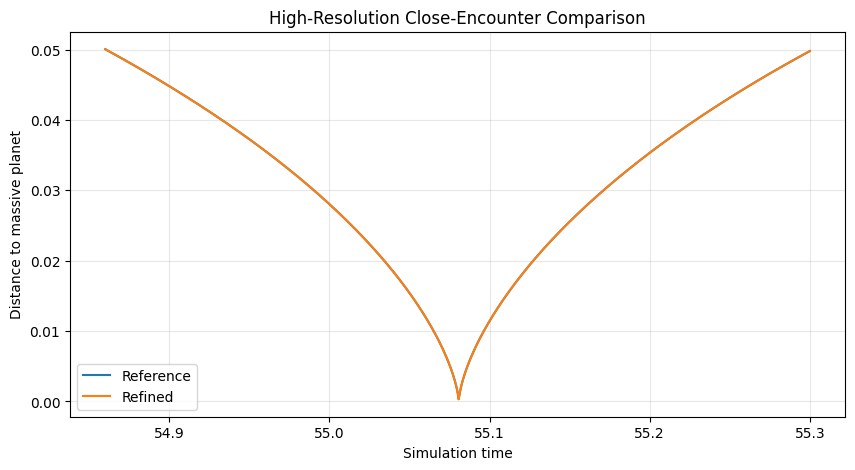

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar

# Initial state
N = len(candidate_m)

y0 = np.concatenate([
    candidate_r.ravel(),
    candidate_v.ravel()
])

# Run two adaptive integrations with continuous output.
settings = [
    ("Reference", 1e-10, 1e-12, 0.05),
    ("Refined",   1e-12, 1e-14, 0.01)
]

solutions = {}

for name, rtol, atol, max_step in settings:

    sol = solve_ivp(
        three_body_rhs,
        (0.0, 120.0),
        y0,
        args=(candidate_m,),
        method="DOP853",
        rtol=rtol,
        atol=atol,
        max_step=max_step,
        dense_output=True
    )

    if not sol.success:
        raise RuntimeError(
            f"{name} integration failed: {sol.message}"
        )

    solutions[name] = sol

# Return test-particle distance from the massive planet.
def planet_distance(t, sol):

    y = sol.sol(t)

    r = y[:2*N].reshape(N, 2)

    return np.linalg.norm(
        r[2] - r[1]
    )

# Locate the encounter using a fine time grid.
# We search globally over the simulated duration first.
fine_times = np.linspace(0, 120, 12001)

distances = np.array([
    planet_distance(t, solutions["Refined"])
    for t in fine_times
])

index = np.argmin(distances)

# Refine the local minimum around the best sampled point.
left = fine_times[max(index - 2, 0)]
right = fine_times[min(index + 2, len(fine_times) - 1)]

print("CLOSEST APPROACH COMPARISON")
print("-" * 60)

for name, sol in solutions.items():

    result = minimize_scalar(
        lambda t: planet_distance(t, sol),
        bounds=(left, right),
        method="bounded",
        options={"xatol": 1e-12}
    )

    print(f"\n{name}")
    print(f"Closest approach time: {result.x:.12f}")
    print(f"Minimum distance:      {result.fun:.12e}")

# Plot the refined encounter region.
encounter_times = np.linspace(left - 0.2, right + 0.2, 1000)
encounter_times = np.clip(encounter_times, 0, 120)

plt.figure(figsize=(10, 5))

for name, sol in solutions.items():

    d = [
        planet_distance(t, sol)
        for t in encounter_times
    ]

    plt.plot(encounter_times, d, label=name)

plt.xlabel("Simulation time")
plt.ylabel("Distance to massive planet")
plt.title("High-Resolution Close-Encounter Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



## 8.6 Validating the complete gravitational scattering trajectory

Our two adaptive integrations agree extremely closely on the time and minimum distance of the encounter.

However, a gravitational encounter is not determined by minimum distance alone.

We also need to establish whether the particle leaves the encounter with the same velocity and direction.

We will compare:

1. Test-particle position relative to the star.
2. Test-particle velocity relative to the star.
3. Numerical disagreement throughout the encounter.
4. Final outgoing speed and distance.

Our main question is whether independent numerical refinements approach the same physical trajectory.

A converged trajectory would provide a much stronger reference against which to evaluate our fixed-step RK4 results.


FULL TRAJECTORY CONVERGENCE
-------------------------------------------------------
Maximum position disagreement: 1.160724e-06
Maximum velocity disagreement: 8.554456e-07

Final position disagreement: 8.572476e-07
Final velocity disagreement: 5.676268e-07

Refined solution:
Final star-relative distance: 1.370487
Final star-relative speed: 0.879410


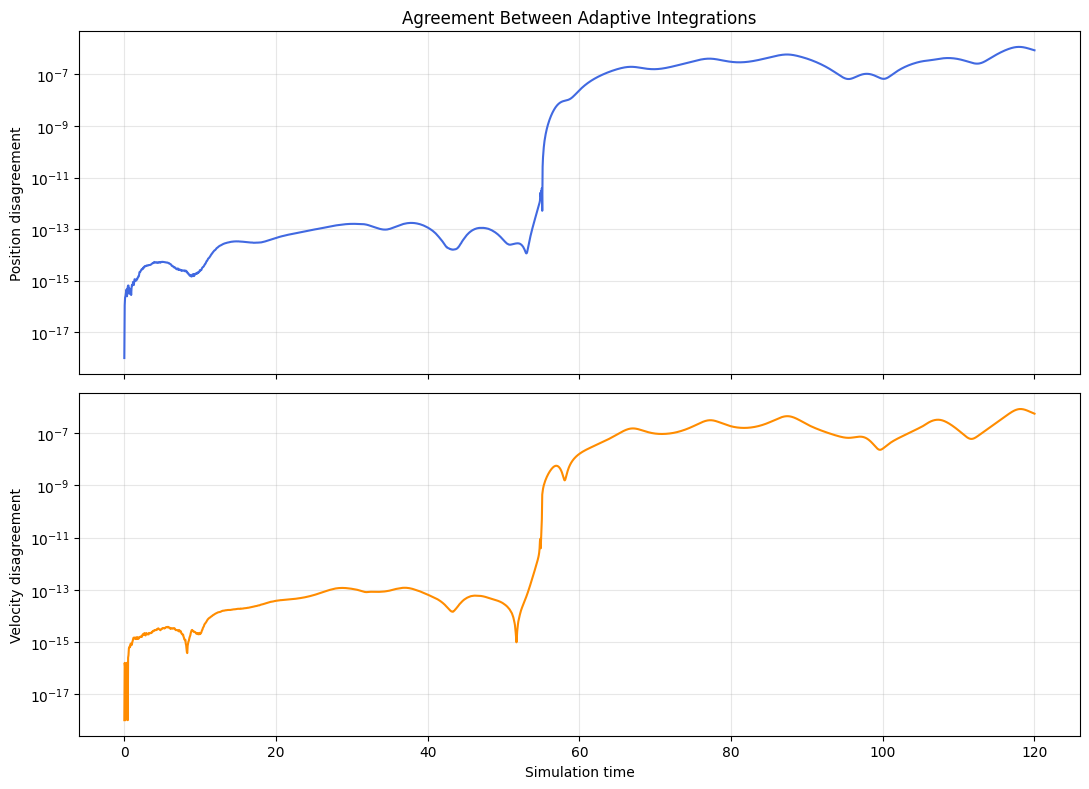

In [67]:

import numpy as np
import matplotlib.pyplot as plt

# Retrieve the adaptive solutions.
sol_reference = solutions["Reference"]
sol_refined = solutions["Refined"]

# Common observation times
t_compare = np.linspace(0.0, 120.0, 2401)

N = len(candidate_m)

def extract_state(sol, times):
    y = sol.sol(times)

    positions = y[:2*N].T.reshape(-1, N, 2)
    velocities = y[2*N:].T.reshape(-1, N, 2)

    return positions, velocities

p1, v1 = extract_state(sol_reference, t_compare)
p2, v2 = extract_state(sol_refined, t_compare)

# Test-particle position relative to the star
q1 = p1[:, 2, :] - p1[:, 0, :]
q2 = p2[:, 2, :] - p2[:, 0, :]

# Test-particle velocity relative to the star
u1 = v1[:, 2, :] - v1[:, 0, :]
u2 = v2[:, 2, :] - v2[:, 0, :]

# Disagreement between the adaptive solutions
position_error = np.linalg.norm(q1 - q2, axis=1)
velocity_error = np.linalg.norm(u1 - u2, axis=1)

print("FULL TRAJECTORY CONVERGENCE")
print("-" * 55)

print(f"Maximum position disagreement: {position_error.max():.6e}")
print(f"Maximum velocity disagreement: {velocity_error.max():.6e}")

print(f"\nFinal position disagreement: {position_error[-1]:.6e}")
print(f"Final velocity disagreement: {velocity_error[-1]:.6e}")

print("\nRefined solution:")
print(f"Final star-relative distance: {np.linalg.norm(q2[-1]):.6f}")
print(f"Final star-relative speed: {np.linalg.norm(u2[-1]):.6f}")

# Plot differences over time
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

axes[0].semilogy(
    t_compare,
    np.maximum(position_error, 1e-18),
    color="royalblue"
)
axes[0].set_ylabel("Position disagreement")
axes[0].set_title("Agreement Between Adaptive Integrations")
axes[0].grid(alpha=0.3, which="both")

axes[1].semilogy(
    t_compare,
    np.maximum(velocity_error, 1e-18),
    color="darkorange"
)
axes[1].set_xlabel("Simulation time")
axes[1].set_ylabel("Velocity disagreement")
axes[1].grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()



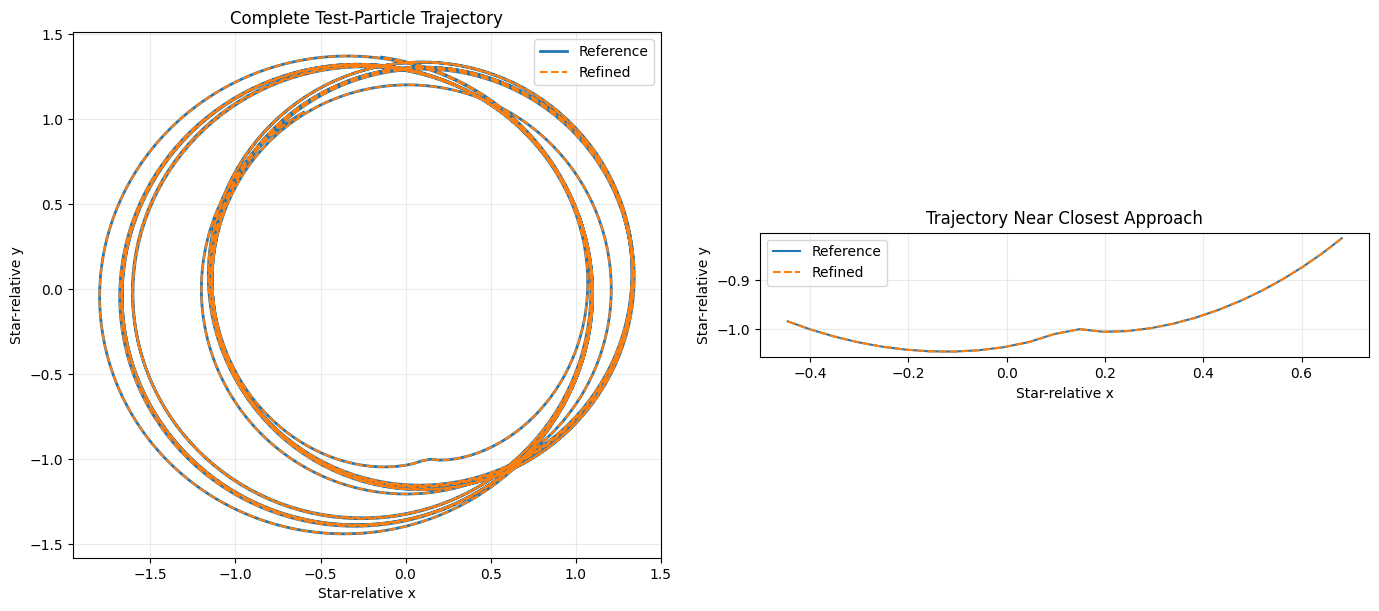

In [68]:

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Entire trajectories, relative to the star
axes[0].plot(
    q1[:, 0], q1[:, 1],
    label="Reference",
    linewidth=2
)

axes[0].plot(
    q2[:, 0], q2[:, 1],
    "--",
    label="Refined",
    linewidth=1.5
)

axes[0].set_title("Complete Test-Particle Trajectory")

# Zoom around the planetary encounter.
mask = (t_compare >= 54.5) & (t_compare <= 55.7)

axes[1].plot(
    q1[mask, 0],
    q1[mask, 1],
    label="Reference"
)

axes[1].plot(
    q2[mask, 0],
    q2[mask, 1],
    "--",
    label="Refined"
)

axes[1].set_title("Trajectory Near Closest Approach")

for ax in axes:
    ax.set_xlabel("Star-relative x")
    ax.set_ylabel("Star-relative y")
    ax.set_aspect("equal", adjustable="box")
    ax.legend()
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()



## 8.8 Comparing fixed-step integration against a refined reference

Our fixed-step RK4 simulations predicted large outward excursions after a close gravitational encounter.

However, our adaptively refined DOP853 simulations appear to produce a very different outcome.

We now want to quantify this discrepancy.

We will compare the test particle's position and velocity relative to the star using the same initial conditions and observation times.

For each RK4 timestep, we will calculate:

- Maximum position error relative to the adaptive reference.
- Final position error.
- Final star-relative distance.
- Error before and after the close encounter.

This will help us determine when the numerical predictions begin disagreeing and how severely the errors affect the outcome.

The adaptive solution is a numerical reference, not an exact mathematical solution.


In [69]:

import numpy as np
import matplotlib.pyplot as plt

# Refined adaptive result from Objective 08.
adaptive_solution = solutions["Refined"]

# Common evaluation times.
comparison_times = np.linspace(0.0, 120.0, 1201)

N = len(candidate_m)

# Evaluate adaptive solution.
adaptive_state = adaptive_solution.sol(comparison_times)

adaptive_positions = (
    adaptive_state[:2*N].T.reshape(-1, N, 2)
)

adaptive_velocities = (
    adaptive_state[2*N:].T.reshape(-1, N, 2)
)

# Test-particle position relative to the star.
adaptive_relative_pos = (
    adaptive_positions[:, 2, :]
    - adaptive_positions[:, 0, :]
)

adaptive_relative_vel = (
    adaptive_velocities[:, 2, :]
    - adaptive_velocities[:, 0, :]
)

# Final adaptive distance.
adaptive_final_distance = np.linalg.norm(
    adaptive_relative_pos[-1]
)

print("Adaptive final star-relative distance:",
      adaptive_final_distance)

rk4_comparisons = {}

# Compare each of the previous fixed timesteps.
for dt_test in [0.01, 0.005, 0.0025]:

    n_steps = int(round(120.0 / dt_test))

    pos_hist, vel_hist = simulate_with_integrator(
        rk4_step,
        candidate_r,
        candidate_v,
        candidate_m,
        dt_test,
        n_steps
    )

    # Sample at exactly the same times as adaptive.
    stride = int(round(0.1 / dt_test))

    pos_sampled = pos_hist[::stride]
    vel_sampled = vel_hist[::stride]

    relative_pos = (
        pos_sampled[:, 2, :]
        - pos_sampled[:, 0, :]
    )

    relative_vel = (
        vel_sampled[:, 2, :]
        - vel_sampled[:, 0, :]
    )

    position_error = np.linalg.norm(
        relative_pos - adaptive_relative_pos,
        axis=1
    )

    velocity_error = np.linalg.norm(
        relative_vel - adaptive_relative_vel,
        axis=1
    )

    rk4_comparisons[dt_test] = {
        "position_error": position_error,
        "velocity_error": velocity_error,
        "relative_pos": relative_pos
    }

    print(f"\nRK4 dt = {dt_test}")
    print(f"Maximum position error: {position_error.max():.6e}")
    print(f"Final position error:   {position_error[-1]:.6e}")
    print(
        "Final star-relative distance:",
        np.linalg.norm(relative_pos[-1])
    )


Adaptive final star-relative distance: 1.3704868757472475

RK4 dt = 0.01
Maximum position error: 1.453227e+02
Final position error:   1.453227e+02
Final star-relative distance: 146.5966541715961

RK4 dt = 0.005
Maximum position error: 5.846075e+01
Final position error:   5.846075e+01
Final star-relative distance: 59.8310342963346

RK4 dt = 0.0025
Maximum position error: 6.618948e+02
Final position error:   6.618948e+02
Final star-relative distance: 660.6821044925694


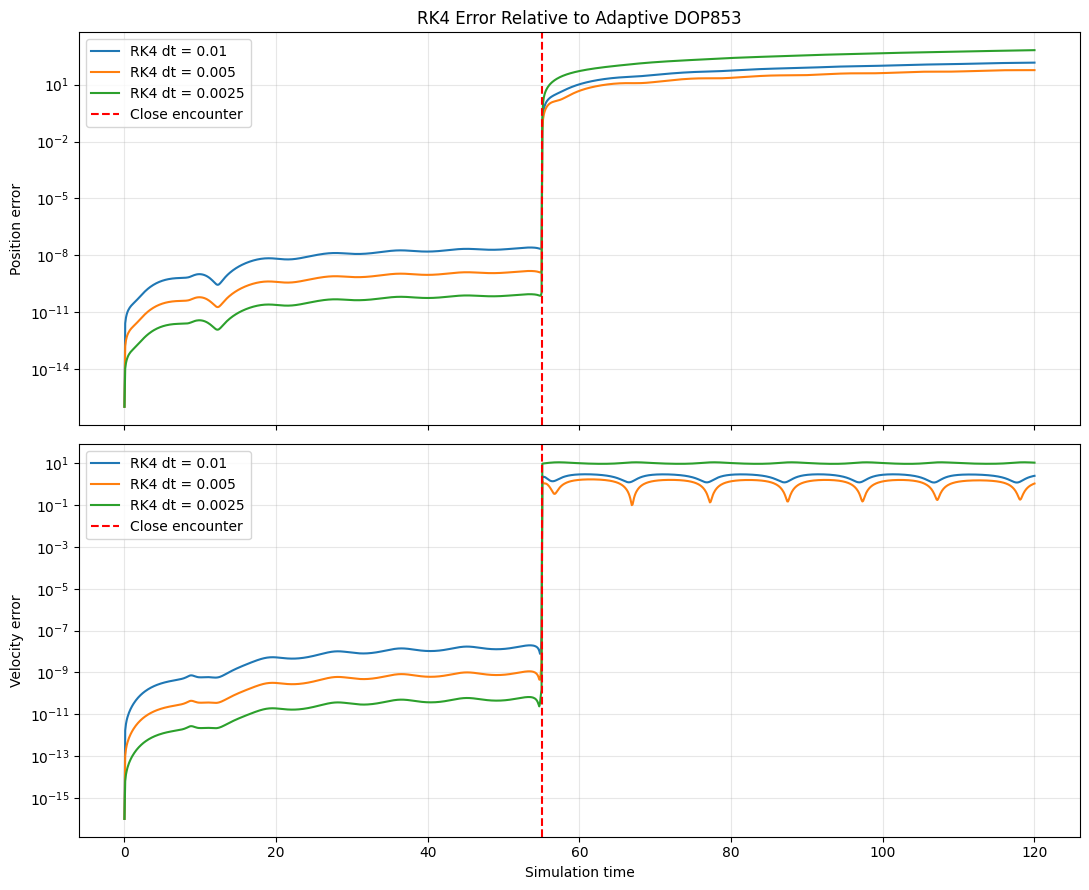

In [70]:

fig, axes = plt.subplots(2, 1, figsize=(11, 9), sharex=True)

for dt_test, data in rk4_comparisons.items():

    axes[0].semilogy(
        comparison_times,
        np.maximum(data["position_error"], 1e-16),
        label=f"RK4 dt = {dt_test}"
    )

    axes[1].semilogy(
        comparison_times,
        np.maximum(data["velocity_error"], 1e-16),
        label=f"RK4 dt = {dt_test}"
    )

# Mark the close encounter.
for ax in axes:

    ax.axvline(
        55.080752,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label="Close encounter"
    )

    ax.legend()
    ax.grid(alpha=0.3, which="both")

axes[0].set_ylabel("Position error")
axes[0].set_title("RK4 Error Relative to Adaptive DOP853")

axes[1].set_ylabel("Velocity error")
axes[1].set_xlabel("Simulation time")

plt.tight_layout()
plt.show()



## 8.10 The characteristic timescale of a gravitational encounter

We have observed that the test particle passes extremely close to the massive planet.

During this encounter, the gravitational acceleration changes rapidly.

A numerical integrator must take sufficiently small steps to resolve this rapid change.

One useful estimate is the encounter-crossing timescale:

$$
t_{\mathrm{enc}}=\frac{r_{\min}}{v_{\mathrm{rel}}}
$$

where:

- $r_{\min}$ is the minimum separation between the test particle and planet.
- $v_{\mathrm{rel}}$ is their relative speed at closest approach.

This estimates how long the particle takes to travel a distance comparable to the closest-approach separation.

We can compare the numerical timestep against this physical timescale:

$$
\eta=\frac{\Delta t}{t_{\mathrm{enc}}}
$$

If $\eta$ is large, the integrator is taking steps much longer than the encounter timescale.

If $\eta$ is small, the integration resolves the encounter more finely.

This is a useful diagnostic, although no single threshold guarantees accurate integration for all gravitational configurations.

Our aim is to investigate whether this dimensionless quantity helps predict numerical failure.


In [71]:

import numpy as np

# Refined adaptive solution
sol = solutions["Refined"]

N = len(candidate_m)

# Find the closest approach again using dense output.
from scipy.optimize import minimize_scalar

def separation_at_time(t):
    state = sol.sol(t)
    r = state[:2*N].reshape(N, 2)
    return np.linalg.norm(r[2] - r[1])

encounter = minimize_scalar(
    separation_at_time,
    bounds=(54.5, 55.7),
    method="bounded",
    options={"xatol": 1e-12}
)

t_closest = encounter.x

# Obtain positions and velocities at closest approach.
state = sol.sol(t_closest)

positions_enc = state[:2*N].reshape(N, 2)
velocities_enc = state[2*N:].reshape(N, 2)

# Test-particle position and velocity relative to planet
dr = positions_enc[2] - positions_enc[1]
dv = velocities_enc[2] - velocities_enc[1]

r_min = np.linalg.norm(dr)
v_rel = np.linalg.norm(dv)

# Encounter crossing timescale
t_enc = r_min / v_rel

print("CLOSE-ENCOUNTER PHYSICS")
print("-" * 55)

print(f"Closest approach time: {t_closest:.12f}")
print(f"Minimum separation:    {r_min:.12e}")
print(f"Relative speed:        {v_rel:.12e}")
print(f"Encounter timescale:   {t_enc:.12e}")

print("\nTIMESTEP RESOLUTION")
print("-" * 55)

for dt_test in [0.01, 0.005, 0.0025]:

    eta = dt_test / t_enc

    print(
        f"dt = {dt_test:.4f} | "
        f"dt / t_enc = {eta:.4f}"
    )


CLOSE-ENCOUNTER PHYSICS
-------------------------------------------------------
Closest approach time: 55.080751809955
Minimum separation:    2.546471478432e-05
Relative speed:        8.860645155563e+00
Encounter timescale:   2.873912038824e-06

TIMESTEP RESOLUTION
-------------------------------------------------------
dt = 0.0100 | dt / t_enc = 3479.5776
dt = 0.0050 | dt / t_enc = 1739.7888
dt = 0.0025 | dt / t_enc = 869.8944


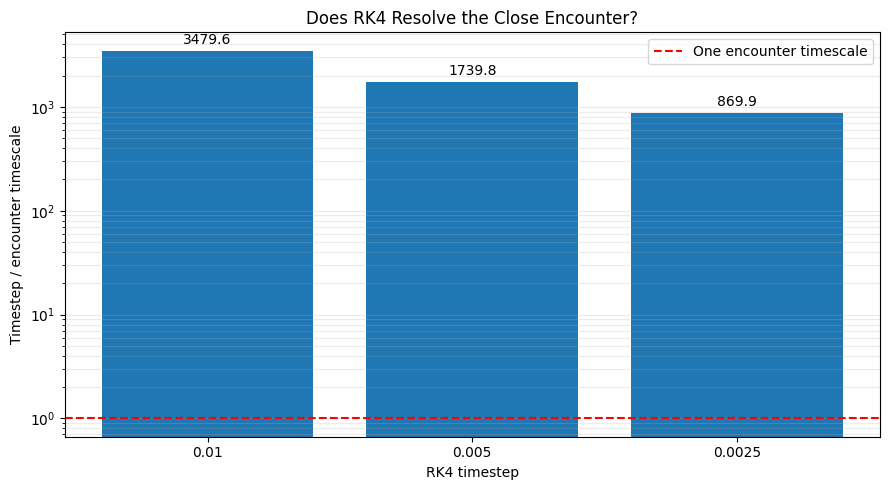

In [72]:

import matplotlib.pyplot as plt

tested_dt = np.array([0.01, 0.005, 0.0025])
resolution_ratios = tested_dt / t_enc

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    ["0.01", "0.005", "0.0025"],
    resolution_ratios
)

ax.axhline(
    1.0,
    color="red",
    linestyle="--",
    label="One encounter timescale"
)

ax.set_yscale("log")
ax.set_xlabel("RK4 timestep")
ax.set_ylabel("Timestep / encounter timescale")
ax.set_title("Does RK4 Resolve the Close Encounter?")

for bar, ratio in zip(bars, resolution_ratios):
    ax.annotate(
        f"{ratio:.1f}",
        (bar.get_x() + bar.get_width()/2, ratio),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.legend()
ax.grid(alpha=0.25, axis="y", which="both")

plt.tight_layout()
plt.show()



## 8.11 How adaptive integration responds to a close encounter

Our fixed-step RK4 simulations failed to resolve an encounter whose characteristic timescale was approximately $2.87\times10^{-6}$.

An adaptive integrator does not use the same timestep everywhere.

When gravitational forces vary rapidly, it can decrease its timestep. When the motion becomes smoother, it can increase it again.

We will examine the actual internal timesteps selected by DOP853.

This lets us investigate whether the adaptive solver concentrated computational effort around the close encounter.

Our goal is to connect the numerical algorithm's behavior directly to the physical encounter timescale.


ADAPTIVE TIMESTEP ANALYSIS
-------------------------------------------------------
Total accepted steps: 12205
Smallest timestep: 2.8187007217184146e-07
Largest timestep: 0.010000000000005116
Smallest timestep near encounter: 2.8187007217184146e-07
Steps with midpoints within ±0.01: 177
Encounter timescale: 2.8739120388243536e-06
Minimum timestep / encounter timescale: 0.0980788793686071


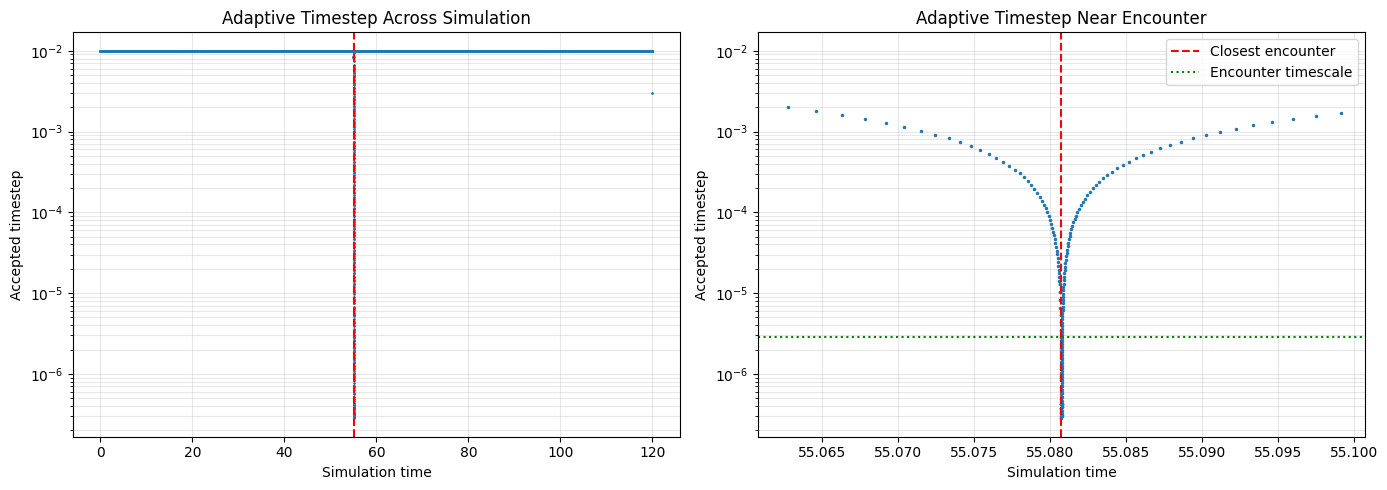

In [73]:

import numpy as np
import matplotlib.pyplot as plt

# Refined adaptive solution from Cell 15
sol = solutions["Refined"]

# Actual integration times selected by DOP853
internal_times = sol.t

# Duration of each accepted internal step
internal_dt = np.diff(internal_times)

# Midpoint of each step
step_midpoints = 0.5 * (
    internal_times[:-1] + internal_times[1:]
)

# Encounter data from Cell 23
encounter_time = t_closest
encounter_timescale = t_enc

# Examine steps near the encounter
near_encounter = (
    np.abs(step_midpoints - encounter_time)
    < 0.01
)

print("ADAPTIVE TIMESTEP ANALYSIS")
print("-" * 55)

print("Total accepted steps:", len(internal_dt))
print("Smallest timestep:", internal_dt.min())
print("Largest timestep:", internal_dt.max())

if np.any(near_encounter):
    print(
        "Smallest timestep near encounter:",
        internal_dt[near_encounter].min()
    )
    print(
        "Steps with midpoints within ±0.01:",
        near_encounter.sum()
    )

print(
    "Encounter timescale:",
    encounter_timescale
)

print(
    "Minimum timestep / encounter timescale:",
    internal_dt.min() / encounter_timescale
)

# Plot the adaptive timesteps.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].semilogy(
    step_midpoints,
    internal_dt,
    ".",
    markersize=2
)

axes[0].axvline(
    encounter_time,
    color="red",
    linestyle="--"
)

axes[0].set_title("Adaptive Timestep Across Simulation")
axes[0].set_xlabel("Simulation time")
axes[0].set_ylabel("Accepted timestep")

axes[1].semilogy(
    step_midpoints,
    internal_dt,
    ".",
    markersize=3
)

axes[1].axvline(
    encounter_time,
    color="red",
    linestyle="--",
    label="Closest encounter"
)

axes[1].axhline(
    encounter_timescale,
    color="green",
    linestyle=":",
    label="Encounter timescale"
)

axes[1].set_xlim(
    encounter_time - 0.02,
    encounter_time + 0.02
)

axes[1].set_title("Adaptive Timestep Near Encounter")
axes[1].set_xlabel("Simulation time")
axes[1].set_ylabel("Accepted timestep")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()



# Objective 09 — Gravitational Encounter Resolution

## 9.1 Isolating numerical error during a close encounter

In Objective 08, a massless test particle passed extremely close to a massive planet.

Our fixed-step RK4 simulations produced different outgoing trajectories, even though they used identical physical initial conditions.

The adaptive DOP853 solver produced a much more consistent result.

We now want to measure how the accuracy of a fixed-step integrator depends on its timestep.

### Why not simulate all 120 time units again?

The close encounter occurs around simulation time 55.08.

For almost all of the preceding motion, the trajectory is relatively smooth.

The numerical difficulty is concentrated around one short interval.

Instead of integrating the entire system using tiny timesteps, we can begin shortly before the encounter using a high-accuracy reference state.

Then we can integrate a short interval through the encounter using different fixed RK4 timesteps.

This isolates the numerical error generated during the close encounter.

### Our dimensionless resolution parameter

We define:

$$
\eta=\frac{\Delta t}{t_{\mathrm{enc}}}
$$

where:

- $\Delta t$ is the numerical timestep.
- $t_{\mathrm{enc}}$ is the characteristic encounter-crossing timescale.
- $\eta$ measures how large each timestep is relative to the encounter.

A small value of $\eta$ indicates finer temporal resolution.

We will investigate whether reducing $\eta$ produces convergence toward the adaptive reference solution.

### Scientific caution

The encounter timescale is a diagnostic, not a universal numerical-accuracy theorem.

We must determine the relationship between $\eta$ and numerical error experimentally.


In [74]:

import numpy as np
import matplotlib.pyplot as plt

# Refined adaptive reference from Objective 08
reference_solution = solutions["Refined"]

# Previously calculated encounter information
encounter_time = float(t_closest)
encounter_timescale = float(t_enc)

# Define the integration window
window_half_width = 0.01

t_start = encounter_time - window_half_width
t_end = encounter_time + window_half_width

# Obtain the high-accuracy initial state
y_start = reference_solution.sol(t_start)

N = len(candidate_m)

r_start = y_start[:2*N].reshape(N, 2).copy()
v_start = y_start[2*N:].reshape(N, 2).copy()

print("ENCOUNTER WINDOW")
print("-" * 50)
print(f"Start time: {t_start:.12f}")
print(f"End time:   {t_end:.12f}")
print(f"Duration:   {t_end - t_start:.8f}")
print(f"Encounter time: {encounter_time:.12f}")
print(f"Encounter timescale: {encounter_timescale:.6e}")


ENCOUNTER WINDOW
--------------------------------------------------
Start time: 55.070751809955
End time:   55.090751809955
Duration:   0.02000000
Encounter time: 55.080751809955
Encounter timescale: 2.873912e-06



## 9.2 What exactly are we measuring?

At the end of the encounter window, the adaptive solver predicts a reference state.

A fixed-step RK4 simulation predicts another state.

We compare the test particle's position and velocity relative to the star.

Let:

$$
\mathbf q=\mathbf r_{\mathrm{test}}-\mathbf r_{\mathrm{star}}
$$

and:

$$
\mathbf u=\mathbf v_{\mathrm{test}}-\mathbf v_{\mathrm{star}}
$$

Our position error is:

$$
\epsilon_r=
\left\|
\mathbf q_{\mathrm{RK4}}-\mathbf q_{\mathrm{ref}}
\right\|
$$

Our velocity error is:

$$
\epsilon_v=
\left\|
\mathbf u_{\mathrm{RK4}}-\mathbf u_{\mathrm{ref}}
\right\|
$$

These measurements describe how much the RK4 prediction differs from the adaptive reference.

The velocity error is particularly informative because gravitational scattering changes the particle's velocity and direction.

A significant outgoing velocity error can produce a much larger positional discrepancy later.


In [75]:

# High-accuracy state at the end of the window
y_end_ref = reference_solution.sol(t_end)

r_end_ref = y_end_ref[:2*N].reshape(N, 2)
v_end_ref = y_end_ref[2*N:].reshape(N, 2)

# Test particle relative to the star
q_ref = r_end_ref[2] - r_end_ref[0]
u_ref = v_end_ref[2] - v_end_ref[0]

print("REFERENCE ENDPOINT")
print("-" * 50)
print("Test-particle relative position:", q_ref)
print("Test-particle relative velocity:", u_ref)
print("Reference relative speed:", np.linalg.norm(u_ref))


REFERENCE ENDPOINT
--------------------------------------------------
Test-particle relative position: [ 0.14000905 -0.9976233 ]
Test-particle relative velocity: [ 0.96378676 -0.34807899]
Reference relative speed: 1.0247164991563906


In [76]:

# Objective 09 — Encounter resolution experiment

eta_values = [100, 30, 10, 3, 1, 0.3]

window_duration = t_end - t_start

resolution_results = []

for eta_target in eta_values:

    # Desired timestep based on encounter timescale
    desired_dt = eta_target * encounter_timescale

    # Choose an integer number of steps
    n_steps = max(1, int(np.ceil(
        window_duration / desired_dt
    )))

    # Adjust timestep so we finish exactly at t_end
    dt_actual = window_duration / n_steps

    eta_actual = dt_actual / encounter_timescale

    # Every experiment starts from the same state
    r = r_start.copy()
    v = v_start.copy()

    failed = False

    for step in range(n_steps):

        try:
            r, v = rk4_step(
                r, v, candidate_m, dt_actual
            )

            if not (
                np.all(np.isfinite(r))
                and np.all(np.isfinite(v))
            ):
                failed = True
                break

        except (FloatingPointError, ValueError,
                ZeroDivisionError):
            failed = True
            break

    if failed:
        position_error = np.nan
        velocity_error = np.nan
    else:
        # Test particle relative to star
        q_rk4 = r[2] - r[0]
        u_rk4 = v[2] - v[0]

        position_error = np.linalg.norm(
            q_rk4 - q_ref
        )

        velocity_error = np.linalg.norm(
            u_rk4 - u_ref
        )

    resolution_results.append({
        "eta": eta_actual,
        "dt": dt_actual,
        "steps": n_steps,
        "position_error": position_error,
        "velocity_error": velocity_error
    })

    print(
        f"eta={eta_actual:9.4f} | "
        f"steps={n_steps:7d} | "
        f"position error={position_error:.6e} | "
        f"velocity error={velocity_error:.6e}"
    )

print("\nEncounter resolution experiment completed.")


eta=  99.4165 | steps=     70 | position error=1.529484e-01 | velocity error=1.531016e+01
eta=  29.9964 | steps=    232 | position error=9.780748e-02 | velocity error=9.903802e+00
eta=   9.9988 | steps=    696 | position error=3.003216e-02 | velocity error=3.124472e+00
eta=   2.9996 | steps=   2320 | position error=2.279641e-01 | velocity error=2.393529e+01
eta=   0.9999 | steps=   6960 | position error=5.668429e-03 | velocity error=1.122122e+00
eta=   0.3000 | steps=  23198 | position error=1.268238e-05 | velocity error=1.679349e-03

Encounter resolution experiment completed.



## 9.3 What should happen as we improve encounter resolution?

Our main independent variable is:

$$
\eta=\frac{\Delta t}{t_{\mathrm{enc}}}
$$

The dependent variables are:

- The final position error.
- The final velocity error.

As $\eta$ decreases, the numerical timestep becomes smaller relative to the encounter timescale.

For a correctly implemented RK4 method applied to a sufficiently smooth, resolved solution, the numerical error should eventually decrease with approximately fourth-order behavior.

In the asymptotic convergence regime:

$$
\epsilon \propto (\Delta t)^4
$$

Because the physical encounter timescale is fixed for this experiment:

$$
\epsilon \propto \eta^4
$$

However, this behavior is not guaranteed for coarse timesteps.

A very inaccurate simulation may miss the close encounter or calculate a completely different gravitational deflection.

The error can therefore be irregular and nonmonotonic before the method enters its convergence regime.

This is one reason the experiment is scientifically interesting.


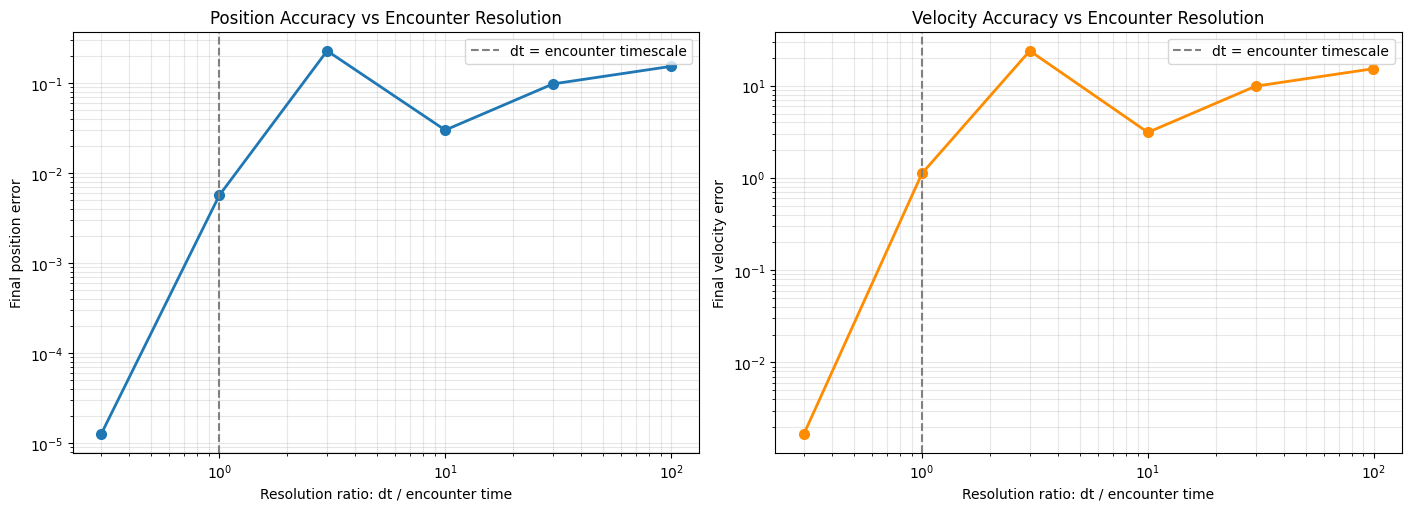

In [77]:

eta_array = np.array([
    result["eta"]
    for result in resolution_results
])

position_errors = np.array([
    result["position_error"]
    for result in resolution_results
])

velocity_errors = np.array([
    result["velocity_error"]
    for result in resolution_results
])

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    constrained_layout=True
)

axes[0].loglog(
    eta_array,
    position_errors,
    "o-",
    linewidth=2,
    markersize=7
)

axes[0].set_xlabel("Resolution ratio: dt / encounter time")
axes[0].set_ylabel("Final position error")
axes[0].set_title("Position Accuracy vs Encounter Resolution")

axes[1].loglog(
    eta_array,
    velocity_errors,
    "o-",
    linewidth=2,
    markersize=7,
    color="darkorange"
)

axes[1].set_xlabel("Resolution ratio: dt / encounter time")
axes[1].set_ylabel("Final velocity error")
axes[1].set_title("Velocity Accuracy vs Encounter Resolution")

for ax in axes:
    ax.axvline(
        1.0,
        linestyle="--",
        color="gray",
        label="dt = encounter timescale"
    )
    ax.grid(alpha=0.3, which="both")
    ax.legend()

plt.show()



In [78]:

# Sort results from smallest to largest eta
ordered = sorted(
    resolution_results,
    key=lambda result: result["eta"]
)

print("OBSERVED CONVERGENCE ORDERS")
print("-" * 70)

for i in range(len(ordered) - 1):

    a = ordered[i]
    b = ordered[i + 1]

    eta1, eta2 = a["eta"], b["eta"]

    e1 = a["position_error"]
    e2 = b["position_error"]

    # Only calculate slopes for positive, finite errors.
    if (
        np.isfinite(e1)
        and np.isfinite(e2)
        and e1 > 0
        and e2 > 0
    ):
        slope = (
            np.log(e2 / e1)
            / np.log(eta2 / eta1)
        )

        print(
            f"eta {eta1:.4f} -> {eta2:.4f} | "
            f"Position-error slope = {slope:.3f}"
        )

    else:
        print(
            f"eta {eta1:.4f} -> {eta2:.4f} | "
            "Slope unavailable"
        )


OBSERVED CONVERGENCE ORDERS
----------------------------------------------------------------------
eta 0.3000 -> 0.9999 | Position-error slope = 5.069
eta 0.9999 -> 2.9996 | Position-error slope = 3.363
eta 2.9996 -> 9.9988 | Position-error slope = -1.684
eta 9.9988 -> 29.9964 | Position-error slope = 1.075
eta 29.9964 -> 99.4165 | Position-error slope = 0.373



## 9.4 Identifying the numerical convergence regime

Our first experiment revealed two different behaviors.

At large encounter-resolution ratios, the RK4 errors fluctuate irregularly.

At smaller ratios, reducing the timestep produces a much sharper improvement in accuracy.

We now want to determine whether this improvement approaches the theoretical fourth-order convergence of RK4.

To do this, we will investigate:

$$
\eta=0.3,\ 0.2,\ 0.15,\ 0.1
$$

We will keep the physical initial state, encounter window, reference solution, and integration algorithm unchanged.

Only the timestep will vary.

If the measured convergence slope approaches 4 over progressively finer resolutions, that supports the expected RK4 error scaling.

Because the encounter is extremely short, even these small ratios require many integration steps.


In [79]:

# Fine-resolution RK4 convergence experiment

fine_eta_values = [0.3, 0.2, 0.15, 0.1]

fine_results = []

window_duration = t_end - t_start

for eta_target in fine_eta_values:

    desired_dt = eta_target * t_enc

    n_steps = int(np.ceil(
        window_duration / desired_dt
    ))

    actual_dt = window_duration / n_steps
    actual_eta = actual_dt / t_enc

    # Start each run from identical reference conditions
    r = r_start.copy()
    v = v_start.copy()

    for _ in range(n_steps):

        r, v = rk4_step(
            r, v, candidate_m, actual_dt
        )

    # Test-particle state relative to star
    q = r[2] - r[0]
    u = v[2] - v[0]

    pos_error = np.linalg.norm(q - q_ref)
    vel_error = np.linalg.norm(u - u_ref)

    fine_results.append({
        "eta": actual_eta,
        "steps": n_steps,
        "position_error": pos_error,
        "velocity_error": vel_error
    })

    print(
        f"eta = {actual_eta:.5f} | "
        f"steps = {n_steps:,} | "
        f"position error = {pos_error:.6e} | "
        f"velocity error = {vel_error:.6e}"
    )


eta = 0.29999 | steps = 23,198 | position error = 1.268238e-05 | velocity error = 1.679349e-03
eta = 0.20000 | steps = 34,796 | position error = 1.712937e-06 | velocity error = 2.254748e-04
eta = 0.15000 | steps = 46,395 | position error = 4.129095e-07 | velocity error = 5.401786e-05
eta = 0.10000 | steps = 69,592 | position error = 5.581481e-08 | velocity error = 7.202498e-06


FINE-RESOLUTION CONVERGENCE
--------------------------------------------------
Position error slope: 4.9394
Velocity error slope: 4.9628
Theoretical RK4 order: 4


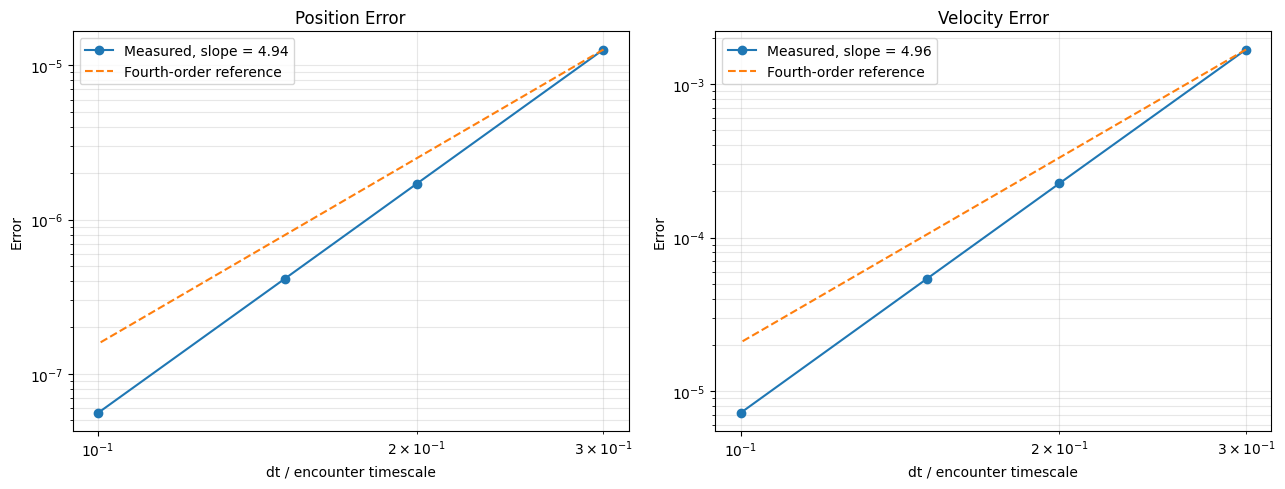

In [80]:

fine_eta = np.array([
    result["eta"]
    for result in fine_results
])

fine_pos_error = np.array([
    result["position_error"]
    for result in fine_results
])

fine_vel_error = np.array([
    result["velocity_error"]
    for result in fine_results
])

# Fit logarithmic error scaling
position_slope = np.polyfit(
    np.log(fine_eta),
    np.log(fine_pos_error),
    1
)[0]

velocity_slope = np.polyfit(
    np.log(fine_eta),
    np.log(fine_vel_error),
    1
)[0]

print("FINE-RESOLUTION CONVERGENCE")
print("-" * 50)
print(f"Position error slope: {position_slope:.4f}")
print(f"Velocity error slope: {velocity_slope:.4f}")
print("Theoretical RK4 order: 4")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, errors, slope, title in [
    (axes[0], fine_pos_error, position_slope, "Position Error"),
    (axes[1], fine_vel_error, velocity_slope, "Velocity Error")
]:

    ax.loglog(
        fine_eta,
        errors,
        "o-",
        label=f"Measured, slope = {slope:.2f}"
    )

    # Fourth-order reference line, anchored to
    # the smallest timestep's measured error.
    order4 = errors[0] * (
        fine_eta / fine_eta[0]
    )**4

    ax.loglog(
        fine_eta,
        order4,
        "--",
        label="Fourth-order reference"
    )

    ax.set_xlabel("dt / encounter timescale")
    ax.set_ylabel("Error")
    ax.set_title(title)
    ax.grid(alpha=0.3, which="both")
    ax.legend()

plt.tight_layout()
plt.show()



## 9.5 Verifying fourth-order convergence

Our fine-resolution experiments produced measured error slopes near 5.

However, RK4 is a fourth-order method.

A slope above 4 over a small collection of timesteps does not imply that the numerical method has changed order.

To investigate this, we will extend the experiment to smaller timestep ratios and estimate the convergence order between successive resolutions.

Our theoretical expectation is:

$$
\epsilon(\Delta t)\approx C(\Delta t)^4
$$

once we enter the asymptotic convergence regime and before reference error or floating-point roundoff becomes dominant.

We will use the same initial state, encounter window, and adaptive reference.

The goal is to find whether the measured slopes approach 4 as the timestep becomes smaller.


In [81]:

# Extend the convergence experiment to smaller eta values.

extra_eta_values = [0.075, 0.05, 0.035, 0.025]

extra_results = []

window_duration = t_end - t_start

for eta_target in extra_eta_values:

    desired_dt = eta_target * t_enc

    n_steps = int(np.ceil(
        window_duration / desired_dt
    ))

    actual_dt = window_duration / n_steps
    actual_eta = actual_dt / t_enc

    r = r_start.copy()
    v = v_start.copy()

    for _ in range(n_steps):
        r, v = rk4_step(
            r, v, candidate_m, actual_dt
        )

    q = r[2] - r[0]
    u = v[2] - v[0]

    pos_error = np.linalg.norm(q - q_ref)
    vel_error = np.linalg.norm(u - u_ref)

    extra_results.append({
        "eta": actual_eta,
        "steps": n_steps,
        "position_error": pos_error,
        "velocity_error": vel_error
    })

    print(
        f"eta={actual_eta:.5f} | "
        f"steps={n_steps:,} | "
        f"position error={pos_error:.8e} | "
        f"velocity error={vel_error:.8e}"
    )


eta=0.07500 | steps=92,789 | position error=1.35905949e-08 | velocity error=1.72697475e-06
eta=0.05000 | steps=139,184 | position error=1.89565246e-09 | velocity error=2.32749626e-07
eta=0.03500 | steps=198,834 | position error=3.39512741e-10 | velocity error=3.95819984e-08
eta=0.02500 | steps=278,367 | position error=7.06296622e-11 | velocity error=7.69404746e-09


In [82]:

# Combine previous and new convergence results.
all_fine_results = fine_results + extra_results

# Sort by eta (finest resolution first).
all_fine_results = sorted(
    all_fine_results,
    key=lambda x: x["eta"]
)

print("LOCAL RK4 CONVERGENCE ORDERS")
print("-" * 76)

for i in range(len(all_fine_results) - 1):

    fine = all_fine_results[i]
    coarse = all_fine_results[i + 1]

    eta_fine = fine["eta"]
    eta_coarse = coarse["eta"]

    ep_fine = fine["position_error"]
    ep_coarse = coarse["position_error"]

    ev_fine = fine["velocity_error"]
    ev_coarse = coarse["velocity_error"]

    p_position = (
        np.log(ep_coarse / ep_fine)
        / np.log(eta_coarse / eta_fine)
    )

    p_velocity = (
        np.log(ev_coarse / ev_fine)
        / np.log(eta_coarse / eta_fine)
    )

    print(
        f"{eta_fine:.5f} → {eta_coarse:.5f} | "
        f"position order={p_position:.3f} | "
        f"velocity order={p_velocity:.3f}"
    )


LOCAL RK4 CONVERGENCE ORDERS
----------------------------------------------------------------------------
0.02500 → 0.03500 | position order=4.666 | velocity order=4.868
0.03500 → 0.05000 | position order=4.822 | velocity order=4.967
0.05000 → 0.07500 | position order=4.858 | velocity order=4.943
0.07500 → 0.10000 | position order=4.911 | velocity order=4.964
0.10000 → 0.15000 | position order=4.936 | velocity order=4.969
0.15000 → 0.20000 | position order=4.945 | velocity order=4.967
0.20000 → 0.29999 | position order=4.938 | velocity order=4.953



## 9.7 Independent verification through timestep refinement

Our encounter-resolution experiment produced observed RK4 convergence orders close to 5.

We now want to verify whether this behavior persists independently of the adaptive reference solution.

Instead of comparing RK4 against DOP853, we will compare RK4 solutions at different timestep sizes.

For example:

- Solution A uses timestep $h$.
- Solution B uses timestep $h/2$.
- Solution C uses timestep $h/4$.

We define:

$$
D(h)=\|X_h-X_{h/2}\|
$$

If the leading error behaves as $Ch^p$, then:

$$
\frac{D(h)}{D(h/2)}\approx2^p
$$

Therefore, the observed order is:

$$
p_{\mathrm{observed}}=
\log_2\left(\frac{D(h)}{D(h/2)}\right)
$$

For ordinary fourth-order convergence, we expect approximately $p=4$.

The comparison must use the same initial conditions and final physical time.


In [83]:

import numpy as np
import matplotlib.pyplot as plt

# Four successively refined integrations.
# Chosen so each run has exactly twice as many
# timesteps as the previous one.

base_steps = 250
step_counts = [
    base_steps,
    2 * base_steps,
    4 * base_steps,
    8 * base_steps
]

duration = t_end - t_start

self_convergence = []

for n_steps in step_counts:

    dt = duration / n_steps

    r = r_start.copy()
    v = v_start.copy()

    for _ in range(n_steps):
        r, v = rk4_step(
            r, v, candidate_m, dt
        )

    # Test particle relative to the star.
    q = r[2] - r[0]
    u = v[2] - v[0]

    self_convergence.append({
        "dt": dt,
        "eta": dt / t_enc,
        "position": q.copy(),
        "velocity": u.copy()
    })

    print(
        f"steps={n_steps:5d} | "
        f"dt={dt:.6e} | "
        f"eta={dt/t_enc:.4f}"
    )


# Differences between successive resolutions.
position_differences = []
velocity_differences = []

for i in range(len(self_convergence) - 1):

    coarse = self_convergence[i]
    fine = self_convergence[i + 1]

    dp = np.linalg.norm(
        coarse["position"] - fine["position"]
    )

    dv = np.linalg.norm(
        coarse["velocity"] - fine["velocity"]
    )

    position_differences.append(dp)
    velocity_differences.append(dv)


print("\nSELF-CONVERGENCE RESULTS")
print("-" * 55)

for i in range(len(position_differences) - 1):

    p_position = np.log2(
        position_differences[i]
        / position_differences[i + 1]
    )

    p_velocity = np.log2(
        velocity_differences[i]
        / velocity_differences[i + 1]
    )

    print(
        f"Refinement {i+1} -> {i+2} | "
        f"Position order: {p_position:.4f} | "
        f"Velocity order: {p_velocity:.4f}"
    )


steps=  250 | dt=8.000000e-05 | eta=27.8366
steps=  500 | dt=4.000000e-05 | eta=13.9183
steps= 1000 | dt=2.000000e-05 | eta=6.9592
steps= 2000 | dt=1.000000e-05 | eta=3.4796

SELF-CONVERGENCE RESULTS
-------------------------------------------------------
Refinement 1 -> 2 | Position order: 0.1488 | Velocity order: 0.0674
Refinement 2 -> 3 | Position order: -5.9375 | Velocity order: -5.9021



## 9.8 Self-convergence within the resolved encounter regime

Our first self-convergence experiment produced irregular and negative convergence orders.

This happened because the tested timesteps were still larger than the characteristic encounter timescale.

Our earlier RK4 experiments showed much more systematic error reduction when:

$$
\eta=\frac{\Delta t}{t_{\mathrm{enc}}}\leq0.3
$$

We will repeat the self-convergence experiment using substantially finer timesteps.

This time, each refinement will halve the timestep while keeping the initial conditions and final physical time unchanged.

We expect the measured orders to become more stable as the numerical solutions approach a common trajectory.

The theoretical asymptotic convergence order of RK4 is 4.


In [84]:

import numpy as np

# Choose a starting resolution near eta = 0.2.
window_duration = t_end - t_start

target_eta = 0.2

base_steps = int(np.ceil(
    window_duration / (target_eta * t_enc)
))

# Each successive run uses twice as many steps.
step_counts = [
    base_steps,
    2 * base_steps,
    4 * base_steps,
    8 * base_steps
]

self_convergence = []

for n_steps in step_counts:

    dt = window_duration / n_steps

    r = r_start.copy()
    v = v_start.copy()

    for _ in range(n_steps):

        r, v = rk4_step(
            r, v, candidate_m, dt
        )

    q = r[2] - r[0]
    u = v[2] - v[0]

    self_convergence.append({
        "dt": dt,
        "eta": dt / t_enc,
        "position": q.copy(),
        "velocity": u.copy()
    })

    print(
        f"steps={n_steps:7d} | "
        f"dt={dt:.8e} | "
        f"eta={dt/t_enc:.5f}"
    )


# Differences between successive refinements
position_differences = []
velocity_differences = []

for i in range(len(self_convergence) - 1):

    coarse = self_convergence[i]
    fine = self_convergence[i + 1]

    position_differences.append(
        np.linalg.norm(
            coarse["position"] - fine["position"]
        )
    )

    velocity_differences.append(
        np.linalg.norm(
            coarse["velocity"] - fine["velocity"]
        )
    )


print("\nCORRECTED SELF-CONVERGENCE")
print("-" * 65)

for i in range(len(position_differences) - 1):

    p_position = np.log2(
        position_differences[i]
        / position_differences[i + 1]
    )

    p_velocity = np.log2(
        velocity_differences[i]
        / velocity_differences[i + 1]
    )

    print(
        f"Refinement {i+1} -> {i+2} | "
        f"Position order = {p_position:.4f} | "
        f"Velocity order = {p_velocity:.4f}"
    )


steps=  34796 | dt=5.74778710e-07 | eta=0.20000
steps=  69592 | dt=2.87389355e-07 | eta=0.10000
steps= 139184 | dt=1.43694678e-07 | eta=0.05000
steps= 278368 | dt=7.18473388e-08 | eta=0.02500

CORRECTED SELF-CONVERGENCE
-----------------------------------------------------------------
Refinement 1 -> 2 | Position order = 4.9413 | Velocity order = 4.9687
Refinement 2 -> 3 | Position order = 4.8860 | Velocity order = 4.9549



## 9.9 Is the apparent fifth-order convergence an endpoint effect?

Our self-convergence experiment produced observed convergence orders close to 5, even though RK4 is formally fourth-order.

We will now measure numerical convergence at several times throughout the encounter window.

This helps distinguish between two possibilities:

- The integration exhibits approximately fifth-order endpoint-error scaling throughout the tested interval.
- The final observation time happens to suppress part of the leading numerical error.

For each timestep, we will record the complete position and velocity state at 25%, 50%, 75%, and 100% of the encounter window.

We will then estimate convergence orders independently at each observation time.

The purpose is to understand the numerical method's behavior, not to claim that RK4 has changed its mathematical order.


CONVERGENCE THROUGHOUT THE ENCOUNTER
-------------------------------------------------------
Window fraction = 0.25 | Observed order = 0.2736
Window fraction = 0.50 | Observed order = 3.8878
Window fraction = 0.75 | Observed order = 4.9501
Window fraction = 1.00 | Observed order = 4.9687


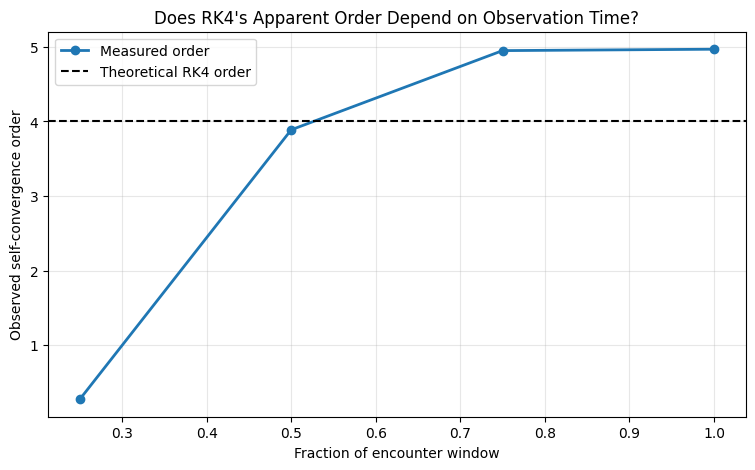

In [85]:

import numpy as np
import matplotlib.pyplot as plt

# Use three resolutions to calculate one
# self-convergence order at each observation time.

base_steps = int(np.ceil(
    (t_end - t_start) / (0.2 * t_enc)
))

step_counts = [
    base_steps,
    2 * base_steps,
    4 * base_steps
]

fractions = [0.25, 0.50, 0.75, 1.00]

trajectories = []

for n_steps in step_counts:

    dt = (t_end - t_start) / n_steps

    r = r_start.copy()
    v = v_start.copy()

    # Save at identical fractions of the time window.
    sample_steps = [
        int(round(f * n_steps))
        for f in fractions
    ]

    recorded = {}

    for step in range(1, n_steps + 1):

        r, v = rk4_step(
            r, v, candidate_m, dt
        )

        if step in sample_steps:
            recorded[step] = np.concatenate([
                r.ravel(),
                v.ravel()
            ])

    trajectories.append(
        np.array([
            recorded[s]
            for s in sample_steps
        ])
    )

# Compare successive integrations.
# Use the complete position and velocity state.

d_coarse = np.linalg.norm(
    trajectories[0] - trajectories[1],
    axis=1
)

d_fine = np.linalg.norm(
    trajectories[1] - trajectories[2],
    axis=1
)

orders = np.log2(d_coarse / d_fine)

print("CONVERGENCE THROUGHOUT THE ENCOUNTER")
print("-" * 55)

for fraction, order in zip(fractions, orders):
    print(
        f"Window fraction = {fraction:.2f} | "
        f"Observed order = {order:.4f}"
    )

plt.figure(figsize=(9, 5))

plt.plot(
    fractions,
    orders,
    "o-",
    linewidth=2,
    label="Measured order"
)

plt.axhline(
    4,
    color="black",
    linestyle="--",
    label="Theoretical RK4 order"
)

plt.xlabel("Fraction of encounter window")
plt.ylabel("Observed self-convergence order")
plt.title("Does RK4's Apparent Order Depend on Observation Time?")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



## 9.10 Investigating the apparent fifth-order convergence

Our simulations produced different observed convergence orders at different stages of the gravitational encounter.

Before interpreting this pattern, we must determine whether the results are influenced by very small numerical differences.

We will separately examine:

- Position convergence
- Velocity convergence
- Absolute differences between successive resolutions

We will use the existing simulation results, so no new orbital integrations are required.

This analysis will help determine whether the near-fifth-order behavior is a reproducible numerical feature or an artifact of the error measurement.


DETAILED CONVERGENCE ANALYSIS

Window fraction: 0.25
Position difference (coarse-medium): 2.29722889e-15
Position difference (medium-fine):   4.93942243e-15
Observed position order:            -1.1044
Velocity difference (coarse-medium): 1.23482307e-13
Velocity difference (medium-fine):   1.02051541e-13
Observed velocity order:            0.2750

Window fraction: 0.50
Position difference (coarse-medium): 8.36789647e-11
Position difference (medium-fine):   5.37130846e-12
Observed position order:            3.9615
Velocity difference (coarse-medium): 4.30812169e-05
Velocity difference (medium-fine):   2.91028432e-06
Observed velocity order:            3.8878

Window fraction: 0.75
Position difference (coarse-medium): 6.77869334e-07
Position difference (medium-fine):   2.27616150e-08
Observed position order:            4.8963
Velocity difference (coarse-medium): 1.74718686e-04
Velocity difference (medium-fine):   5.65207053e-06
Observed velocity order:            4.9501

Window fraction: 

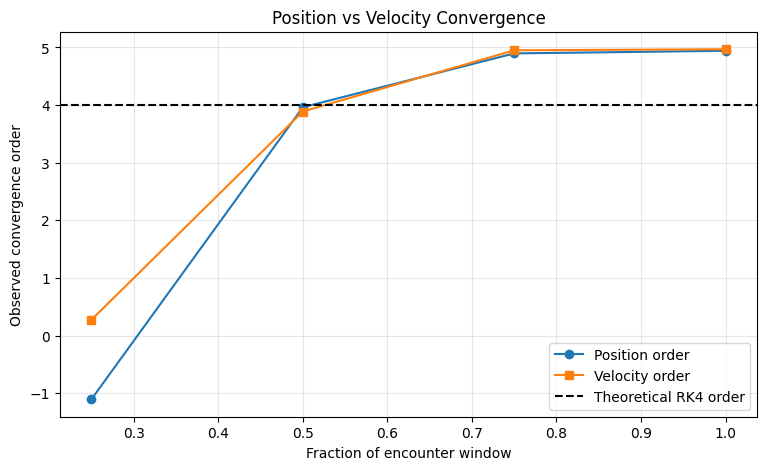

In [86]:

import numpy as np
import matplotlib.pyplot as plt

fractions = np.array([0.25, 0.50, 0.75, 1.00])

# Each state contains:
# 6 position values + 6 velocity values

coarse = trajectories[0]
medium = trajectories[1]
fine = trajectories[2]

# Separate positions and velocities.
pos_coarse = coarse[:, :6]
pos_medium = medium[:, :6]
pos_fine = fine[:, :6]

vel_coarse = coarse[:, 6:]
vel_medium = medium[:, 6:]
vel_fine = fine[:, 6:]

# Differences between consecutive resolutions.
dp1 = np.linalg.norm(
    pos_coarse - pos_medium, axis=1
)

dp2 = np.linalg.norm(
    pos_medium - pos_fine, axis=1
)

dv1 = np.linalg.norm(
    vel_coarse - vel_medium, axis=1
)

dv2 = np.linalg.norm(
    vel_medium - vel_fine, axis=1
)

# Calculate observed orders.
with np.errstate(divide="ignore", invalid="ignore"):
    p_position = np.log2(dp1 / dp2)
    p_velocity = np.log2(dv1 / dv2)

print("DETAILED CONVERGENCE ANALYSIS")
print("=" * 82)

for i, fraction in enumerate(fractions):

    print(f"\nWindow fraction: {fraction:.2f}")

    print(f"Position difference (coarse-medium): {dp1[i]:.8e}")
    print(f"Position difference (medium-fine):   {dp2[i]:.8e}")
    print(f"Observed position order:            {p_position[i]:.4f}")

    print(f"Velocity difference (coarse-medium): {dv1[i]:.8e}")
    print(f"Velocity difference (medium-fine):   {dv2[i]:.8e}")
    print(f"Observed velocity order:            {p_velocity[i]:.4f}")


fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    fractions, p_position,
    "o-", label="Position order"
)

ax.plot(
    fractions, p_velocity,
    "s-", label="Velocity order"
)

ax.axhline(
    4, color="black",
    linestyle="--",
    label="Theoretical RK4 order"
)

ax.set_xlabel("Fraction of encounter window")
ax.set_ylabel("Observed convergence order")
ax.set_title("Position vs Velocity Convergence")

ax.legend()
ax.grid(alpha=0.3)

plt.show()



# Objective 10 — Numerical Contamination of Chaos Indicators

## 10.1 From inaccurate trajectories to inaccurate chaos measurements

In our previous experiments, we discovered that a gravitational close encounter can cause severe numerical errors.

Three fixed-step RK4 simulations predicted dramatically different outgoing trajectories, even though they started from the same physical conditions.

The adaptive DOP853 integrator resolved the encounter much more consistently.

Now we want to understand whether an inaccurate numerical trajectory also produces an inaccurate measurement of dynamical sensitivity.

### Two types of numerical quantities

The first is the ordinary gravitational trajectory:

$$
X(t)=(\mathbf r(t),\mathbf v(t))
$$

The second is an infinitesimal perturbation:

$$
\delta X(t)=(\delta\mathbf r(t),\delta\mathbf v(t))
$$

The perturbation tells us how the physical system responds to a tiny change in its initial conditions.

To investigate sensitivity, we measure how the perturbation grows.

We will integrate both the trajectory and its variational equations using:

1. Adaptive DOP853 as our refined reference.
2. Fixed-step RK4 at several numerical resolutions.

Every calculation begins from the same pre-encounter physical state and tangent vector.

### An important scientific distinction

A close encounter can amplify perturbations without establishing long-term chaos.

Therefore, our initial quantity is the finite-time logarithmic amplification rate:

$$
\Lambda_{\mathrm{window}}
=
\frac{1}{T}
\ln\left(
\frac{\|\delta X(T)\|}{\|\delta X(0)\|}
\right)
$$

where $T$ is the length of the encounter window.

This quantity measures average infinitesimal perturbation growth during one finite interval. It is not, by itself, a proof of chaotic motion.

Our research question is whether different numerical resolutions produce consistent estimates of this quantity.


In [87]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Uses existing variables from Objective 09:
# solutions, t_start, t_end, candidate_m, t_enc
# gravitational_accelerations, variational_accelerations
# variational_rk4_step

N = len(candidate_m)
DIM = 2

# Extract the refined physical state before encounter.
physical_initial_state = solutions["Refined"].sol(t_start)

r0 = physical_initial_state[:N*DIM].reshape(N, DIM).copy()
v0 = physical_initial_state[N*DIM:].reshape(N, DIM).copy()

# Initial infinitesimal perturbation direction.
# Change the test particle's x-position only.
dr0 = np.zeros_like(r0)
dv0 = np.zeros_like(v0)

dr0[2, 0] = 1.0

# Characteristic time used to combine
# position and velocity perturbations.
T_scale = 1.0

def full_tangent_norm(dr, dv):
    return np.sqrt(
        np.sum(dr**2)
        + (T_scale**2) * np.sum(dv**2)
    )

# Normalize the initial tangent vector.
initial_norm = full_tangent_norm(dr0, dv0)

dr0 = dr0 / initial_norm
dv0 = dv0 / initial_norm

print("Initial tangent norm:",
      full_tangent_norm(dr0, dv0))

print("Encounter window:", t_start, "to", t_end)
print("Duration:", t_end - t_start)


Initial tangent norm: 1.0
Encounter window: 55.07075180995478 to 55.090751809954774
Duration: 0.01999999999999602


In [88]:

def combined_rhs(t, y, masses):
    """
    Evolve physical positions/velocities and
    their first-order variational perturbations.

    State layout:
    [positions, velocities, delta_positions, delta_velocities]
    """

    n = len(masses)
    block = n * 2

    r = y[0:block].reshape(n, 2)
    v = y[block:2*block].reshape(n, 2)

    dr = y[2*block:3*block].reshape(n, 2)
    dv = y[3*block:4*block].reshape(n, 2)

    # Physical gravitational acceleration
    a = gravitational_accelerations(r, masses)

    # Linearized response to position perturbations
    da = variational_accelerations(r, dr, masses)

    return np.concatenate([
        v.ravel(),
        a.ravel(),
        dv.ravel(),
        da.ravel()
    ])


# Pack the initial complete state.
Y0 = np.concatenate([
    r0.ravel(),
    v0.ravel(),
    dr0.ravel(),
    dv0.ravel()
])

assert Y0.shape == (24,)

print("Number of state variables:", Y0.size)


Number of state variables: 24


In [89]:

def run_combined_adaptive(rtol, atol, max_step):
    return solve_ivp(
        combined_rhs,
        (t_start, t_end),
        Y0,
        args=(candidate_m,),
        method="DOP853",
        rtol=rtol,
        atol=atol,
        max_step=max_step,
        dense_output=True
    )


tangent_reference = run_combined_adaptive(
    rtol=1e-10,
    atol=1e-12,
    max_step=0.001
)

tangent_refined = run_combined_adaptive(
    rtol=1e-12,
    atol=1e-14,
    max_step=0.0001
)

for name, sol in [
    ("Reference", tangent_reference),
    ("Refined", tangent_refined)
]:
    if not sol.success:
        raise RuntimeError(
            f"{name} failed: {sol.message}"
        )

    print(
        f"{name}: {len(sol.t)-1} accepted steps"
    )

print("Both integrations completed.")


Reference: 150 accepted steps
Refined: 373 accepted steps
Both integrations completed.


In [90]:

def unpack_combined_state(y, n=3):
    """
    Unpack one combined state into four (N, 2) arrays.
    """
    block = 2 * n

    r = y[:block].reshape(n, 2)
    v = y[block:2*block].reshape(n, 2)
    dr = y[2*block:3*block].reshape(n, 2)
    dv = y[3*block:4*block].reshape(n, 2)

    return r, v, dr, dv


def tangent_amplification(y):
    _, _, dr, dv = unpack_combined_state(
        y, len(candidate_m)
    )
    return full_tangent_norm(dr, dv)


duration = t_end - t_start

Y_reference_end = tangent_reference.y[:, -1]
Y_refined_end = tangent_refined.y[:, -1]

growth_reference = tangent_amplification(
    Y_reference_end
)

growth_refined = tangent_amplification(
    Y_refined_end
)

log_growth_reference = np.log(growth_reference)
log_growth_refined = np.log(growth_refined)

rate_reference = log_growth_reference / duration
rate_refined = log_growth_refined / duration

print("ADAPTIVE TANGENT REFERENCE")
print("-" * 55)

print("Reference amplification:", growth_reference)
print("Refined amplification:", growth_refined)

print("Reference log growth:", log_growth_reference)
print("Refined log growth:", log_growth_refined)

print("Reference finite-time rate:", rate_reference)
print("Refined finite-time rate:", rate_refined)

print(
    "Absolute rate disagreement:",
    abs(rate_reference - rate_refined)
)

# Compare complete final states, not just scalar norms.
relative_state_disagreement = np.linalg.norm(
    Y_reference_end - Y_refined_end
) / max(np.linalg.norm(Y_refined_end), 1e-30)

print(
    "Relative full-state disagreement:",
    relative_state_disagreement
)


ADAPTIVE TANGENT REFERENCE
-------------------------------------------------------
Reference amplification: 106.63346243469537
Refined amplification: 106.63325822008409
Reference log growth: 4.669397368990244
Refined log growth: 4.669395453880275
Reference finite-time rate: 233.46986844955865
Refined finite-time rate: 233.46977269406023
Absolute rate disagreement: 9.575549842111286e-05
Relative full-state disagreement: 5.061455992126428e-06



## 10.2 Understanding the perturbation amplification rate

At the beginning of our encounter window, we chose an infinitesimal perturbation with normalized magnitude 1.

As the gravitational system evolves, the perturbation may grow or shrink.

Suppose the final magnitude is 10.

This means the linearized equations predict tenfold amplification of the original infinitesimal disturbance.

We can describe this using:

$$
A(T)=\frac{\|\delta X(T)\|}{\|\delta X(0)\|}
$$

The logarithmic amplification is:

$$
g(T)=\ln A(T)
$$

The finite-time amplification rate is:

$$
\Lambda(T)=\frac{g(T)}{T}
$$

This is related to the idea of Lyapunov exponents, but there is an important distinction.

Our experiment follows one selected tangent direction through one short gravitational encounter.

The maximal Lyapunov exponent concerns long-time exponential growth and requires additional asymptotic analysis.

For now, we are studying how accurately a numerical integrator predicts finite-time perturbation growth.

That is already a scientifically meaningful question.


In [91]:

eta_tests = [100, 30, 10, 3, 1, 0.3, 0.1, 0.05]

tangent_resolution_results = []

for eta_target in eta_tests:

    desired_dt = eta_target * t_enc

    n_steps = max(
        1,
        int(np.ceil(duration / desired_dt))
    )

    dt_actual = duration / n_steps
    eta_actual = dt_actual / t_enc

    r = r0.copy()
    v = v0.copy()
    dr = dr0.copy()
    dv = dv0.copy()

    failed = False

    try:
        for _ in range(n_steps):

            r, v, dr, dv = variational_rk4_step(
                r, v, dr, dv,
                candidate_m, dt_actual
            )

            if not all(
                np.all(np.isfinite(x))
                for x in (r, v, dr, dv)
            ):
                failed = True
                break

    except (FloatingPointError, ValueError,
            OverflowError, ZeroDivisionError):
        failed = True

    if failed:
        growth = np.nan
        growth_log = np.nan
        rate = np.nan
        error_rate = np.nan
        tangent_vector_error = np.nan
    else:
        growth = full_tangent_norm(dr, dv)

        growth_log = (
            np.log(growth)
            if growth > 0 else np.nan
        )

        rate = growth_log / duration

        error_rate = abs(rate - rate_refined)

        # Compare the full final tangent vector.
        _, _, dr_ref, dv_ref = unpack_combined_state(
            Y_refined_end, len(candidate_m)
        )

        tangent_vector_error = np.sqrt(
            np.sum((dr - dr_ref)**2)
            + T_scale**2 * np.sum((dv - dv_ref)**2)
        )

    tangent_resolution_results.append({
        "eta": eta_actual,
        "steps": n_steps,
        "growth": growth,
        "log_growth": growth_log,
        "rate": rate,
        "rate_error": error_rate,
        "tangent_vector_error": tangent_vector_error
    })

    print(
        f"eta={eta_actual:8.4f} | "
        f"steps={n_steps:7d} | "
        f"rate={rate: .6e} | "
        f"rate error={error_rate:.6e}"
    )


eta= 99.4165 | steps=     70 | rate= 6.477816e+02 | rate error=4.143119e+02
eta= 29.9964 | steps=    232 | rate= 6.724527e+02 | rate error=4.389829e+02
eta=  9.9988 | steps=    696 | rate= 7.052154e+02 | rate error=4.717457e+02
eta=  2.9996 | steps=   2320 | rate= 1.437386e+03 | rate error=1.203916e+03
eta=  0.9999 | steps=   6960 | rate= 6.604709e+02 | rate error=4.270012e+02
eta=  0.3000 | steps=  23198 | rate= 2.474929e+02 | rate error=1.402317e+01
eta=  0.1000 | steps=  69592 | rate= 2.335212e+02 | rate error=5.147003e-02
eta=  0.0500 | steps= 139184 | rate= 2.334716e+02 | rate error=1.874314e-03


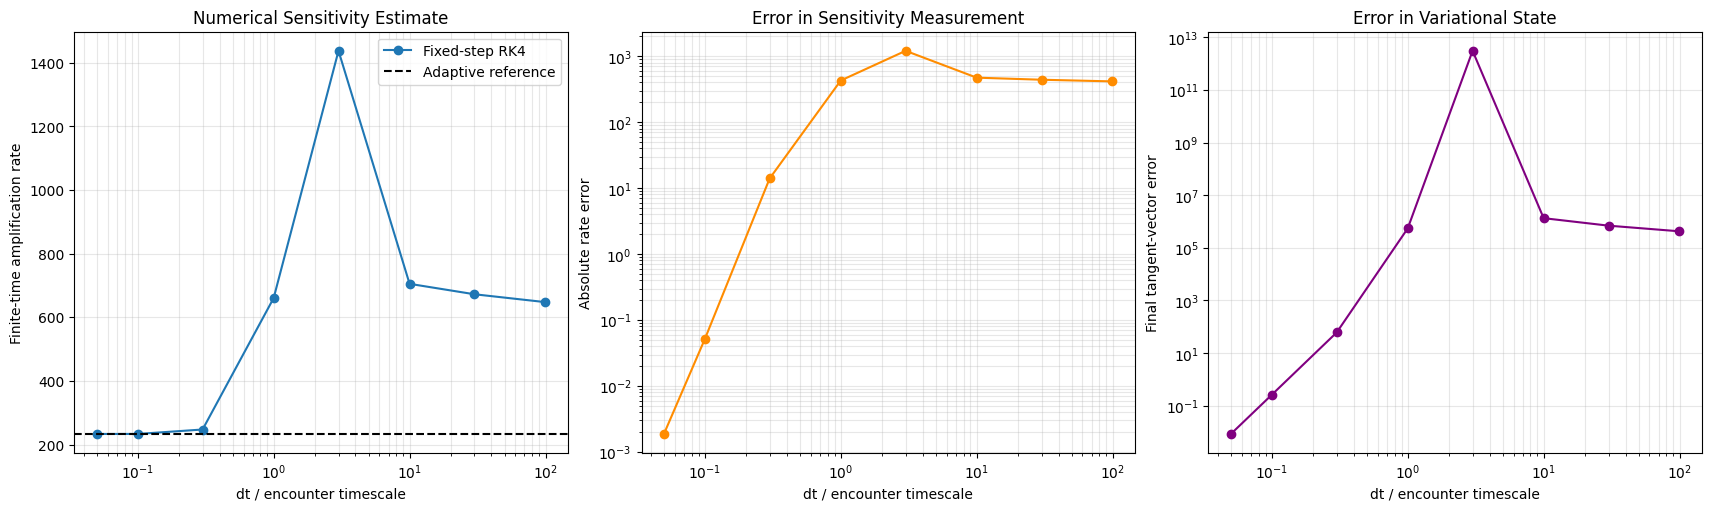

In [92]:

eta_arr = np.array([
    item["eta"]
    for item in tangent_resolution_results
])

rate_arr = np.array([
    item["rate"]
    for item in tangent_resolution_results
])

rate_errors = np.array([
    item["rate_error"]
    for item in tangent_resolution_results
])

vector_errors = np.array([
    item["tangent_vector_error"]
    for item in tangent_resolution_results
])

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    constrained_layout=True
)

# Finite-time amplification rate
axes[0].semilogx(
    eta_arr, rate_arr, "o-",
    label="Fixed-step RK4"
)

axes[0].axhline(
    rate_refined,
    color="black",
    linestyle="--",
    label="Adaptive reference"
)

axes[0].set_xlabel("dt / encounter timescale")
axes[0].set_ylabel("Finite-time amplification rate")
axes[0].set_title("Numerical Sensitivity Estimate")
axes[0].legend()

# Error in the inferred rate
axes[1].loglog(
    eta_arr,
    rate_errors,
    "o-",
    color="darkorange"
)

axes[1].set_xlabel("dt / encounter timescale")
axes[1].set_ylabel("Absolute rate error")
axes[1].set_title("Error in Sensitivity Measurement")

# Difference in complete final tangent vector
axes[2].loglog(
    eta_arr,
    vector_errors,
    "o-",
    color="purple"
)

axes[2].set_xlabel("dt / encounter timescale")
axes[2].set_ylabel("Final tangent-vector error")
axes[2].set_title("Error in Variational State")

for ax in axes:
    ax.grid(alpha=0.3, which="both")

plt.show()




## 10.3 When does numerical error contaminate a chaos indicator?

Our experiment compares the evolution of the same infinitesimal perturbation using several timestep sizes.

All simulations use identical initial physical conditions and the same initial tangent vector.

The only difference is numerical resolution.

If the fixed-step results approach the adaptive reference as the timestep decreases, the inferred perturbation amplification is becoming more reliable.

If coarse timesteps produce dramatically different values, the integration method is contaminating the measurement of dynamical sensitivity.

We must distinguish three claims:

**Claim 1: Numerical trajectory error**

The integrator calculates an inaccurate gravitational trajectory.

**Claim 2: Numerical sensitivity error**

The integrator calculates an inaccurate amplification of infinitesimal perturbations.

**Claim 3: Spurious chaos classification**

The integrator incorrectly classifies the underlying physical dynamics as chaotic.

The first two can be investigated directly in our short encounter experiment.

The third requires a robust, longer-time dynamical classification, including numerical convergence and comparison against regular and chaotic benchmark systems.

An extremely strong but brief gravitational encounter may cause large finite-time amplification without proving sustained chaos.



## 10.4 Convergence of finite-time perturbation amplification

Our coarse-resolution experiments demonstrated that numerical errors can severely distort the amplification of infinitesimal perturbations.

We now investigate whether the sensitivity measurement converges as the timestep becomes smaller than the characteristic encounter timescale.

We will test:

$$
\eta\in\{0.2,\ 0.1,\ 0.05,\ 0.025\}
$$

For every simulation, we will measure:

1. Error in the final physical state.
2. Error in the complete tangent vector.
3. Error in the finite-time logarithmic amplification rate.

We will compare each result against the refined adaptive solution.

Our aim is to identify a resolution range in which all three quantities become numerically reliable.


In [93]:

import numpy as np
import matplotlib.pyplot as plt

fine_eta_tests = [0.2, 0.1, 0.05, 0.025]

fine_tangent_results = []

# Full adaptive reference endpoint
reference_state = Y_refined_end.copy()

# Physical portion: positions and velocities
physical_ref = reference_state[:4*N]

# Tangent portion: delta positions and velocities
tangent_ref = reference_state[4*N:]

for eta_target in fine_eta_tests:

    dt_target = eta_target * t_enc

    steps = int(np.ceil(duration / dt_target))
    dt = duration / steps
    eta_actual = dt / t_enc

    r = r0.copy()
    v = v0.copy()
    dr = dr0.copy()
    dv = dv0.copy()

    for _ in range(steps):
        r, v, dr, dv = variational_rk4_step(
            r, v, dr, dv,
            candidate_m, dt
        )

    # Complete numerical state
    state = np.concatenate([
        r.ravel(),
        v.ravel(),
        dr.ravel(),
        dv.ravel()
    ])

    physical_error = np.linalg.norm(
        state[:4*N] - physical_ref
    )

    tangent_error = np.linalg.norm(
        state[4*N:] - tangent_ref
    )

    # Relative tangent-vector error
    relative_tangent_error = (
        tangent_error / np.linalg.norm(tangent_ref)
    )

    # Finite-time amplification rate
    growth = full_tangent_norm(dr, dv)
    rate = np.log(growth) / duration

    rate_error = abs(rate - rate_refined)

    fine_tangent_results.append({
        "eta": eta_actual,
        "physical_error": physical_error,
        "tangent_error": tangent_error,
        "relative_tangent_error": relative_tangent_error,
        "rate_error": rate_error
    })

    print(
        f"eta={eta_actual:.5f} | "
        f"physical={physical_error:.4e} | "
        f"relative tangent={relative_tangent_error:.4e} | "
        f"rate error={rate_error:.4e}"
    )


eta=0.20000 | physical=2.2548e-04 | relative tangent=7.6308e-02 | rate error=1.5903e+00
eta=0.10000 | physical=7.2025e-06 | relative tangent=2.4362e-03 | rate error=5.1470e-02
eta=0.05000 | physical=2.3250e-07 | relative tangent=7.8803e-05 | rate error=1.8743e-03
eta=0.02500 | physical=7.4498e-09 | relative tangent=4.5162e-06 | rate error=1.1172e-04


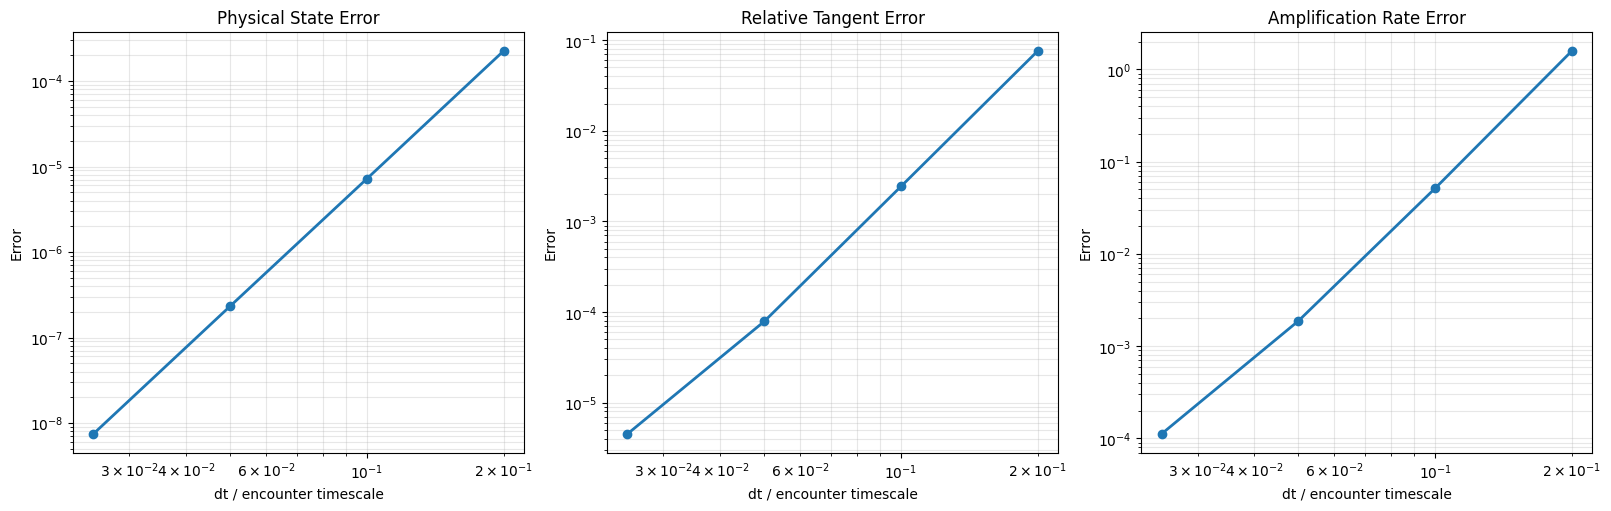

In [94]:

eta = np.array([
    x["eta"] for x in fine_tangent_results
])

physical = np.array([
    x["physical_error"] for x in fine_tangent_results
])

tangent = np.array([
    x["relative_tangent_error"]
    for x in fine_tangent_results
])

rate = np.array([
    x["rate_error"] for x in fine_tangent_results
])

fig, axes = plt.subplots(
    1, 3, figsize=(16, 5),
    constrained_layout=True
)

datasets = [
    (physical, "Physical State Error"),
    (tangent, "Relative Tangent Error"),
    (rate, "Amplification Rate Error")
]

for ax, (values, title) in zip(axes, datasets):

    ax.loglog(eta, values, "o-", linewidth=2)

    ax.set_xlabel("dt / encounter timescale")
    ax.set_ylabel("Error")
    ax.set_title(title)
    ax.grid(alpha=0.3, which="both")

plt.show()


In [95]:

# Objective 10 — Quantitative convergence analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use results from the previous experiment
df = pd.DataFrame(fine_tangent_results)
df = df.sort_values("eta").reset_index(drop=True)

metrics = {
    "Physical state": "physical_error",
    "Relative tangent": "relative_tangent_error",
    "Amplification rate": "rate_error"
}

print("OBSERVED CONVERGENCE ORDERS")
print("=" * 65)

for name, column in metrics.items():

    x = df["eta"].to_numpy()
    y = df[column].to_numpy()

    valid = (x > 0) & (y > 0) & np.isfinite(y)

    slope = np.polyfit(
        np.log(x[valid]),
        np.log(y[valid]),
        1
    )[0]

    print(f"{name:22s}: {slope:.4f}")

print("\nFULL ERROR TABLE")
print(df.to_string(index=False))


OBSERVED CONVERGENCE ORDERS
Physical state        : 4.9610
Relative tangent      : 4.7084
Amplification rate    : 4.6171

FULL ERROR TABLE
     eta  physical_error  tangent_error  relative_tangent_error  rate_error
0.025000    7.449838e-09       0.000482                0.000005    0.000112
0.050000    2.325011e-07       0.008403                0.000079    0.001874
0.099999    7.202455e-06       0.259781                0.002436    0.051470
0.199999    2.254811e-04       8.136931                0.076308    1.590344



# Objective 11 — False Chaos Classification

## 11.1 Establishing a regular gravitational benchmark

To identify artificial chaos, we need to know what genuine regular motion looks like.

We will begin with the Newtonian two-body problem.

Unlike the general three-body problem, the two-body problem is integrable. Its motion can be described analytically using Keplerian orbital mechanics.

For an isolated, bound, collision-free two-body system, we do not expect a positive asymptotic maximal Lyapunov exponent.

This makes it an excellent control experiment.

### Our investigation

We will:

1. Construct an exact circular two-body initial configuration.
2. Evolve the orbit together with its variational equations.
3. Calculate finite-time Lyapunov estimates.
4. Repeat using different timesteps.
5. Determine whether numerical under-resolution produces misleading sensitivity measurements.

We will not automatically classify every positive finite-time estimate as chaos.

A positive finite-time estimate can arise from temporary perturbation growth even when the underlying motion is regular.

Our goal is to distinguish persistent exponential sensitivity from finite-time and numerical effects.


In [96]:

import numpy as np
import matplotlib.pyplot as plt

G_value = 1.0

regular_masses = np.array([1.0, 0.001])

M = regular_masses.sum()
a = 1.0

omega = np.sqrt(G_value * M / a**3)
orbital_period = 2 * np.pi / omega

# Positions relative to the center of mass
regular_positions = np.array([
    [-regular_masses[1] / M * a, 0.0],
    [ regular_masses[0] / M * a, 0.0]
])

# Circular orbital velocities
regular_velocities = np.array([
    [0.0, omega * regular_positions[0, 0]],
    [0.0, omega * regular_positions[1, 0]]
])

print("REGULAR TWO-BODY BENCHMARK")
print("-" * 45)
print("Orbital period:", orbital_period)
print("Initial positions:\n", regular_positions)
print("Initial velocities:\n", regular_velocities)


REGULAR TWO-BODY BENCHMARK
---------------------------------------------
Orbital period: 6.280046068758708
Initial positions:
 [[-0.000999  0.      ]
 [ 0.999001  0.      ]]
Initial velocities:
 [[ 0.         -0.0009995 ]
 [ 0.          0.99950037]]



## 11.2 Finite-time Lyapunov estimates

We already implemented the variational equations.

These describe how an infinitesimal change in the initial state evolves alongside the physical trajectory.

For a perturbation $\delta X(t)$, the finite-time growth estimate is:

$$
\lambda_T =
\frac{1}{T}
\ln\left(
\frac{\|\delta X(T)\|}{\|\delta X(0)\|}
\right)
$$

For long integrations, directly evolving the perturbation without rescaling can lead to excessively large or small values.

We therefore periodically normalize the tangent vector and accumulate its logarithmic growth.

This technique allows us to estimate sensitivity over longer intervals.

For a regular orbit, the finite-time estimate may initially be positive but should trend toward zero as the observation interval becomes sufficiently long.

A converged positive value that persists over increasingly long intervals would require further investigation.

We will test that behavior using multiple timesteps.


In [97]:

def estimate_ftle_general(
    initial_positions,
    initial_velocities,
    masses,
    dt,
    total_time,
    perturb_body=1,
    renorm_interval=1.0
):
    r = initial_positions.copy()
    v = initial_velocities.copy()

    dr = np.zeros_like(r)
    dv = np.zeros_like(v)

    dr[perturb_body, 0] = 1.0

    # Fixed characteristic timescale
    T_scale = 1.0

    def tangent_norm(dr, dv):
        return np.sqrt(
            np.sum(dr**2)
            + T_scale**2 * np.sum(dv**2)
        )

    # Normalize initial perturbation
    initial_norm = tangent_norm(dr, dv)
    dr /= initial_norm
    dv /= initial_norm

    steps_per_block = int(round(
        renorm_interval / dt
    ))

    total_steps = int(round(
        total_time / dt
    ))

    if steps_per_block < 1:
        raise ValueError("Renormalization interval is too small.")

    accumulated_growth = 0.0
    steps_done = 0

    times = []
    ftle_values = []

    while steps_done < total_steps:

        block_steps = min(
            steps_per_block,
            total_steps - steps_done
        )

        for _ in range(block_steps):

            r, v, dr, dv = variational_rk4_step(
                r, v, dr, dv, masses, dt
            )

        growth = tangent_norm(dr, dv)

        if not np.isfinite(growth) or growth <= 0:
            raise FloatingPointError(
                "Invalid tangent-vector norm."
            )

        accumulated_growth += np.log(growth)

        dr /= growth
        dv /= growth

        steps_done += block_steps
        elapsed = steps_done * dt

        times.append(elapsed)
        ftle_values.append(
            accumulated_growth / elapsed
        )

    return (
        np.array(times),
        np.array(ftle_values)
    )


dt=0.050 | Final FTLE=2.38346136e-02
dt=0.025 | Final FTLE=2.38345700e-02


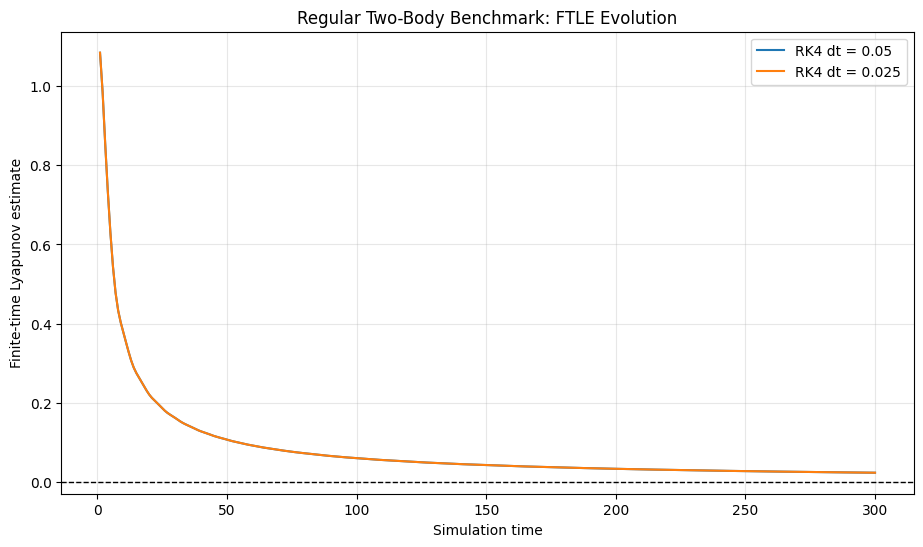

In [98]:

regular_dt_values = [0.05, 0.025]
regular_duration = 300.0

regular_ftle_results = {}

plt.figure(figsize=(11, 6))

for dt_test in regular_dt_values:

    t_values, ftle_values = estimate_ftle_general(
        regular_positions,
        regular_velocities,
        regular_masses,
        dt=dt_test,
        total_time=regular_duration,
        perturb_body=1,
        renorm_interval=1.0
    )

    regular_ftle_results[dt_test] = {
        "time": t_values,
        "ftle": ftle_values
    }

    plt.plot(
        t_values,
        ftle_values,
        label=f"RK4 dt = {dt_test}",
        linewidth=1.5
    )

    print(
        f"dt={dt_test:.3f} | "
        f"Final FTLE={ftle_values[-1]:.8e}"
    )

plt.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Simulation time")
plt.ylabel("Finite-time Lyapunov estimate")
plt.title("Regular Two-Body Benchmark: FTLE Evolution")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



## 11.3 Deliberately under-resolving an integrable orbit

Our accurate two-body simulations produced finite-time Lyapunov estimates that decrease toward zero.

We now investigate what happens when we increase the timestep.

The physical equations and initial conditions remain unchanged.

Only the numerical integration resolution changes.

We will compare several RK4 timesteps and examine:

1. The evolution of the finite-time Lyapunov estimate.
2. Whether the numerical orbit remains bounded.
3. The change in total mechanical energy.

This lets us investigate whether a numerical algorithm can generate misleading instability measurements for a physically integrable system.

### Important distinction

A positive FTLE over a finite interval is not enough to demonstrate artificial chaos.

To make that claim, we would need persistent positive Lyapunov behavior under the discrete numerical dynamics, followed by comparison against the exact regular physical system.

For now, our experiment identifies numerical failure regimes and possible false-positive indicators.


dt=0.025 | Final FTLE=2.38345700e-02
dt=0.100 | Final FTLE=2.38359796e-02
dt=0.300 | Final FTLE=2.42132392e-02
dt=0.500 | Final FTLE=5.27668580e-02
dt=0.800 | Final FTLE=7.78141149e-02


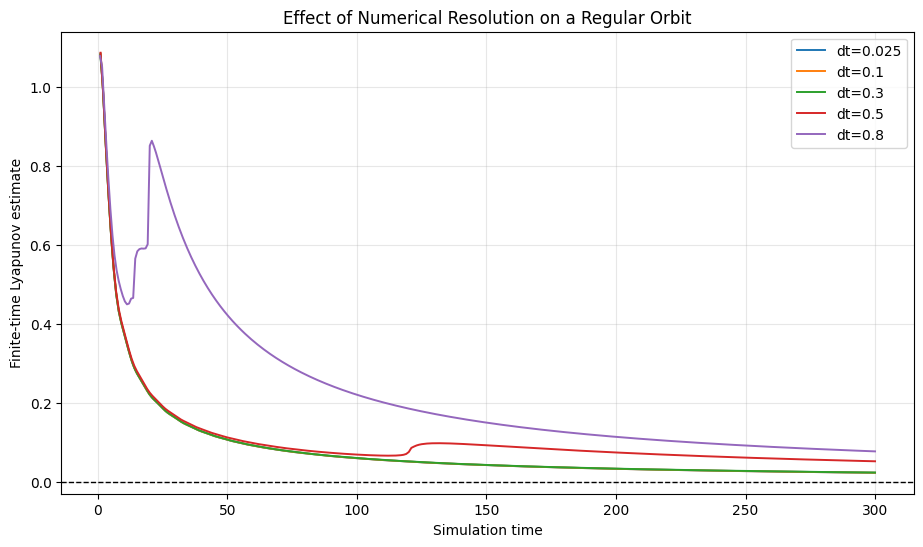

In [99]:

# Objective 11 — Coarse timestep experiment

coarse_dt_values = [0.025, 0.1, 0.3, 0.5, 0.8]

duration_test = 300.0

coarse_ftle_results = {}

plt.figure(figsize=(11, 6))

for dt_test in coarse_dt_values:

    try:
        t_values, lambda_values = estimate_ftle_general(
            regular_positions,
            regular_velocities,
            regular_masses,
            dt=dt_test,
            total_time=duration_test,
            perturb_body=1,
            renorm_interval=1.0
        )

        coarse_ftle_results[dt_test] = {
            "time": t_values,
            "ftle": lambda_values
        }

        plt.plot(
            t_values,
            lambda_values,
            label=f"dt={dt_test}",
            linewidth=1.4
        )

        print(
            f"dt={dt_test:.3f} | "
            f"Final FTLE={lambda_values[-1]:.8e}"
        )

    except (FloatingPointError, ValueError,
            OverflowError) as error:

        print(f"dt={dt_test:.3f} failed: {error}")

plt.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Simulation time")
plt.ylabel("Finite-time Lyapunov estimate")
plt.title("Effect of Numerical Resolution on a Regular Orbit")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


dt=0.025 | Maximum energy error=8.16350065e-08
dt=0.100 | Maximum energy error=8.37895142e-05
dt=0.300 | Maximum energy error=2.31847155e-02
dt=0.500 | Maximum energy error=3.71392422e+00
dt=0.800 | Maximum energy error=2.76709439e+02


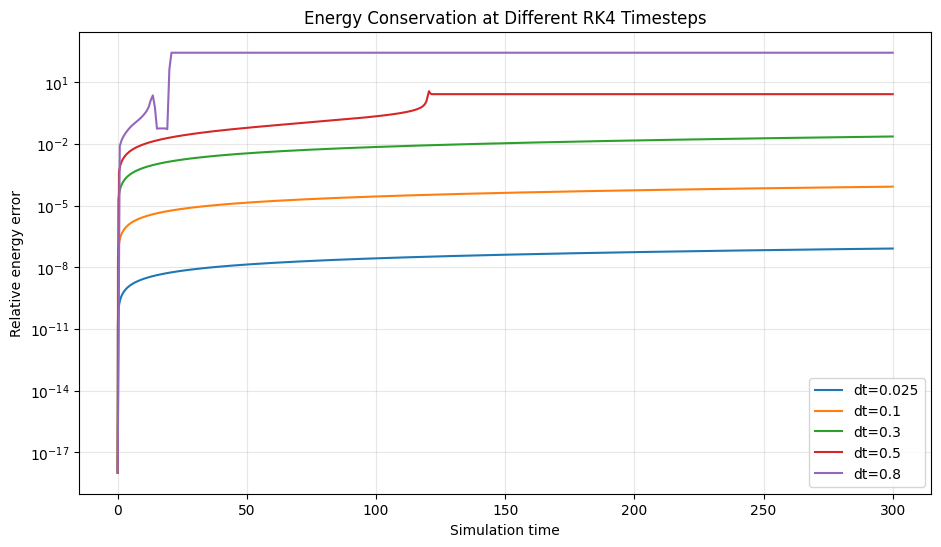

In [100]:

energy_results = {}

plt.figure(figsize=(11, 6))

for dt_test in coarse_dt_values:

    steps = int(round(duration_test / dt_test))

    pos_hist, vel_hist = simulate_with_integrator(
        rk4_step,
        regular_positions,
        regular_velocities,
        regular_masses,
        dt_test,
        steps
    )

    errors = energy_error_history(
        pos_hist,
        vel_hist,
        regular_masses
    )

    simulation_times = np.arange(steps + 1) * dt_test

    energy_results[dt_test] = errors

    plt.semilogy(
        simulation_times,
        np.maximum(errors, 1e-18),
        label=f"dt={dt_test}"
    )

    print(
        f"dt={dt_test:.3f} | "
        f"Maximum energy error={errors.max():.8e}"
    )

plt.xlabel("Simulation time")
plt.ylabel("Relative energy error")
plt.title("Energy Conservation at Different RK4 Timesteps")

plt.legend()
plt.grid(alpha=0.3, which="both")
plt.show()



## 11.4 Did numerical error eject a planet from an integrable orbit?

Our coarse-timestep RK4 experiments showed enormous changes in total mechanical energy.

We will now investigate whether these errors caused the simulated planet to become unbound.

For the Newtonian two-body problem, the relative specific orbital energy is:

$$
\epsilon=\frac{v_{\mathrm{rel}}^2}{2}
-\frac{G(m_1+m_2)}{r}
$$

where $r$ is the separation between the two bodies and $v_{\mathrm{rel}}$ is their relative speed.

The sign of this quantity determines the type of Keplerian orbit:

- Negative energy: Bound elliptical orbit.
- Zero energy: Parabolic escape trajectory.
- Positive energy: Hyperbolic escape trajectory.

Because the exact initial conditions describe a bound circular orbit, any numerical transition to positive energy would be artificial.

We will compare the specific orbital energy and separation for different RK4 timesteps.


dt=0.025 | Final energy=-5.005000e-01 | Final separation=1.000000
dt=0.100 | Final energy=-5.005419e-01 | Final separation=0.999915
dt=0.300 | Final energy=-5.121040e-01 | Final separation=0.977089
dt=0.500 | Final energy=8.309212e-01 | Final separation=234.329513
dt=0.800 | Final energy=1.379922e+02 | Final separation=4651.497265


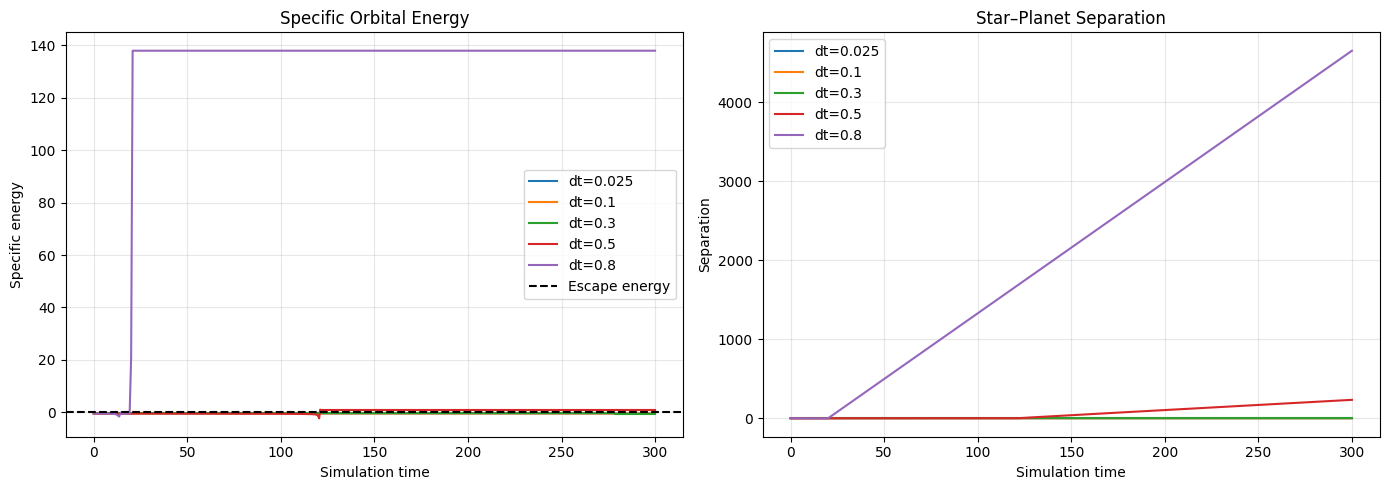

In [101]:

import numpy as np
import matplotlib.pyplot as plt

dt_values = [0.025, 0.1, 0.3, 0.5, 0.8]

total_time = 300.0

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for dt_test in dt_values:

    # Use actual dt so all simulations end at time 300.
    n_steps = int(round(total_time / dt_test))
    dt_actual = total_time / n_steps

    pos_hist, vel_hist = simulate_with_integrator(
        rk4_step,
        regular_positions,
        regular_velocities,
        regular_masses,
        dt_actual,
        n_steps
    )

    # Relative position and velocity
    relative_r = (
        pos_hist[:, 1, :] -
        pos_hist[:, 0, :]
    )

    relative_v = (
        vel_hist[:, 1, :] -
        vel_hist[:, 0, :]
    )

    distance = np.linalg.norm(relative_r, axis=1)

    speed2 = np.sum(relative_v**2, axis=1)

    # Specific orbital energy
    mu = G_value * regular_masses.sum()

    specific_energy = (
        0.5 * speed2 - mu / distance
    )

    times = np.arange(n_steps + 1) * dt_actual

    axes[0].plot(
        times,
        specific_energy,
        label=f"dt={dt_test}"
    )

    axes[1].plot(
        times,
        distance,
        label=f"dt={dt_test}"
    )

    print(
        f"dt={dt_test:.3f} | "
        f"Final energy={specific_energy[-1]:.6e} | "
        f"Final separation={distance[-1]:.6f}"
    )

axes[0].axhline(
    0,
    color="black",
    linestyle="--",
    label="Escape energy"
)

axes[0].set_title("Specific Orbital Energy")
axes[0].set_xlabel("Simulation time")
axes[0].set_ylabel("Specific energy")

axes[1].set_title("Star–Planet Separation")
axes[1].set_xlabel("Simulation time")
axes[1].set_ylabel("Separation")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



## 11.6 Detecting a false orbital escape

We have observed that coarse RK4 integration can transform an initially circular, bound two-body orbit into an apparently escaping trajectory.

For the exact Newtonian problem, the specific orbital energy remains constant:

$$
\epsilon=-\frac{G(m_1+m_2)}{2a}
$$

With our normalized initial conditions:

$$
\epsilon_0=-0.5005
$$

We will now identify the first time at which the numerical specific energy becomes nonnegative.

We will also record the final orbital separation and the maximum energy error.

This will allow us to distinguish numerical orbital failure from genuine dynamical chaos.

A numerical escape is a qualitatively incorrect orbital prediction, but it is not necessarily a false positive Lyapunov exponent.


In [102]:

import numpy as np
import pandas as pd

# Include additional timesteps around the suspected transition.
dt_values = [
    0.025, 0.1, 0.2, 0.3,
    0.35, 0.4, 0.45, 0.5,
    0.6, 0.7, 0.8
]

total_time = 300.0

escape_records = []

mu = G_value * np.sum(regular_masses)

for dt_requested in dt_values:

    n_steps = int(round(total_time / dt_requested))
    dt_actual = total_time / n_steps

    pos_hist, vel_hist = simulate_with_integrator(
        rk4_step,
        regular_positions,
        regular_velocities,
        regular_masses,
        dt_actual,
        n_steps
    )

    relative_r = pos_hist[:, 1] - pos_hist[:, 0]
    relative_v = vel_hist[:, 1] - vel_hist[:, 0]

    distances = np.linalg.norm(relative_r, axis=1)
    speeds_sq = np.sum(relative_v**2, axis=1)

    energy = 0.5 * speeds_sq - mu / distances

    times = np.arange(n_steps + 1) * dt_actual

    # First numerical transition to nonnegative energy
    crossing_indices = np.flatnonzero(energy >= 0)

    crossing_time = (
        times[crossing_indices[0]]
        if len(crossing_indices) > 0
        else np.nan
    )

    escape_records.append({
        "dt_requested": dt_requested,
        "dt_actual": dt_actual,
        "first_E_ge_0": crossing_time,
        "final_energy": energy[-1],
        "final_distance": distances[-1],
        "maximum_distance": distances.max()
    })

escape_df = pd.DataFrame(escape_records)

print(
    escape_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6g}"
    )
)


 dt_requested  dt_actual  first_E_ge_0  final_energy  final_distance  maximum_distance
        0.025      0.025           NaN       -0.5005               1                 1
          0.1        0.1           NaN     -0.500542        0.999915                 1
          0.2        0.2           NaN     -0.501868         0.99726                 1
          0.3        0.3           NaN     -0.512104        0.977089                 1
         0.35   0.350058           NaN     -0.530387        0.943229                 1
          0.4        0.4           NaN     -0.599588        0.833922                 1
         0.45   0.449775       205.997       1.12268         143.485           143.485
          0.5        0.5           121      0.830921          234.33            234.33
          0.6        0.6          67.8       6.10317         811.745           811.745
          0.7   0.699301       24.4755      0.840521         361.117           361.117
          0.8        0.8            20     

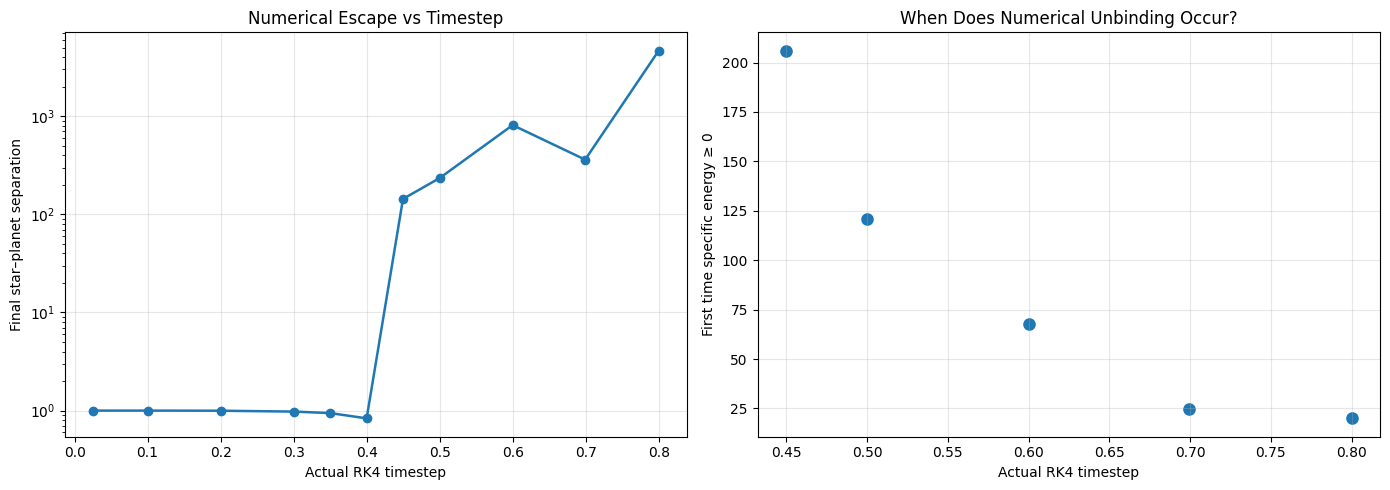

In [103]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    escape_df["dt_actual"],
    escape_df["final_distance"],
    "o-",
    linewidth=1.8
)

axes[0].set_yscale("log")
axes[0].set_xlabel("Actual RK4 timestep")
axes[0].set_ylabel("Final star–planet separation")
axes[0].set_title("Numerical Escape vs Timestep")

# Show only simulations in which energy became nonnegative
escaped = escape_df.dropna(subset=["first_E_ge_0"])

axes[1].scatter(
    escaped["dt_actual"],
    escaped["first_E_ge_0"],
    s=65
)

axes[1].set_xlabel("Actual RK4 timestep")
axes[1].set_ylabel("First time specific energy ≥ 0")
axes[1].set_title("When Does Numerical Unbinding Occur?")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



# Objective 12 — Numerical Chaos Classification

## 12.1 What does it mean for a gravitational system to be chaotic?

We know that a gravitational system follows deterministic equations.

If we specify every body's initial position, velocity, and mass, Newton's equations determine its subsequent motion.

However, determinism does not always imply long-term predictability.

Some gravitational systems are chaotic: infinitesimally different starting conditions can produce trajectories that separate exponentially.

The maximal Lyapunov exponent describes this sensitivity.

For regular motion:

$$
\lambda_{\max}=0
$$

For chaotic motion:

$$
\lambda_{\max}>0
$$

The difficulty is that we never calculate the true infinite-time Lyapunov exponent on a computer.

We calculate a finite-time estimate:

$$
\lambda_T=
\frac{1}{T}
\ln\left(\frac{\|\delta X(T)\|}{\|\delta X(0)\|}\right)
$$

Even regular motion may produce a positive value for finite $T$.

Therefore, a positive measurement alone is not enough to establish chaos.

### Our classification strategy

We will distinguish three categories:

**Regular candidate:** The finite-time Lyapunov estimate decreases toward zero as the observation duration increases.

**Chaotic candidate:** The estimate approaches a reproducible positive value over increasingly long, numerically converged integrations.

**Unresolved:** The available numerical evidence cannot distinguish the two reliably.

A physically known integrable system will serve as our regular control.

For a chaotic control, we must first identify a suitable three-body configuration and validate its behavior independently.

Our eventual goal is to test whether changing the numerical integrator or timestep changes these classifications.


T =   50 | FTLE = 1.07186965e-01
T =  100 | FTLE = 6.05241893e-02
T =  200 | FTLE = 3.37265132e-02
T =  400 | FTLE = 1.85939352e-02
T =  800 | FTLE = 1.01614308e-02


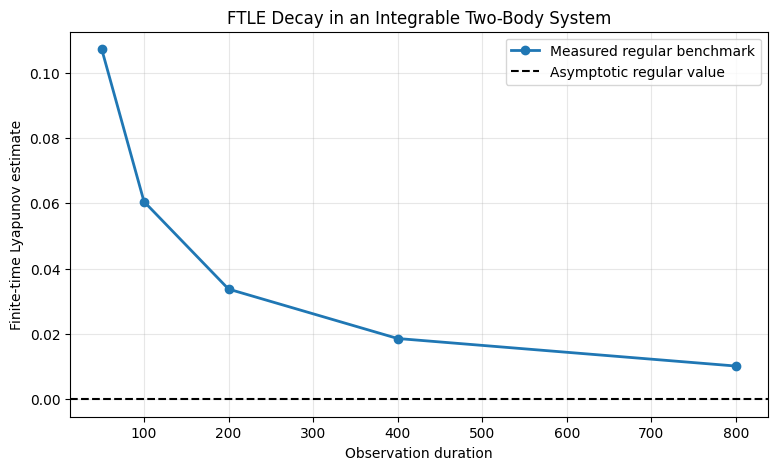

In [104]:

import numpy as np
import matplotlib.pyplot as plt

# Reuse our existing regular two-body configuration.
# regular_positions
# regular_velocities
# regular_masses
# estimate_ftle_general

observation_times = [50, 100, 200, 400, 800]

regular_decay_results = []

for T in observation_times:

    times, ftle = estimate_ftle_general(
        regular_positions,
        regular_velocities,
        regular_masses,
        dt=0.025,
        total_time=float(T),
        perturb_body=1,
        renorm_interval=1.0
    )

    regular_decay_results.append(ftle[-1])

    print(
        f"T = {T:4d} | "
        f"FTLE = {ftle[-1]:.8e}"
    )

plt.figure(figsize=(9, 5))

plt.plot(
    observation_times,
    regular_decay_results,
    "o-",
    linewidth=2,
    label="Measured regular benchmark"
)

plt.axhline(
    0,
    color="black",
    linestyle="--",
    label="Asymptotic regular value"
)

plt.xlabel("Observation duration")
plt.ylabel("Finite-time Lyapunov estimate")
plt.title("FTLE Decay in an Integrable Two-Body System")

plt.legend()
plt.grid(alpha=0.3)
plt.show()



## 12.2 Why do we need a separate three-body benchmark?

The two-body problem is integrable, making it useful as a regular reference.

The general gravitational three-body problem is more complicated.

Three interacting bodies can exchange energy and angular momentum in ways that create nonlinear dynamical behavior, including chaos.

However, not every three-body orbit is chaotic.

We therefore need to search for promising configurations rather than assume that adding a third body automatically creates chaos.

We will use the restricted three-body system already introduced in Objective 08:

- One central star
- One massive perturbing planet
- One massless test particle

We will vary the test particle's initial orbital radius.

For each configuration, we will calculate a finite-time Lyapunov estimate and monitor whether the test particle experiences a very close encounter or travels far from the star.

These additional checks are essential.

A very large FTLE caused by an unresolved near-collision is not a trustworthy chaotic benchmark.

Our first scan is exploratory. We will classify its results as candidates requiring further validation.


In [105]:

# Objective 12: Candidate stability scan

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

candidate_radii = [
    1.20, 1.30, 1.40,
    1.50, 1.60, 1.80
]

scan_dt = 0.02
scan_duration = 120.0

scan_records = []

for radius in candidate_radii:

    r, v, m = make_restricted_three_body(
        test_radius=radius,
        test_angle_deg=120.0
    )

    dr = np.zeros_like(r)
    dv = np.zeros_like(v)

    # Initial tangent direction
    dr[2, 0] = 1.0

    growth_sum = 0.0
    elapsed = 0.0

    steps = int(round(scan_duration / scan_dt))
    renorm_steps = int(round(1.0 / scan_dt))

    min_planet_distance = np.inf
    max_star_distance = 0.0

    failed = False

    for step in range(steps):

        # Record current geometry
        d_planet = np.linalg.norm(r[2] - r[1])
        d_star = np.linalg.norm(r[2] - r[0])

        min_planet_distance = min(
            min_planet_distance, d_planet
        )

        max_star_distance = max(
            max_star_distance, d_star
        )

        try:
            r, v, dr, dv = variational_rk4_step(
                r, v, dr, dv, m, scan_dt
            )
        except (ValueError, FloatingPointError,
                ZeroDivisionError, OverflowError):
            failed = True
            break

        if not all(
            np.all(np.isfinite(x))
            for x in (r, v, dr, dv)
        ):
            failed = True
            break

        elapsed += scan_dt

        if (step + 1) % renorm_steps == 0:

            growth = full_tangent_norm(dr, dv)

            if not np.isfinite(growth) or growth <= 0:
                failed = True
                break

            growth_sum += np.log(growth)

            dr /= growth
            dv /= growth

    # Include final geometry
    if not failed:
        min_planet_distance = min(
            min_planet_distance,
            np.linalg.norm(r[2] - r[1])
        )
        max_star_distance = max(
            max_star_distance,
            np.linalg.norm(r[2] - r[0])
        )

    ftle = (
        growth_sum / elapsed
        if not failed and elapsed > 0
        else np.nan
    )

    # Conservative flags for further investigation.
    # These are screening thresholds, not
    # universal chaos/stability criteria.
    close_encounter_flag = (
        min_planet_distance < 0.05
    )

    distant_excursion_flag = (
        max_star_distance > 10.0
    )

    scan_records.append({
        "radius": radius,
        "ftle": ftle,
        "min_planet_distance": min_planet_distance,
        "max_star_distance": max_star_distance,
        "close_encounter": close_encounter_flag,
        "distant_excursion": distant_excursion_flag,
        "failed": failed
    })

scan_df = pd.DataFrame(scan_records)

print(
    scan_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6e}"
    )
)


      radius         ftle  min_planet_distance  max_star_distance  close_encounter  distant_excursion  failed
1.200000e+00 1.464051e-01         1.997944e-03       1.821688e+02             True               True   False
1.300000e+00 2.876544e-02         2.977987e-01       1.482164e+00            False              False   False
1.400000e+00 4.083268e-02         3.913020e-01       1.422944e+00            False              False   False
1.500000e+00 3.964356e-02         4.914524e-01       1.513590e+00            False              False   False
1.600000e+00 3.813775e-02         6.026144e-01       1.632176e+00            False              False   False
1.800000e+00 3.661242e-02         8.015766e-01       1.804641e+00            False              False   False


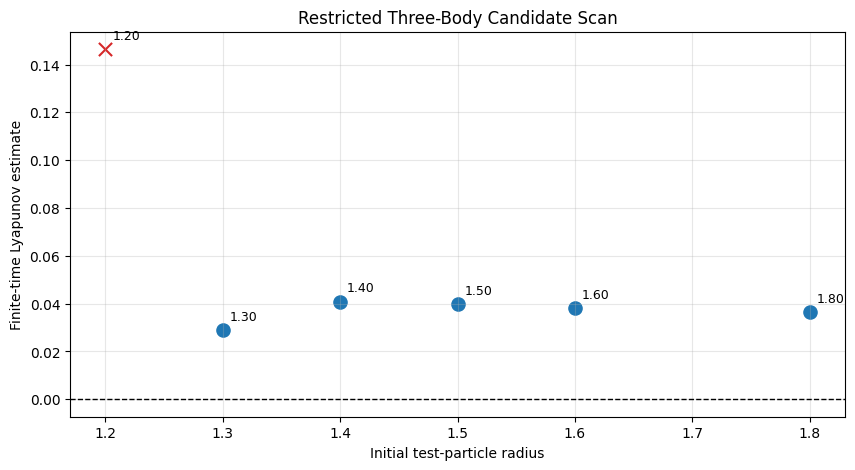

UNFLAGGED CANDIDATES FOR VALIDATION
-------------------------------------------------------
 radius     ftle  min_planet_distance  max_star_distance
    1.4 0.040833             0.391302           1.422944
    1.5 0.039644             0.491452           1.513590
    1.6 0.038138             0.602614           1.632176
    1.8 0.036612             0.801577           1.804641
    1.3 0.028765             0.297799           1.482164


In [106]:

fig, ax = plt.subplots(figsize=(10, 5))

# Plot each candidate, distinguishing flagged cases.
for _, record in scan_df.iterrows():

    flagged = (
        bool(record["close_encounter"])
        or bool(record["distant_excursion"])
        or bool(record["failed"])
    )

    ax.scatter(
        record["radius"],
        record["ftle"],
        s=90,
        marker="x" if flagged else "o",
        color="tab:red" if flagged else "tab:blue"
    )

    if np.isfinite(record["ftle"]):
        ax.annotate(
            f'{record["radius"]:.2f}',
            (record["radius"], record["ftle"]),
            xytext=(5, 7),
            textcoords="offset points",
            fontsize=9
        )

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Initial test-particle radius")
ax.set_ylabel("Finite-time Lyapunov estimate")
ax.set_title("Restricted Three-Body Candidate Scan")
ax.grid(alpha=0.3)

plt.show()

# Identify unflagged candidates for further study.
safe_candidates = scan_df[
    (~scan_df["close_encounter"])
    & (~scan_df["distant_excursion"])
    & (~scan_df["failed"])
    & np.isfinite(scan_df["ftle"])
].copy()

safe_candidates = safe_candidates.sort_values(
    "ftle",
    ascending=False
)

print("UNFLAGGED CANDIDATES FOR VALIDATION")
print("-" * 55)

if len(safe_candidates) == 0:
    print(
        "No unflagged candidates in this scan. "
        "A different parameter range or more accurate "
        "encounter-aware integration is needed."
    )
else:
    print(
        safe_candidates[
            ["radius", "ftle",
             "min_planet_distance",
             "max_star_distance"]
        ].to_string(index=False)
    )



## 12.3 Testing whether a positive Lyapunov estimate persists

Our initial scan identified a candidate at an orbital radius of 1.40.

Its finite-time Lyapunov estimate was approximately 0.041 over 120 simulation time units.

But a positive finite-time estimate doesn't establish chaos.

We need to investigate two questions:

**Time dependence:** Does the estimate approach zero as the observation duration increases, or does it approach a positive plateau?

**Numerical dependence:** Does reducing the timestep change the estimated exponent substantially?

We will calculate the FTLE at three durations:

$$
T=120,\quad 240,\quad 480
$$

using two timestep sizes:

$$
\Delta t=0.02,\quad0.01
$$

We will also monitor close encounters and large orbital excursions.

These are preliminary numerical checks, not yet an independent confirmation of chaos.


dt=0.020 | T=120 | FTLE=4.08326786e-02
dt=0.020 | T=240 | FTLE=2.35707063e-02
dt=0.020 | T=480 | FTLE=1.65991946e-02
dt=0.010 | T=120 | FTLE=4.08326792e-02
dt=0.010 | T=240 | FTLE=2.35707053e-02
dt=0.010 | T=480 | FTLE=1.65991885e-02


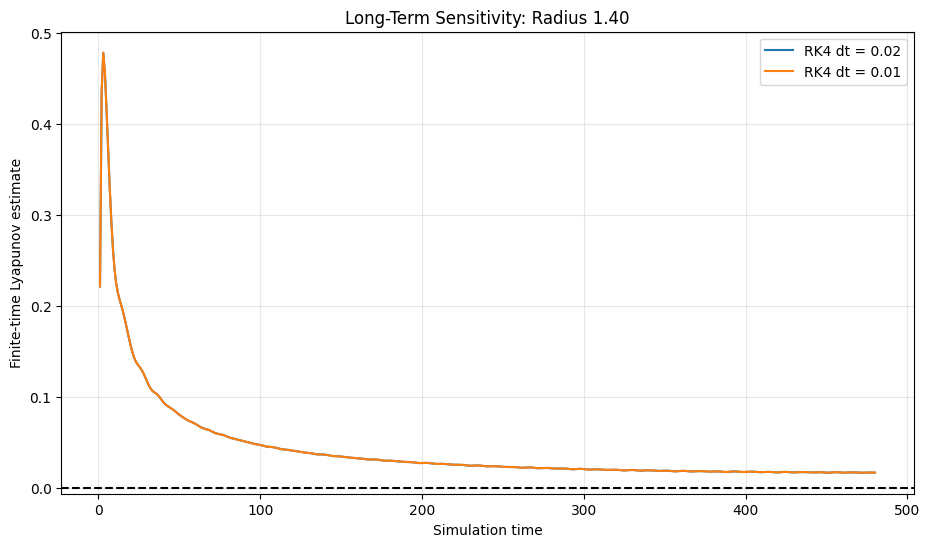

In [107]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Candidate identified in our exploratory scan
validation_radius = 1.40

r_candidate, v_candidate, m_candidate = make_restricted_three_body(
    test_radius=validation_radius,
    test_angle_deg=120.0
)

durations = [120.0, 240.0, 480.0]
timesteps = [0.02, 0.01]

validation_records = []

fig, ax = plt.subplots(figsize=(11, 6))

for dt_test in timesteps:

    # One long calculation gives us FTLE at all shorter horizons.
    t_values, ftle_values = estimate_ftle_general(
        r_candidate,
        v_candidate,
        m_candidate,
        dt=dt_test,
        total_time=max(durations),
        perturb_body=2,
        renorm_interval=1.0
    )

    ax.plot(
        t_values,
        ftle_values,
        label=f"RK4 dt = {dt_test}",
        linewidth=1.5
    )

    for T in durations:

        index = np.argmin(np.abs(t_values - T))

        value = ftle_values[index]

        validation_records.append({
            "dt": dt_test,
            "duration": T,
            "ftle": value
        })

        print(
            f"dt={dt_test:.3f} | "
            f"T={T:.0f} | "
            f"FTLE={value:.8e}"
        )

validation_df = pd.DataFrame(validation_records)

ax.axhline(0, color="black", linestyle="--")
ax.set_xlabel("Simulation time")
ax.set_ylabel("Finite-time Lyapunov estimate")
ax.set_title("Long-Term Sensitivity: Radius 1.40")
ax.legend()
ax.grid(alpha=0.3)

plt.show()


GEOMETRIC VALIDATION
--------------------------------------------------
Minimum planet distance: 0.3595917965579164
Maximum star distance: 1.4905906466561218
Final star distance: 1.3340123858325845


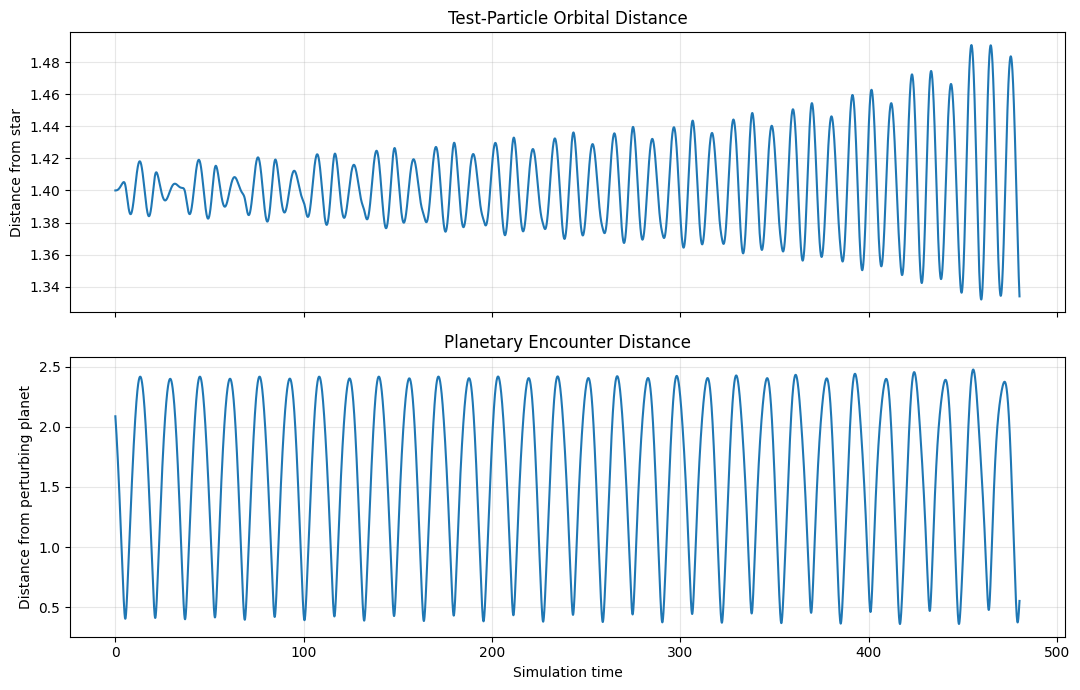

In [108]:

# Geometry diagnostics for the candidate
geometry_dt = 0.01
geometry_duration = 480.0

geometry_steps = int(round(
    geometry_duration / geometry_dt
))

p_hist, v_hist = simulate_with_integrator(
    rk4_step,
    r_candidate,
    v_candidate,
    m_candidate,
    geometry_dt,
    geometry_steps
)

geometry_times = (
    np.arange(geometry_steps + 1) * geometry_dt
)

distance_star = np.linalg.norm(
    p_hist[:, 2] - p_hist[:, 0],
    axis=1
)

distance_planet = np.linalg.norm(
    p_hist[:, 2] - p_hist[:, 1],
    axis=1
)

print("GEOMETRIC VALIDATION")
print("-" * 50)
print("Minimum planet distance:", distance_planet.min())
print("Maximum star distance:", distance_star.max())
print("Final star distance:", distance_star[-1])

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(
    geometry_times,
    distance_star
)
axes[0].set_ylabel("Distance from star")
axes[0].set_title("Test-Particle Orbital Distance")

axes[1].plot(
    geometry_times,
    distance_planet
)
axes[1].set_ylabel("Distance from perturbing planet")
axes[1].set_xlabel("Simulation time")
axes[1].set_title("Planetary Encounter Distance")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



## 12.5 Searching near orbital resonances

Our first three-body candidate at radius 1.40 showed a decreasing finite-time Lyapunov exponent and remained in a bounded-looking orbital region.

We will now investigate orbital configurations near the 3:2 and 2:1 mean-motion resonances.

Instead of changing only the orbital radius, we will vary three parameters:

- Test-particle orbital radius
- Perturbing planet mass
- Initial angular separation

The purpose is to identify configurations with stronger sustained sensitivity while monitoring close encounters and large outward excursions.

We will not classify a system as chaotic simply because its finite-time Lyapunov estimate is large.

The strongest candidates will need longer integrations and independent numerical validation.


In [109]:

import numpy as np
import pandas as pd

# Search around two resonant regions.
radii = [1.28, 1.31, 1.34, 1.55, 1.59, 1.63]

# Use two perturbation strengths.
planet_masses = [0.001, 0.005]

# One starting phase for this initial scan.
initial_angle = 120.0

scan_dt = 0.02
scan_duration = 120.0

records = []

for planet_mass in planet_masses:
    for radius in radii:

        r, v, m = make_restricted_three_body(
            test_radius=radius,
            test_angle_deg=initial_angle,
            planet_mass=planet_mass
        )

        dr = np.zeros_like(r)
        dv = np.zeros_like(v)
        dr[2, 0] = 1.0

        log_growth = 0.0
        min_distance = np.inf
        max_radius = 0.0
        failed = False

        n_steps = int(round(scan_duration / scan_dt))
        block_steps = int(round(1.0 / scan_dt))

        for step in range(n_steps):

            d_planet = np.linalg.norm(r[2] - r[1])
            d_star = np.linalg.norm(r[2] - r[0])

            min_distance = min(min_distance, d_planet)
            max_radius = max(max_radius, d_star)

            try:
                r, v, dr, dv = variational_rk4_step(
                    r, v, dr, dv, m, scan_dt
                )

                if not all(
                    np.all(np.isfinite(x))
                    for x in (r, v, dr, dv)
                ):
                    failed = True
                    break

                if (step + 1) % block_steps == 0:
                    growth = full_tangent_norm(dr, dv)

                    if not np.isfinite(growth) or growth <= 0:
                        failed = True
                        break

                    log_growth += np.log(growth)
                    dr /= growth
                    dv /= growth

            except (ValueError, FloatingPointError,
                    ZeroDivisionError, OverflowError):
                failed = True
                break

        if not failed:
            min_distance = min(
                min_distance, np.linalg.norm(r[2] - r[1])
            )
            max_radius = max(
                max_radius, np.linalg.norm(r[2] - r[0])
            )

        ftle = (
            log_growth / scan_duration
            if not failed else np.nan
        )

        records.append({
            "planet_mass": planet_mass,
            "radius": radius,
            "ftle": ftle,
            "minimum_encounter_distance": min_distance,
            "maximum_star_distance": max_radius,
            "failed": failed
        })

scan_resonances = pd.DataFrame(records)

print(scan_resonances.to_string(index=False))


 planet_mass  radius     ftle  minimum_encounter_distance  maximum_star_distance  failed
       0.001    1.28 0.037310                    0.216811               1.548293   False
       0.001    1.31 0.027631                    0.310898               1.448723   False
       0.001    1.34 0.041364                    0.339605               1.394953   False
       0.001    1.55 0.039361                    0.528663               1.576652   False
       0.001    1.59 0.038271                    0.592681               1.628788   False
       0.001    1.63 0.037701                    0.632464               1.646149   False
       0.005    1.28 0.063742                    0.026045               1.818884   False
       0.005    1.31 0.037929                    0.320537               2.179331   False
       0.005    1.34 0.091038                    0.147733               5.854795   False
       0.005    1.55 0.021453                    0.485800               1.926604   False
       0.005    1.59 

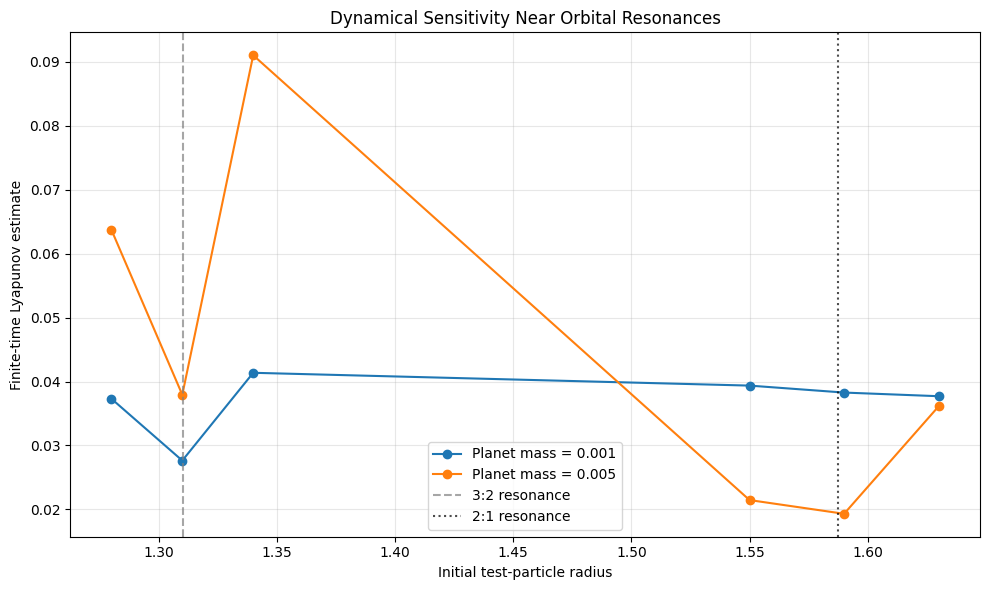

In [110]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

for mass, group in scan_resonances.groupby("planet_mass"):

    ax.plot(
        group["radius"],
        group["ftle"],
        "o-",
        label=f"Planet mass = {mass}"
    )

ax.axvline(
    (3/2)**(2/3),
    linestyle="--",
    color="gray",
    alpha=0.7,
    label="3:2 resonance"
)

ax.axvline(
    2**(2/3),
    linestyle=":",
    color="black",
    alpha=0.7,
    label="2:1 resonance"
)

ax.set_xlabel("Initial test-particle radius")
ax.set_ylabel("Finite-time Lyapunov estimate")
ax.set_title("Dynamical Sensitivity Near Orbital Resonances")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



## 12.7 Validating potential chaotic trajectories

Our resonance scan identified a strong finite-time sensitivity signal at radius 1.34 with a perturbing planet mass of 0.005.

However, a large finite-time Lyapunov estimate may result from a transient gravitational encounter rather than sustained chaos.

We will examine two configurations:

- Candidate A: radius 1.34, planet mass 0.005
- Candidate B: radius 1.59, planet mass 0.005

We will use adaptive DOP853 integration to investigate their physical trajectories.

We will measure the minimum separation from the massive planet, maximum distance from the star, and numerical agreement between independently refined solutions.

The purpose is to determine whether the configurations are suitable for longer-term chaos analysis.


In [111]:

import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp

candidates = {
    "A — High FTLE": 1.34,
    "B — Low FTLE": 1.59
}

planet_mass = 0.005
duration = 120.0

candidate_results = {}
records = []

for name, radius in candidates.items():

    r0, v0, masses = make_restricted_three_body(
        test_radius=radius,
        test_angle_deg=120.0,
        planet_mass=planet_mass
    )

    n = len(masses)
    y0 = np.concatenate([r0.ravel(), v0.ravel()])

    solutions_candidate = []

    for rtol, atol in [
        (1e-10, 1e-12),
        (1e-12, 1e-14)
    ]:

        sol = solve_ivp(
            three_body_rhs,
            (0.0, duration),
            y0,
            args=(masses,),
            method="DOP853",
            rtol=rtol,
            atol=atol,
            max_step=0.05,
            dense_output=True
        )

        if not sol.success:
            raise RuntimeError(
                f"{name}: {sol.message}"
            )

        solutions_candidate.append(sol)

    # Compare both solutions at identical times.
    times = np.linspace(0, duration, 2401)

    p1 = solutions_candidate[0].sol(times)[:2*n].T.reshape(-1, n, 2)
    p2 = solutions_candidate[1].sol(times)[:2*n].T.reshape(-1, n, 2)

    # Positions of test particle relative to star
    q1 = p1[:, 2] - p1[:, 0]
    q2 = p2[:, 2] - p2[:, 0]

    # Distance diagnostics
    d_star = np.linalg.norm(q2, axis=1)
    d_planet = np.linalg.norm(
        p2[:, 2] - p2[:, 1],
        axis=1
    )

    disagreement = np.linalg.norm(
        q1 - q2,
        axis=1
    )

    candidate_results[name] = {
        "time": times,
        "star_distance": d_star,
        "planet_distance": d_planet,
        "disagreement": disagreement,
        "solutions": solutions_candidate
    }

    records.append({
        "candidate": name,
        "radius": radius,
        "min_planet_distance_sampled": d_planet.min(),
        "max_star_distance_sampled": d_star.max(),
        "max_position_disagreement": disagreement.max()
    })

summary_df = pd.DataFrame(records)

print(summary_df.to_string(index=False))


    candidate  radius  min_planet_distance_sampled  max_star_distance_sampled  max_position_disagreement
A — High FTLE    1.34                     0.147741                   5.854831               7.090885e-10
 B — Low FTLE    1.59                     0.602615                   1.753705               4.727965e-13


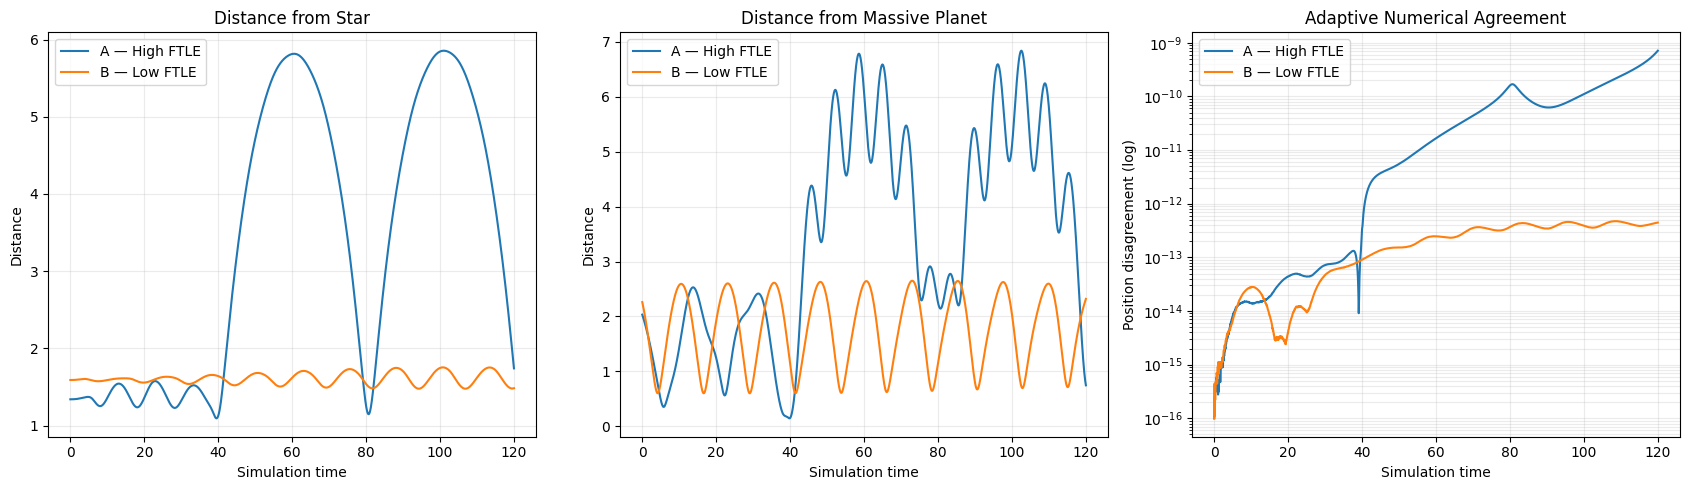

In [112]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for name, result in candidate_results.items():

    t = result["time"]

    axes[0].plot(
        t,
        result["star_distance"],
        label=name
    )

    axes[1].plot(
        t,
        result["planet_distance"],
        label=name
    )

    axes[2].semilogy(
        t,
        np.maximum(result["disagreement"], 1e-16),
        label=name
    )

axes[0].set_title("Distance from Star")
axes[0].set_ylabel("Distance")

axes[1].set_title("Distance from Massive Planet")
axes[1].set_ylabel("Distance")

axes[2].set_title("Adaptive Numerical Agreement")
axes[2].set_ylabel("Position disagreement (log)")

for ax in axes:
    ax.set_xlabel("Simulation time")
    ax.grid(alpha=0.25, which="both")
    ax.legend()

plt.tight_layout()
plt.show()



## 12.9 Long-term validation of our chaos candidates

We have identified two gravitational configurations with different dynamical behavior.

Candidate A experiences large orbital excursions and has a relatively high finite-time Lyapunov estimate.

Candidate B exhibits more regular-looking oscillations and has a lower estimate.

However, neither configuration has been definitively classified.

We will now integrate the physical and variational equations simultaneously using adaptive DOP853.

To prevent the tangent vector from becoming excessively large or small, we will periodically normalize it and accumulate its logarithmic growth.

The finite-time Lyapunov estimate is:

$$
\lambda_T=\frac{1}{T}\sum_k\ln g_k
$$

where $g_k$ is the tangent-vector amplification during integration block $k$.

We will also compare adaptive tolerance settings.

Our main question is whether Candidate A's FTLE approaches a positive plateau or decreases toward zero over longer observation times.

Even if a positive plateau appears, we will need numerical and long-time validation before calling the system genuinely chaotic.


In [113]:

import numpy as np
from scipy.integrate import solve_ivp

def adaptive_ftle(
    initial_positions,
    initial_velocities,
    masses,
    total_time=240.0,
    renorm_interval=2.0,
    rtol=1e-11,
    atol=1e-13,
    max_step=0.1
):
    n = len(masses)

    r = initial_positions.copy()
    v = initial_velocities.copy()

    # Initial tangent perturbation
    dr = np.zeros_like(r)
    dv = np.zeros_like(v)

    dr[2, 0] = 1.0

    def tangent_norm(dr, dv):
        return np.sqrt(
            np.sum(dr**2) + np.sum(dv**2)
        )

    # Normalize tangent vector
    norm0 = tangent_norm(dr, dv)
    dr /= norm0
    dv /= norm0

    log_growth = 0.0
    elapsed = 0.0

    times = []
    ftle_values = []
    min_planet_distance = np.inf
    max_star_distance = 0.0

    while elapsed < total_time - 1e-12:

        next_time = min(
            elapsed + renorm_interval,
            total_time
        )

        Y = np.concatenate([
            r.ravel(),
            v.ravel(),
            dr.ravel(),
            dv.ravel()
        ])

        sol = solve_ivp(
            combined_rhs,
            (elapsed, next_time),
            Y,
            args=(masses,),
            method="DOP853",
            rtol=rtol,
            atol=atol,
            max_step=max_step
        )

        if not sol.success:
            raise RuntimeError(sol.message)

        # Monitor geometry at accepted solver steps
        positions_block = sol.y[:2*n].T.reshape(-1, n, 2)

        planet_distances = np.linalg.norm(
            positions_block[:, 2] - positions_block[:, 1],
            axis=1
        )

        star_distances = np.linalg.norm(
            positions_block[:, 2] - positions_block[:, 0],
            axis=1
        )

        min_planet_distance = min(
            min_planet_distance,
            planet_distances.min()
        )

        max_star_distance = max(
            max_star_distance,
            star_distances.max()
        )

        # Unpack final state of this block
        final = sol.y[:, -1]

        block_size = 2 * n

        r = final[:block_size].reshape(n, 2).copy()
        v = final[block_size:2*block_size].reshape(n, 2).copy()

        dr = final[2*block_size:3*block_size].reshape(n, 2).copy()
        dv = final[3*block_size:4*block_size].reshape(n, 2).copy()

        growth = tangent_norm(dr, dv)

        if not np.isfinite(growth) or growth <= 0:
            raise FloatingPointError("Invalid tangent growth.")

        log_growth += np.log(growth)

        dr /= growth
        dv /= growth

        elapsed = next_time

        times.append(elapsed)
        ftle_values.append(log_growth / elapsed)

    return {
        "time": np.array(times),
        "ftle": np.array(ftle_values),
        "min_planet_distance": min_planet_distance,
        "max_star_distance": max_star_distance
    }



 A — radius 1.34
---------------------------------------------
T= 60 | FTLE=1.18560601e-01
T=120 | FTLE=9.10373489e-02
T=180 | FTLE=8.46159965e-02
T=240 | FTLE=7.40840454e-02
Minimum sampled planet distance: 0.14778248596547489
Maximum sampled star distance: 7.956252344233636

 B — radius 1.59
---------------------------------------------
T= 60 | FTLE=6.43824902e-02
T=120 | FTLE=1.93058975e-02
T=180 | FTLE=1.28539990e-02
T=240 | FTLE=8.10481476e-03
Minimum sampled planet distance: 0.6028904747522392
Maximum sampled star distance: 1.7536898637559006


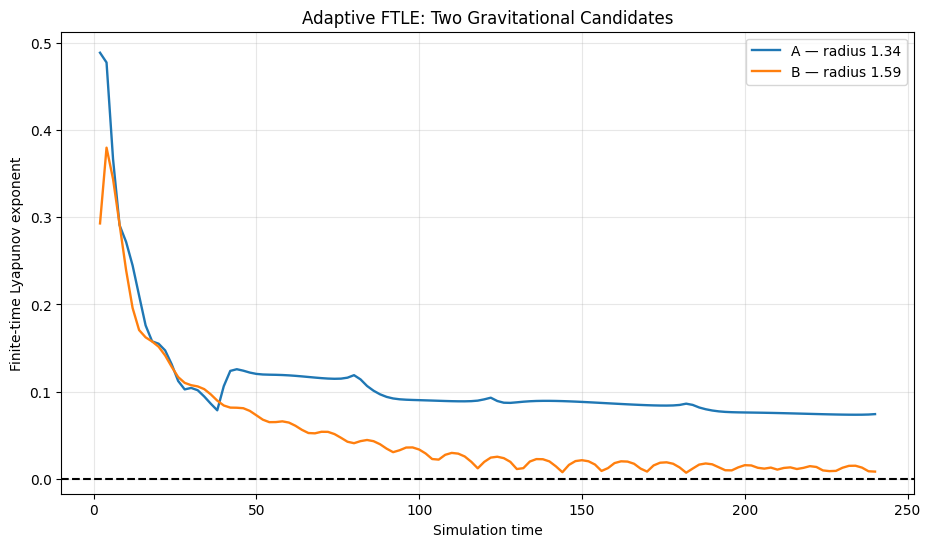

In [114]:

import matplotlib.pyplot as plt

candidate_configurations = {
    "A — radius 1.34": 1.34,
    "B — radius 1.59": 1.59
}

adaptive_ftle_results = {}

plt.figure(figsize=(11, 6))

for name, radius in candidate_configurations.items():

    r0, v0, masses = make_restricted_three_body(
        test_radius=radius,
        test_angle_deg=120.0,
        planet_mass=0.005
    )

    result = adaptive_ftle(
        r0,
        v0,
        masses,
        total_time=240.0,
        renorm_interval=2.0,
        rtol=1e-11,
        atol=1e-13,
        max_step=0.1
    )

    adaptive_ftle_results[name] = result

    plt.plot(
        result["time"],
        result["ftle"],
        label=name,
        linewidth=1.7
    )

    print("\n", name)
    print("-" * 45)

    for T in [60, 120, 180, 240]:
        idx = np.argmin(
            np.abs(result["time"] - T)
        )

        print(
            f"T={T:3d} | FTLE={result['ftle'][idx]:.8e}"
        )

    print(
        "Minimum sampled planet distance:",
        result["min_planet_distance"]
    )

    print(
        "Maximum sampled star distance:",
        result["max_star_distance"]
    )

plt.axhline(0, color="black", linestyle="--")

plt.xlabel("Simulation time")
plt.ylabel("Finite-time Lyapunov exponent")
plt.title("Adaptive FTLE: Two Gravitational Candidates")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


CANDIDATE A — NUMERICAL CONVERGENCE
-------------------------------------------------------
Original final FTLE: 0.07408404537342765
Refined final FTLE: 0.07408404703056513
Absolute difference: 1.6571374827911711e-09
Maximum difference over time: 1.6571374827911711e-09


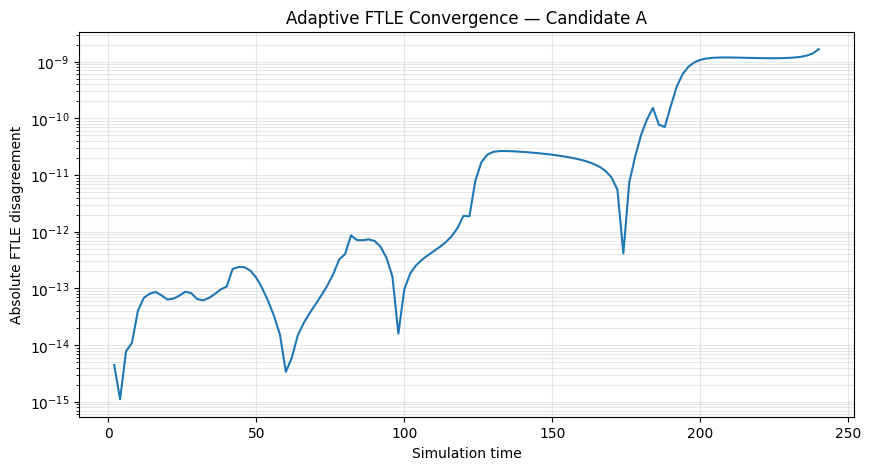

In [115]:

# Candidate A numerical convergence

rA, vA, mA = make_restricted_three_body(
    test_radius=1.34,
    test_angle_deg=120.0,
    planet_mass=0.005
)

refined_A = adaptive_ftle(
    rA, vA, mA,
    total_time=240.0,
    renorm_interval=2.0,
    rtol=1e-12,
    atol=1e-14,
    max_step=0.05
)

original_A = adaptive_ftle_results["A — radius 1.34"]

difference = np.abs(
    original_A["ftle"] - refined_A["ftle"]
)

print("CANDIDATE A — NUMERICAL CONVERGENCE")
print("-" * 55)

print("Original final FTLE:", original_A["ftle"][-1])
print("Refined final FTLE:", refined_A["ftle"][-1])
print("Absolute difference:", difference[-1])
print("Maximum difference over time:", difference.max())

plt.figure(figsize=(10, 5))

plt.semilogy(
    refined_A["time"],
    np.maximum(difference, 1e-16)
)

plt.xlabel("Simulation time")
plt.ylabel("Absolute FTLE disagreement")
plt.title("Adaptive FTLE Convergence — Candidate A")
plt.grid(alpha=0.3, which="both")
plt.show()



## 12.11 Long-term Lyapunov behavior

Our adaptive calculations produced two contrasting results.

Candidate A maintained a relatively high finite-time Lyapunov estimate through 240 simulation time units.

Candidate B showed a much stronger decline toward zero.

Now we will extend Candidate A to longer observation durations.

For a chaotic system, we may expect the finite-time Lyapunov estimate to approach a positive asymptotic value:

$$
\lambda_T\rightarrow\lambda_{\max}>0
$$

For many regular systems, the estimate approaches zero.

We will also calculate accumulated logarithmic perturbation growth:

$$
S(T)=T\lambda_T
$$

If the exponent approaches a positive constant, accumulated logarithmic growth eventually increases approximately linearly with time.

If perturbations grow algebraically, logarithmic growth is instead approximately proportional to $\ln T$.

These distinctions help us interpret the behavior beyond simply checking whether the FTLE is positive.

We must also monitor numerical accuracy and possible close encounters throughout the extended simulation.


LONG-TERM CANDIDATE A
------------------------------------------------------------
T = 120 | FTLE = 9.10373489e-02
T = 240 | FTLE = 7.40840454e-02
T = 360 | FTLE = 6.19879932e-02
T = 480 | FTLE = 5.68890676e-02
T = 600 | FTLE = 4.99142547e-02
T = 720 | FTLE = 4.40828598e-02

Minimum sampled planet distance: 0.14778248596547489
Maximum sampled star distance: 15.402075021107512


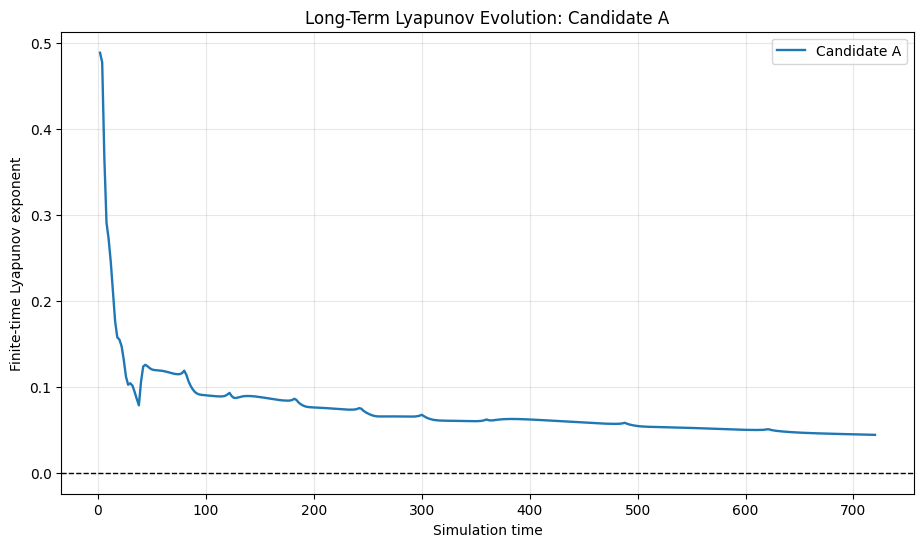

In [116]:

import numpy as np
import matplotlib.pyplot as plt

# Original high-sensitivity configuration
rA, vA, mA = make_restricted_three_body(
    test_radius=1.34,
    test_angle_deg=120.0,
    planet_mass=0.005
)

# Extend our simulation to 720 time units.
long_A = adaptive_ftle(
    rA,
    vA,
    mA,
    total_time=720.0,
    renorm_interval=2.0,
    rtol=1e-11,
    atol=1e-13,
    max_step=0.1
)

T_values = long_A["time"]
lambda_values = long_A["ftle"]

print("LONG-TERM CANDIDATE A")
print("-" * 60)

for T in [120, 240, 360, 480, 600, 720]:

    idx = np.argmin(np.abs(T_values - T))

    print(
        f"T = {T:3d} | "
        f"FTLE = {lambda_values[idx]:.8e}"
    )

print(
    "\nMinimum sampled planet distance:",
    long_A["min_planet_distance"]
)

print(
    "Maximum sampled star distance:",
    long_A["max_star_distance"]
)

plt.figure(figsize=(11, 6))

plt.plot(
    T_values,
    lambda_values,
    linewidth=1.7,
    label="Candidate A"
)

plt.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Simulation time")
plt.ylabel("Finite-time Lyapunov exponent")
plt.title("Long-Term Lyapunov Evolution: Candidate A")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


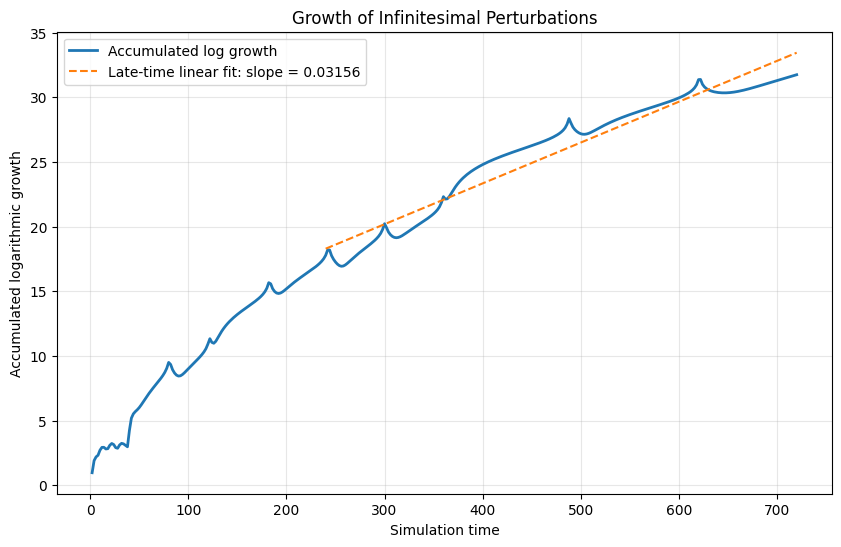

Late-time fitted growth slope: 0.031558611312901434
FTLE at T = 720: 0.04408285980892769


In [117]:

# Accumulated logarithmic perturbation growth
log_growth = T_values * lambda_values

# Compare the later-time behavior with a straight line.
late_mask = T_values >= 240

slope, intercept = np.polyfit(
    T_values[late_mask],
    log_growth[late_mask],
    1
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    T_values,
    log_growth,
    linewidth=2,
    label="Accumulated log growth"
)

ax.plot(
    T_values[late_mask],
    slope * T_values[late_mask] + intercept,
    "--",
    label=f"Late-time linear fit: slope = {slope:.5f}"
)

ax.set_xlabel("Simulation time")
ax.set_ylabel("Accumulated logarithmic growth")
ax.set_title("Growth of Infinitesimal Perturbations")

ax.legend()
ax.grid(alpha=0.3)

plt.show()

print("Late-time fitted growth slope:", slope)
print("FTLE at T = 720:", lambda_values[-1])



## 12.13 Distinguishing sustained chaos from transient scattering

Candidate A exhibits substantial perturbation amplification over 720 simulation time units.

The accumulated logarithmic growth is approximately linear over part of the trajectory, suggesting sustained exponential sensitivity during that interval.

However, the test particle may undergo:

- Close planetary encounters
- Large orbital excursions
- Temporary trapping
- Gravitational scattering or escape

These events can complicate the interpretation of finite-time Lyapunov estimates.

We will therefore examine the physical trajectory throughout the entire 720-unit interval.

We will monitor the test particle's distance from the star, distance from the perturbing planet, and star-relative specific orbital energy.

If the trajectory remains bounded-looking and its positive Lyapunov behavior survives further validation, it becomes a stronger chaotic benchmark.

If the particle escapes, we will study it as a scattering case rather than automatically labeling it a bounded chaotic orbit.


LONG-TERM ORBITAL DIAGNOSTICS
-------------------------------------------------------
Minimum planet distance: 0.14774137685471608
Maximum star distance: 15.49639824015419
Final star distance: 14.434606767619751
Final star-relative energy: -0.05947193695129048


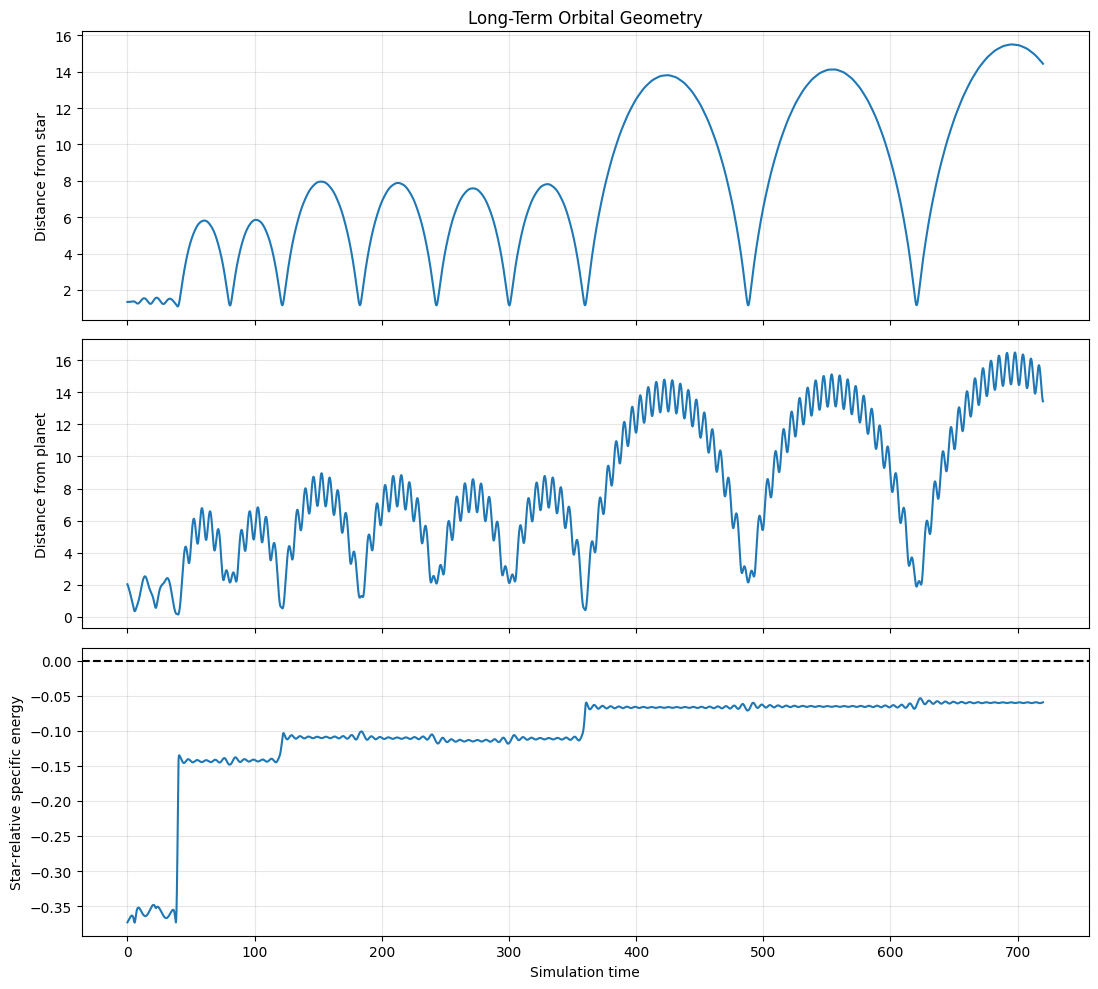

In [118]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Candidate A
rA, vA, mA = make_restricted_three_body(
    test_radius=1.34,
    test_angle_deg=120.0,
    planet_mass=0.005
)

n = len(mA)

y0 = np.concatenate([
    rA.ravel(),
    vA.ravel()
])

T_final = 720.0

t_eval = np.linspace(0, T_final, 7201)

sol = solve_ivp(
    three_body_rhs,
    (0.0, T_final),
    y0,
    args=(mA,),
    method="DOP853",
    t_eval=t_eval,
    rtol=1e-11,
    atol=1e-13,
    max_step=0.1
)

if not sol.success:
    raise RuntimeError(sol.message)

p = sol.y[:2*n].T.reshape(-1, n, 2)
v = sol.y[2*n:].T.reshape(-1, n, 2)

# Test-particle distances
d_star = np.linalg.norm(
    p[:, 2] - p[:, 0], axis=1
)

d_planet = np.linalg.norm(
    p[:, 2] - p[:, 1], axis=1
)

# Star-relative speed and specific Keplerian energy
relative_velocity = v[:, 2] - v[:, 0]

speed_squared = np.sum(
    relative_velocity**2, axis=1
)

specific_energy = (
    0.5 * speed_squared
    - G_value * mA[0] / d_star
)

print("LONG-TERM ORBITAL DIAGNOSTICS")
print("-" * 55)
print("Minimum planet distance:", d_planet.min())
print("Maximum star distance:", d_star.max())
print("Final star distance:", d_star[-1])
print("Final star-relative energy:", specific_energy[-1])

fig, axes = plt.subplots(
    3, 1, figsize=(11, 10),
    sharex=True
)

axes[0].plot(sol.t, d_star)
axes[0].set_ylabel("Distance from star")
axes[0].set_title("Long-Term Orbital Geometry")

axes[1].plot(sol.t, d_planet)
axes[1].set_ylabel("Distance from planet")

axes[2].plot(sol.t, specific_energy)
axes[2].axhline(0, color="black", linestyle="--")
axes[2].set_ylabel("Star-relative specific energy")
axes[2].set_xlabel("Simulation time")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


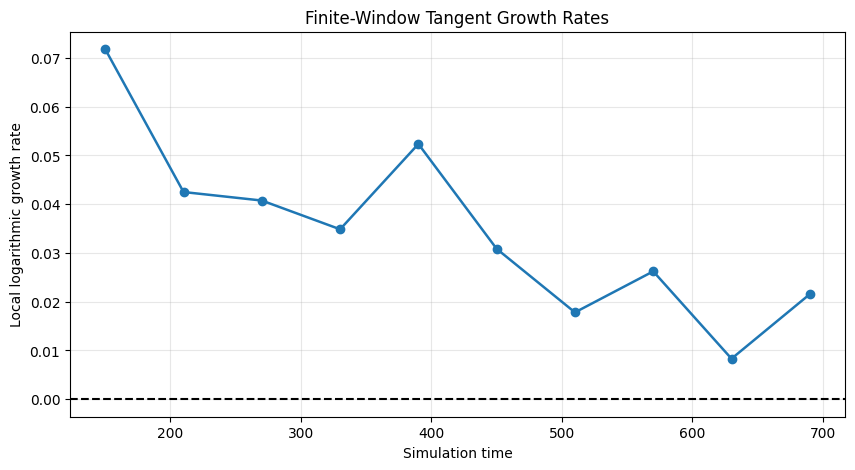

LOCAL GROWTH RATES
---------------------------------------------
T=150 | rate=0.071773
T=210 | rate=0.042488
T=270 | rate=0.040745
T=330 | rate=0.034847
T=390 | rate=0.052345
T=450 | rate=0.030840
T=510 | rate=0.017808
T=570 | rate=0.026222
T=630 | rate=0.008310
T=690 | rate=0.021542


In [119]:

# Uses T_values and lambda_values from Objective 12.11

S = T_values * lambda_values

# Estimate logarithmic growth over consecutive
# non-overlapping 60-unit windows.
window_edges = np.arange(120, 721, 60)

window_midpoints = []
window_growth_rates = []

for start, end in zip(
    window_edges[:-1],
    window_edges[1:]
):

    S_start = np.interp(start, T_values, S)
    S_end = np.interp(end, T_values, S)

    local_rate = (S_end - S_start) / (end - start)

    window_midpoints.append((start + end) / 2)
    window_growth_rates.append(local_rate)

plt.figure(figsize=(10, 5))

plt.plot(
    window_midpoints,
    window_growth_rates,
    "o-",
    linewidth=1.8
)

plt.axhline(
    0, color="black", linestyle="--"
)

plt.xlabel("Simulation time")
plt.ylabel("Local logarithmic growth rate")
plt.title("Finite-Window Tangent Growth Rates")
plt.grid(alpha=0.3)

plt.show()

print("LOCAL GROWTH RATES")
print("-" * 45)

for t, value in zip(
    window_midpoints,
    window_growth_rates
):
    print(f"T={t:.0f} | rate={value:.6f}")



## 12.15 The Jacobi Constant

In the circular restricted three-body problem, the star and massive planet orbit their common center of mass at a constant angular speed.

The massless test particle moves in their gravitational field.

In an inertial reference frame, the gravitational potential experienced by the test particle changes with time as the massive bodies rotate.

However, in a coordinate system rotating together with the massive bodies, the gravitational potential becomes stationary.

In this rotating frame, there is a conserved quantity called the Jacobi constant.

It is defined by:

$$
C_J=2\Omega-v_{\mathrm{rot}}^2
$$

where the effective potential is:

$$
\Omega=
\frac{Gm_1}{r_1}
+\frac{Gm_2}{r_2}
+\frac12\omega^2(x^2+y^2)
$$

Here:

- $m_1$ and $m_2$ are the masses of the two massive bodies.
- $r_1$ and $r_2$ are the test particle's distances from them.
- $\omega$ is their constant orbital angular frequency.
- $x,y$ are the test particle's coordinates in the rotating barycentric frame.
- $v_{\mathrm{rot}}$ is its speed in that frame.

For the exact circular restricted three-body equations:

$$
\boxed{C_J(t)=C_J(0)}
$$

Unlike star-relative orbital energy, the Jacobi constant should remain conserved even when the test particle undergoes large radial excursions.

We will calculate its numerical drift throughout Candidate A's 720-unit simulation.


JACOBI CONSERVATION
-------------------------------------------------------
Initial Jacobi constant: 3.078858960129
Final Jacobi constant:   3.078858960130
Maximum absolute drift: 3.358203e-12
Maximum relative drift: 1.090730e-12


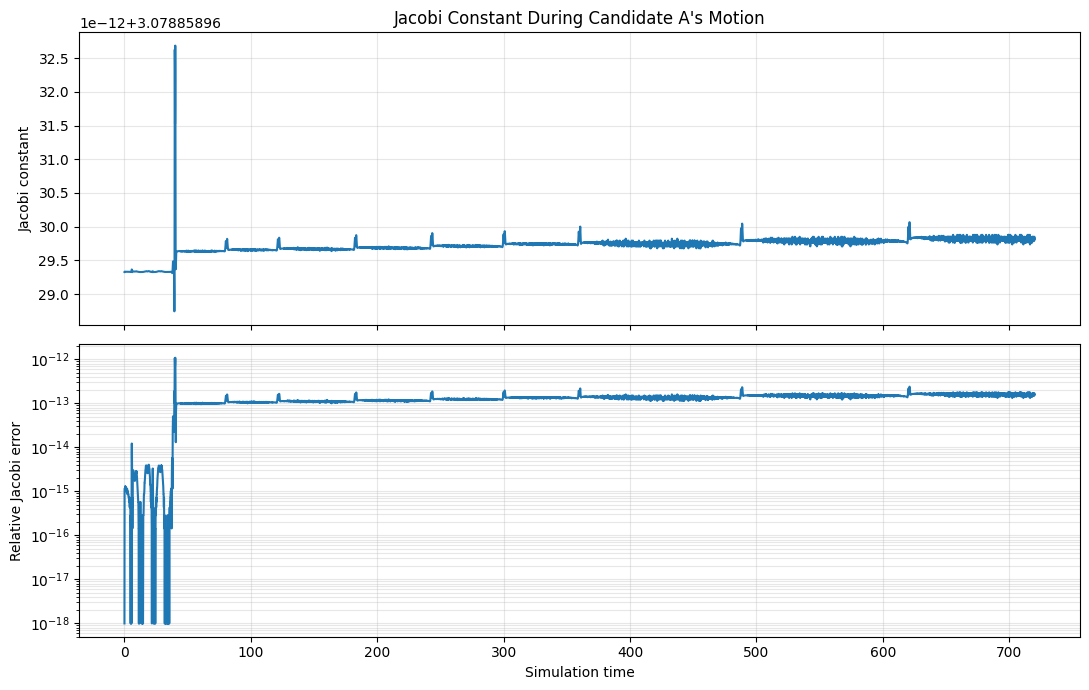

In [120]:

import numpy as np
import matplotlib.pyplot as plt

# Masses of the star and perturbing planet
m1, m2 = mA[0], mA[1]

# The initial separation of the two massive bodies
a_primary = np.linalg.norm(rA[1] - rA[0])

# Angular frequency of their circular binary orbit
omega = np.sqrt(
    G_value * (m1 + m2) / a_primary**3
)

# Test-particle inertial position and velocity
r_test = p[:, 2, :]
v_test = v[:, 2, :]

# Distances to both massive bodies
d1 = np.linalg.norm(p[:, 2, :] - p[:, 0, :], axis=1)
d2 = np.linalg.norm(p[:, 2, :] - p[:, 1, :], axis=1)

# Rotating-frame velocity:
# v_rot = v_inertial - omega x r
rotation_velocity = omega * np.column_stack([
    -r_test[:, 1],
     r_test[:, 0]
])

v_rot = v_test - rotation_velocity

# Squared speed is unchanged by rotating the axes
v_rot_sq = np.sum(v_rot**2, axis=1)

# Effective potential
Omega = (
    G_value * m1 / d1
    + G_value * m2 / d2
    + 0.5 * omega**2 * np.sum(r_test**2, axis=1)
)

# Jacobi constant
C_J = 2 * Omega - v_rot_sq

# Numerical conservation error
jacobi_error = np.abs(C_J - C_J[0])

relative_jacobi_error = jacobi_error / abs(C_J[0])

print("JACOBI CONSERVATION")
print("-" * 55)

print(f"Initial Jacobi constant: {C_J[0]:.12f}")
print(f"Final Jacobi constant:   {C_J[-1]:.12f}")

print(f"Maximum absolute drift: {jacobi_error.max():.6e}")
print(f"Maximum relative drift: {relative_jacobi_error.max():.6e}")

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(sol.t, C_J)
axes[0].set_ylabel("Jacobi constant")
axes[0].set_title("Jacobi Constant During Candidate A's Motion")

axes[1].semilogy(
    sol.t,
    np.maximum(relative_jacobi_error, 1e-18)
)
axes[1].set_ylabel("Relative Jacobi error")
axes[1].set_xlabel("Simulation time")

for ax in axes:
    ax.grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()



## 12.17 Long-Term Numerical Convergence of the Lyapunov Exponent

Candidate A has demonstrated sustained finite-time perturbation amplification over 720 simulation time units.

Its Jacobi constant also remains conserved to high numerical precision.

However, conservation alone is not enough to establish the reliability of the calculated Lyapunov exponent.

We will now repeat the entire 720-unit calculation using tighter adaptive integration settings.

We will compare:

1. The FTLE at different observation times.
2. The disagreement between the two FTLE histories.
3. The average logarithmic growth rates during the later portion of the simulation.

If the results remain consistent under numerical refinement, we can treat Candidate A as a numerically validated finite-time chaos candidate.

A positive asymptotic Lyapunov exponent would still require stronger long-time evidence.


In [121]:

import numpy as np
import matplotlib.pyplot as plt

# Original result from Objective 12.11:
# long_A

rA, vA, mA = make_restricted_three_body(
    test_radius=1.34,
    test_angle_deg=120.0,
    planet_mass=0.005
)

# More accurate adaptive integration
long_A_refined = adaptive_ftle(
    rA,
    vA,
    mA,
    total_time=720.0,
    renorm_interval=2.0,
    rtol=1e-12,
    atol=1e-14,
    max_step=0.05
)

# Extract FTLE histories
t_original = long_A["time"]
ftle_original = long_A["ftle"]

t_refined = long_A_refined["time"]
ftle_refined = long_A_refined["ftle"]

# Ensure that the output times agree
assert np.allclose(t_original, t_refined)

# Numerical discrepancy
ftle_difference = np.abs(
    ftle_original - ftle_refined
)

print("LONG-TERM FTLE CONVERGENCE")
print("=" * 65)

for T in [120, 240, 360, 480, 600, 720]:

    idx = np.argmin(np.abs(t_refined - T))

    print(
        f"T={T:3d} | "
        f"Original={ftle_original[idx]:.8e} | "
        f"Refined={ftle_refined[idx]:.8e} | "
        f"Difference={ftle_difference[idx]:.3e}"
    )

print("\nMaximum FTLE disagreement:",
      ftle_difference.max())

print("Final FTLE disagreement:",
      ftle_difference[-1])


LONG-TERM FTLE CONVERGENCE
T=120 | Original=9.10373489e-02 | Refined=9.10373489e-02 | Difference=1.905e-12
T=240 | Original=7.40840454e-02 | Refined=7.40840470e-02 | Difference=1.657e-09
T=360 | Original=6.19879932e-02 | Refined=6.19880722e-02 | Difference=7.896e-08
T=480 | Original=5.68890676e-02 | Refined=5.68867780e-02 | Difference=2.290e-06
T=600 | Original=4.99142547e-02 | Refined=4.98789546e-02 | Difference=3.530e-05
T=720 | Original=4.40828598e-02 | Refined=4.68928011e-02 | Difference=2.810e-03

Maximum FTLE disagreement: 0.002809941311786565
Final FTLE disagreement: 0.002809941311786565


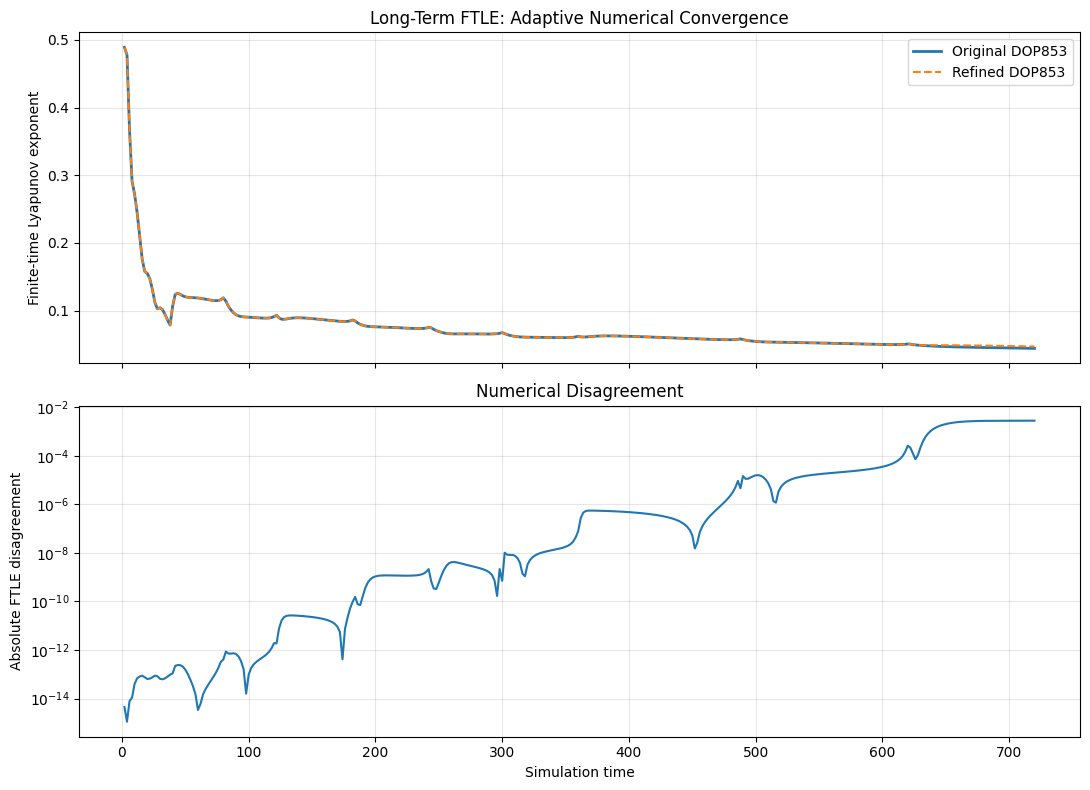

In [122]:

fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 8),
    sharex=True
)

# Compare complete FTLE histories
axes[0].plot(
    t_original,
    ftle_original,
    label="Original DOP853",
    linewidth=2
)

axes[0].plot(
    t_refined,
    ftle_refined,
    "--",
    label="Refined DOP853",
    linewidth=1.5
)

axes[0].set_ylabel("Finite-time Lyapunov exponent")
axes[0].set_title(
    "Long-Term FTLE: Adaptive Numerical Convergence"
)
axes[0].legend()

# Plot disagreement
axes[1].semilogy(
    t_refined,
    np.maximum(ftle_difference, 1e-18),
    linewidth=1.5
)

axes[1].set_xlabel("Simulation time")
axes[1].set_ylabel("Absolute FTLE disagreement")
axes[1].set_title("Numerical Disagreement")

for ax in axes:
    ax.grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()


In [123]:

# Calculate accumulated logarithmic growth
S_original = t_original * ftle_original
S_refined = t_refined * ftle_refined

windows = [
    (120, 240),
    (240, 360),
    (360, 480),
    (480, 600),
    (600, 720)
]

print("LATE-TIME LOGARITHMIC GROWTH")
print("=" * 65)

for start, end in windows:

    g_original = (
        np.interp(end, t_original, S_original)
        - np.interp(start, t_original, S_original)
    ) / (end - start)

    g_refined = (
        np.interp(end, t_refined, S_refined)
        - np.interp(start, t_refined, S_refined)
    ) / (end - start)

    print(
        f"T={start:3d}-{end:3d} | "
        f"Original={g_original:.6f} | "
        f"Refined={g_refined:.6f} | "
        f"Difference={abs(g_original-g_refined):.3e}"
    )


LATE-TIME LOGARITHMIC GROWTH
T=120-240 | Original=0.057131 | Refined=0.057131 | Difference=3.312e-09
T=240-360 | Original=0.037796 | Refined=0.037796 | Difference=2.336e-07
T=360-480 | Original=0.041592 | Refined=0.041583 | Difference=9.395e-06
T=480-600 | Original=0.022015 | Refined=0.021848 | Difference=1.673e-04
T=600-720 | Original=0.014926 | Refined=0.031962 | Difference=1.704e-02



## 12.19 Trajectory divergence under adaptive refinement

Our two adaptive FTLE calculations agree closely at early times but begin to disagree more substantially over the full 720-unit integration.

We now need to determine whether the underlying trajectories also diverge.

We will integrate Candidate A using two different adaptive tolerance settings and compare its star-relative positions at identical physical times.

The purpose is to distinguish between:

1. A physically sensitive system in which tiny numerical differences grow over time.
2. A numerical solution that has not yet adequately resolved important gravitational interactions.

We will measure the absolute trajectory disagreement, the maximum star-relative distance, and the minimum sampled distance to the perturbing planet.

This experiment will not by itself prove chaos, but it will help us understand the source of the late-time FTLE disagreement.


LONG-TERM TRAJECTORY AGREEMENT
-------------------------------------------------------
T=120 | Position disagreement=1.79984787e-09
T=240 | Position disagreement=1.77468107e-06
T=360 | Position disagreement=1.43277824e-04
T=480 | Position disagreement=2.48408772e-02
T=600 | Position disagreement=3.47138929e-01
T=720 | Position disagreement=6.65296325e+00


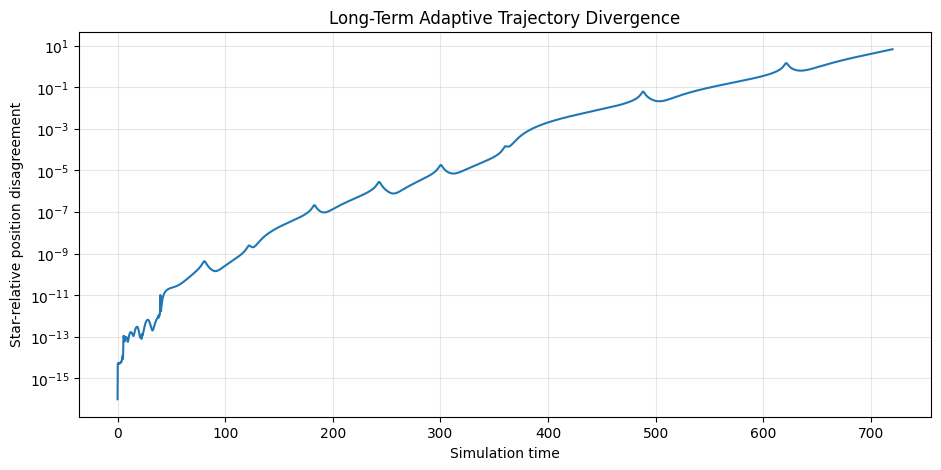

In [124]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

rA, vA, mA = make_restricted_three_body(
    test_radius=1.34,
    test_angle_deg=120.0,
    planet_mass=0.005
)

n = len(mA)

y0 = np.concatenate([
    rA.ravel(),
    vA.ravel()
])

T_final = 720.0

common_times = np.linspace(
    0, T_final, 3601
)

settings = [
    ("Original", 1e-11, 1e-13, 0.1),
    ("Refined", 1e-12, 1e-14, 0.05)
]

physical_solutions = {}

for name, rtol, atol, max_step in settings:

    sol = solve_ivp(
        three_body_rhs,
        (0.0, T_final),
        y0,
        args=(mA,),
        method="DOP853",
        t_eval=common_times,
        rtol=rtol,
        atol=atol,
        max_step=max_step
    )

    if not sol.success:
        raise RuntimeError(sol.message)

    positions = (
        sol.y[:2*n].T.reshape(-1, n, 2)
    )

    physical_solutions[name] = positions

# Relative test-particle positions
p_original = physical_solutions["Original"]
p_refined = physical_solutions["Refined"]

q_original = p_original[:, 2] - p_original[:, 0]
q_refined = p_refined[:, 2] - p_refined[:, 0]

trajectory_disagreement = np.linalg.norm(
    q_original - q_refined,
    axis=1
)

print("LONG-TERM TRAJECTORY AGREEMENT")
print("-" * 55)

for T in [120, 240, 360, 480, 600, 720]:

    idx = np.argmin(
        np.abs(common_times - T)
    )

    print(
        f"T={T:3d} | "
        f"Position disagreement="
        f"{trajectory_disagreement[idx]:.8e}"
    )

plt.figure(figsize=(11, 5))

plt.semilogy(
    common_times,
    np.maximum(trajectory_disagreement, 1e-16),
    linewidth=1.5
)

plt.xlabel("Simulation time")
plt.ylabel("Star-relative position disagreement")
plt.title("Long-Term Adaptive Trajectory Divergence")
plt.grid(alpha=0.3, which="both")
plt.show()



## 12.20 Measuring exponential error amplification

Our adaptive integrations start from identical initial conditions but accumulate slightly different numerical errors.

Their positional disagreement grows dramatically over time.

If the disagreement grows approximately exponentially during a particular interval, we expect:

$$
D(t)\approx D_0e^{\gamma t}
$$

Taking logarithms:

$$
\ln D(t)\approx\ln D_0+\gamma t
$$

This means that plotting the natural logarithm of the disagreement against time may reveal an approximately linear region.

The slope $\gamma$ measures the observed rate at which numerical trajectory discrepancies grow.

However, this slope is not automatically the maximal Lyapunov exponent. Numerical error is introduced continuously during integration, and the discrepancy may reflect transient encounters or other dynamical effects.

We will also calculate when the numerical discrepancy first exceeds selected agreement thresholds.


NUMERICAL DISCREPANCY GROWTH
-------------------------------------------------------
Estimated growth rate: 0.044602
Log-space R-squared:    0.980878
Discrepancy doubling time: 15.541


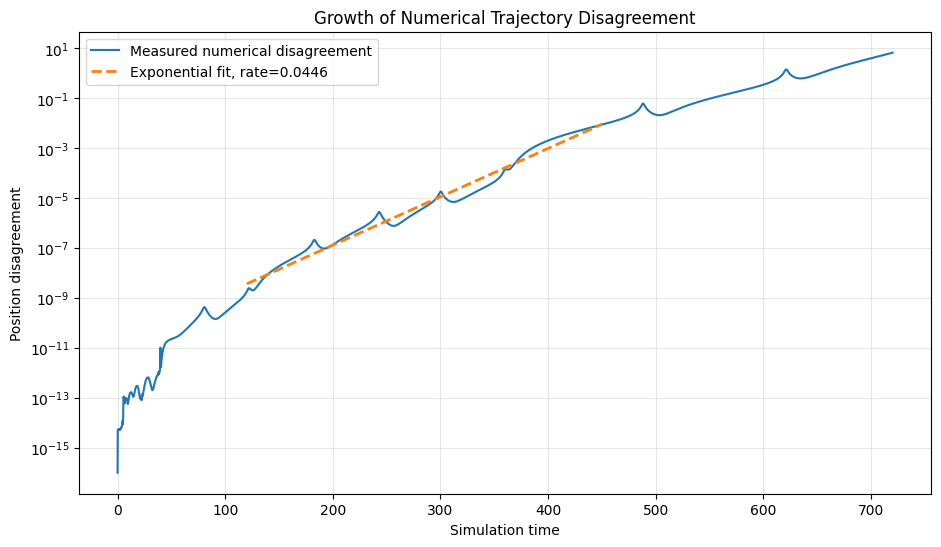

In [125]:

import numpy as np
import matplotlib.pyplot as plt

t = np.asarray(common_times)
D = np.asarray(trajectory_disagreement)

# Fit a region where disagreement remains
# well above roundoff but below orbital-scale separation.
#
# Restrict to a fixed time window to avoid combining
# many distinct dynamical phases.
fit_mask = (
    (t >= 120.0) &
    (t <= 450.0) &
    (D > 1e-10) &
    (D < 1e-2) &
    np.isfinite(D)
)

if np.count_nonzero(fit_mask) < 10:
    raise ValueError(
        "Not enough points for a reliable growth-rate fit."
    )

# Exponential growth appears linear in ln(D).
slope, intercept = np.polyfit(
    t[fit_mask],
    np.log(D[fit_mask]),
    1
)

predicted_log_D = slope * t[fit_mask] + intercept

# Goodness of fit in log space.
observed_log_D = np.log(D[fit_mask])

ss_res = np.sum(
    (observed_log_D - predicted_log_D)**2
)

ss_tot = np.sum(
    (observed_log_D - observed_log_D.mean())**2
)

r_squared = 1 - ss_res / ss_tot

print("NUMERICAL DISCREPANCY GROWTH")
print("-" * 55)

print(f"Estimated growth rate: {slope:.6f}")
print(f"Log-space R-squared:    {r_squared:.6f}")

if slope > 0:
    print(
        f"Discrepancy doubling time: "
        f"{np.log(2)/slope:.3f}"
    )

plt.figure(figsize=(11, 6))

plt.semilogy(
    t,
    np.maximum(D, 1e-16),
    label="Measured numerical disagreement"
)

plt.semilogy(
    t[fit_mask],
    np.exp(predicted_log_D),
    "--",
    linewidth=2,
    label=f"Exponential fit, rate={slope:.4f}"
)

plt.xlabel("Simulation time")
plt.ylabel("Position disagreement")
plt.title("Growth of Numerical Trajectory Disagreement")
plt.legend()
plt.grid(alpha=0.3, which="both")
plt.show()


In [126]:

thresholds = [
    1e-8,
    1e-6,
    1e-4,
    1e-2,
    1e-1,
    1.0
]

print("NUMERICAL AGREEMENT HORIZONS")
print("=" * 55)

for threshold in thresholds:

    crossing_indices = np.flatnonzero(
        D >= threshold
    )

    if len(crossing_indices) == 0:
        print(
            f"Threshold {threshold:.0e}: "
            "not reached"
        )
    else:
        crossing_time = t[crossing_indices[0]]

        print(
            f"Threshold {threshold:.0e}: "
            f"first crossed at t={crossing_time:.2f}"
        )


NUMERICAL AGREEMENT HORIZONS
Threshold 1e-08: first crossed at t=141.00
Threshold 1e-06: first crossed at t=234.40
Threshold 1e-04: first crossed at t=358.00
Threshold 1e-02: first crossed at t=455.20
Threshold 1e-01: first crossed at t=551.60
Threshold 1e+00: first crossed at t=618.60



# Objective 13 — Numerical Artifacts and Gravitational Chaos Classification

## 13.1 The central research question

Can a numerical integration algorithm create misleading evidence of chaos in a gravitational system that is physically regular, or conceal chaotic sensitivity in a system that exhibits it?

We have already discovered that poorly resolved integration can produce false planetary ejections, enormous trajectory errors, and inaccurate measurements of infinitesimal perturbation growth.

We now combine those findings into a controlled comparison.

## The three gravitational benchmarks

### Benchmark A — Analytically regular two-body system

A star and planet follow a circular Newtonian orbit.

The exact two-body problem is integrable, and its maximal Lyapunov exponent is zero for the bound, collision-free system.

This is our known regular control.

### Benchmark B — Weakly perturbed three-body system

A star, perturbing planet, and massless test particle begin with:

- Perturbing planet mass: 0.001
- Test-particle radius: 1.40
- Initial angle: 120 degrees

Earlier calculations showed decreasing finite-time Lyapunov estimates and relatively regular-looking orbital motion.

This remains a regular-motion candidate, not an analytically proven regular orbit.

### Benchmark C — Strongly sensitive three-body system

We use:

- Perturbing planet mass: 0.005
- Test-particle radius: 1.34
- Initial angle: 120 degrees

Earlier adaptive simulations showed sustained finite-time perturbation amplification and exponential-like growth of trajectory discrepancies.

This is our strong chaos candidate, not an established asymptotic-chaos benchmark.

## The four numerical integrators

We will compare:

1. Forward Euler — first-order, nonsymplectic.
2. Leapfrog — second-order, symplectic.
3. Fourth-order Runge–Kutta — fourth-order, nonsymplectic.
4. Adaptive DOP853 — high-order reference integration.

All methods will evolve the physical positions and velocities together with their linearized variational perturbations.

For Leapfrog, the tangent perturbations must follow the linearization of the same kick-drift-kick updates used for the physical orbit.

## Measuring sensitivity

For the complete phase-space perturbation:

$$
\delta X=(\delta\mathbf r,\delta\mathbf v)
$$

we use the norm:

$$
\|\delta X\|=
\sqrt{\sum_i\left(
|\delta\mathbf r_i|^2+
T_*^2|\delta\mathbf v_i|^2
\right)}
$$

with $T_*=1$ in normalized units.

The finite-time Lyapunov estimate is calculated using periodic renormalization:

$$
\lambda_T=\frac{1}{T}\sum_k\ln g_k
$$

where $g_k$ is the tangent-vector growth during each renormalization interval.

We evaluate the estimates at:

$$
T=120,\quad240
$$

and test the fixed numerical timesteps:

$$
\Delta t=0.02,\quad0.10,\quad0.25
$$

These fixed timesteps divide the renormalization interval exactly, ensuring consistent observation times.

## What constitutes numerical contamination?

For each benchmark, we compare a fixed-step estimate against DOP853 at the same observation duration.

The absolute FTLE disagreement is:

$$
\epsilon_\lambda=
|\lambda_{\mathrm{fixed}}-\lambda_{\mathrm{reference}}|
$$

We also record the disagreement in the physical state, alongside geometric diagnostics.

A large FTLE disagreement demonstrates numerical contamination of the sensitivity estimate.

It does not automatically establish a false chaos classification.

## Classification principles

We will distinguish:

**Known regular:** Established independently by mathematical theory.

**Regular-looking:** Finite-time exponent decreases with increasing observation duration, without conclusive asymptotic evidence.

**Chaos candidate:** Sustained positive finite-time growth supported by numerical convergence.

**Unresolved:** Numerical disagreement, encounters, escape, or insufficient observation time prevent reliable classification.

Our primary goal is to determine whether numerical inaccuracy changes the apparent dynamical behavior, and whether the resulting errors can be detected through refinement and physical diagnostics.

## Expected research outputs

The experiment will produce:

- A comparison table of FTLE values for all systems and methods.
- Absolute FTLE errors relative to DOP853.
- Physical-state disagreements.
- A plot comparing the numerical methods.
- A plot showing how FTLE error depends on timestep.
- A summary identifying numerically unreliable calculations.

The resulting evidence will help us determine when numerical integration errors can be mistaken for genuine gravitational instability.


RUNNING ADAPTIVE REFERENCES
Reference: Two-body regular
Reference: Three-body regular candidate
Reference: Three-body chaos candidate

FIXED-STEP INTEGRATOR COMPARISON
Two-body regular | Euler | dt=0.02
Two-body regular | Euler | dt=0.1
Two-body regular | Euler | dt=0.25
Two-body regular | Leapfrog | dt=0.02
Two-body regular | Leapfrog | dt=0.1
Two-body regular | Leapfrog | dt=0.25
Two-body regular | RK4 | dt=0.02
Two-body regular | RK4 | dt=0.1
Two-body regular | RK4 | dt=0.25
Three-body regular candidate | Euler | dt=0.02
Three-body regular candidate | Euler | dt=0.1
Three-body regular candidate | Euler | dt=0.25
Three-body regular candidate | Leapfrog | dt=0.02
Three-body regular candidate | Leapfrog | dt=0.1
Three-body regular candidate | Leapfrog | dt=0.25
Three-body regular candidate | RK4 | dt=0.02
Three-body regular candidate | RK4 | dt=0.1
Three-body regular candidate | RK4 | dt=0.25
Three-body chaos candidate | Euler | dt=0.02
Three-body chaos candidate | Euler | dt=0.1
Three

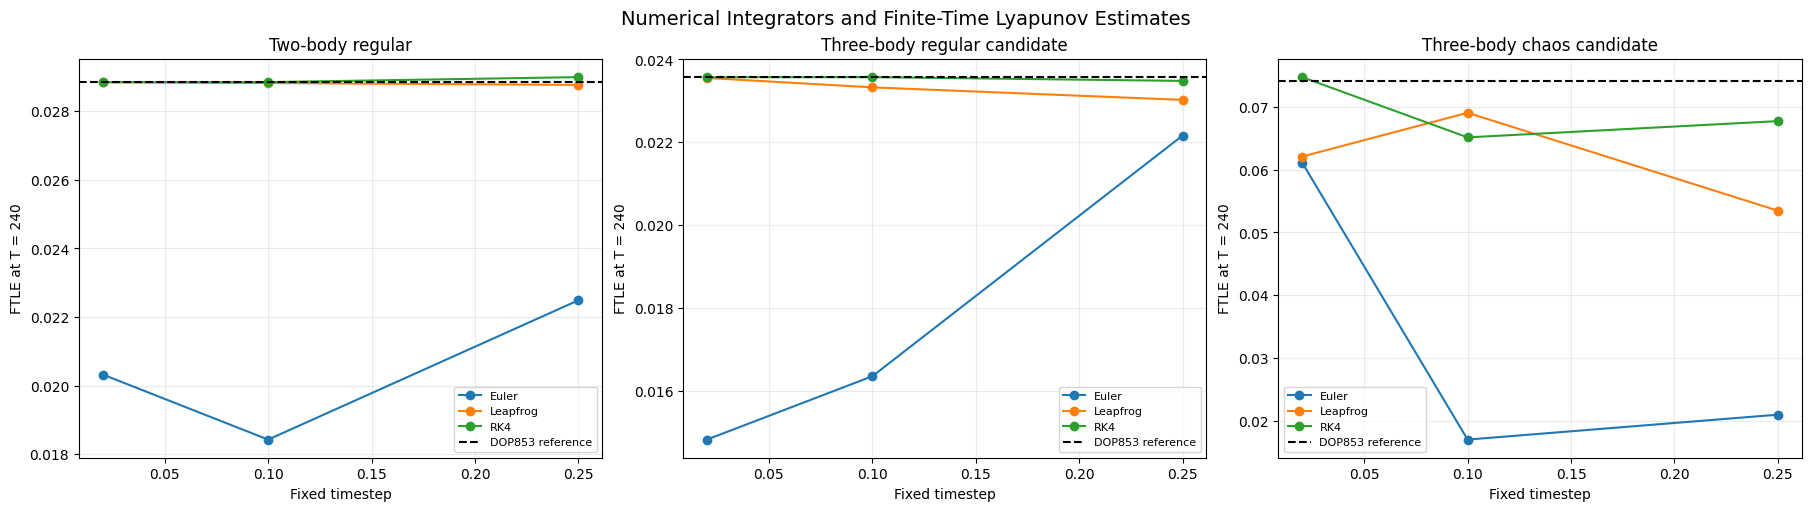

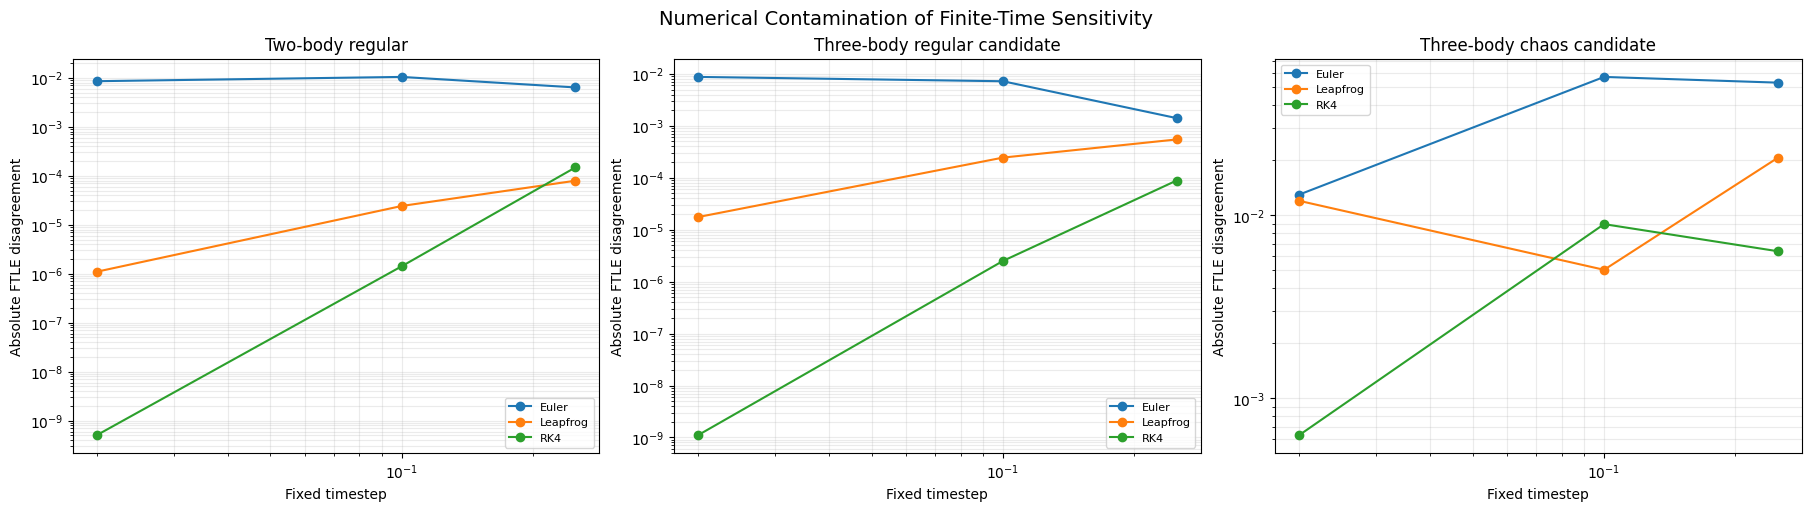


NUMERICAL RELIABILITY SUMMARY
status                                   Unreliable  Within screening limits
system                       integrator                                     
Three-body chaos candidate   Euler                3                        0
                             Leapfrog             3                        0
                             RK4                  3                        0
Three-body regular candidate Euler                3                        0
                             Leapfrog             3                        0
                             RK4                  1                        2
Two-body regular             Euler                3                        0
                             Leapfrog             3                        0
                             RK4                  2                        1

IMPORTANT INTERPRETATION
---------------------------------------------------------------------------
1. The exact two-bod

In [ ]:

# ============================================================
# OBJECTIVE 13
# NUMERICAL ARTIFACTS AND GRAVITATIONAL CHAOS CLASSIFICATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

G = 1.0
T_SCALE = 1.0

TIMESTEPS = [0.02, 0.10, 0.25]
HORIZONS = [120.0, 240.0]
RENORM_TIME = 1.0


# ============================================================
# 1. GRAVITATIONAL EQUATIONS AND VARIATIONAL EQUATIONS
# ============================================================

def acceleration_and_variation(r, dr, masses):
    """
    Returns:
        a  = gravitational accelerations
        da = linearized gravitational accelerations
    """
    n = len(masses)

    a = np.zeros_like(r)
    da = np.zeros_like(r)

    for i in range(n):
        for j in range(n):

            if i == j or masses[j] == 0:
                continue

            R = r[j] - r[i]
            dR = dr[j] - dr[i]

            dist2 = np.dot(R, R)

            if dist2 < 1e-24:
                raise FloatingPointError(
                    "Near-collision singularity."
                )

            inv_r3 = dist2**(-1.5)
            inv_r5 = dist2**(-2.5)

            gm = G * masses[j]

            a[i] += gm * R * inv_r3

            da[i] += gm * (
                dR * inv_r3
                - 3 * np.dot(R, dR) * R * inv_r5
            )

    return a, da


def rhs_parts(r, v, dr, dv, masses):

    a, da = acceleration_and_variation(
        r, dr, masses
    )

    return v, a, dv, da


def tangent_norm(dr, dv):

    return np.sqrt(
        np.sum(dr**2)
        + T_SCALE**2 * np.sum(dv**2)
    )


# ============================================================
# 2. THREE FIXED-STEP INTEGRATORS
# ============================================================

def euler_step(r, v, dr, dv, m, h):

    a, da = acceleration_and_variation(r, dr, m)

    return (
        r + h*v,
        v + h*a,
        dr + h*dv,
        dv + h*da
    )


def leapfrog_step(r, v, dr, dv, m, h):
    """
    Kick-drift-kick leapfrog.

    Tangent equations follow the corresponding
    linearized kick-drift-kick map.
    """

    a, da = acceleration_and_variation(r, dr, m)

    v_half = v + 0.5*h*a
    dv_half = dv + 0.5*h*da

    r_new = r + h*v_half
    dr_new = dr + h*dv_half

    a_new, da_new = acceleration_and_variation(
        r_new, dr_new, m
    )

    v_new = v_half + 0.5*h*a_new
    dv_new = dv_half + 0.5*h*da_new

    return r_new, v_new, dr_new, dv_new


def rk4_step_full(r, v, dr, dv, m, h):

    state = (r, v, dr, dv)

    k1 = rhs_parts(*state, m)

    s2 = tuple(
        x + 0.5*h*k
        for x, k in zip(state, k1)
    )
    k2 = rhs_parts(*s2, m)

    s3 = tuple(
        x + 0.5*h*k
        for x, k in zip(state, k2)
    )
    k3 = rhs_parts(*s3, m)

    s4 = tuple(
        x + h*k
        for x, k in zip(state, k3)
    )
    k4 = rhs_parts(*s4, m)

    return tuple(
        x + h/6 * (a + 2*b + 2*c + d)
        for x, a, b, c, d in zip(
            state, k1, k2, k3, k4
        )
    )


INTEGRATORS = {
    "Euler": euler_step,
    "Leapfrog": leapfrog_step,
    "RK4": rk4_step_full
}


# ============================================================
# 3. CONSTRUCT THREE PHYSICAL BENCHMARKS
# ============================================================

def make_system(radius=None, planet_mass=0.001,
                angle_deg=120, two_body=False):

    m_star = 1.0
    m_planet = planet_mass

    masses = np.array(
        [m_star, m_planet]
        + ([] if two_body else [0.0])
    )

    M = m_star + m_planet
    omega = np.sqrt(G*M)

    r_star = np.array([-m_planet/M, 0.0])
    r_planet = np.array([m_star/M, 0.0])

    v_star = np.array([0.0, omega*r_star[0]])
    v_planet = np.array([0.0, omega*r_planet[0]])

    r = [r_star, r_planet]
    v = [v_star, v_planet]

    if not two_body:

        angle = np.deg2rad(angle_deg)

        direction = np.array([
            np.cos(angle), np.sin(angle)
        ])

        tangent = np.array([
            -np.sin(angle), np.cos(angle)
        ])

        r_test = r_star + radius*direction

        v_test = (
            v_star
            + np.sqrt(G*m_star/radius)*tangent
        )

        r.append(r_test)
        v.append(v_test)

    return (
        np.array(r, dtype=float),
        np.array(v, dtype=float),
        masses
    )


SYSTEMS = {
    "Two-body regular": make_system(two_body=True),

    "Three-body regular candidate": make_system(
        radius=1.40,
        planet_mass=0.001
    ),

    "Three-body chaos candidate": make_system(
        radius=1.34,
        planet_mass=0.005
    )
}


# ============================================================
# 4. STATE PACKING FOR ADAPTIVE DOP853
# ============================================================

def pack_state(r, v, dr, dv):

    return np.concatenate([
        r.ravel(), v.ravel(),
        dr.ravel(), dv.ravel()
    ])


def unpack_state(y, n):

    block = 2*n

    return (
        y[:block].reshape(n, 2).copy(),
        y[block:2*block].reshape(n, 2).copy(),
        y[2*block:3*block].reshape(n, 2).copy(),
        y[3*block:4*block].reshape(n, 2).copy()
    )


def combined_rhs(t, y, masses):

    r, v, dr, dv = unpack_state(
        y, len(masses)
    )

    return pack_state(
        *rhs_parts(r, v, dr, dv, masses)
    )


# ============================================================
# 5. COMMON FTLE SIMULATION ENGINE
# ============================================================

def run_experiment(system, method,
                   dt=None, total_time=240):

    r, v, masses = system
    r = r.copy()
    v = v.copy()

    n = len(masses)

    dr = np.zeros_like(r)
    dv = np.zeros_like(v)

    # Perturb the planet for two-body,
    # and the test particle for three-body.
    dr[-1, 0] = 1.0

    initial_tangent = tangent_norm(dr, dv)

    dr /= initial_tangent
    dv /= initial_tangent

    growth_sum = 0.0
    elapsed = 0.0

    records = []
    min_planet_distance = np.inf
    max_star_distance = 0.0

    if method != "DOP853":

        steps_per_block = int(
            round(RENORM_TIME/dt)
        )

        if not np.isclose(
            steps_per_block*dt, RENORM_TIME
        ):
            raise ValueError(
                "Timestep must divide renorm interval."
            )

    while elapsed < total_time - 1e-10:

        block_duration = min(
            RENORM_TIME,
            total_time - elapsed
        )

        if method == "DOP853":

            y0 = pack_state(r, v, dr, dv)

            sol = solve_ivp(
                combined_rhs,
                (elapsed, elapsed + block_duration),
                y0,
                args=(masses,),
                method="DOP853",
                rtol=1e-11,
                atol=1e-13,
                max_step=0.1
            )

            if not sol.success:
                raise RuntimeError(sol.message)

            # Geometry at accepted adaptive steps
            block_positions = (
                sol.y[:2*n].T.reshape(-1, n, 2)
            )

            if n == 3:
                distances = np.linalg.norm(
                    block_positions[:, 2]
                    - block_positions[:, 1],
                    axis=1
                )

                min_planet_distance = min(
                    min_planet_distance,
                    distances.min()
                )

                radii = np.linalg.norm(
                    block_positions[:, 2]
                    - block_positions[:, 0],
                    axis=1
                )

                max_star_distance = max(
                    max_star_distance,
                    radii.max()
                )

            r, v, dr, dv = unpack_state(
                sol.y[:, -1], n
            )

        else:

            step_function = INTEGRATORS[method]

            block_steps = int(
                round(block_duration/dt)
            )

            for _ in range(block_steps):

                r, v, dr, dv = step_function(
                    r, v, dr, dv, masses, dt
                )

                if not all(
                    np.all(np.isfinite(x))
                    for x in (r, v, dr, dv)
                ):
                    raise FloatingPointError(
                        "Nonfinite numerical state."
                    )

                if np.max(np.abs(r)) > 1e8:
                    raise FloatingPointError(
                        "Numerical trajectory diverged."
                    )

                if n == 3:

                    d = np.linalg.norm(r[2] - r[1])
                    radius = np.linalg.norm(r[2] - r[0])

                    min_planet_distance = min(
                        min_planet_distance, d
                    )

                    max_star_distance = max(
                        max_star_distance, radius
                    )

        growth = tangent_norm(dr, dv)

        if not np.isfinite(growth) or growth <= 0:
            raise FloatingPointError(
                "Invalid tangent growth."
            )

        growth_sum += np.log(growth)

        dr /= growth
        dv /= growth

        elapsed += block_duration

        if any(np.isclose(elapsed, T)
               for T in HORIZONS):

            # Compare physical state in star-relative
            # coordinates, removing common translation.
            q = r[1:] - r[0]
            u = v[1:] - v[0]

            records.append({
                "time": elapsed,
                "ftle": growth_sum/elapsed,
                "state": np.concatenate([
                    q.ravel(), u.ravel()
                ]),
                "min_planet_distance":
                    min_planet_distance,
                "max_star_distance":
                    max_star_distance
            })

    return records


# ============================================================
# 6. RUN ADAPTIVE REFERENCE SIMULATIONS
# ============================================================

reference_results = {}

print("=" * 65)
print("RUNNING ADAPTIVE REFERENCES")
print("=" * 65)

for system_name, system in SYSTEMS.items():

    print("Reference:", system_name)

    reference_results[system_name] = run_experiment(
        system,
        method="DOP853",
        total_time=max(HORIZONS)
    )


# ============================================================
# 7. RUN EULER, LEAPFROG, AND RK4
# ============================================================

all_records = []

print("\n" + "=" * 65)
print("FIXED-STEP INTEGRATOR COMPARISON")
print("=" * 65)

for system_name, system in SYSTEMS.items():

    reference_by_time = {
        int(x["time"]): x
        for x in reference_results[system_name]
    }

    # Include reference rows.
    for ref in reference_results[system_name]:

        all_records.append({
            "system": system_name,
            "integrator": "DOP853",
            "dt": np.nan,
            "T": ref["time"],
            "ftle": ref["ftle"],
            "ftle_error": 0.0,
            "relative_state_error": 0.0,
            "min_planet_distance":
                ref["min_planet_distance"],
            "max_star_distance":
                ref["max_star_distance"],
            "status": "Reference"
        })

    for method in INTEGRATORS:

        for dt in TIMESTEPS:

            print(
                f"{system_name} | {method} | dt={dt}"
            )

            try:

                output = run_experiment(
                    system,
                    method=method,
                    dt=dt,
                    total_time=max(HORIZONS)
                )

                for result in output:

                    T = int(result["time"])
                    ref = reference_by_time[T]

                    ftle_error = abs(
                        result["ftle"] - ref["ftle"]
                    )

                    state_error = np.linalg.norm(
                        result["state"] - ref["state"]
                    ) / max(
                        np.linalg.norm(ref["state"]),
                        1e-15
                    )

                    # Screening rule only, NOT a
                    # physical chaos classification.
                    rate_limit = max(
                        0.005,
                        0.10*abs(ref["ftle"])
                    )

                    unreliable = (
                        ftle_error > rate_limit
                        or state_error > 0.01
                    )

                    all_records.append({
                        "system": system_name,
                        "integrator": method,
                        "dt": dt,
                        "T": T,
                        "ftle": result["ftle"],
                        "ftle_error": ftle_error,
                        "relative_state_error": state_error,
                        "min_planet_distance":
                            result["min_planet_distance"],
                        "max_star_distance":
                            result["max_star_distance"],
                        "status": (
                            "Unreliable"
                            if unreliable else
                            "Within screening limits"
                        )
                    })

            except Exception as error:

                print("  FAILED:", str(error))

                for T in HORIZONS:
                    all_records.append({
                        "system": system_name,
                        "integrator": method,
                        "dt": dt,
                        "T": T,
                        "ftle": np.nan,
                        "ftle_error": np.nan,
                        "relative_state_error": np.nan,
                        "min_planet_distance": np.nan,
                        "max_star_distance": np.nan,
                        "status": "Failed"
                    })


results_df = pd.DataFrame(all_records)


# ============================================================
# 8. PRINT THE COMPLETE COMPARISON TABLE
# ============================================================

print("\n" + "=" * 75)
print("FINAL NUMERICAL COMPARISON — T = 240")
print("=" * 75)

final_df = results_df[
    np.isclose(results_df["T"], 240.0)
].copy()

print(
    final_df[
        [
            "system", "integrator", "dt",
            "ftle", "ftle_error",
            "relative_state_error", "status"
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.5e}"
    )
)


# ============================================================
# 9. PLOT FINITE-TIME LYAPUNOV ESTIMATES
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    constrained_layout=True
)

method_colors = {
    "Euler": "tab:blue",
    "Leapfrog": "tab:orange",
    "RK4": "tab:green"
}

for ax, system_name in zip(
    axes, SYSTEMS.keys()
):

    subset = final_df[
        final_df["system"] == system_name
    ]

    reference = subset[
        subset["integrator"] == "DOP853"
    ]["ftle"].iloc[0]

    for method, color in method_colors.items():

        data = subset[
            subset["integrator"] == method
        ].sort_values("dt")

        ax.plot(
            data["dt"],
            data["ftle"],
            "o-",
            label=method,
            color=color
        )

    ax.axhline(
        reference,
        color="black",
        linestyle="--",
        label="DOP853 reference"
    )

    ax.set_title(system_name)
    ax.set_xlabel("Fixed timestep")
    ax.set_ylabel("FTLE at T = 240")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.suptitle(
    "Numerical Integrators and Finite-Time Lyapunov Estimates",
    fontsize=14
)

plt.show()


# ============================================================
# 10. PLOT ERRORS RELATIVE TO ADAPTIVE REFERENCE
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    constrained_layout=True
)

for ax, system_name in zip(
    axes, SYSTEMS.keys()
):

    subset = final_df[
        final_df["system"] == system_name
    ]

    for method, color in method_colors.items():

        data = subset[
            subset["integrator"] == method
        ].sort_values("dt")

        ax.loglog(
            data["dt"],
            data["ftle_error"].clip(lower=1e-16),
            "o-",
            label=method,
            color=color
        )

    ax.set_title(system_name)
    ax.set_xlabel("Fixed timestep")
    ax.set_ylabel("Absolute FTLE disagreement")
    ax.grid(alpha=0.25, which="both")
    ax.legend(fontsize=8)

plt.suptitle(
    "Numerical Contamination of Finite-Time Sensitivity",
    fontsize=14
)

plt.show()


# ============================================================
# 11. SUMMARIZE NUMERICAL RELIABILITY
# ============================================================

print("\n" + "=" * 75)
print("NUMERICAL RELIABILITY SUMMARY")
print("=" * 75)

summary = (
    final_df[
        final_df["integrator"] != "DOP853"
    ]
    .groupby(["system", "integrator", "status"])
    .size()
    .unstack(fill_value=0)
)

print(summary.to_string())

print("\nIMPORTANT INTERPRETATION")
print("-" * 75)

print(
    "1. The exact two-body system is physically regular."
)

print(
    "2. The three-body systems are finite-time candidates,"
    " not proven asymptotic classifications."
)

print(
    "3. 'Unreliable' indicates disagreement with the"
    " adaptive reference under stated screening limits."
)

print(
    "4. A large positive FTLE does not automatically"
    " demonstrate physical or spurious chaos."
)

print(
    "5. A successful screening result is not a proof"
    " of trajectory accuracy or dynamical classification."
)




Three-body chaos candidate


,integrator,dt,ftle,ftle_relative_error_pct,state_relative_error_pct,status
43,Euler,0.02,0.061103,17.522397,13493.105675,Unreliable
45,Euler,0.10,0.017027,77.016795,270.715922,Unreliable
47,Euler,0.25,0.020994,71.662514,1249.105705,Unreliable
49,Leapfrog,0.02,0.062072,16.214482,33.993772,Unreliable
51,Leapfrog,0.10,0.069041,6.807046,94.625940,Unreliable
53,Leapfrog,0.25,0.053461,27.836876,149.956771,Unreliable
55,RK4,0.02,0.074714,0.850140,13.932692,Unreliable
57,RK4,0.10,0.065126,12.091763,135.194448,Unreliable
59,RK4,0.25,0.067713,8.599352,193.098335,Unreliable



Three-body regular candidate


,integrator,dt,ftle,ftle_relative_error_pct,state_relative_error_pct,status
23,Euler,0.02,0.014824,37.110029,301.630655,Unreliable
25,Euler,0.10,0.016353,30.622408,313.806576,Unreliable
27,Euler,0.25,0.022163,5.973244,1672.719168,Unreliable
29,Leapfrog,0.02,0.023553,0.074276,2.116373,Unreliable
31,Leapfrog,0.10,0.023326,1.037321,51.685934,Unreliable
33,Leapfrog,0.25,0.023024,2.320189,107.722104,Unreliable
35,RK4,0.02,0.023571,0.000005,0.000310,Within screening limits
37,RK4,0.10,0.023573,0.010624,0.827516,Within screening limits
39,RK4,0.25,0.023482,0.375748,76.227393,Unreliable



Two-body regular


,integrator,dt,ftle,ftle_relative_error_pct,state_relative_error_pct,status
3,Euler,0.02,0.020325,29.544113,318.636376,Unreliable
5,Euler,0.10,0.018427,36.123689,212.111699,Unreliable
7,Euler,0.25,0.022490,22.040563,2349.415306,Unreliable
9,Leapfrog,0.02,0.028847,0.003808,3.189383,Unreliable
11,Leapfrog,0.10,0.028824,0.083773,77.310400,Unreliable
13,Leapfrog,0.25,0.028769,0.274719,130.547281,Unreliable
15,RK4,0.02,0.028848,0.000002,0.000473,Within screening limits
17,RK4,0.10,0.028850,0.004927,1.261408,Unreliable
19,RK4,0.25,0.028996,0.512573,116.180491,Unreliable


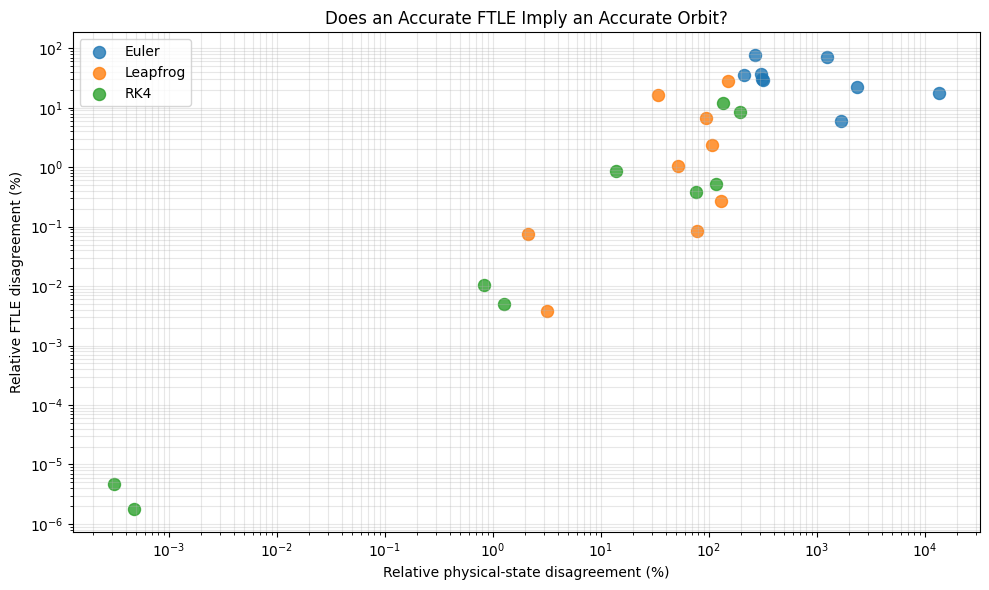

In [128]:

# OBJECTIVE 13.1
# Compare FTLE accuracy and physical trajectory accuracy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

comparison = results_df[
    (results_df["T"] == 240.0) &
    (results_df["integrator"] != "DOP853")
].copy()

comparison["ftle_relative_error_pct"] = (
    100 * comparison["ftle_error"] /
    comparison["system"].map(
        results_df[
            (results_df["integrator"] == "DOP853") &
            (results_df["T"] == 240.0)
        ].set_index("system")["ftle"].abs()
    )
)

comparison["state_relative_error_pct"] = (
    100 * comparison["relative_state_error"]
)

for system_name, group in comparison.groupby("system"):

    print("\n" + "=" * 75)
    print(system_name)
    print("=" * 75)

    display(
        group[
            [
                "integrator",
                "dt",
                "ftle",
                "ftle_relative_error_pct",
                "state_relative_error_pct",
                "status"
            ]
        ].round(6)
    )

# Plot errors against each other.
fig, ax = plt.subplots(figsize=(10, 6))

for method, group in comparison.groupby("integrator"):

    valid = group[
        (group["ftle_relative_error_pct"] > 0) &
        (group["state_relative_error_pct"] > 0) &
        np.isfinite(group["ftle_relative_error_pct"]) &
        np.isfinite(group["state_relative_error_pct"])
    ]

    ax.scatter(
        valid["state_relative_error_pct"],
        valid["ftle_relative_error_pct"],
        label=method,
        s=75,
        alpha=0.8
    )

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("Relative physical-state disagreement (%)")
ax.set_ylabel("Relative FTLE disagreement (%)")

ax.set_title(
    "Does an Accurate FTLE Imply an Accurate Orbit?"
)

ax.legend()
ax.grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()



## 13.3 When can an apparently accurate FTLE hide an inaccurate trajectory?

Our previous scatter plot revealed that physical-state disagreement and FTLE disagreement do not always change together.

We will now examine the relationship separately for each gravitational benchmark.

The key distinction is between:

- Trajectory accuracy: How closely does the numerical physical state match the adaptive reference?
- Sensitivity accuracy: How closely does its finite-time Lyapunov estimate match the adaptive reference?

We will identify simulations where FTLE error is relatively small but physical-state disagreement is large.

Such cases demonstrate that agreement in a scalar chaos-related indicator does not necessarily guarantee an accurate underlying trajectory.

This is a numerical-reliability observation, not automatically a false chaos classification.

The thresholds used below are exploratory screening criteria, not universal physical definitions.


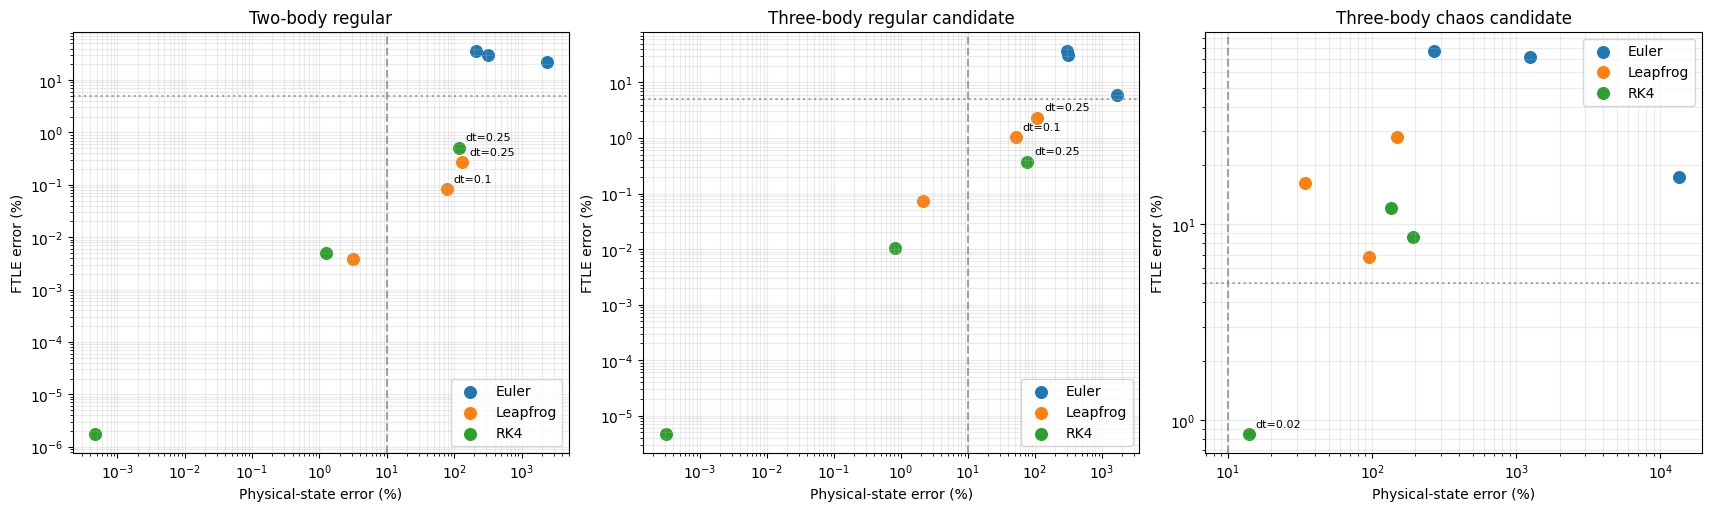

CASES WITH LOW FTLE ERROR BUT LARGE STATE ERROR
                      system integrator   dt  state_error_pct  ftle_error_pct
            Two-body regular   Leapfrog  0.1          77.3104       0.0837728
            Two-body regular   Leapfrog 0.25          130.547        0.274719
            Two-body regular        RK4 0.25           116.18        0.512573
Three-body regular candidate   Leapfrog  0.1          51.6859         1.03732
Three-body regular candidate   Leapfrog 0.25          107.722         2.32019
Three-body regular candidate        RK4 0.25          76.2274        0.375748
  Three-body chaos candidate        RK4 0.02          13.9327         0.85014


In [129]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reuse the Objective 13 results.
data = results_df[
    (np.isclose(results_df["T"], 240.0)) &
    (results_df["integrator"] != "DOP853")
].copy()

reference_ftle = (
    results_df[
        (np.isclose(results_df["T"], 240.0)) &
        (results_df["integrator"] == "DOP853")
    ]
    .set_index("system")["ftle"]
)

data["state_error_pct"] = (
    100 * data["relative_state_error"]
)

data["ftle_error_pct"] = (
    100 * data["ftle_error"]
    / data["system"].map(reference_ftle).abs()
)

# Exploratory thresholds
state_threshold = 10.0
ftle_threshold = 5.0

data["misleading_agreement"] = (
    (data["state_error_pct"] > state_threshold) &
    (data["ftle_error_pct"] < ftle_threshold)
)

systems = list(data["system"].unique())

fig, axes = plt.subplots(
    1, len(systems),
    figsize=(17, 5),
    constrained_layout=True
)

colors = {
    "Euler": "tab:blue",
    "Leapfrog": "tab:orange",
    "RK4": "tab:green"
}

for ax, system in zip(axes, systems):

    subset = data[data["system"] == system]

    for method, group in subset.groupby("integrator"):

        ax.scatter(
            group["state_error_pct"],
            group["ftle_error_pct"],
            color=colors.get(method, "gray"),
            label=method,
            s=70
        )

        for _, row in group.iterrows():
            if row["misleading_agreement"]:
                ax.annotate(
                    f'dt={row["dt"]}',
                    (
                        row["state_error_pct"],
                        row["ftle_error_pct"]
                    ),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8
                )

    ax.axvline(
        state_threshold,
        linestyle="--",
        color="gray",
        alpha=0.7
    )

    ax.axhline(
        ftle_threshold,
        linestyle=":",
        color="gray",
        alpha=0.7
    )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_title(system)
    ax.set_xlabel("Physical-state error (%)")
    ax.set_ylabel("FTLE error (%)")
    ax.grid(alpha=0.25, which="both")
    ax.legend()

plt.show()

# Identify cases satisfying exploratory criteria.
misleading_cases = data[
    data["misleading_agreement"]
].copy()

print("=" * 80)
print("CASES WITH LOW FTLE ERROR BUT LARGE STATE ERROR")
print("=" * 80)

if misleading_cases.empty:
    print(
        "No simulations satisfy the selected screening criteria."
    )
else:
    print(
        misleading_cases[
            [
                "system",
                "integrator",
                "dt",
                "state_error_pct",
                "ftle_error_pct"
            ]
        ].to_string(
            index=False,
            float_format=lambda x: f"{x:.6g}"
        )
    )



# Objective 14 — Robustness of Numerical Chaos Diagnostics Across Initial Conditions

## 14.1 From individual simulations to ensemble-based research

Our previous experiments demonstrated that numerical integration errors can affect both gravitational trajectories and measurements of infinitesimal perturbation growth.

We also observed that a numerical simulation may reproduce a finite-time Lyapunov estimate reasonably well even when its calculated physical trajectory differs substantially from a high-accuracy reference.

However, those findings came from a small number of individual configurations.

We now want to investigate whether the same behavior occurs across an ensemble of nearby gravitational initial conditions.

## The physical systems

We use two families of circular restricted three-body configurations.

### Family A — Regular-motion neighborhood

The central configuration has:

- Test-particle radius: 1.40
- Perturbing planet mass: 0.001
- Initial orbital angle: 120 degrees

Earlier simulations produced decreasing finite-time Lyapunov estimates and relatively regular-looking motion.

This is a regular-motion candidate, not an analytically established regular three-body orbit.

### Family B — High-sensitivity neighborhood

The central configuration has:

- Test-particle radius: 1.34
- Perturbing planet mass: 0.005
- Initial orbital angle: 120 degrees

Earlier simulations produced stronger finite-time perturbation growth and numerically sensitive trajectories.

This is a high-sensitivity or chaos-candidate family.

## Constructing the ensemble

For each family, we vary the initial test-particle radius by:

$$
\Delta r\in\{-0.01,0,+0.01\}
$$

We vary the initial angular separation by:

$$
\Delta\theta\in\{-5^\circ,0^\circ,+5^\circ\}
$$

Each family contains:

$$
3\times3=9
$$

configurations, giving 18 configurations in total.

This is a structured parameter grid, not a random or statistically representative sample of all possible three-body systems.

## Numerical methods

For every configuration, we compare:

- Forward Euler
- Symplectic Leapfrog
- Fourth-order Runge–Kutta
- Adaptive DOP853

The fixed-step methods use:

$$
\Delta t\in\{0.04,0.10\}
$$

The observation duration is:

$$
T=120
$$

All numerical methods evolve the physical trajectory and its variational equations using the same initial tangent direction.

For Leapfrog, the variational equations are advanced using the linearized kick-drift-kick map.

## The numerical reference

We obtain the reference finite-time Lyapunov estimate and physical endpoint from adaptive DOP853.

We independently refine the reference tolerances and maximum timestep.

A configuration is marked as reference-verified only when the two adaptive calculations agree within stated numerical tolerances.

If the reference calculations disagree substantially, the resulting fixed-step comparison is labeled unresolved rather than trusted.

## Error measurements

For each numerical simulation, we measure two quantities.

### Physical-state disagreement

We compare the final star-relative positions and velocities with the adaptive reference:

$$
\epsilon_X=
\frac{\|X_{\mathrm{fixed}}-X_{\mathrm{ref}}\|}
{\|X_{\mathrm{ref}}\|}
$$

This removes common translation of the full system. The norm uses fixed normalized simulation units.

### Finite-time Lyapunov disagreement

We compare finite-time Lyapunov estimates:

$$
\epsilon_\lambda=
\frac{|\lambda_{\mathrm{fixed}}-\lambda_{\mathrm{ref}}|}
{|\lambda_{\mathrm{ref}}|}
$$

We report these errors as percentages.

These are comparisons against numerical reference calculations, not exact errors relative to an analytical solution.

## Investigating misleading agreement

We define an exploratory case of misleading FTLE agreement when:

$$
\epsilon_X>10\%
$$

while:

$$
\epsilon_\lambda<5\%
$$

Such a simulation has substantial physical-state disagreement but relatively small FTLE disagreement.

The thresholds are methodological choices, not universal physical laws.

We will also vary the thresholds to determine whether the findings are robust to different definitions of accuracy.

## Research questions

The ensemble experiment addresses four questions:

1. How often does each numerical method produce unreliable FTLE estimates?

2. Can large physical-state errors coexist with small FTLE errors?

3. Do the two initial-condition neighborhoods exhibit different numerical reliability patterns?

4. How sensitive are our findings to the choice of error thresholds?

## Scientific interpretation

We will report observed numerical-reliability frequencies within this specific 18-configuration grid.

These frequencies should not be interpreted as population probabilities or definitive false-positive and false-negative chaos rates.

A genuine chaos-classification study additionally requires robust asymptotic dynamical labels.

Our immediate aim is to identify reproducible relationships between initial conditions, numerical integration methods, timestep resolution, trajectory accuracy, and finite-time dynamical-sensitivity accuracy.


OBJECTIVE 14 — ENSEMBLE EXPERIMENT
Configurations: 18
Fixed-step methods: 3
Timesteps per method: 2
Total fixed-step simulations: 108

RUNNING ADAPTIVE REFERENCES
-----------------------------------------------------------------
C01 | verified=True | FTLE=0.03986
C02 | verified=True | FTLE=0.04121
C03 | verified=True | FTLE=0.04232
C04 | verified=True | FTLE=0.03961
C05 | verified=True | FTLE=0.04083
C06 | verified=True | FTLE=0.04183
C07 | verified=True | FTLE=0.03883
C08 | verified=True | FTLE=0.04019
C09 | verified=True | FTLE=0.04130
C10 | verified=True | FTLE=0.09121
C11 | verified=True | FTLE=0.15027
C12 | verified=False | FTLE=0.13220
C13 | verified=True | FTLE=0.10173
C14 | verified=True | FTLE=0.09104
C15 | verified=True | FTLE=0.05610
C16 | verified=True | FTLE=0.10447
C17 | verified=True | FTLE=0.07218
C18 | verified=True | FTLE=0.08831

Verified references: 17 / 18

RUNNING FIXED-STEP ENSEMBLE
-----------------------------------------------------------------

NUMERICAL RELI

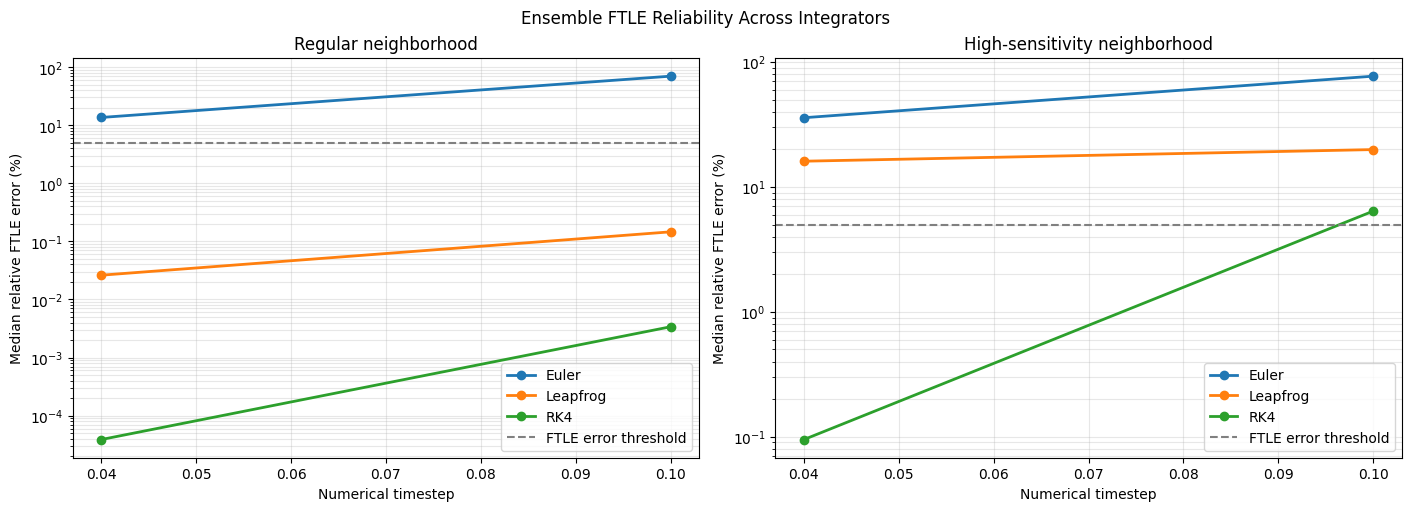

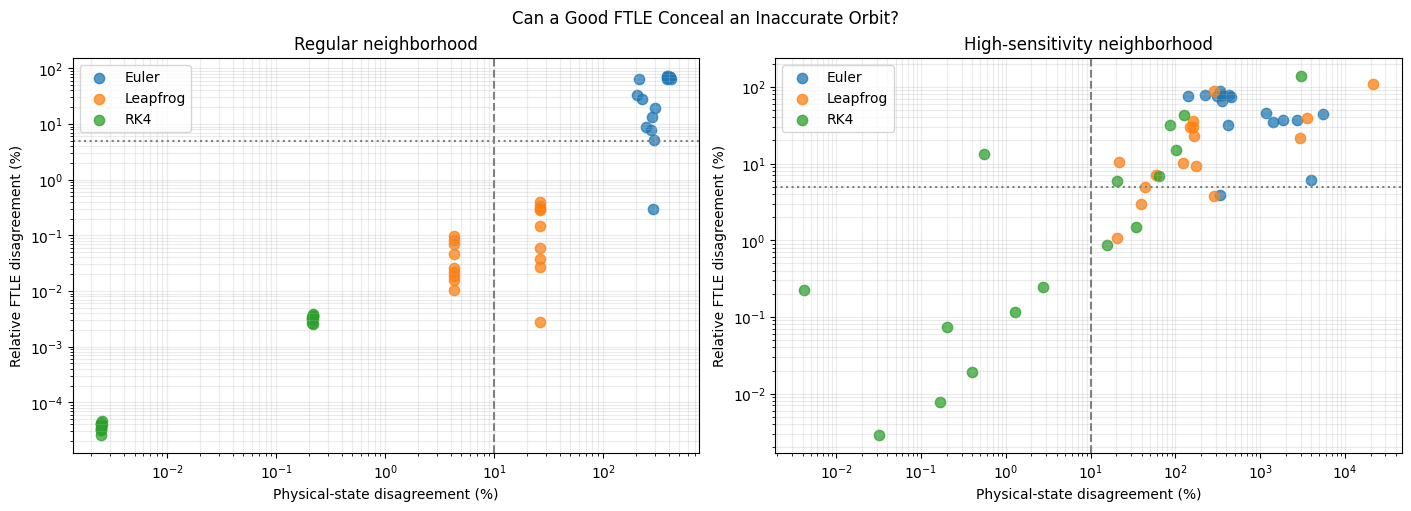

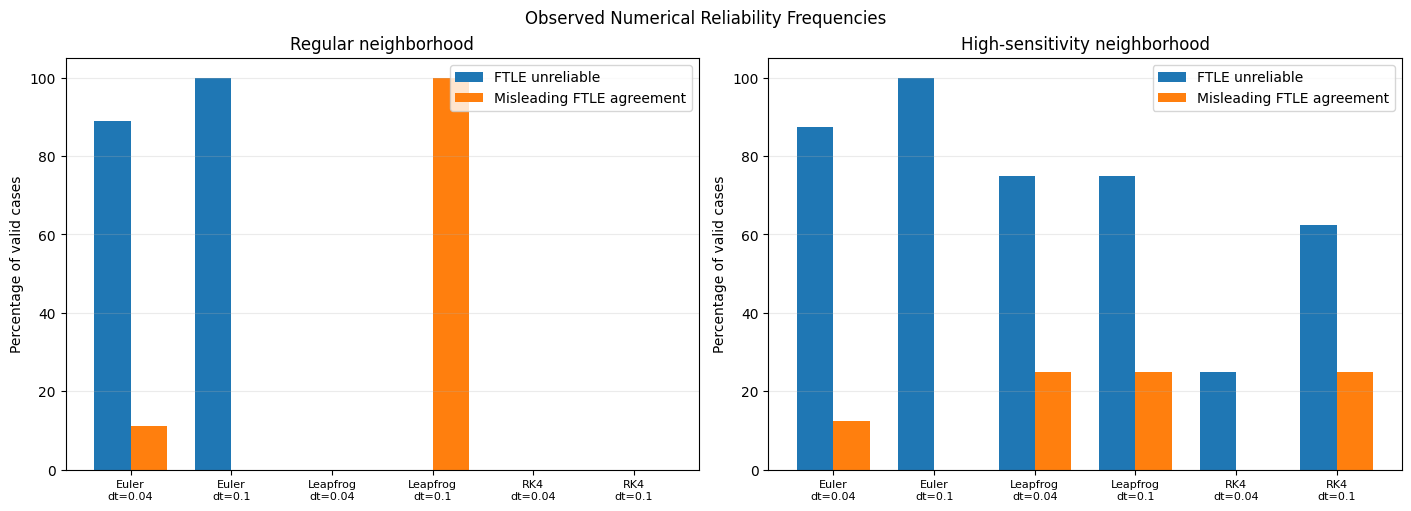

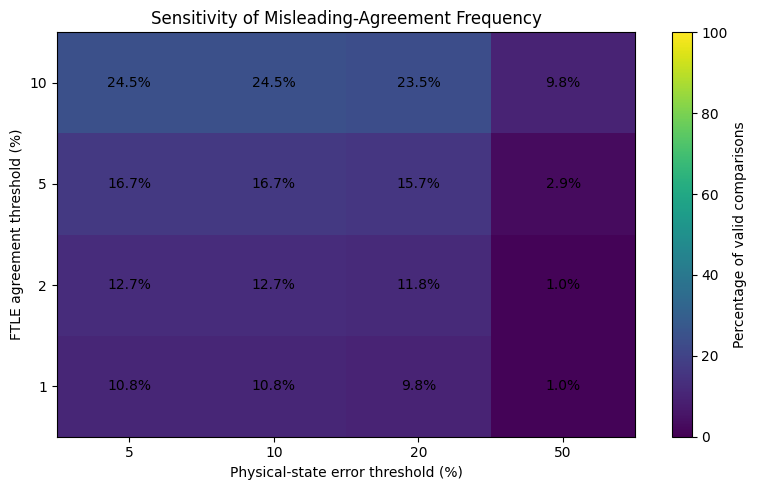


CASES WITH MISLEADING FTLE AGREEMENT
case_id                        family  radius     angle integrator      dt  state_error_pct  ftle_error_pct
    C17 High-sensitivity neighborhood 1.35000 120.00000      Euler 0.04000        333.90778         3.86116
    C18 High-sensitivity neighborhood 1.35000 125.00000   Leapfrog 0.10000        288.46223         3.72902
    C04          Regular neighborhood 1.40000 115.00000      Euler 0.04000        285.99990         0.29294
    C17 High-sensitivity neighborhood 1.35000 120.00000   Leapfrog 0.10000         43.25359         4.95845
    C17 High-sensitivity neighborhood 1.35000 120.00000   Leapfrog 0.04000         39.34615         2.92827
    C14 High-sensitivity neighborhood 1.34000 120.00000        RK4 0.10000         34.43378         1.49895
    C01          Regular neighborhood 1.39000 115.00000   Leapfrog 0.10000         26.51872         0.39056
    C03          Regular neighborhood 1.39000 125.00000   Leapfrog 0.10000         26.51396       

In [130]:

# ============================================================
# OBJECTIVE 14
# ENSEMBLE ROBUSTNESS OF NUMERICAL CHAOS DIAGNOSTICS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp

# ------------------------------------------------------------
# 1. EXPERIMENT SETTINGS
# ------------------------------------------------------------

G = 1.0
T_SCALE = 1.0

TOTAL_TIME = 120.0
RENORM_TIME = 2.0

DT_VALUES = [0.04, 0.10]

RADIUS_OFFSETS = [-0.01, 0.0, 0.01]
ANGLE_OFFSETS = [-5.0, 0.0, 5.0]

FAMILIES = {
    "Regular neighborhood": {
        "radius": 1.40,
        "planet_mass": 0.001
    },
    "High-sensitivity neighborhood": {
        "radius": 1.34,
        "planet_mass": 0.005
    }
}

# Exploratory error thresholds, as percentages.
STATE_THRESHOLD = 10.0
FTLE_THRESHOLD = 5.0

# Reference verification thresholds.
REF_STATE_TOL = 1e-4
REF_FTLE_ABS_TOL = 1e-4

METHODS = ["Euler", "Leapfrog", "RK4"]

np.set_printoptions(precision=6, suppress=True)


# ------------------------------------------------------------
# 2. CREATE INITIAL CONDITIONS
# ------------------------------------------------------------

def make_system(radius, angle_deg, planet_mass):

    masses = np.array(
        [1.0, planet_mass, 0.0],
        dtype=float
    )

    M = masses[0] + masses[1]
    omega = np.sqrt(G * M)

    r_star = np.array([-planet_mass/M, 0.0])
    r_planet = np.array([1.0/M, 0.0])

    v_star = np.array([0.0, omega*r_star[0]])
    v_planet = np.array([0.0, omega*r_planet[0]])

    theta = np.deg2rad(angle_deg)

    direction = np.array([
        np.cos(theta),
        np.sin(theta)
    ])

    tangent = np.array([
        -np.sin(theta),
        np.cos(theta)
    ])

    r_test = r_star + radius*direction

    v_test = (
        v_star
        + np.sqrt(G*masses[0]/radius)*tangent
    )

    r = np.array([r_star, r_planet, r_test])
    v = np.array([v_star, v_planet, v_test])

    return r, v, masses


# ------------------------------------------------------------
# 3. GRAVITATIONAL AND VARIATIONAL EQUATIONS
# ------------------------------------------------------------

def acceleration_variation(r, dr, masses):

    n = len(masses)

    a = np.zeros_like(r)
    da = np.zeros_like(r)

    for i in range(n):
        for j in range(n):

            if i == j or masses[j] == 0:
                continue

            R = r[j] - r[i]
            dR = dr[j] - dr[i]

            dist2 = np.dot(R, R)

            if dist2 < 1e-24:
                raise FloatingPointError(
                    "Near-collision singularity"
                )

            inv3 = dist2**(-1.5)
            inv5 = dist2**(-2.5)

            gm = G*masses[j]

            a[i] += gm*R*inv3

            da[i] += gm*(
                dR*inv3
                - 3*np.dot(R, dR)*R*inv5
            )

    return a, da


def tangent_norm(dr, dv):

    return np.sqrt(
        np.sum(dr**2)
        + T_SCALE**2*np.sum(dv**2)
    )


def rhs_parts(r, v, dr, dv, masses):

    a, da = acceleration_variation(
        r, dr, masses
    )

    return v, a, dv, da


# ------------------------------------------------------------
# 4. NUMERICAL INTEGRATORS
# ------------------------------------------------------------

def euler_step(r, v, dr, dv, m, h):

    a, da = acceleration_variation(r, dr, m)

    return (
        r + h*v,
        v + h*a,
        dr + h*dv,
        dv + h*da
    )


def leapfrog_step(r, v, dr, dv, m, h):

    a, da = acceleration_variation(r, dr, m)

    vh = v + 0.5*h*a
    dvh = dv + 0.5*h*da

    rn = r + h*vh
    drn = dr + h*dvh

    an, dan = acceleration_variation(
        rn, drn, m
    )

    vn = vh + 0.5*h*an
    dvn = dvh + 0.5*h*dan

    return rn, vn, drn, dvn


def rk4_step(r, v, dr, dv, m, h):

    state = (r, v, dr, dv)

    k1 = rhs_parts(*state, m)

    s2 = tuple(
        x + 0.5*h*k
        for x, k in zip(state, k1)
    )
    k2 = rhs_parts(*s2, m)

    s3 = tuple(
        x + 0.5*h*k
        for x, k in zip(state, k2)
    )
    k3 = rhs_parts(*s3, m)

    s4 = tuple(
        x + h*k
        for x, k in zip(state, k3)
    )
    k4 = rhs_parts(*s4, m)

    return tuple(
        x + h*(a + 2*b + 2*c + d)/6.0
        for x, a, b, c, d in zip(
            state, k1, k2, k3, k4
        )
    )


STEPPERS = {
    "Euler": euler_step,
    "Leapfrog": leapfrog_step,
    "RK4": rk4_step
}


# ------------------------------------------------------------
# 5. ADAPTIVE SOLVER UTILITIES
# ------------------------------------------------------------

def pack(r, v, dr, dv):

    return np.concatenate([
        r.ravel(),
        v.ravel(),
        dr.ravel(),
        dv.ravel()
    ])


def unpack(y, n=3):

    b = 2*n

    return (
        y[:b].reshape(n, 2).copy(),
        y[b:2*b].reshape(n, 2).copy(),
        y[2*b:3*b].reshape(n, 2).copy(),
        y[3*b:4*b].reshape(n, 2).copy()
    )


def combined_rhs(t, y, masses):

    return pack(
        *rhs_parts(
            *unpack(y, len(masses)),
            masses
        )
    )


def relative_state(r, v):

    # Star-relative positions and velocities.
    q = r[1:] - r[0]
    u = v[1:] - v[0]

    return np.concatenate([
        q.ravel(),
        (T_SCALE*u).ravel()
    ])


# ------------------------------------------------------------
# 6. COMMON SIMULATION ENGINE
# ------------------------------------------------------------

def simulate_ftle(
    system,
    method="DOP853",
    dt=None,
    rtol=1e-11,
    atol=1e-13,
    max_step=0.1
):

    r, v, masses = system

    r = r.copy()
    v = v.copy()

    dr = np.zeros_like(r)
    dv = np.zeros_like(v)

    # Same tangent direction in every experiment.
    dr[2, 0] = 1.0

    log_growth = 0.0
    elapsed = 0.0

    min_planet_distance = np.inf
    max_star_distance = 0.0

    if method != "DOP853":

        steps_per_block = int(
            round(RENORM_TIME/dt)
        )

        if not np.isclose(
            steps_per_block*dt,
            RENORM_TIME
        ):
            raise ValueError(
                "dt must divide RENORM_TIME"
            )

    while elapsed < TOTAL_TIME - 1e-10:

        block_duration = min(
            RENORM_TIME,
            TOTAL_TIME - elapsed
        )

        if method == "DOP853":

            y0 = pack(r, v, dr, dv)

            sol = solve_ivp(
                combined_rhs,
                (elapsed, elapsed + block_duration),
                y0,
                args=(masses,),
                method="DOP853",
                rtol=rtol,
                atol=atol,
                max_step=max_step
            )

            if not sol.success:
                raise RuntimeError(sol.message)

            block_positions = (
                sol.y[:6].T.reshape(-1, 3, 2)
            )

            distances = np.linalg.norm(
                block_positions[:, 2]
                - block_positions[:, 1],
                axis=1
            )

            radii = np.linalg.norm(
                block_positions[:, 2]
                - block_positions[:, 0],
                axis=1
            )

            min_planet_distance = min(
                min_planet_distance,
                distances.min()
            )

            max_star_distance = max(
                max_star_distance,
                radii.max()
            )

            r, v, dr, dv = unpack(
                sol.y[:, -1]
            )

        else:

            stepper = STEPPERS[method]

            n_steps = int(
                round(block_duration/dt)
            )

            for _ in range(n_steps):

                r, v, dr, dv = stepper(
                    r, v, dr, dv,
                    masses, dt
                )

                if not all(
                    np.all(np.isfinite(x))
                    for x in (r, v, dr, dv)
                ):
                    raise FloatingPointError(
                        "Nonfinite state"
                    )

                if np.max(np.abs(r)) > 1e8:
                    raise FloatingPointError(
                        "Trajectory exceeded safety limit"
                    )

                d = np.linalg.norm(r[2] - r[1])
                rs = np.linalg.norm(r[2] - r[0])

                min_planet_distance = min(
                    min_planet_distance, d
                )

                max_star_distance = max(
                    max_star_distance, rs
                )

        growth = tangent_norm(dr, dv)

        if not np.isfinite(growth) or growth <= 0:
            raise FloatingPointError(
                "Invalid tangent growth"
            )

        log_growth += np.log(growth)

        dr /= growth
        dv /= growth

        elapsed += block_duration

    return {
        "ftle": log_growth/TOTAL_TIME,
        "state": relative_state(r, v),
        "min_planet_distance": min_planet_distance,
        "max_star_distance": max_star_distance
    }


# ------------------------------------------------------------
# 7. BUILD INITIAL-CONDITION ENSEMBLE
# ------------------------------------------------------------

ensemble = []

for family_name, config in FAMILIES.items():

    for dradius in RADIUS_OFFSETS:
        for dangle in ANGLE_OFFSETS:

            radius = config["radius"] + dradius
            angle = 120.0 + dangle

            case_id = f"C{len(ensemble)+1:02d}"

            ensemble.append({
                "case_id": case_id,
                "family": family_name,
                "radius": radius,
                "angle": angle,
                "planet_mass": config["planet_mass"],
                "system": make_system(
                    radius, angle,
                    config["planet_mass"]
                )
            })

print("=" * 75)
print("OBJECTIVE 14 — ENSEMBLE EXPERIMENT")
print("=" * 75)

print("Configurations:", len(ensemble))
print("Fixed-step methods:", len(METHODS))
print("Timesteps per method:", len(DT_VALUES))

print(
    "Total fixed-step simulations:",
    len(ensemble)*len(METHODS)*len(DT_VALUES)
)


# ------------------------------------------------------------
# 8. RUN AND VERIFY ADAPTIVE REFERENCES
# ------------------------------------------------------------

references = {}
reference_records = []

print("\nRUNNING ADAPTIVE REFERENCES")
print("-" * 65)

for case in ensemble:

    cid = case["case_id"]
    system = case["system"]

    try:

        standard = simulate_ftle(
            system,
            method="DOP853",
            rtol=1e-10,
            atol=1e-12,
            max_step=0.1
        )

        refined = simulate_ftle(
            system,
            method="DOP853",
            rtol=1e-12,
            atol=1e-14,
            max_step=0.05
        )

        state_disagreement = (
            np.linalg.norm(
                standard["state"] - refined["state"]
            )
            / max(
                np.linalg.norm(refined["state"]),
                1e-15
            )
        )

        ftle_disagreement = abs(
            standard["ftle"] - refined["ftle"]
        )

        verified = (
            state_disagreement <= REF_STATE_TOL
            and ftle_disagreement <= REF_FTLE_ABS_TOL
        )

        references[cid] = refined

        reference_records.append({
            "case_id": cid,
            "family": case["family"],
            "radius": case["radius"],
            "angle": case["angle"],
            "reference_ftle": refined["ftle"],
            "reference_state_disagreement":
                state_disagreement,
            "reference_ftle_disagreement":
                ftle_disagreement,
            "reference_verified": verified,
            "min_planet_distance":
                refined["min_planet_distance"],
            "max_star_distance":
                refined["max_star_distance"]
        })

        print(
            f"{cid} | verified={verified} | "
            f"FTLE={refined['ftle']:.5f}"
        )

    except Exception as exc:

        references[cid] = None

        reference_records.append({
            "case_id": cid,
            "family": case["family"],
            "radius": case["radius"],
            "angle": case["angle"],
            "reference_ftle": np.nan,
            "reference_state_disagreement": np.nan,
            "reference_ftle_disagreement": np.nan,
            "reference_verified": False,
            "min_planet_distance": np.nan,
            "max_star_distance": np.nan
        })

        print(f"{cid} | reference failed: {exc}")

reference_df = pd.DataFrame(reference_records)

verified_ids = set(
    reference_df.loc[
        reference_df["reference_verified"],
        "case_id"
    ]
)

print(
    "\nVerified references:",
    len(verified_ids),
    "/", len(ensemble)
)


# ------------------------------------------------------------
# 9. RUN THE FIXED-STEP ENSEMBLE
# ------------------------------------------------------------

records = []

print("\nRUNNING FIXED-STEP ENSEMBLE")
print("-" * 65)

for case in ensemble:

    cid = case["case_id"]
    ref = references[cid]

    for method in METHODS:
        for dt in DT_VALUES:

            row = {
                "case_id": cid,
                "family": case["family"],
                "radius": case["radius"],
                "angle": case["angle"],
                "integrator": method,
                "dt": dt,
                "ftle": np.nan,
                "state_error_pct": np.nan,
                "ftle_error_pct": np.nan,
                "run_status": "Failed",
                "reference_verified":
                    cid in verified_ids
            }

            try:

                result = simulate_ftle(
                    case["system"],
                    method=method,
                    dt=dt
                )

                row["ftle"] = result["ftle"]

                if ref is not None:

                    state_error = (
                        np.linalg.norm(
                            result["state"] - ref["state"]
                        )
                        / max(
                            np.linalg.norm(ref["state"]),
                            1e-15
                        )
                    )

                    # Relative FTLE error; if the reference
                    # is extremely close to zero, this
                    # percentage becomes ill-conditioned.
                    if abs(ref["ftle"]) > 1e-10:
                        ftle_error = (
                            abs(result["ftle"]-ref["ftle"])
                            / abs(ref["ftle"])
                        )
                    else:
                        ftle_error = np.nan

                    row["state_error_pct"] = (
                        100*state_error
                    )

                    row["ftle_error_pct"] = (
                        100*ftle_error
                    )

                row["run_status"] = "Completed"

            except Exception as exc:
                row["run_status"] = "Failed"
                print(
                    f"{cid} {method} dt={dt}: {exc}"
                )

            records.append(row)


results_df_14 = pd.DataFrame(records)


# ------------------------------------------------------------
# 10. APPLY NUMERICAL RELIABILITY CRITERIA
# ------------------------------------------------------------

results_df_14["valid_comparison"] = (
    results_df_14["reference_verified"]
    & results_df_14["run_status"].eq("Completed")
    & np.isfinite(results_df_14["state_error_pct"])
    & np.isfinite(results_df_14["ftle_error_pct"])
)

results_df_14["ftle_unreliable"] = (
    results_df_14["valid_comparison"]
    & (
        results_df_14["ftle_error_pct"]
        > FTLE_THRESHOLD
    )
)

results_df_14["state_unreliable"] = (
    results_df_14["valid_comparison"]
    & (
        results_df_14["state_error_pct"]
        > STATE_THRESHOLD
    )
)

results_df_14["misleading_agreement"] = (
    results_df_14["valid_comparison"]
    & results_df_14["state_unreliable"]
    & (
        results_df_14["ftle_error_pct"]
        < FTLE_THRESHOLD
    )
)

valid = results_df_14[
    results_df_14["valid_comparison"]
].copy()

print("\n" + "=" * 75)
print("NUMERICAL RELIABILITY SUMMARY")
print("=" * 75)

summary_rows = []

for (family, method, dt), group in (
    results_df_14.groupby(
        ["family", "integrator", "dt"]
    )
):

    usable = group[group["valid_comparison"]]
    n = len(usable)

    summary_rows.append({
        "family": family,
        "integrator": method,
        "dt": dt,
        "valid_cases": n,
        "attempted_cases": len(group),

        "ftle_unreliable_pct": (
            100*usable["ftle_unreliable"].mean()
            if n else np.nan
        ),

        "state_unreliable_pct": (
            100*usable["state_unreliable"].mean()
            if n else np.nan
        ),

        "misleading_agreement_pct": (
            100*usable["misleading_agreement"].mean()
            if n else np.nan
        ),

        "median_ftle_error_pct": (
            usable["ftle_error_pct"].median()
            if n else np.nan
        ),

        "median_state_error_pct": (
            usable["state_error_pct"].median()
            if n else np.nan
        )
    })

summary_df_14 = pd.DataFrame(summary_rows)

print(
    summary_df_14.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print(
    "\nRates are conditional on successful,"
    " independently verified comparisons."
)
print(
    "Missing or unverified cases are not counted"
    " as reliable."
)


# ------------------------------------------------------------
# 11. PLOT A — ENSEMBLE FTLE ERROR BY METHOD
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    constrained_layout=True
)

colors = {
    "Euler": "tab:blue",
    "Leapfrog": "tab:orange",
    "RK4": "tab:green"
}

for ax, family in zip(axes, FAMILIES):

    subset = valid[
        valid["family"] == family
    ]

    for method in METHODS:

        medians = (
            subset[
                subset["integrator"] == method
            ]
            .groupby("dt")["ftle_error_pct"]
            .median()
        )

        if len(medians):
            ax.plot(
                medians.index,
                medians.values,
                "o-",
                label=method,
                color=colors[method],
                linewidth=2
            )

    ax.axhline(
        FTLE_THRESHOLD,
        color="gray",
        linestyle="--",
        label="FTLE error threshold"
    )

    ax.set_yscale("log")
    ax.set_xlabel("Numerical timestep")
    ax.set_ylabel("Median relative FTLE error (%)")
    ax.set_title(family)
    ax.grid(alpha=0.3, which="both")
    ax.legend()

plt.suptitle(
    "Ensemble FTLE Reliability Across Integrators"
)
plt.show()


# ------------------------------------------------------------
# 12. PLOT B — PHYSICAL VS FTLE ERROR
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    constrained_layout=True
)

for ax, family in zip(axes, FAMILIES):

    subset = valid[
        valid["family"] == family
    ]

    for method in METHODS:

        group = subset[
            subset["integrator"] == method
        ]

        group = group[
            (group["state_error_pct"] > 0)
            & (group["ftle_error_pct"] > 0)
        ]

        ax.scatter(
            group["state_error_pct"],
            group["ftle_error_pct"],
            color=colors[method],
            s=55,
            alpha=0.75,
            label=method
        )

    ax.axvline(
        STATE_THRESHOLD,
        color="gray",
        linestyle="--"
    )

    ax.axhline(
        FTLE_THRESHOLD,
        color="gray",
        linestyle=":"
    )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel("Physical-state disagreement (%)")
    ax.set_ylabel("Relative FTLE disagreement (%)")
    ax.set_title(family)
    ax.grid(alpha=0.25, which="both")
    ax.legend()

plt.suptitle(
    "Can a Good FTLE Conceal an Inaccurate Orbit?"
)
plt.show()


# ------------------------------------------------------------
# 13. PLOT C — RELIABILITY FREQUENCIES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    constrained_layout=True
)

for ax, family in zip(axes, FAMILIES):

    subset = summary_df_14[
        summary_df_14["family"] == family
    ]

    labels = [
        f"{row.integrator}\ndt={row.dt:g}"
        for row in subset.itertuples()
    ]

    x = np.arange(len(labels))
    width = 0.36

    ax.bar(
        x - width/2,
        subset["ftle_unreliable_pct"],
        width,
        label="FTLE unreliable"
    )

    ax.bar(
        x + width/2,
        subset["misleading_agreement_pct"],
        width,
        label="Misleading FTLE agreement"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_ylabel("Percentage of valid cases")
    ax.set_ylim(0, 105)
    ax.set_title(family)
    ax.legend()
    ax.grid(alpha=0.25, axis="y")

plt.suptitle(
    "Observed Numerical Reliability Frequencies"
)
plt.show()


# ------------------------------------------------------------
# 14. THRESHOLD SENSITIVITY
# ------------------------------------------------------------

state_thresholds = [5, 10, 20, 50]
ftle_thresholds = [1, 2, 5, 10]

threshold_matrix = np.full(
    (len(ftle_thresholds), len(state_thresholds)),
    np.nan
)

if len(valid):

    for i, ftle_limit in enumerate(ftle_thresholds):
        for j, state_limit in enumerate(state_thresholds):

            flagged = (
                (valid["state_error_pct"] > state_limit)
                & (valid["ftle_error_pct"] < ftle_limit)
            )

            threshold_matrix[i, j] = (
                100*flagged.mean()
            )

fig, ax = plt.subplots(figsize=(8, 5))

im = ax.imshow(
    threshold_matrix,
    origin="lower",
    aspect="auto",
    vmin=0,
    vmax=100
)

ax.set_xticks(range(len(state_thresholds)))
ax.set_xticklabels(state_thresholds)

ax.set_yticks(range(len(ftle_thresholds)))
ax.set_yticklabels(ftle_thresholds)

ax.set_xlabel("Physical-state error threshold (%)")
ax.set_ylabel("FTLE agreement threshold (%)")
ax.set_title("Sensitivity of Misleading-Agreement Frequency")

for i in range(len(ftle_thresholds)):
    for j in range(len(state_thresholds)):

        value = threshold_matrix[i, j]

        if np.isfinite(value):
            ax.text(
                j, i, f"{value:.1f}%",
                ha="center",
                va="center",
                color=(
                    "white" if value > 50 else "black"
                )
            )

plt.colorbar(
    im, ax=ax,
    label="Percentage of valid comparisons"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 15. IDENTIFY INDIVIDUAL MISLEADING CASES
# ------------------------------------------------------------

misleading_cases_14 = valid[
    valid["misleading_agreement"]
].copy()

print("\n" + "=" * 75)
print("CASES WITH MISLEADING FTLE AGREEMENT")
print("=" * 75)

if misleading_cases_14.empty:

    print(
        "No valid cases satisfy the selected thresholds."
    )

else:

    columns = [
        "case_id",
        "family",
        "radius",
        "angle",
        "integrator",
        "dt",
        "state_error_pct",
        "ftle_error_pct"
    ]

    print(
        misleading_cases_14[columns]
        .sort_values(
            "state_error_pct",
            ascending=False
        )
        .to_string(
            index=False,
            float_format=lambda x: f"{x:.5f}"
        )
    )


# ------------------------------------------------------------
# 16. EXPORT RESULTS
# ------------------------------------------------------------

reference_df.to_csv(
    "objective14_reference_validation.csv",
    index=False
)

results_df_14.to_csv(
    "objective14_all_results.csv",
    index=False
)

summary_df_14.to_csv(
    "objective14_reliability_summary.csv",
    index=False
)

print("\n" + "=" * 75)
print("OBJECTIVE 14 COMPLETED")
print("=" * 75)

print("Initial configurations:", len(ensemble))
print("Total fixed-step runs:", len(results_df_14))
print("Verified reference cases:", len(verified_ids))
print("Valid numerical comparisons:", len(valid))

print(
    "FTLE-unreliable comparisons:",
    int(valid["ftle_unreliable"].sum())
)

print(
    "Misleading-agreement comparisons:",
    len(misleading_cases_14)
)

print(
    "\nThree CSV files saved in the notebook's"
    " current working directory."
)

print(
    "\nScientific caution: these are observed"
    " numerical reliability frequencies for"
    " a structured parameter grid, not"
    " universal chaos misclassification rates."
)



# Objective 15 — Conservation Laws as Numerical Reliability Diagnostics

## 15.1 Can a conserved quantity conceal an inaccurate simulation?

In computational astrophysics, conservation laws provide important checks on numerical simulations.

For example, an isolated Newtonian gravitational system conserves total energy and angular momentum.

In the circular restricted three-body problem, there is another conserved quantity: the Jacobi constant.

Because the two massive bodies move on circular orbits around their common center of mass, the gravitational potential becomes time-independent in a frame rotating with them.

The Jacobi constant is:

$$
C_J = 2\Omega-v_{\mathrm{rot}}^2
$$

where:

$$
\Omega=
\frac{Gm_1}{r_1}
+\frac{Gm_2}{r_2}
+\frac12\omega^2(x^2+y^2)
$$

Here:

- $m_1$ and $m_2$ are the two massive bodies.
- $r_1$ and $r_2$ are the test particle's distances from them.
- $\omega$ is the angular frequency of the massive bodies.
- $x,y$ are the barycentric coordinates of the test particle.
- $v_{\mathrm{rot}}$ is its speed relative to the rotating frame.

For the exact circular restricted three-body model:

$$
C_J(t)=C_J(0)
$$

## 15.2 Why conservation alone might not guarantee accuracy

Imagine that an inaccurate integrator produces the wrong gravitational trajectory.

There may be multiple physically possible trajectories with the same Jacobi constant.

Therefore, preserving that constant does not uniquely identify the correct solution.

Similarly, a numerical method may preserve a conservation law while calculating incorrect perturbation growth.

This leads to our research hypothesis:

**Small Jacobi-constant drift is necessary evidence of numerical consistency, but it may not be sufficient evidence of accurate trajectories or Lyapunov estimates.**

Strictly speaking, exact conservation is a property of the physical equations; a particular numerical method need not conserve the invariant exactly to approximate a finite trajectory accurately.

## 15.3 Our controlled experiment

We reuse the 18 restricted three-body configurations from Objective 14.

For each configuration, we evaluate:

- Forward Euler
- Leapfrog
- Fourth-order Runge–Kutta

at timesteps:

$$
\Delta t=0.04,\quad0.10
$$

The observation horizon remains:

$$
T=120
$$

We already have numerical trajectory and FTLE errors from Objective 14.

We will now independently recompute the physical trajectories and record the Jacobi constant throughout each integration.

This ensures we evaluate conservation drift rather than just the final invariant value.

## 15.4 Three independent error measurements

### A. Maximum Jacobi drift

We define:

$$
\epsilon_J=
\frac{\max_{0\leq t\leq T}|C_J(t)-C_J(0)|}
{|C_J(0)|}
$$

The maximum is evaluated over recorded numerical states, so it is a sampled conservation diagnostic.

### B. Physical-state disagreement

From Objective 14:

$$
\epsilon_X=
\frac{\|X_{\mathrm{fixed}}-X_{\mathrm{DOP853}}\|}
{\|X_{\mathrm{DOP853}}\|}
$$

### C. FTLE disagreement

Also from Objective 14:

$$
\epsilon_\lambda=
\frac{|\lambda_{\mathrm{fixed}}-\lambda_{\mathrm{DOP853}}|}
{|\lambda_{\mathrm{DOP853}}|}
$$

We use only configurations whose adaptive references passed our previous numerical-verification checks.

## 15.5 Identifying false reassurance from conservation

An especially interesting case would satisfy:

$$
\epsilon_J<10^{-6}
$$

but also:

$$
\epsilon_\lambda>5\%
$$

Such a simulation would have excellent sampled conservation accuracy but a significantly inaccurate FTLE estimate under our chosen screening rule.

We will also investigate cases with:

$$
\epsilon_X>10\%
$$

These criteria are exploratory, not universal definitions of numerical reliability.

We will repeat the analysis using several conservation thresholds to determine whether any conclusions depend strongly on the chosen cutoff.

## 15.6 Scientific significance

This experiment investigates whether different numerical accuracy measures provide independent information.

If an integrator conserves the Jacobi constant well but produces inaccurate FTLE estimates, we will have demonstrated a limitation of conservation-only validation.

If Jacobi drift consistently tracks FTLE and trajectory errors, conservation may prove useful as a screening tool for this ensemble.

Either result is valuable.

The experiment does not attempt to prove that the underlying dynamics are regular or chaotic. It investigates the numerical reliability of the measurements used to study those dynamics.


OBJECTIVE 15 — CONSERVATION RELIABILITY

RUNNING JACOBI CONSERVATION EXPERIMENT
----------------------------------------------------------------------
Processing C01
Processing C02
Processing C03
Processing C04
Processing C05
Processing C06
Processing C07
Processing C08
Processing C09
Processing C10
Processing C11
Processing C12
Processing C13
Processing C14
Processing C15
Processing C16
Processing C17
Processing C18

CONSERVATION VS NUMERICAL RELIABILITY
                       family integrator   dt  valid_cases  median_jacobi_drift  median_ftle_error_pct  median_state_error_pct  excellent_conservation_cases  false_reassurance_cases  false_reassurance_pct
High-sensitivity neighborhood      Euler 0.04            8               0.8827                 35.795                  1637.8                             0                        0                      0
High-sensitivity neighborhood      Euler  0.1            8              0.84258                 76.995                  344.77    

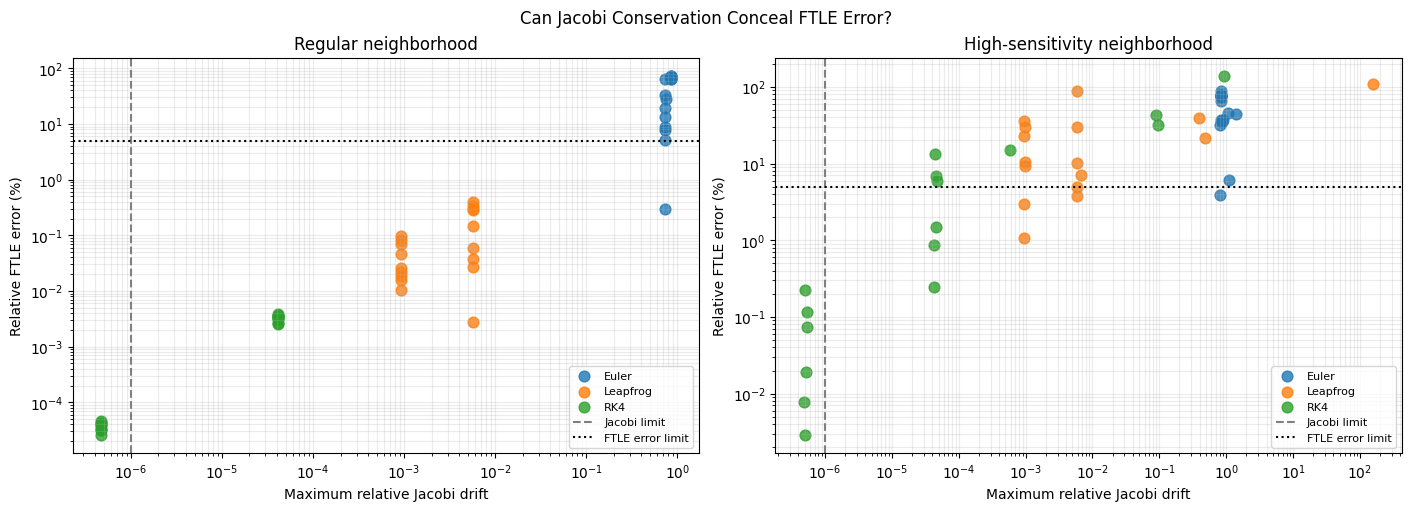

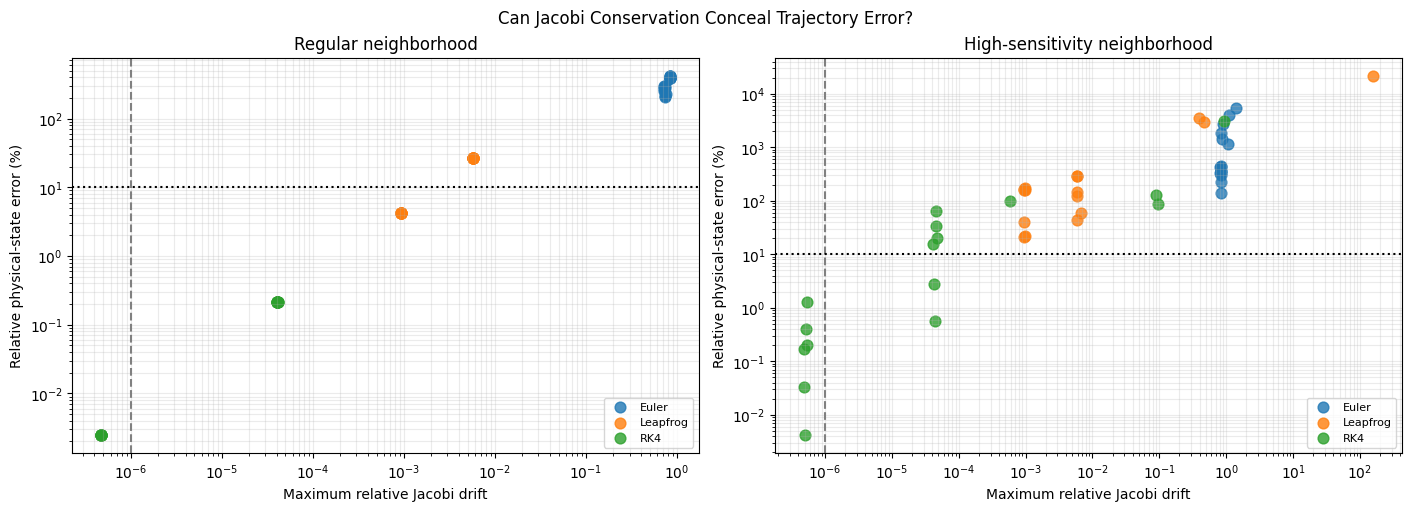

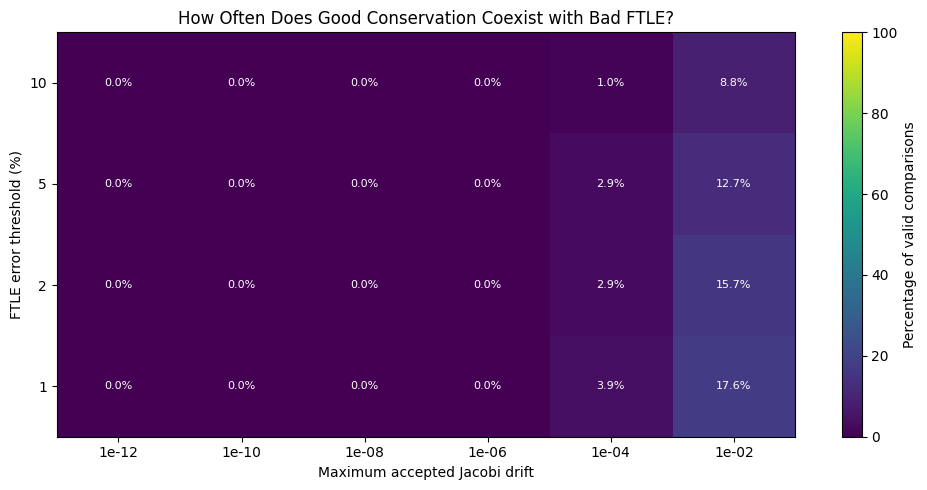


EXCELLENT CONSERVATION BUT INACCURATE RESULTS
No cases satisfy the selected criteria.

ADAPTIVE REFERENCE JACOBI DRIFT
case_id                        family  reference_verified  adaptive_jacobi_drift
    C01          Regular neighborhood                True           3.027162e-14
    C02          Regular neighborhood                True           1.643215e-14
    C03          Regular neighborhood                True           2.306130e-14
    C04          Regular neighborhood                True           1.166357e-14
    C05          Regular neighborhood                True           2.793322e-14
    C06          Regular neighborhood                True           1.655737e-14
    C07          Regular neighborhood                True           1.524673e-14
    C08          Regular neighborhood                True           1.380749e-14
    C09          Regular neighborhood                True           1.840888e-14
    C10 High-sensitivity neighborhood                True           3.

In [131]:

# ============================================================
# OBJECTIVE 15
# CAN JACOBI CONSERVATION HIDE NUMERICAL ERRORS?
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ------------------------------------------------------------
# 1. SETTINGS AND VALIDATION
# ------------------------------------------------------------

required = [
    "ensemble",
    "results_df_14",
    "reference_df",
    "G"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run Objective 14 first. Missing: "
        + ", ".join(missing)
    )

T_FINAL = 120.0
DT_VALUES_15 = [0.04, 0.10]
METHODS_15 = ["Euler", "Leapfrog", "RK4"]

JACOBI_LIMIT = 1e-6
FTLE_ERROR_LIMIT = 5.0
STATE_ERROR_LIMIT = 10.0

print("=" * 70)
print("OBJECTIVE 15 — CONSERVATION RELIABILITY")
print("=" * 70)


# ------------------------------------------------------------
# 2. JACOBI CONSTANT
# ------------------------------------------------------------

def calculate_jacobi(r, v, masses):
    """
    Jacobi constant for the circular restricted
    three-body problem.

    Assumes:
    - bodies 0 and 1 follow circular orbits
    - origin is the barycenter of bodies 0 and 1
    - body 2 is massless
    - coordinates are inertial Cartesian coordinates
    """

    m1, m2, m3 = masses

    if not np.isclose(m3, 0.0):
        raise ValueError(
            "Jacobi calculation requires a massless "
            "third body."
        )

    primary_separation = np.linalg.norm(
        r[1] - r[0]
    )

    omega = np.sqrt(
        G * (m1 + m2) / primary_separation**3
    )

    r_test = r[2]
    v_test = v[2]

    d1 = np.linalg.norm(r_test - r[0])
    d2 = np.linalg.norm(r_test - r[1])

    if min(d1, d2) < 1e-12:
        raise FloatingPointError(
            "Singular gravitational separation."
        )

    # Omega cross r, where Omega points in +z.
    rotating_frame_correction = omega * np.array([
        -r_test[1],
         r_test[0]
    ])

    v_rot = v_test - rotating_frame_correction

    potential = (
        G*m1/d1
        + G*m2/d2
        + 0.5*omega**2*np.dot(r_test, r_test)
    )

    return (
        2.0*potential
        - np.dot(v_rot, v_rot)
    )


# ------------------------------------------------------------
# 3. PHYSICAL GRAVITATIONAL ACCELERATION
# ------------------------------------------------------------

def physical_acceleration(r, masses):

    n = len(masses)
    a = np.zeros_like(r)

    for i in range(n):
        for j in range(n):

            if i == j or masses[j] == 0:
                continue

            displacement = r[j] - r[i]

            distance_squared = np.dot(
                displacement, displacement
            )

            if distance_squared < 1e-24:
                raise FloatingPointError(
                    "Near-collision singularity."
                )

            a[i] += (
                G*masses[j]*displacement
                / distance_squared**1.5
            )

    return a


# ------------------------------------------------------------
# 4. PHYSICAL-STATE INTEGRATORS
# ------------------------------------------------------------

def physical_euler(r, v, m, dt):

    a = physical_acceleration(r, m)

    return (
        r + dt*v,
        v + dt*a
    )


def physical_leapfrog(r, v, m, dt):

    a = physical_acceleration(r, m)

    v_half = v + 0.5*dt*a
    r_new = r + dt*v_half

    a_new = physical_acceleration(r_new, m)

    v_new = v_half + 0.5*dt*a_new

    return r_new, v_new


def physical_rk4(r, v, m, dt):

    def derivatives(position, velocity):
        return (
            velocity,
            physical_acceleration(position, m)
        )

    k1r, k1v = derivatives(r, v)

    k2r, k2v = derivatives(
        r + 0.5*dt*k1r,
        v + 0.5*dt*k1v
    )

    k3r, k3v = derivatives(
        r + 0.5*dt*k2r,
        v + 0.5*dt*k2v
    )

    k4r, k4v = derivatives(
        r + dt*k3r,
        v + dt*k3v
    )

    r_new = r + dt/6.0 * (
        k1r + 2*k2r + 2*k3r + k4r
    )

    v_new = v + dt/6.0 * (
        k1v + 2*k2v + 2*k3v + k4v
    )

    return r_new, v_new


PHYSICAL_STEPPERS = {
    "Euler": physical_euler,
    "Leapfrog": physical_leapfrog,
    "RK4": physical_rk4
}


# ------------------------------------------------------------
# 5. FIXED-STEP JACOBI DRIFT
# ------------------------------------------------------------

def measure_fixed_jacobi(system, method, dt):

    r0, v0, masses = system

    r = r0.copy()
    v = v0.copy()

    n_steps = int(round(T_FINAL/dt))
    dt_actual = T_FINAL/n_steps

    stepper = PHYSICAL_STEPPERS[method]

    C0 = calculate_jacobi(r, v, masses)

    max_absolute_drift = 0.0

    for step in range(n_steps):

        r, v = stepper(
            r, v, masses, dt_actual
        )

        if not (
            np.all(np.isfinite(r))
            and np.all(np.isfinite(v))
        ):
            raise FloatingPointError(
                "Nonfinite physical state."
            )

        if np.max(np.abs(r)) > 1e8:
            raise FloatingPointError(
                "Numerical trajectory diverged."
            )

        current_C = calculate_jacobi(
            r, v, masses
        )

        max_absolute_drift = max(
            max_absolute_drift,
            abs(current_C - C0)
        )

    relative_drift = (
        max_absolute_drift
        / max(abs(C0), 1e-15)
    )

    return {
        "initial_jacobi": C0,
        "final_jacobi": current_C,
        "max_absolute_drift": max_absolute_drift,
        "max_relative_drift": relative_drift
    }


# ------------------------------------------------------------
# 6. ADAPTIVE JACOBI REFERENCE
# ------------------------------------------------------------

def measure_adaptive_jacobi(system):

    r0, v0, masses = system
    n = len(masses)

    y0 = np.concatenate([
        r0.ravel(),
        v0.ravel()
    ])

    def rhs(t, y):

        r = y[:2*n].reshape(n, 2)
        v = y[2*n:].reshape(n, 2)

        a = physical_acceleration(r, masses)

        return np.concatenate([
            v.ravel(),
            a.ravel()
        ])

    sol = solve_ivp(
        rhs,
        (0.0, T_FINAL),
        y0,
        method="DOP853",
        rtol=1e-12,
        atol=1e-14,
        max_step=0.05
    )

    if not sol.success:
        raise RuntimeError(sol.message)

    C0 = calculate_jacobi(r0, v0, masses)

    max_drift = 0.0

    for i in range(sol.y.shape[1]):

        r = sol.y[:2*n, i].reshape(n, 2)
        v = sol.y[2*n:, i].reshape(n, 2)

        C = calculate_jacobi(r, v, masses)

        max_drift = max(
            max_drift,
            abs(C - C0)
        )

    return max_drift / max(abs(C0), 1e-15)


# ------------------------------------------------------------
# 7. RUN CONSERVATION EXPERIMENT
# ------------------------------------------------------------

jacobi_records = []
adaptive_records = []

print("\nRUNNING JACOBI CONSERVATION EXPERIMENT")
print("-" * 70)

for case in ensemble:

    cid = case["case_id"]
    system = case["system"]

    print("Processing", cid)

    # Adaptive reference conservation
    try:
        adaptive_drift = measure_adaptive_jacobi(
            system
        )
    except Exception as exc:
        adaptive_drift = np.nan
        print("  Adaptive diagnostic failed:", exc)

    adaptive_records.append({
        "case_id": cid,
        "adaptive_jacobi_drift": adaptive_drift
    })

    # Fixed-step methods
    for method in METHODS_15:
        for dt in DT_VALUES_15:

            row = {
                "case_id": cid,
                "integrator": method,
                "dt": dt,
                "jacobi_drift": np.nan,
                "jacobi_status": "Failed"
            }

            try:

                result = measure_fixed_jacobi(
                    system, method, dt
                )

                row["jacobi_drift"] = (
                    result["max_relative_drift"]
                )

                row["jacobi_status"] = "Completed"

            except Exception as exc:

                print(
                    f"  {method}, dt={dt}: {exc}"
                )

            jacobi_records.append(row)


jacobi_df_15 = pd.DataFrame(jacobi_records)
adaptive_df_15 = pd.DataFrame(adaptive_records)


# ------------------------------------------------------------
# 8. MERGE WITH OBJECTIVE 14
# ------------------------------------------------------------

data_15 = results_df_14.merge(
    jacobi_df_15,
    on=["case_id", "integrator", "dt"],
    how="left",
    validate="one_to_one"
)

data_15 = data_15.merge(
    adaptive_df_15,
    on="case_id",
    how="left",
    validate="many_to_one"
)

# Only use successfully validated comparisons.
valid_15 = data_15[
    data_15["valid_comparison"]
    & data_15["jacobi_status"].eq("Completed")
    & np.isfinite(data_15["jacobi_drift"])
].copy()

valid_15["excellent_conservation"] = (
    valid_15["jacobi_drift"] < JACOBI_LIMIT
)

valid_15["bad_ftle"] = (
    valid_15["ftle_error_pct"]
    > FTLE_ERROR_LIMIT
)

valid_15["bad_state"] = (
    valid_15["state_error_pct"]
    > STATE_ERROR_LIMIT
)

valid_15["conservation_false_reassurance"] = (
    valid_15["excellent_conservation"]
    & (
        valid_15["bad_ftle"]
        | valid_15["bad_state"]
    )
)


# ------------------------------------------------------------
# 9. CONSERVATION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CONSERVATION VS NUMERICAL RELIABILITY")
print("=" * 75)

summary_15 = (
    valid_15
    .groupby(["family", "integrator", "dt"])
    .agg(
        valid_cases=("case_id", "size"),
        median_jacobi_drift=("jacobi_drift", "median"),
        median_ftle_error_pct=(
            "ftle_error_pct", "median"
        ),
        median_state_error_pct=(
            "state_error_pct", "median"
        ),
        excellent_conservation_cases=(
            "excellent_conservation", "sum"
        ),
        false_reassurance_cases=(
            "conservation_false_reassurance", "sum"
        )
    )
    .reset_index()
)

summary_15["false_reassurance_pct"] = (
    100
    * summary_15["false_reassurance_cases"]
    / summary_15["valid_cases"]
)

print(
    summary_15.to_string(
        index=False,
        float_format=lambda x: f"{x:.5g}"
    )
)


# ------------------------------------------------------------
# 10. PLOT A — JACOBI DRIFT VS FTLE ERROR
# ------------------------------------------------------------

colors = {
    "Euler": "tab:blue",
    "Leapfrog": "tab:orange",
    "RK4": "tab:green"
}

families = list(FAMILIES.keys())

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    constrained_layout=True
)

for ax, family in zip(axes, families):

    subset = valid_15[
        valid_15["family"] == family
    ]

    for method in METHODS_15:

        group = subset[
            subset["integrator"] == method
        ]

        ax.scatter(
            np.maximum(
                group["jacobi_drift"], 1e-17
            ),
            np.maximum(
                group["ftle_error_pct"], 1e-12
            ),
            label=method,
            color=colors[method],
            s=60,
            alpha=0.8
        )

    ax.axvline(
        JACOBI_LIMIT,
        color="gray",
        linestyle="--",
        label="Jacobi limit"
    )

    ax.axhline(
        FTLE_ERROR_LIMIT,
        color="black",
        linestyle=":",
        label="FTLE error limit"
    )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel("Maximum relative Jacobi drift")
    ax.set_ylabel("Relative FTLE error (%)")
    ax.set_title(family)
    ax.grid(alpha=0.25, which="both")
    ax.legend(fontsize=8)

plt.suptitle(
    "Can Jacobi Conservation Conceal FTLE Error?"
)
plt.show()


# ------------------------------------------------------------
# 11. PLOT B — JACOBI DRIFT VS STATE ERROR
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    constrained_layout=True
)

for ax, family in zip(axes, families):

    subset = valid_15[
        valid_15["family"] == family
    ]

    for method in METHODS_15:

        group = subset[
            subset["integrator"] == method
        ]

        ax.scatter(
            np.maximum(
                group["jacobi_drift"], 1e-17
            ),
            np.maximum(
                group["state_error_pct"], 1e-12
            ),
            label=method,
            color=colors[method],
            s=60,
            alpha=0.8
        )

    ax.axvline(
        JACOBI_LIMIT,
        color="gray",
        linestyle="--"
    )

    ax.axhline(
        STATE_ERROR_LIMIT,
        color="black",
        linestyle=":"
    )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel("Maximum relative Jacobi drift")
    ax.set_ylabel("Relative physical-state error (%)")
    ax.set_title(family)
    ax.grid(alpha=0.25, which="both")
    ax.legend(fontsize=8)

plt.suptitle(
    "Can Jacobi Conservation Conceal Trajectory Error?"
)
plt.show()


# ------------------------------------------------------------
# 12. PLOT C — CONSERVATION THRESHOLD SENSITIVITY
# ------------------------------------------------------------

jacobi_thresholds = [
    1e-12, 1e-10, 1e-8,
    1e-6, 1e-4, 1e-2
]

ftle_thresholds = [1, 2, 5, 10]

# Each cell reports the percentage of valid
# comparisons satisfying BOTH conditions:
# Jacobi drift < conservation threshold
# AND FTLE error > selected FTLE threshold.

matrix = np.full(
    (len(ftle_thresholds), len(jacobi_thresholds)),
    np.nan
)

if len(valid_15):

    for i, ftle_limit in enumerate(ftle_thresholds):
        for j, jacobi_limit in enumerate(jacobi_thresholds):

            flagged = (
                (valid_15["jacobi_drift"] < jacobi_limit)
                & (valid_15["ftle_error_pct"] > ftle_limit)
            )

            matrix[i, j] = 100*flagged.mean()

fig, ax = plt.subplots(figsize=(10, 5))

image = ax.imshow(
    matrix,
    origin="lower",
    aspect="auto",
    vmin=0,
    vmax=100,
    cmap="viridis"
)

ax.set_xticks(range(len(jacobi_thresholds)))
ax.set_xticklabels([
    f"{x:.0e}" for x in jacobi_thresholds
])

ax.set_yticks(range(len(ftle_thresholds)))
ax.set_yticklabels(ftle_thresholds)

ax.set_xlabel("Maximum accepted Jacobi drift")
ax.set_ylabel("FTLE error threshold (%)")

ax.set_title(
    "How Often Does Good Conservation Coexist "
    "with Bad FTLE?"
)

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):

        value = matrix[i, j]

        if np.isfinite(value):
            ax.text(
                j, i,
                f"{value:.1f}%",
                ha="center",
                va="center",
                color=(
                    "white" if value < 50
                    else "black"
                ),
                fontsize=8
            )

plt.colorbar(
    image,
    ax=ax,
    label="Percentage of valid comparisons"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. IDENTIFY FALSE-REASSURANCE CASES
# ------------------------------------------------------------

flagged_15 = valid_15[
    valid_15["conservation_false_reassurance"]
].copy()

print("\n" + "=" * 75)
print("EXCELLENT CONSERVATION BUT INACCURATE RESULTS")
print("=" * 75)

if flagged_15.empty:

    print(
        "No cases satisfy the selected criteria."
    )

else:

    columns = [
        "case_id",
        "family",
        "integrator",
        "dt",
        "jacobi_drift",
        "state_error_pct",
        "ftle_error_pct"
    ]

    print(
        flagged_15[columns]
        .sort_values("ftle_error_pct", ascending=False)
        .to_string(
            index=False,
            float_format=lambda x: f"{x:.6g}"
        )
    )


# ------------------------------------------------------------
# 14. CHECK ADAPTIVE REFERENCE CONSERVATION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ADAPTIVE REFERENCE JACOBI DRIFT")
print("=" * 75)

adaptive_check = reference_df.merge(
    adaptive_df_15,
    on="case_id",
    how="left"
)

print(
    adaptive_check[
        [
            "case_id",
            "family",
            "reference_verified",
            "adaptive_jacobi_drift"
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6e}"
    )
)


# ------------------------------------------------------------
# 15. EXPORT RESULTS
# ------------------------------------------------------------

data_15.to_csv(
    "objective15_conservation_results.csv",
    index=False
)

summary_15.to_csv(
    "objective15_conservation_summary.csv",
    index=False
)

flagged_15.to_csv(
    "objective15_false_reassurance_cases.csv",
    index=False
)

print("\n" + "=" * 75)
print("OBJECTIVE 15 COMPLETED")
print("=" * 75)

print("Total comparisons:", len(data_15))
print("Valid comparisons:", len(valid_15))

print(
    "Cases with excellent Jacobi conservation:",
    int(valid_15["excellent_conservation"].sum())
)

print(
    "Excellent-conservation cases with "
    "inaccurate state or FTLE:",
    len(flagged_15)
)

print(
    "\nImportant: conservation accuracy and"
    " dynamical accuracy are separate diagnostics."
)

print(
    "All frequencies describe this particular"
    " structured ensemble and selected thresholds."
)



# Objective 16 — Conservation Accuracy and Trajectory Reliability

## 16.1 The puzzle of configuration C12

In our ensemble experiment, 17 of 18 gravitational configurations passed adaptive-reference verification.

One configuration, C12, did not.

Yet its adaptive numerical solution conserved the Jacobi constant with relative drift approximately:

$$
4.26\times10^{-12}
$$

This creates an important scientific question:

**Can a numerical solution conserve a physical invariant extremely accurately while its trajectory remains insufficiently converged?**

The Jacobi constant constrains a trajectory to an invariant level surface, but it does not specify a unique position along that surface.

Consequently, conservation of the Jacobi constant cannot by itself establish trajectory accuracy.

## 16.2 Our physical model

We use the circular restricted three-body problem:

- A central star of mass 1
- A massive planet of mass 0.005
- A massless test particle

We reconstruct the exact initial conditions for C12 from our previously generated ensemble, rather than manually guessing its position or orbital phase.

The massive bodies orbit their common barycenter. The test particle moves in their gravitational field without influencing them.

All numerical calculations begin from identical initial conditions.

## 16.3 Three levels of numerical refinement

We will integrate the physical orbit using adaptive DOP853 with increasingly stringent numerical settings.

**Standard reference**

$$
\mathrm{rtol}=10^{-10},\quad
\mathrm{atol}=10^{-12},\quad
h_{\max}=0.1
$$

**Refined reference**

$$
\mathrm{rtol}=10^{-12},\quad
\mathrm{atol}=10^{-14},\quad
h_{\max}=0.05
$$

**Ultra-refined reference**

$$
\mathrm{rtol}=3\times10^{-14},\quad
\mathrm{atol}=3\times10^{-15},\quad
h_{\max}=0.025
$$

The third configuration approaches the practical limits of standard double-precision arithmetic, so tighter tolerances do not necessarily guarantee a more accurate solution.

We will use a common observation grid to compare solutions at identical physical times.

## 16.4 Trajectory disagreement

For two integrations A and B, define the star-relative position discrepancy:

$$
D_{AB}(t)=
\left\|
[\mathbf r_3-\mathbf r_1]_A-
[\mathbf r_3-\mathbf r_1]_B
\right\|
$$

We will compare:

- Standard versus refined
- Refined versus ultra-refined

If the second disagreement is substantially smaller than the first over a given interval, that is evidence of numerical convergence over that interval.

If both disagreements grow rapidly, pointwise trajectory convergence may require still finer numerical methods or a shorter observation horizon.

## 16.5 Jacobi conservation

For the circular restricted three-body problem:

$$
C_J=
2\left(
\frac{Gm_1}{r_1}
+\frac{Gm_2}{r_2}
+\frac{\omega^2R^2}{2}
\right)
-\left|\mathbf v-\boldsymbol\omega\times\mathbf r\right|^2
$$

Here, position and velocity are measured relative to the barycenter of the two massive bodies.

The rotation rate $\omega$ is fixed by their initial circular orbit.

We will calculate:

$$
\epsilon_J(t)=
\frac{|C_J(t)-C_J(0)|}{|C_J(0)|}
$$

For each solution, we will report the maximum sampled Jacobi drift.

This tells us whether the numerical calculation respects the physical invariant, but not whether it follows the correct orbit.

## 16.6 Finite-time Lyapunov analysis

We will also evolve the variational equations describing infinitesimal perturbations of the test particle.

The perturbation evolves according to the derivatives of the gravitational acceleration.

We periodically normalize the tangent vector and accumulate its logarithmic amplification.

The finite-time estimate is:

$$
\lambda_T=
\frac{1}{T}\sum_k\ln g_k
$$

We will measure this at:

$$
T=30,\ 60,\ 90,\ 120
$$

The aim is to determine whether the sensitivity estimate converges even if the detailed trajectory becomes difficult to reproduce.

We will perturb only the massless test particle, keeping the massive primaries unchanged. This isolates sensitivity within the restricted three-body dynamics.

## 16.7 Scientific outcomes

There are three possible outcomes.

**Numerical refinement restores agreement.** C12 failed because our original reference integration was not sufficiently accurate.

**Trajectories disagree while Jacobi conservation remains excellent.** This shows that conservation alone cannot certify pointwise accuracy, although it does not necessarily indicate solver failure or chaos.

**Trajectories disagree but FTLE estimates remain similar.** This demonstrates that trajectory accuracy and dynamical-sensitivity measurements may have different numerical convergence requirements.

Every conclusion will be limited to the tested time interval, numerical precision, and initial conditions.

Our aim is to identify C12's actual numerical behavior, not force the experiment to demonstrate a particular hypothesis.


OBJECTIVE 16 — CONFIGURATION C12
Radius: 1.33
Angle: 125.0
Masses: [1.    0.005 0.   ]
Initial positions:
 [[-0.004975  0.      ]
 [ 0.995025  0.      ]
 [-0.767832  1.089472]]
Initial velocities:
 [[ 0.       -0.004988]
 [ 0.        0.997509]
 [-0.710295 -0.502341]]

PRIMARY ORBIT
-------------------------------------------------------
Initial separation: 1.0000000000000002
Angular frequency: 1.002496882788171
Expected frequency magnitude: 1.0024968827881706
Initial barycenter: [0. 0.]

Integrating physical trajectory: Standard

Integrating physical trajectory: Refined

Integrating physical trajectory: Ultra-refined

NUMERICAL AGREEMENT HORIZONS
Threshold 1e-10 | Standard/Refined: 40.45 | Refined/Ultra: 48.85
Threshold 1e-08 | Standard/Refined: 48.45 | Refined/Ultra: 68.20
Threshold 1e-06 | Standard/Refined: 68.10 | Refined/Ultra: 108.75
Threshold 1e-04 | Standard/Refined: 95.80 | Refined/Ultra: nan
Threshold 1e-02 | Standard/Refined: nan | Refined/Ultra: nan
Threshold 1e-01 | Standar

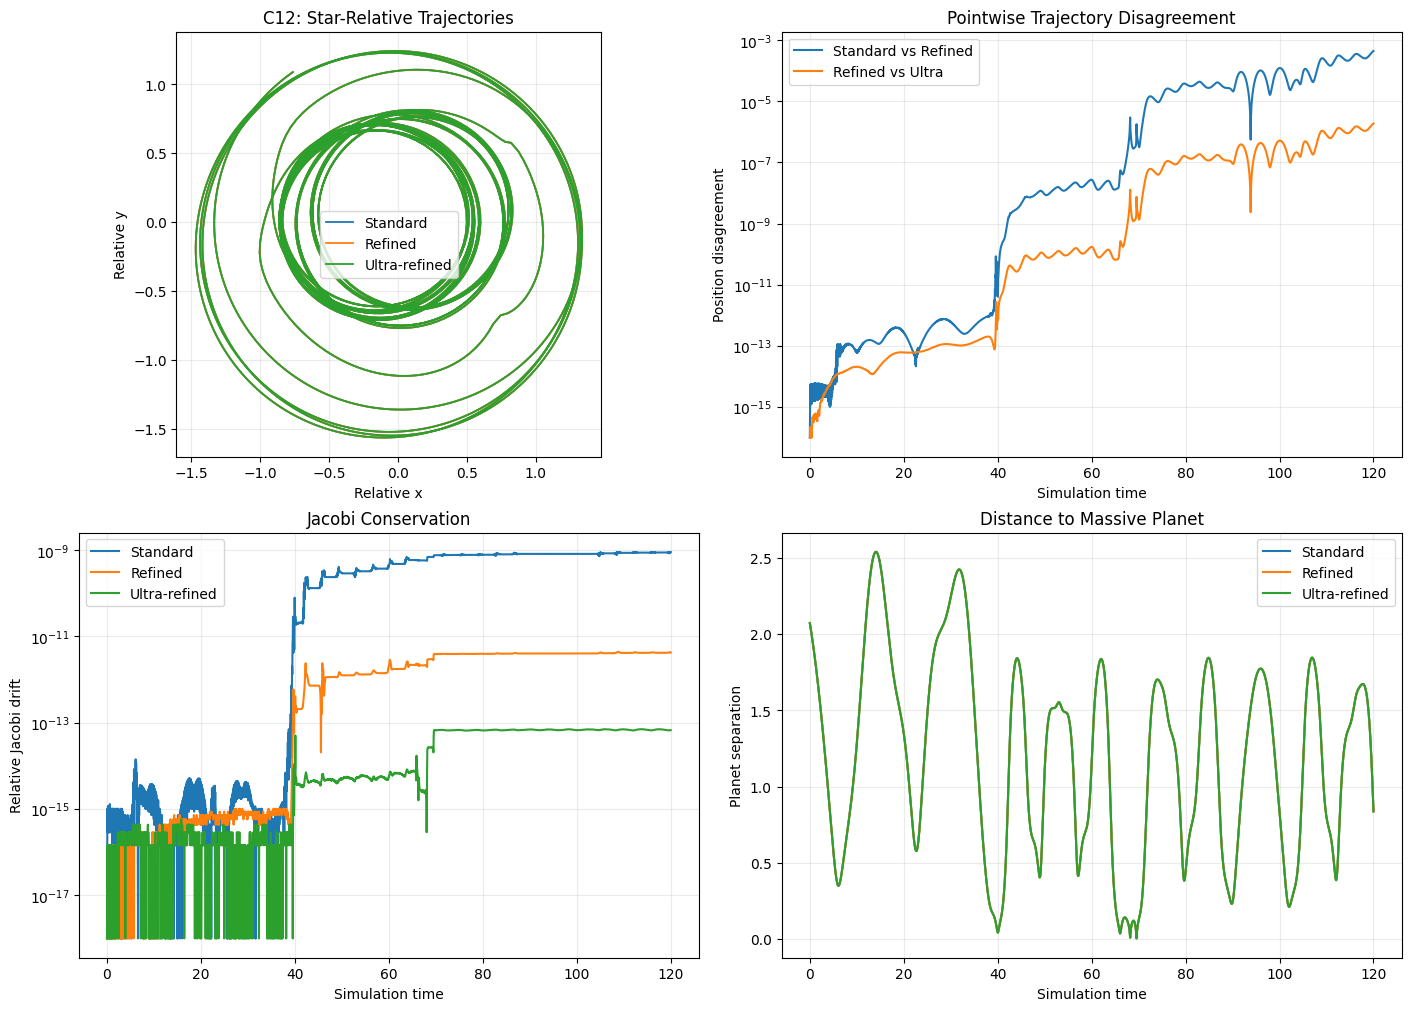

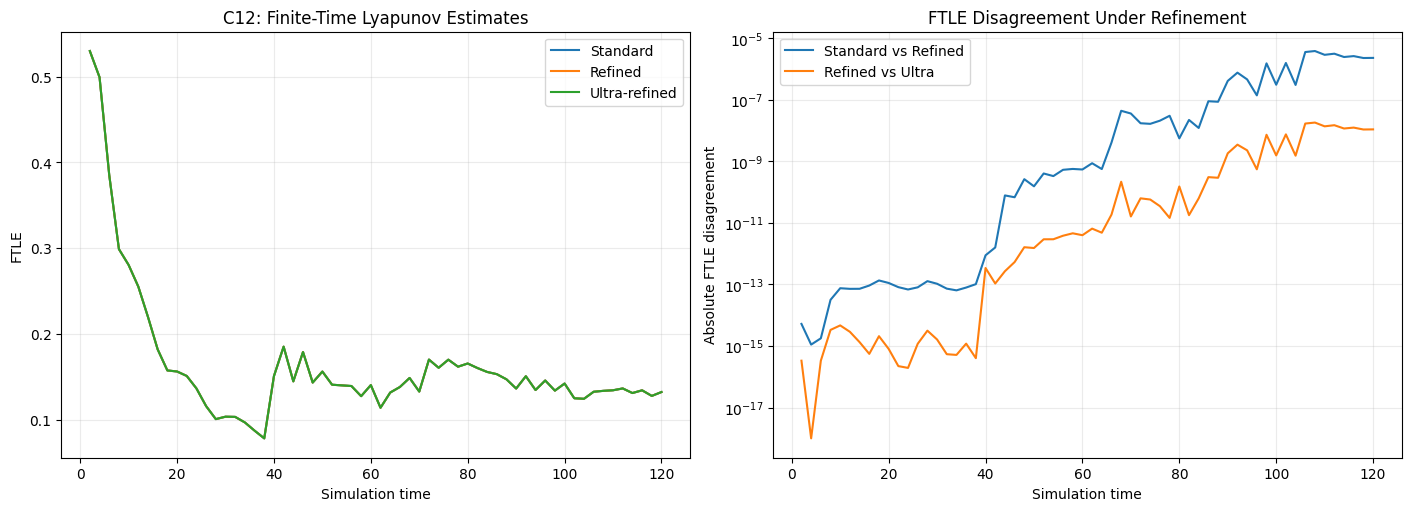


C12: REFINEMENT DIAGNOSTICS
Maximum Standard/Refined discrepancy: 4.40066669e-04
Maximum Refined/Ultra discrepancy:    1.87053513e-06
Final Standard/Refined discrepancy:   4.40066669e-04
Final Refined/Ultra discrepancy:      1.87053513e-06
Final Standard/Refined FTLE error:   2.28083195e-06
Final Refined/Ultra FTLE error:      1.08622795e-08

Endpoint trajectory agreement improves under refinement.
Endpoint FTLE agreement improves under refinement.

OBJECTIVE 16 COMPLETED
Three CSV files saved.


In [132]:

# ============================================================
# OBJECTIVE 16
# C12: JACOBI CONSERVATION VS TRAJECTORY CONVERGENCE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp

# ------------------------------------------------------------
# 1. RETRIEVE THE ORIGINAL C12 CONFIGURATION
# ------------------------------------------------------------

CASE_ID = "C12"
G16 = 1.0
T_END = 120.0
SAMPLE_DT = 0.05
RENORM_INTERVAL = 2.0

if "ensemble" not in globals():
    raise RuntimeError(
        "Run Objective 14 first to reconstruct the ensemble."
    )

matches = [
    case for case in ensemble
    if case["case_id"] == CASE_ID
]

if len(matches) != 1:
    raise ValueError("Could not uniquely identify C12.")

case = matches[0]

r_initial, v_initial, masses = case["system"]

r_initial = np.asarray(r_initial, dtype=float).copy()
v_initial = np.asarray(v_initial, dtype=float).copy()
masses = np.asarray(masses, dtype=float).copy()

print("=" * 65)
print("OBJECTIVE 16 — CONFIGURATION C12")
print("=" * 65)

print("Radius:", case["radius"])
print("Angle:", case["angle"])
print("Masses:", masses)
print("Initial positions:\n", r_initial)
print("Initial velocities:\n", v_initial)

assert r_initial.shape == (3, 2)
assert v_initial.shape == (3, 2)
assert masses[2] == 0.0


# ------------------------------------------------------------
# 2. DEFINE NUMERICAL ACCURACY SETTINGS
# ------------------------------------------------------------

SETTINGS = {
    "Standard": {
        "rtol": 1e-10,
        "atol": 1e-12,
        "max_step": 0.1
    },
    "Refined": {
        "rtol": 1e-12,
        "atol": 1e-14,
        "max_step": 0.05
    },
    "Ultra-refined": {
        "rtol": 3e-14,
        "atol": 3e-15,
        "max_step": 0.025
    }
}

common_times = np.linspace(
    0.0,
    T_END,
    int(round(T_END / SAMPLE_DT)) + 1
)


# ------------------------------------------------------------
# 3. GRAVITATIONAL ACCELERATIONS
# ------------------------------------------------------------

def gravity16(r):

    acceleration = np.zeros_like(r)

    for i in range(3):
        for j in range(3):

            if i == j or masses[j] == 0:
                continue

            R = r[j] - r[i]
            distance2 = np.dot(R, R)

            if distance2 <= 1e-24:
                raise FloatingPointError(
                    "Near-collision singularity."
                )

            acceleration[i] += (
                G16 * masses[j] * R
                / distance2**1.5
            )

    return acceleration


def physical_rhs16(t, y):

    r = y[:6].reshape(3, 2)
    v = y[6:12].reshape(3, 2)

    acceleration = gravity16(r)

    return np.concatenate([
        v.ravel(),
        acceleration.ravel()
    ])


y0_physical = np.concatenate([
    r_initial.ravel(),
    v_initial.ravel()
])


# ------------------------------------------------------------
# 4. INITIAL BARYCENTER AND ROTATION RATE
# ------------------------------------------------------------

m1, m2 = masses[:2]
M = m1 + m2

barycenter_initial = (
    m1 * r_initial[0] + m2 * r_initial[1]
) / M

barycenter_velocity = (
    m1 * v_initial[0] + m2 * v_initial[1]
) / M

primary_vector = r_initial[1] - r_initial[0]
primary_velocity = v_initial[1] - v_initial[0]

primary_separation = np.linalg.norm(primary_vector)

omega16 = (
    primary_vector[0] * primary_velocity[1]
    - primary_vector[1] * primary_velocity[0]
) / primary_separation**2

omega_expected = np.sqrt(
    G16 * M / primary_separation**3
)

print("\nPRIMARY ORBIT")
print("-" * 55)
print("Initial separation:", primary_separation)
print("Angular frequency:", omega16)
print("Expected frequency magnitude:", omega_expected)
print("Initial barycenter:", barycenter_initial)

if not np.isclose(
    abs(omega16),
    omega_expected,
    rtol=1e-8
):
    raise ValueError(
        "Primaries do not match the assumed circular model."
    )


# ------------------------------------------------------------
# 5. JACOBI CONSTANT
# ------------------------------------------------------------

def jacobi16(positions, velocities, times):
    """
    Works on arrays shaped (samples, 3, 2).

    Coordinates are relative to the initial
    inertial barycentric frame.
    """

    times = np.asarray(times)

    r_test = positions[:, 2, :].copy()
    v_test = velocities[:, 2, :].copy()

    # Transform to the barycentric inertial frame.
    origin = (
        barycenter_initial[None, :]
        + times[:, None] * barycenter_velocity[None, :]
    )

    x = r_test - origin
    u = v_test - barycenter_velocity[None, :]

    d1 = np.linalg.norm(
        positions[:, 2] - positions[:, 0],
        axis=1
    )

    d2 = np.linalg.norm(
        positions[:, 2] - positions[:, 1],
        axis=1
    )

    # Rotation velocity = omega cross position.
    rotation = omega16 * np.column_stack([
        -x[:, 1],
         x[:, 0]
    ])

    rotating_velocity = u - rotation

    effective_potential = (
        G16 * m1 / d1
        + G16 * m2 / d2
        + 0.5 * omega16**2
        * np.sum(x**2, axis=1)
    )

    C = (
        2.0 * effective_potential
        - np.sum(rotating_velocity**2, axis=1)
    )

    return C


# ------------------------------------------------------------
# 6. RUN THREE PHYSICAL INTEGRATIONS
# ------------------------------------------------------------

physical_results = {}

for name, config in SETTINGS.items():

    print(f"\nIntegrating physical trajectory: {name}")

    solution = solve_ivp(
        physical_rhs16,
        (0.0, T_END),
        y0_physical,
        method="DOP853",
        t_eval=common_times,
        rtol=config["rtol"],
        atol=config["atol"],
        max_step=config["max_step"]
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    positions = (
        solution.y[:6].T.reshape(-1, 3, 2)
    )

    velocities = (
        solution.y[6:12].T.reshape(-1, 3, 2)
    )

    jacobi = jacobi16(
        positions,
        velocities,
        solution.t
    )

    jacobi_drift = (
        np.abs(jacobi - jacobi[0])
        / max(abs(jacobi[0]), 1e-15)
    )

    relative_position = (
        positions[:, 2] - positions[:, 0]
    )

    relative_velocity = (
        velocities[:, 2] - velocities[:, 0]
    )

    planet_distance = np.linalg.norm(
        positions[:, 2] - positions[:, 1],
        axis=1
    )

    star_distance = np.linalg.norm(
        relative_position,
        axis=1
    )

    physical_results[name] = {
        "positions": positions,
        "velocities": velocities,
        "relative_position": relative_position,
        "relative_velocity": relative_velocity,
        "jacobi": jacobi,
        "jacobi_drift": jacobi_drift,
        "planet_distance": planet_distance,
        "star_distance": star_distance,
        "evaluations": solution.nfev
    }


# ------------------------------------------------------------
# 7. COMPARE THE THREE TRAJECTORIES
# ------------------------------------------------------------

standard = physical_results["Standard"]
refined = physical_results["Refined"]
ultra = physical_results["Ultra-refined"]

def position_disagreement(A, B):

    return np.linalg.norm(
        A["relative_position"]
        - B["relative_position"],
        axis=1
    )


def phase_disagreement(A, B):

    dp = (
        A["relative_position"]
        - B["relative_position"]
    )

    dv = (
        A["relative_velocity"]
        - B["relative_velocity"]
    )

    return np.sqrt(
        np.sum(dp**2, axis=1)
        + np.sum(dv**2, axis=1)
    )


D_SR = position_disagreement(
    standard, refined
)

D_RU = position_disagreement(
    refined, ultra
)

P_SR = phase_disagreement(
    standard, refined
)

P_RU = phase_disagreement(
    refined, ultra
)


# ------------------------------------------------------------
# 8. FIRST-CROSSING TIMES
# ------------------------------------------------------------

def crossing_time16(values, threshold):

    indices = np.flatnonzero(
        values >= threshold
    )

    if len(indices) == 0:
        return np.nan

    return common_times[indices[0]]


thresholds16 = [
    1e-10,
    1e-8,
    1e-6,
    1e-4,
    1e-2,
    1e-1
]

print("\nNUMERICAL AGREEMENT HORIZONS")
print("=" * 65)

for threshold in thresholds16:

    t_sr = crossing_time16(D_SR, threshold)
    t_ru = crossing_time16(D_RU, threshold)

    print(
        f"Threshold {threshold:.0e} | "
        f"Standard/Refined: {t_sr:.2f} | "
        f"Refined/Ultra: {t_ru:.2f}"
    )


# ------------------------------------------------------------
# 9. VARIATIONAL EQUATIONS FOR TEST PARTICLE
# ------------------------------------------------------------

def tangent_acceleration16(r, dr_test):

    da = np.zeros(2)

    for j in [0, 1]:

        R = r[j] - r[2]
        distance2 = np.dot(R, R)

        if distance2 <= 1e-24:
            raise FloatingPointError(
                "Near-collision in variational equations."
            )

        # Primaries are unperturbed.
        dR = -dr_test

        inv3 = distance2**(-1.5)
        inv5 = distance2**(-2.5)

        da += G16 * masses[j] * (
            dR * inv3
            - 3.0 * np.dot(R, dR) * R * inv5
        )

    return da


def combined_rhs16(t, y):

    physical = y[:12]

    dr = y[12:14]
    dv = y[14:16]

    r = physical[:6].reshape(3, 2)

    da = tangent_acceleration16(r, dr)

    return np.concatenate([
        physical_rhs16(t, physical),
        dv,
        da
    ])


def test_tangent_norm16(dr, dv):

    return np.sqrt(
        np.sum(dr**2) + np.sum(dv**2)
    )


# ------------------------------------------------------------
# 10. RENORMALIZED ADAPTIVE FTLE
# ------------------------------------------------------------

def adaptive_ftle16(config):

    physical = y0_physical.copy()

    # Infinitesimal perturbation of test particle only.
    dr = np.array([1.0, 0.0])
    dv = np.array([0.0, 0.0])

    accumulated_log_growth = 0.0

    t = 0.0
    times = []
    ftles = []
    log_growth_history = []

    while t < T_END - 1e-12:

        t_next = min(
            t + RENORM_INTERVAL,
            T_END
        )

        initial_state = np.concatenate([
            physical, dr, dv
        ])

        sol = solve_ivp(
            combined_rhs16,
            (t, t_next),
            initial_state,
            method="DOP853",
            rtol=config["rtol"],
            atol=config["atol"],
            max_step=config["max_step"]
        )

        if not sol.success:
            raise RuntimeError(sol.message)

        final = sol.y[:, -1]

        physical = final[:12].copy()
        dr = final[12:14].copy()
        dv = final[14:16].copy()

        growth = test_tangent_norm16(dr, dv)

        if not np.isfinite(growth) or growth <= 0:
            raise FloatingPointError(
                "Invalid tangent-vector growth."
            )

        accumulated_log_growth += np.log(growth)

        dr /= growth
        dv /= growth

        t = t_next

        times.append(t)
        ftles.append(accumulated_log_growth / t)
        log_growth_history.append(
            accumulated_log_growth
        )

    return {
        "time": np.array(times),
        "ftle": np.array(ftles),
        "log_growth": np.array(log_growth_history),
        "final_physical_state": physical
    }


# ------------------------------------------------------------
# 11. RUN THE THREE FTLE INTEGRATIONS
# ------------------------------------------------------------

ftle_results16 = {}

for name, config in SETTINGS.items():

    print(f"\nIntegrating variational equations: {name}")

    ftle_results16[name] = adaptive_ftle16(config)


ftle_times = ftle_results16["Standard"]["time"]

L_standard = ftle_results16["Standard"]["ftle"]
L_refined = ftle_results16["Refined"]["ftle"]
L_ultra = ftle_results16["Ultra-refined"]["ftle"]

FTLE_SR = np.abs(L_standard - L_refined)
FTLE_RU = np.abs(L_refined - L_ultra)


# ------------------------------------------------------------
# 12. BUILD NUMERICAL SUMMARY
# ------------------------------------------------------------

summary_records = []

for name in SETTINGS:

    result = physical_results[name]
    tangent_result = ftle_results16[name]

    summary_records.append({
        "solver": name,
        "max_jacobi_drift":
            np.max(result["jacobi_drift"]),
        "min_planet_distance_sampled":
            np.min(result["planet_distance"]),
        "max_star_distance_sampled":
            np.max(result["star_distance"]),
        "final_ftle":
            tangent_result["ftle"][-1],
        "function_evaluations":
            result["evaluations"]
    })

summary16 = pd.DataFrame(summary_records)

print("\n" + "=" * 70)
print("OBJECTIVE 16 — NUMERICAL SUMMARY")
print("=" * 70)

print(
    summary16.to_string(
        index=False,
        float_format=lambda x: f"{x:.8e}"
    )
)


# ------------------------------------------------------------
# 13. FTLE AT COMMON OBSERVATION TIMES
# ------------------------------------------------------------

ftle_table16 = []

for T in [30, 60, 90, 120]:

    i = np.argmin(np.abs(ftle_times - T))

    ftle_table16.append({
        "T": T,
        "standard": L_standard[i],
        "refined": L_refined[i],
        "ultra": L_ultra[i],
        "standard_refined_difference": FTLE_SR[i],
        "refined_ultra_difference": FTLE_RU[i]
    })

ftle_table16 = pd.DataFrame(ftle_table16)

print("\nFTLE NUMERICAL CONVERGENCE")
print("=" * 70)

print(
    ftle_table16.to_string(
        index=False,
        float_format=lambda x: f"{x:.8e}"
    )
)


# ------------------------------------------------------------
# 14. FIGURE 1 — TRAJECTORY AND JACOBI CONVERGENCE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10),
    constrained_layout=True
)

# (A) Trajectory comparison
for name, result in physical_results.items():

    q = result["relative_position"]

    axes[0, 0].plot(
        q[:, 0],
        q[:, 1],
        label=name,
        linewidth=1.3
    )

axes[0, 0].set_title("C12: Star-Relative Trajectories")
axes[0, 0].set_xlabel("Relative x")
axes[0, 0].set_ylabel("Relative y")
axes[0, 0].set_aspect("equal", adjustable="box")
axes[0, 0].legend()

# (B) Pointwise numerical disagreement
axes[0, 1].semilogy(
    common_times,
    np.maximum(D_SR, 1e-16),
    label="Standard vs Refined"
)

axes[0, 1].semilogy(
    common_times,
    np.maximum(D_RU, 1e-16),
    label="Refined vs Ultra"
)

axes[0, 1].set_title("Pointwise Trajectory Disagreement")
axes[0, 1].set_xlabel("Simulation time")
axes[0, 1].set_ylabel("Position disagreement")
axes[0, 1].legend()

# (C) Jacobi conservation
for name, result in physical_results.items():

    axes[1, 0].semilogy(
        common_times,
        np.maximum(
            result["jacobi_drift"],
            1e-18
        ),
        label=name
    )

axes[1, 0].set_title("Jacobi Conservation")
axes[1, 0].set_xlabel("Simulation time")
axes[1, 0].set_ylabel("Relative Jacobi drift")
axes[1, 0].legend()

# (D) Encounter geometry
for name, result in physical_results.items():

    axes[1, 1].plot(
        common_times,
        result["planet_distance"],
        label=name
    )

axes[1, 1].set_title("Distance to Massive Planet")
axes[1, 1].set_xlabel("Simulation time")
axes[1, 1].set_ylabel("Planet separation")
axes[1, 1].legend()

for ax in axes.flat:
    ax.grid(alpha=0.25, which="both")

plt.show()


# ------------------------------------------------------------
# 15. FIGURE 2 — LYAPUNOV CONVERGENCE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    constrained_layout=True
)

for name, result in ftle_results16.items():

    axes[0].plot(
        result["time"],
        result["ftle"],
        label=name
    )

axes[0].set_title("C12: Finite-Time Lyapunov Estimates")
axes[0].set_xlabel("Simulation time")
axes[0].set_ylabel("FTLE")
axes[0].legend()

axes[1].semilogy(
    ftle_times,
    np.maximum(FTLE_SR, 1e-18),
    label="Standard vs Refined"
)

axes[1].semilogy(
    ftle_times,
    np.maximum(FTLE_RU, 1e-18),
    label="Refined vs Ultra"
)

axes[1].set_title("FTLE Disagreement Under Refinement")
axes[1].set_xlabel("Simulation time")
axes[1].set_ylabel("Absolute FTLE disagreement")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.25, which="both")

plt.show()


# ------------------------------------------------------------
# 16. AUTOMATED DIAGNOSTIC SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("C12: REFINEMENT DIAGNOSTICS")
print("=" * 70)

print(
    f"Maximum Standard/Refined discrepancy: "
    f"{np.max(D_SR):.8e}"
)

print(
    f"Maximum Refined/Ultra discrepancy:    "
    f"{np.max(D_RU):.8e}"
)

print(
    f"Final Standard/Refined discrepancy:   "
    f"{D_SR[-1]:.8e}"
)

print(
    f"Final Refined/Ultra discrepancy:      "
    f"{D_RU[-1]:.8e}"
)

print(
    f"Final Standard/Refined FTLE error:   "
    f"{FTLE_SR[-1]:.8e}"
)

print(
    f"Final Refined/Ultra FTLE error:      "
    f"{FTLE_RU[-1]:.8e}"
)

if D_RU[-1] < D_SR[-1]:

    print(
        "\nEndpoint trajectory agreement improves "
        "under refinement."
    )

else:

    print(
        "\nEndpoint disagreement does not decrease "
        "under refinement; convergence remains unresolved."
    )

if FTLE_RU[-1] < FTLE_SR[-1]:

    print(
        "Endpoint FTLE agreement improves "
        "under refinement."
    )

else:

    print(
        "FTLE convergence remains unresolved "
        "at this observation horizon."
    )


# ------------------------------------------------------------
# 17. SAVE REPRODUCIBLE RESULTS
# ------------------------------------------------------------

trajectory_table16 = pd.DataFrame({
    "time": common_times,
    "disagreement_standard_refined": D_SR,
    "disagreement_refined_ultra": D_RU,
    "phase_disagreement_standard_refined": P_SR,
    "phase_disagreement_refined_ultra": P_RU,
    "jacobi_standard":
        standard["jacobi_drift"],
    "jacobi_refined":
        refined["jacobi_drift"],
    "jacobi_ultra":
        ultra["jacobi_drift"],
    "planet_distance_ultra":
        ultra["planet_distance"],
    "star_distance_ultra":
        ultra["star_distance"]
})

ftle_history16 = pd.DataFrame({
    "time": ftle_times,
    "ftle_standard": L_standard,
    "ftle_refined": L_refined,
    "ftle_ultra": L_ultra,
    "difference_standard_refined": FTLE_SR,
    "difference_refined_ultra": FTLE_RU
})

trajectory_table16.to_csv(
    "objective16_trajectory_convergence.csv",
    index=False
)

ftle_history16.to_csv(
    "objective16_ftle_convergence.csv",
    index=False
)

summary16.to_csv(
    "objective16_summary.csv",
    index=False
)

print("\nOBJECTIVE 16 COMPLETED")
print("Three CSV files saved.")



# Objective 17 — Numerical Reliability Atlas for Gravitational Dynamics

## 17.1 Bringing the experiments together

Throughout this project, we investigated how numerical integration affects gravitational trajectories and measurements of dynamical sensitivity.

We discovered that inaccurate numerical solutions can produce false orbital ejections, incorrect gravitational scattering predictions, and distorted finite-time Lyapunov estimates.

We also observed that agreement in one numerical diagnostic does not guarantee agreement in another.

Our final computational synthesis will combine three quantities:

1. Physical-state disagreement
2. Finite-time Lyapunov exponent disagreement
3. Jacobi-constant conservation error

We will use these quantities to construct an empirical numerical reliability atlas.

## 17.2 The experimental parameter space

We previously generated two families of circular restricted three-body configurations.

**Regular-motion neighborhood**

- Central test-particle radius: 1.40
- Perturbing planet mass: 0.001
- Initial angular separation: 120 degrees

**High-sensitivity neighborhood**

- Central test-particle radius: 1.34
- Perturbing planet mass: 0.005
- Initial angular separation: 120 degrees

Each family contains nine initial configurations obtained by varying radius and angular separation.

We investigated three fixed-step integrators:

- Forward Euler
- Leapfrog
- Fourth-order Runge–Kutta

at two timestep sizes:

$$
\Delta t=0.04,\quad0.10
$$

Each simulation covers:

$$
T=120
$$

This gives:

$$
18\times3\times2=108
$$

fixed-step numerical experiments.

Our original analysis produced 102 comparisons with independently verified adaptive references. The remaining comparisons must be treated as unresolved rather than reliable or inaccurate.

## 17.3 Defining numerical reliability

We use the physical-state relative error:

$$
\epsilon_X=
\frac{\|X_{\mathrm{fixed}}-X_{\mathrm{reference}}\|}
{\|X_{\mathrm{reference}}\|}
$$

and the relative finite-time Lyapunov error:

$$
\epsilon_\lambda=
\frac{|\lambda_{\mathrm{fixed}}-\lambda_{\mathrm{reference}}|}
{|\lambda_{\mathrm{reference}}|}
$$

For our primary exploratory reliability rule, a comparison is numerically consistent when:

$$
\epsilon_X\leq0.10
$$

and:

$$
\epsilon_\lambda\leq0.05
$$

These thresholds are research choices rather than universal accuracy requirements.

## 17.4 Four diagnostic outcomes

We separate verified numerical comparisons into four categories.

### Category A — Both diagnostics consistent

$$
\epsilon_X\leq10\%,
\qquad
\epsilon_\lambda\leq5\%
$$

Both the trajectory and finite-time sensitivity estimate agree with the adaptive reference within our selected limits.

### Category B — FTLE agreement conceals trajectory disagreement

$$
\epsilon_X>10\%,
\qquad
\epsilon_\lambda\leq5\%
$$

The scalar FTLE appears sufficiently accurate, but the final physical state differs substantially from the reference.

### Category C — Trajectory agreement conceals FTLE disagreement

$$
\epsilon_X\leq10\%,
\qquad
\epsilon_\lambda>5\%
$$

The physical state appears sufficiently accurate, but the estimated dynamical sensitivity is unreliable.

### Category D — Both diagnostics inaccurate

$$
\epsilon_X>10\%,
\qquad
\epsilon_\lambda>5\%
$$

Both measurements disagree substantially with the numerical reference.

A fifth outcome, **Unresolved**, is assigned to failed or unverified comparisons.

These are categories of numerical agreement, not classifications of physical chaos.

## 17.5 Adding conservation-law information

For each simulation, we also calculate the maximum relative Jacobi drift:

$$
\epsilon_J=
\frac{\max_t|C_J(t)-C_J(0)|}{|C_J(0)|}
$$

We will investigate whether Jacobi conservation provides useful additional evidence of numerical accuracy.

The primary conservative screening threshold is:

$$
\epsilon_J<10^{-6}
$$

However, conservation drift will not determine the four main classifications. Instead, we will assess its ability to detect inaccurate numerical comparisons independently.

We distinguish:

- Conservation passes and both numerical diagnostics pass.
- Conservation passes but at least one diagnostic fails.
- Conservation fails but both numerical diagnostics pass.
- Conservation fails and at least one diagnostic fails.

This allows us to evaluate the usefulness and limitations of conservation-based screening without assuming its reliability in advance.

## 17.6 Reliability frequencies and coverage

For every integrator, timestep, and initial-condition family, we calculate the proportion of verified comparisons in each diagnostic category.

We also report the number of verified comparisons out of the total attempted.

This is essential because a method must not appear reliable simply because difficult simulations failed or were excluded.

The main reliability frequency is:

$$
R=
\frac{N_{\mathrm{both\ consistent}}}
{N_{\mathrm{verified}}}
$$

We will also report the coverage fraction:

$$
V=
\frac{N_{\mathrm{verified}}}
{N_{\mathrm{attempted}}}
$$

A high reliability frequency with low coverage should not be interpreted as strong evidence of overall numerical performance.

## 17.7 Threshold robustness

Because our reliability categories depend on accuracy thresholds, we will repeat the classification using several alternative values:

$$
\epsilon_X^{\max}\in\{5\%,10\%,20\%\}
$$

$$
\epsilon_\lambda^{\max}\in\{2\%,5\%,10\%\}
$$

If our main integrator rankings remain similar across these choices, the results are less dependent on arbitrary screening definitions.

## 17.8 Research objectives

The analysis aims to answer five questions:

1. Which numerical methods produce the most consistently accurate results across our sampled configurations?

2. How does increasing timestep size affect numerical reliability?

3. Are the high-sensitivity configurations harder to integrate accurately than the regular-looking configurations?

4. How frequently does one accurate diagnostic conceal errors in another?

5. Can Jacobi conservation identify unreliable trajectory and sensitivity calculations?

## 17.9 Interpretation and limitations

The resulting atlas describes a finite, structured computational experiment.

It does not establish universal numerical stability boundaries or asymptotic chaos classifications.

The high-sensitivity configurations are not all guaranteed to be chaotic, and the regular-looking configurations are not analytically proven regular.

Similarly, agreement with adaptive DOP853 means agreement with a numerically validated reference over the selected finite horizon, not mathematical exactness.

For highly sensitive trajectories, pointwise state disagreement must also be interpreted relative to the numerical predictability horizon.

The purpose of the atlas is to synthesize the relationships between integration accuracy, dynamical sensitivity, and conservation laws into a reproducible numerical-reliability framework.


OBJECTIVE 17 — NUMERICAL RELIABILITY ATLAS
Total attempted comparisons: 108
Usable comparisons: 102
Unresolved comparisons: 6

OVERALL CATEGORY COUNTS
------------------------------------------------------------------------
reliability_class
Both consistent           34
FTLE masks state error    17
State masks FTLE error     1
Both inaccurate           50
Unresolved                 6

RELIABILITY BY METHOD AND INITIAL-CONDITION FAMILY
                       family integrator   dt  verified  attempted  coverage_pct  Both consistent_pct  FTLE masks state error_pct  State masks FTLE error_pct  Both inaccurate_pct
         Regular neighborhood      Euler 0.04         9          9        100.00                 0.00                       11.11                        0.00                88.89
         Regular neighborhood      Euler 0.10         9          9        100.00                 0.00                        0.00                        0.00               100.00
         Regular neighbo

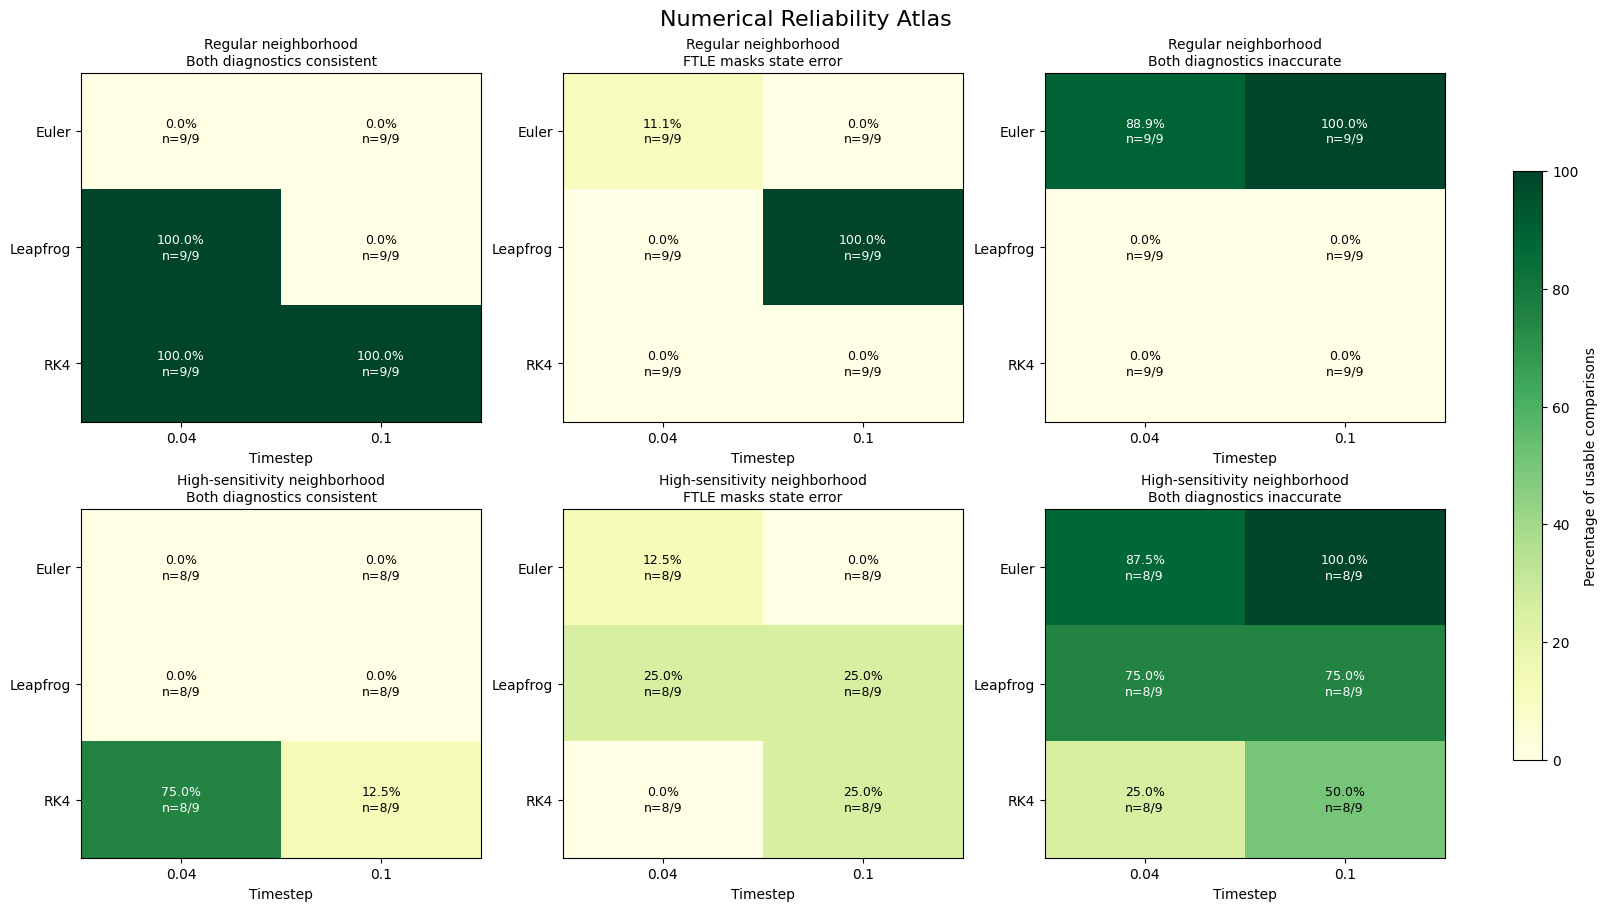

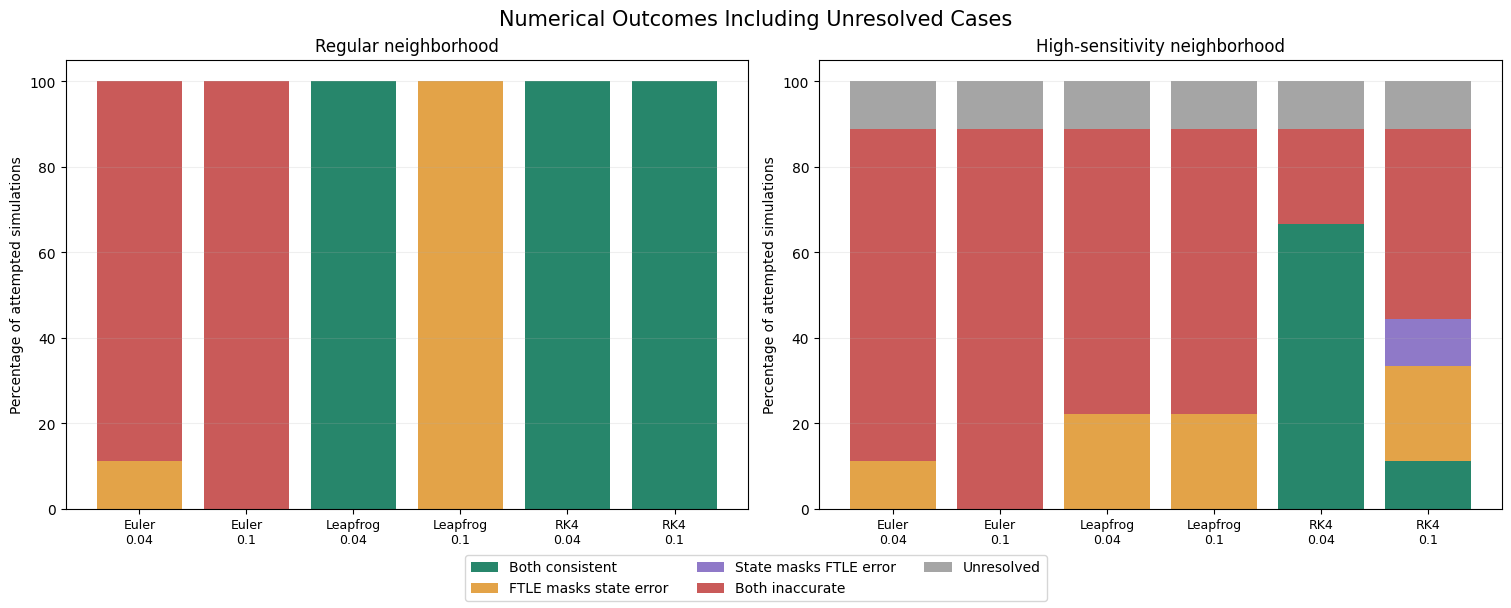


CONSERVATION SCREENING CONTINGENCY TABLE
               Both diagnostics pass  At least one fails
Jacobi passes                     15                   0
Jacobi fails                      19                  68

Jacobi screening threshold: 1e-06
Jacobi-passing comparisons: 15
Jacobi-passing but diagnostically inaccurate: 0
Conditional false-reassurance frequency: 0.00%


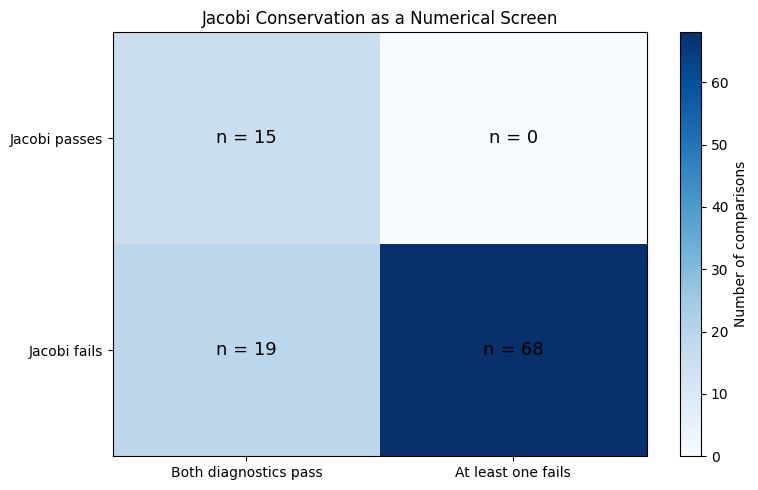

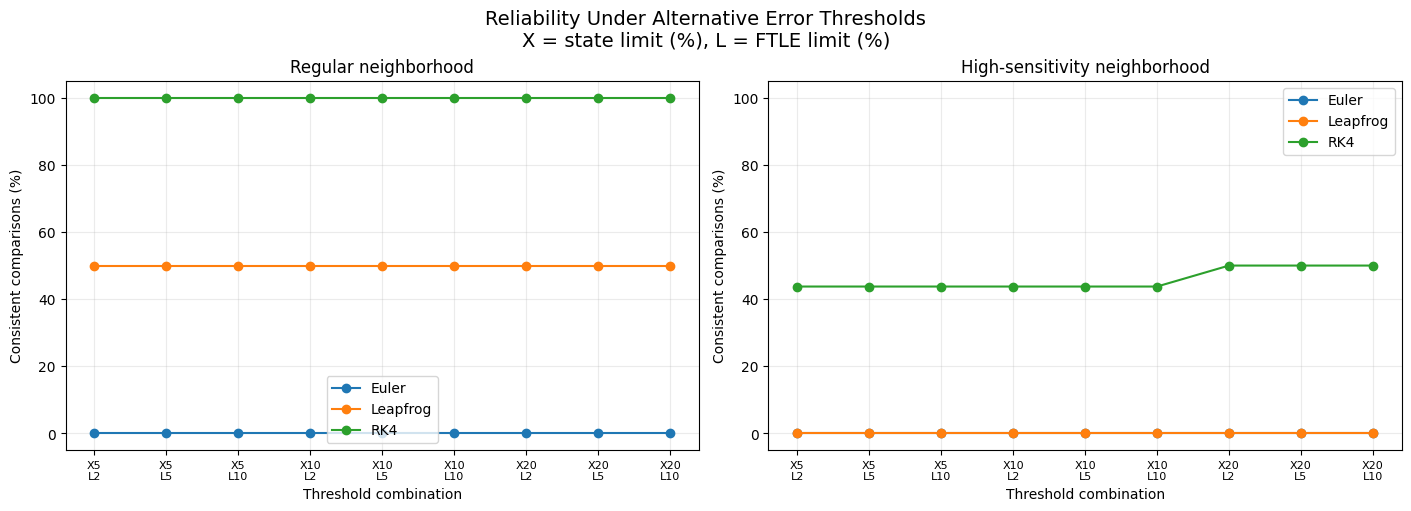


METHOD PERFORMANCE SUMMARY
integrator  attempted  verified  both_consistent_count  coverage_pct  consistent_of_verified_pct  consistent_of_attempted_pct
       RK4         36        34                     25         94.44                       73.53                        69.44
  Leapfrog         36        34                      9         94.44                       26.47                        25.00
     Euler         36        34                      0         94.44                        0.00                         0.00

OBJECTIVE 17 — DATA-DRIVEN CONCLUSIONS
RK4: 25/36 attempted runs met both accuracy limits; 34 had verified references.
Leapfrog: 9/36 attempted runs met both accuracy limits; 34 had verified references.
Euler: 0/36 attempted runs met both accuracy limits; 34 had verified references.

Jacobi false reassurance: 0 of 15 Jacobi-passing usable comparisons.

These conclusions concern numerical agreement, not asymptotic regular-versus-chaotic classification.

OBJECTIVE 

In [133]:

# ============================================================
# OBJECTIVE 17
# NUMERICAL RELIABILITY ATLAS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap

# ============================================================
# 1. LOAD AND VALIDATE PREVIOUS RESULTS
# ============================================================

if "data_15" in globals():
    df = data_15.copy()
else:
    df = pd.read_csv(
        "objective15_conservation_results.csv"
    )

required = [
    "case_id", "family", "integrator", "dt",
    "state_error_pct", "ftle_error_pct",
    "valid_comparison", "jacobi_drift",
    "jacobi_status"
]

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(
        "Missing required columns: " + str(missing)
    )

# Ensure boolean columns work after CSV reload.
def parse_bool(series):
    return (
        series.astype(str)
        .str.lower()
        .isin(["true", "1", "yes"])
    )

df["valid_comparison"] = parse_bool(
    df["valid_comparison"]
)

df["state_error_pct"] = pd.to_numeric(
    df["state_error_pct"], errors="coerce"
)

df["ftle_error_pct"] = pd.to_numeric(
    df["ftle_error_pct"], errors="coerce"
)

df["jacobi_drift"] = pd.to_numeric(
    df["jacobi_drift"], errors="coerce"
)

df["dt"] = pd.to_numeric(
    df["dt"], errors="coerce"
)

# Only completed, verified comparisons with
# usable trajectory, FTLE, and Jacobi measurements.
df["usable"] = (
    df["valid_comparison"]
    & df["jacobi_status"].eq("Completed")
    & np.isfinite(df["state_error_pct"])
    & np.isfinite(df["ftle_error_pct"])
    & np.isfinite(df["jacobi_drift"])
)

families = list(df["family"].dropna().unique())
methods = ["Euler", "Leapfrog", "RK4"]
timesteps = sorted(df["dt"].dropna().unique())

STATE_LIMIT = 10.0
FTLE_LIMIT = 5.0
JACOBI_LIMIT = 1e-6

print("=" * 72)
print("OBJECTIVE 17 — NUMERICAL RELIABILITY ATLAS")
print("=" * 72)

print("Total attempted comparisons:", len(df))
print("Usable comparisons:", df["usable"].sum())
print("Unresolved comparisons:", (~df["usable"]).sum())


# ============================================================
# 2. ASSIGN THE NUMERICAL RELIABILITY CATEGORIES
# ============================================================

def classify(row, state_limit=10.0, ftle_limit=5.0):

    if not row["usable"]:
        return "Unresolved"

    state_good = (
        row["state_error_pct"] <= state_limit
    )

    ftle_good = (
        row["ftle_error_pct"] <= ftle_limit
    )

    if state_good and ftle_good:
        return "Both consistent"

    if not state_good and ftle_good:
        return "FTLE masks state error"

    if state_good and not ftle_good:
        return "State masks FTLE error"

    return "Both inaccurate"


df["reliability_class"] = df.apply(
    classify, axis=1
)

categories = [
    "Both consistent",
    "FTLE masks state error",
    "State masks FTLE error",
    "Both inaccurate",
    "Unresolved"
]

category_colors = {
    "Both consistent": "#27866B",
    "FTLE masks state error": "#E3A348",
    "State masks FTLE error": "#8F79C8",
    "Both inaccurate": "#C95A59",
    "Unresolved": "#A5A5A5"
}

print("\nOVERALL CATEGORY COUNTS")
print("-" * 72)

print(
    df["reliability_class"]
    .value_counts()
    .reindex(categories, fill_value=0)
    .to_string()
)


# ============================================================
# 3. GROUPED RELIABILITY SUMMARY
# ============================================================

summary_rows = []

for family in families:
    for method in methods:
        for dt in timesteps:

            group = df[
                (df["family"] == family)
                & (df["integrator"] == method)
                & np.isclose(df["dt"], dt)
            ]

            usable = group[group["usable"]]

            attempted = len(group)
            n = len(usable)

            row = {
                "family": family,
                "integrator": method,
                "dt": dt,
                "attempted": attempted,
                "verified": n,
                "coverage_pct": (
                    100*n/attempted
                    if attempted else np.nan
                )
            }

            for category in categories[:-1]:

                count = (
                    usable["reliability_class"] == category
                ).sum()

                row[
                    category + "_count"
                ] = int(count)

                row[
                    category + "_pct"
                ] = (
                    100*count/n if n else np.nan
                )

            row["unresolved_count"] = attempted - n

            row["median_state_error_pct"] = (
                usable["state_error_pct"].median()
                if n else np.nan
            )

            row["median_ftle_error_pct"] = (
                usable["ftle_error_pct"].median()
                if n else np.nan
            )

            row["median_jacobi_drift"] = (
                usable["jacobi_drift"].median()
                if n else np.nan
            )

            summary_rows.append(row)


atlas_summary = pd.DataFrame(summary_rows)

print("\nRELIABILITY BY METHOD AND INITIAL-CONDITION FAMILY")
print("=" * 72)

display_columns = [
    "family", "integrator", "dt",
    "verified", "attempted", "coverage_pct",
    "Both consistent_pct",
    "FTLE masks state error_pct",
    "State masks FTLE error_pct",
    "Both inaccurate_pct"
]

print(
    atlas_summary[display_columns].to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


# ============================================================
# 4. FIGURE 1 — RELIABILITY ATLAS
# ============================================================

# Six heatmaps:
# Two initial-condition families x three diagnostics.
#
# Heatmap columns: timestep.
# Heatmap rows: integrator.
#
# Each cell reports percent of usable comparisons.

metrics = [
    ("Both consistent_pct", "Both diagnostics consistent"),
    ("FTLE masks state error_pct", "FTLE masks state error"),
    ("Both inaccurate_pct", "Both diagnostics inaccurate")
]

fig, axes = plt.subplots(
    len(families), len(metrics),
    figsize=(16, 9),
    constrained_layout=True,
    squeeze=False
)

for i, family in enumerate(families):

    subset = atlas_summary[
        atlas_summary["family"] == family
    ]

    for j, (column, title) in enumerate(metrics):

        ax = axes[i, j]

        matrix = np.full(
            (len(methods), len(timesteps)),
            np.nan
        )

        counts = np.empty(
            (len(methods), len(timesteps)),
            dtype=object
        )

        for mi, method in enumerate(methods):
            for ti, dt in enumerate(timesteps):

                selected = subset[
                    (subset["integrator"] == method)
                    & np.isclose(subset["dt"], dt)
                ]

                if selected.empty:
                    counts[mi, ti] = "0/0"
                    continue

                record = selected.iloc[0]

                matrix[mi, ti] = record[column]

                counts[mi, ti] = (
                    f'{int(record["verified"])}/'
                    f'{int(record["attempted"])}'
                )

        image = ax.imshow(
            matrix,
            vmin=0,
            vmax=100,
            aspect="auto",
            cmap="YlGn"
        )

        ax.set_xticks(range(len(timesteps)))
        ax.set_xticklabels([
            f"{dt:g}" for dt in timesteps
        ])

        ax.set_yticks(range(len(methods)))
        ax.set_yticklabels(methods)

        ax.set_xlabel("Timestep")
        ax.set_title(
            f"{family}\n{title}",
            fontsize=10
        )

        for mi in range(len(methods)):
            for ti in range(len(timesteps)):

                value = matrix[mi, ti]

                label = (
                    f"{value:.1f}%\n"
                    f"n={counts[mi, ti]}"
                    if np.isfinite(value)
                    else "N/A"
                )

                ax.text(
                    ti, mi, label,
                    ha="center", va="center",
                    fontsize=9,
                    color=(
                        "white"
                        if np.isfinite(value) and value > 70
                        else "black"
                    )
                )

fig.colorbar(
    image,
    ax=axes.ravel().tolist(),
    shrink=0.75,
    label="Percentage of usable comparisons"
)

fig.suptitle(
    "Numerical Reliability Atlas",
    fontsize=16
)

plt.show()


# ============================================================
# 5. FIGURE 2 — COMPLETE OUTCOME DISTRIBUTIONS
# ============================================================

# Unlike the heatmaps, these bars use ALL attempted
# simulations in the denominator and explicitly show
# unresolved comparisons.

fig, axes = plt.subplots(
    1, len(families),
    figsize=(15, 6),
    constrained_layout=True,
    squeeze=False
)

for ax, family in zip(axes.ravel(), families):

    subset = atlas_summary[
        atlas_summary["family"] == family
    ].copy()

    labels = [
        f"{row.integrator}\n{row.dt:g}"
        for row in subset.itertuples()
    ]

    x = np.arange(len(subset))

    bottom = np.zeros(len(subset))

    for category in categories:

        if category == "Unresolved":
            values = (
                100*subset["unresolved_count"]
                / subset["attempted"]
            )
        else:
            values = (
                100*subset[category + "_count"]
                / subset["attempted"]
            )

        ax.bar(
            x, values,
            bottom=bottom,
            color=category_colors[category],
            label=category
        )

        bottom += values.to_numpy()

    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=9)
    ax.set_ylim(0, 105)
    ax.set_ylabel("Percentage of attempted simulations")
    ax.set_title(family)
    ax.grid(alpha=0.2, axis="y")

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="outside lower center",
    ncol=3
)

fig.suptitle(
    "Numerical Outcomes Including Unresolved Cases",
    fontsize=15
)

plt.show()


# ============================================================
# 6. CONSERVATION AS A RELIABILITY SCREEN
# ============================================================

valid = df[df["usable"]].copy()

valid["jacobi_pass"] = (
    valid["jacobi_drift"] < JACOBI_LIMIT
)

valid["both_consistent"] = (
    valid["reliability_class"] == "Both consistent"
)

valid["any_diagnostic_failure"] = (
    ~valid["both_consistent"]
)

conservation_table = pd.crosstab(
    valid["jacobi_pass"],
    valid["any_diagnostic_failure"]
).reindex(
    index=[True, False],
    columns=[False, True],
    fill_value=0
)

conservation_table.index = [
    "Jacobi passes",
    "Jacobi fails"
]

conservation_table.columns = [
    "Both diagnostics pass",
    "At least one fails"
]

print("\nCONSERVATION SCREENING CONTINGENCY TABLE")
print("=" * 72)
print(conservation_table.to_string())

n_jacobi_pass = int(valid["jacobi_pass"].sum())

n_false_reassurance = int((
    valid["jacobi_pass"]
    & valid["any_diagnostic_failure"]
).sum())

conditional_false_reassurance = (
    100*n_false_reassurance/n_jacobi_pass
    if n_jacobi_pass else np.nan
)

print("\nJacobi screening threshold:", JACOBI_LIMIT)

print("Jacobi-passing comparisons:", n_jacobi_pass)

print(
    "Jacobi-passing but diagnostically inaccurate:",
    n_false_reassurance
)

print(
    "Conditional false-reassurance frequency:",
    f"{conditional_false_reassurance:.2f}%"
    if np.isfinite(conditional_false_reassurance)
    else "Undefined"
)


# ============================================================
# 7. FIGURE 3 — JACOBI SCREENING PERFORMANCE
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))

matrix = conservation_table.to_numpy()

im = ax.imshow(
    matrix,
    cmap="Blues",
    aspect="auto"
)

ax.set_xticks([0, 1])
ax.set_xticklabels(conservation_table.columns)

ax.set_yticks([0, 1])
ax.set_yticklabels(conservation_table.index)

ax.set_title("Jacobi Conservation as a Numerical Screen")

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):

        ax.text(
            j, i,
            f"n = {matrix[i, j]}",
            ha="center",
            va="center",
            fontsize=13
        )

plt.colorbar(
    im, ax=ax,
    label="Number of comparisons"
)

plt.tight_layout()
plt.show()


# ============================================================
# 8. FIGURE 4 — THRESHOLD ROBUSTNESS
# ============================================================

state_limits = [5.0, 10.0, 20.0]
ftle_limits = [2.0, 5.0, 10.0]

robustness_records = []

for family in families:
    for method in methods:

        group = valid[
            (valid["family"] == family)
            & (valid["integrator"] == method)
        ]

        for state_limit in state_limits:
            for ftle_limit in ftle_limits:

                good = (
                    (group["state_error_pct"] <= state_limit)
                    & (group["ftle_error_pct"] <= ftle_limit)
                )

                robustness_records.append({
                    "family": family,
                    "integrator": method,
                    "state_limit": state_limit,
                    "ftle_limit": ftle_limit,
                    "consistent_pct": (
                        100*good.mean()
                        if len(group) else np.nan
                    ),
                    "n": len(group)
                })

robustness_df = pd.DataFrame(robustness_records)

fig, axes = plt.subplots(
    1, len(families),
    figsize=(14, 5),
    constrained_layout=True,
    squeeze=False
)

# Each panel shows the fraction meeting both accuracy
# limits for each method, across all threshold pairs.

for ax, family in zip(axes.ravel(), families):

    subset = robustness_df[
        robustness_df["family"] == family
    ]

    for method in methods:

        group = subset[
            subset["integrator"] == method
        ]

        ax.plot(
            range(len(group)),
            group["consistent_pct"],
            "o-",
            label=method
        )

    ax.set_title(family)
    ax.set_xlabel("Threshold combination")
    ax.set_ylabel("Consistent comparisons (%)")
    ax.set_ylim(-5, 105)
    ax.grid(alpha=0.25)
    ax.legend()

    labels = [
        f"X{a:g}\nL{b:g}"
        for a in state_limits
        for b in ftle_limits
    ]

    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=8)

fig.suptitle(
    "Reliability Under Alternative Error Thresholds\n"
    "X = state limit (%), L = FTLE limit (%)",
    fontsize=14
)

plt.show()


# ============================================================
# 9. QUANTITATIVE METHOD RANKING
# ============================================================

# Rankings are descriptive and limited to this grid.
# We report coverage separately so failed cases
# cannot silently count as successes.

method_summary = (
    df.groupby("integrator")
    .agg(
        attempted=("case_id", "size"),
        verified=("usable", "sum")
    )
    .reset_index()
)

passing_counts = (
    valid.groupby("integrator")["both_consistent"]
    .sum()
)

method_summary["both_consistent_count"] = (
    method_summary["integrator"]
    .map(passing_counts)
    .fillna(0)
    .astype(int)
)

method_summary["coverage_pct"] = (
    100*method_summary["verified"]
    / method_summary["attempted"]
)

method_summary["consistent_of_verified_pct"] = np.where(
    method_summary["verified"] > 0,
    100*method_summary["both_consistent_count"]
    / method_summary["verified"],
    np.nan
)

method_summary["consistent_of_attempted_pct"] = (
    100*method_summary["both_consistent_count"]
    / method_summary["attempted"]
)

method_summary = method_summary.sort_values(
    "consistent_of_attempted_pct",
    ascending=False
)

print("\nMETHOD PERFORMANCE SUMMARY")
print("=" * 72)

print(
    method_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


# ============================================================
# 10. RESEARCH CONCLUSIONS FROM OBSERVED DATA
# ============================================================

print("\n" + "=" * 72)
print("OBJECTIVE 17 — DATA-DRIVEN CONCLUSIONS")
print("=" * 72)

for _, row in method_summary.iterrows():

    print(
        f'{row["integrator"]}: '
        f'{int(row["both_consistent_count"])}/'
        f'{int(row["attempted"])} attempted runs '
        f'met both accuracy limits; '
        f'{int(row["verified"])} had verified references.'
    )

print()

print(
    "Jacobi false reassurance:",
    n_false_reassurance,
    "of",
    n_jacobi_pass,
    "Jacobi-passing usable comparisons."
)

print(
    "\nThese conclusions concern numerical agreement,"
    " not asymptotic regular-versus-chaotic classification."
)


# ============================================================
# 11. EXPORT MANUSCRIPT-READY TABLES
# ============================================================

df.to_csv(
    "objective17_classified_experiments.csv",
    index=False
)

atlas_summary.to_csv(
    "objective17_reliability_atlas.csv",
    index=False
)

robustness_df.to_csv(
    "objective17_threshold_robustness.csv",
    index=False
)

method_summary.to_csv(
    "objective17_method_comparison.csv",
    index=False
)

conservation_table.to_csv(
    "objective17_conservation_screening.csv"
)

# Save the final processed data for future analysis.
objective17_results = {
    "classified_data": df,
    "atlas": atlas_summary,
    "robustness": robustness_df,
    "methods": method_summary,
    "conservation": conservation_table
}

print("\n" + "=" * 72)
print("OBJECTIVE 17 COMPLETED")
print("=" * 72)

print("Five CSV files exported.")
print("Results retained as objective17_results.")



# Objective 18 — Independent Validation of Gravitational Sensitivity Measurements

## 18.1 Why independent validation matters

Throughout our investigation, we used adaptive DOP853 integration to establish numerical reference trajectories.

We demonstrated that different numerical methods can produce different gravitational trajectories, different finite-time Lyapunov estimates, and different orbital outcomes.

However, comparing numerical methods against one reference solver has a limitation: the reference itself is an approximation.

A result that agrees with DOP853 may still contain numerical errors.

We therefore introduce an independent integration algorithm: Radau.

## 18.2 Two different numerical approaches

### DOP853 — Explicit Runge–Kutta integration

DOP853 uses a high-order explicit numerical integration formula with adaptive timestep control.

It is particularly effective for smooth, nonstiff orbital dynamics when sufficiently accurate tolerances are selected.

### Radau — Implicit collocation integration

Radau uses an implicit Runge–Kutta collocation method.

Unlike DOP853, each numerical step involves solving an implicit system of equations.

This gives us an algorithmically different comparison.

Both methods still use finite-precision arithmetic, so agreement does not constitute a mathematical proof of exactness.

## 18.3 The three validation configurations

We will investigate:

**C05 — Regular-looking neighborhood**

The central configuration of the weaker-perturbation family.

**C12 — Numerically demanding configuration**

This configuration failed our original adaptive-reference verification despite having excellent Jacobi conservation.

**C14 — High-sensitivity neighborhood**

The central high-sensitivity configuration, previously identified as a strong chaos candidate.

Each configuration is retrieved directly from the existing Objective 14 ensemble.

## 18.4 What we will compare

For every configuration, we integrate the same initial conditions through:

$$
T=120
$$

We compare:

1. Physical positions relative to the central star.
2. Relative velocities.
3. Maximum sampled Jacobi-constant drift.
4. Finite-time Lyapunov exponent histories.
5. Agreement between DOP853 and Radau.

The variational equations are integrated alongside the physical equations.

The test-particle perturbation is periodically renormalized to avoid numerical overflow.

## 18.5 Independent agreement

Let the final star-relative phase-space state be:

$$
X(T)=(\mathbf r_{\mathrm{rel}},\mathbf v_{\mathrm{rel}})
$$

We define the relative discrepancy:

$$
\epsilon_X=
\frac{\|X_{\mathrm{DOP853}}-X_{\mathrm{Radau}}\|}
{\|X_{\mathrm{DOP853}}\|}
$$

For the finite-time Lyapunov estimate:

$$
\epsilon_\lambda=
|\lambda_T^{\mathrm{DOP853}}-\lambda_T^{\mathrm{Radau}}|
$$

The first quantity is a relative state disagreement. The second is an absolute disagreement between Lyapunov estimates.

We will report both rather than assuming they have equivalent numerical significance.

## 18.6 Numerical refinement

In addition to comparing the two algorithms, we will run each using tighter numerical settings.

This separates two questions:

- Does each method converge under refinement?
- Do two distinct methods agree when sufficiently refined?

The comparison is stronger when both conditions hold.

## 18.7 Interpretation

If DOP853 and Radau agree closely, our earlier finite-time measurements gain credibility.

If the two algorithms disagree, the affected configuration remains unresolved until we investigate numerical resolution or conditioning.

If the trajectories lose pointwise agreement while their Lyapunov estimates remain similar, that suggests the two observables have different numerical reproducibility properties.

We must not automatically interpret numerical divergence as physical chaos.

Our goal is independent finite-time numerical validation, not proof of an infinite-time Lyapunov exponent.

## 18.8 Final research contribution

Combined with our previous objectives, this experiment will provide:

- A regular gravitational control
- A numerically challenging encounter case
- A strong finite-time sensitivity candidate
- An ensemble-based reliability atlas
- Independent cross-method numerical validation

This gives us the evidence needed to assess which conclusions are strong enough for the final research manuscript.



VALIDATING C05
Running: DOP853 standard
  Final FTLE: 4.08326792e-02
  Maximum Jacobi drift: 1.87181395e-15
Running: DOP853 refined
  Final FTLE: 4.08326792e-02
  Maximum Jacobi drift: 1.00789982e-15
Running: Radau standard
  Final FTLE: 4.08326792e-02
  Maximum Jacobi drift: 2.67338228e-12
Running: Radau refined
  Final FTLE: 4.08326792e-02
  Maximum Jacobi drift: 2.57734383e-14

VALIDATING C12
Running: DOP853 standard
  Final FTLE: 1.32200939e-01
  Maximum Jacobi drift: 1.58296056e-10
Running: DOP853 refined
  Final FTLE: 1.32203220e-01
  Maximum Jacobi drift: 8.52921205e-13
Running: Radau standard
  Final FTLE: 1.32203602e-01
  Maximum Jacobi drift: 9.66966398e-12
Running: Radau refined
  Final FTLE: 1.32203235e-01
  Maximum Jacobi drift: 6.73358846e-13

VALIDATING C14
Running: DOP853 standard
  Final FTLE: 9.10373489e-02
  Maximum Jacobi drift: 1.65585504e-13
Running: DOP853 refined
  Final FTLE: 9.10373489e-02
  Maximum Jacobi drift: 7.35615044e-15
Running: Radau standard
  Final

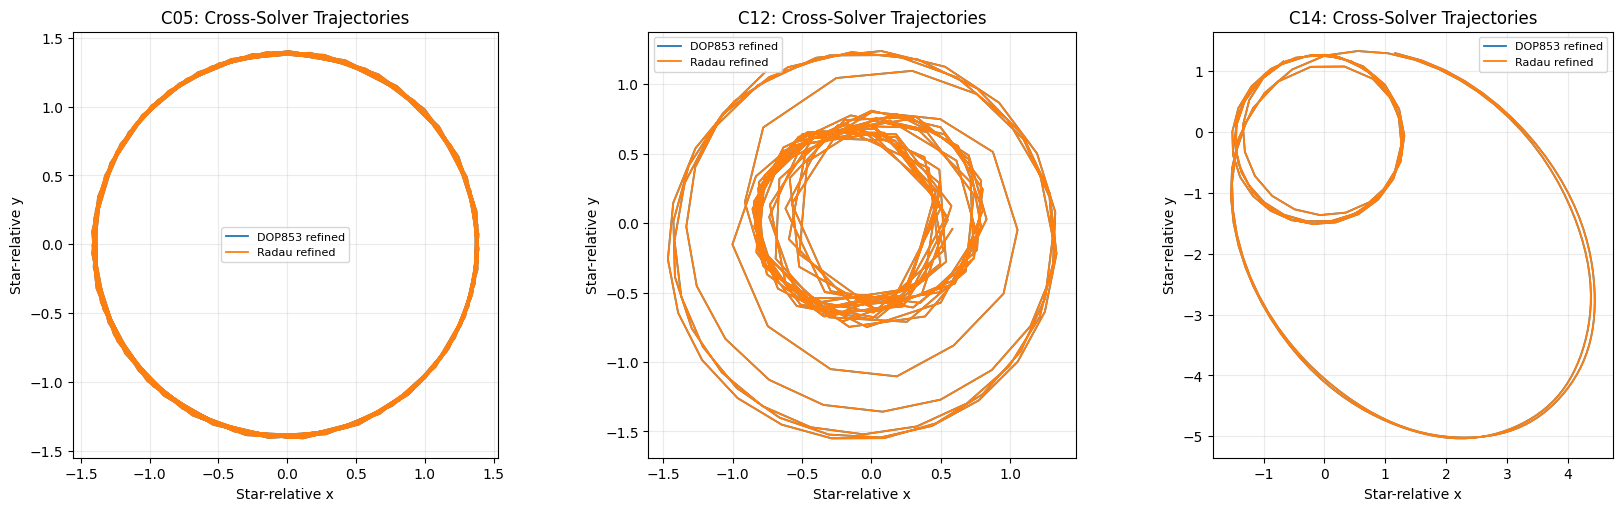

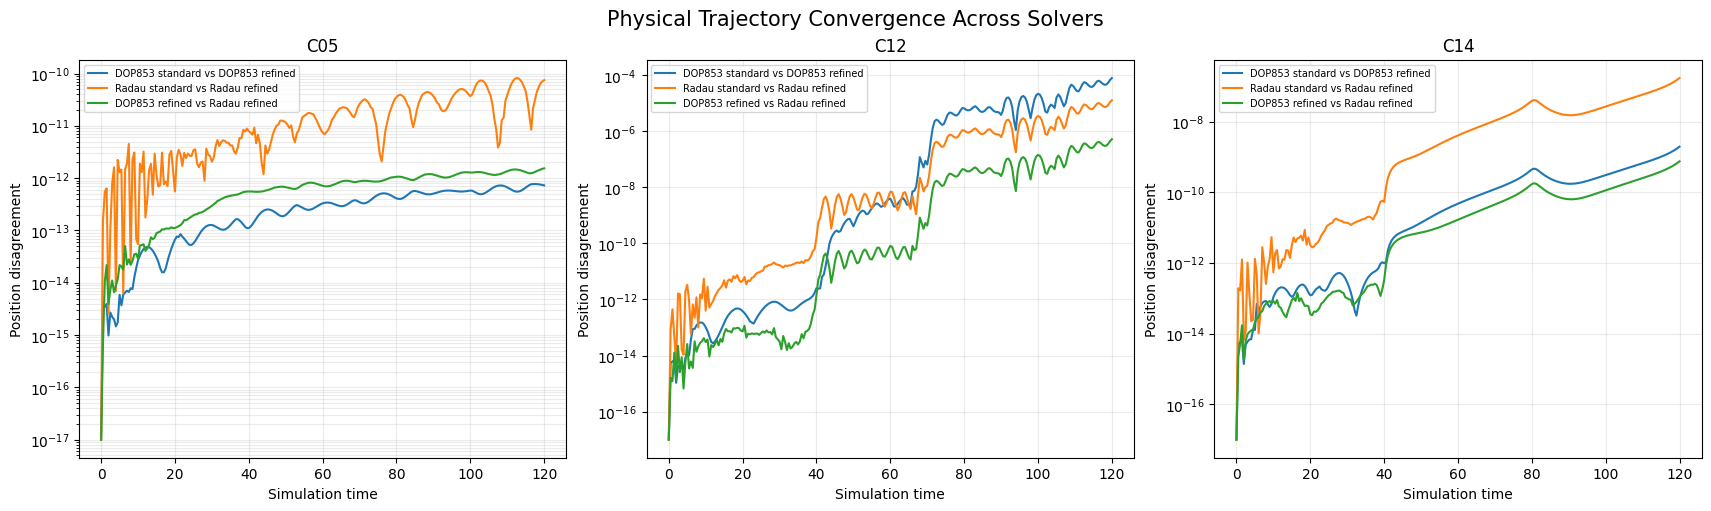

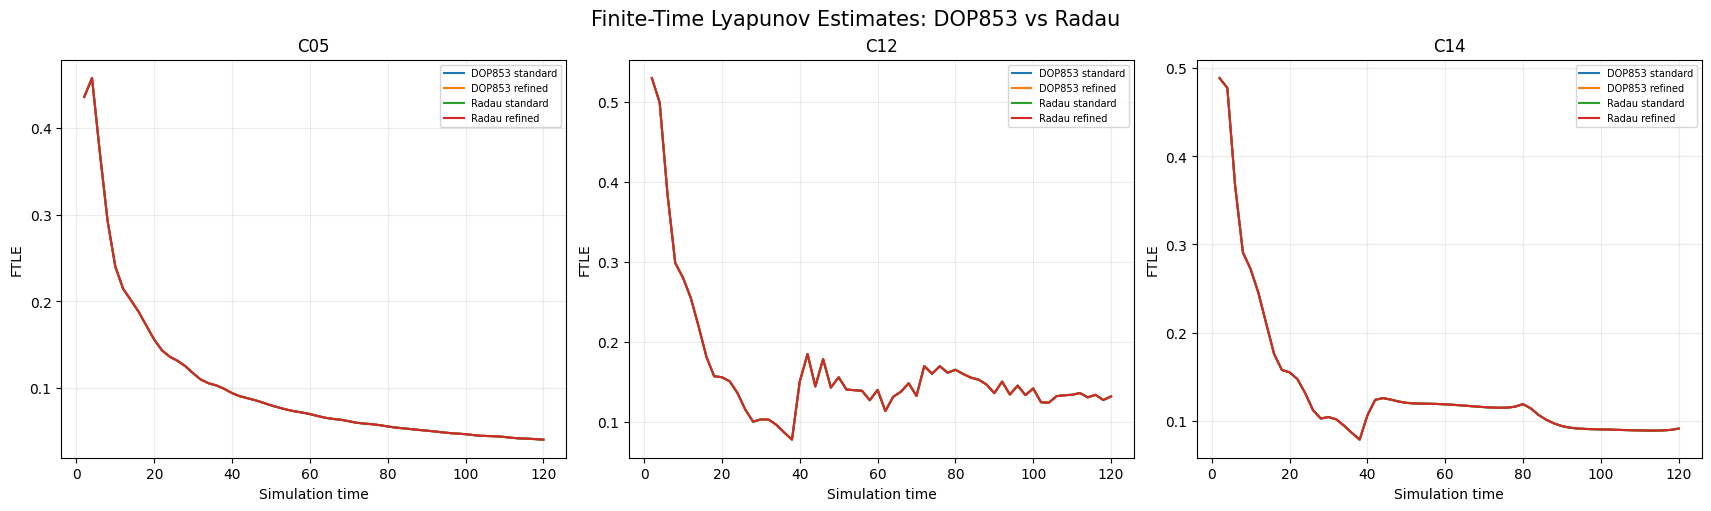

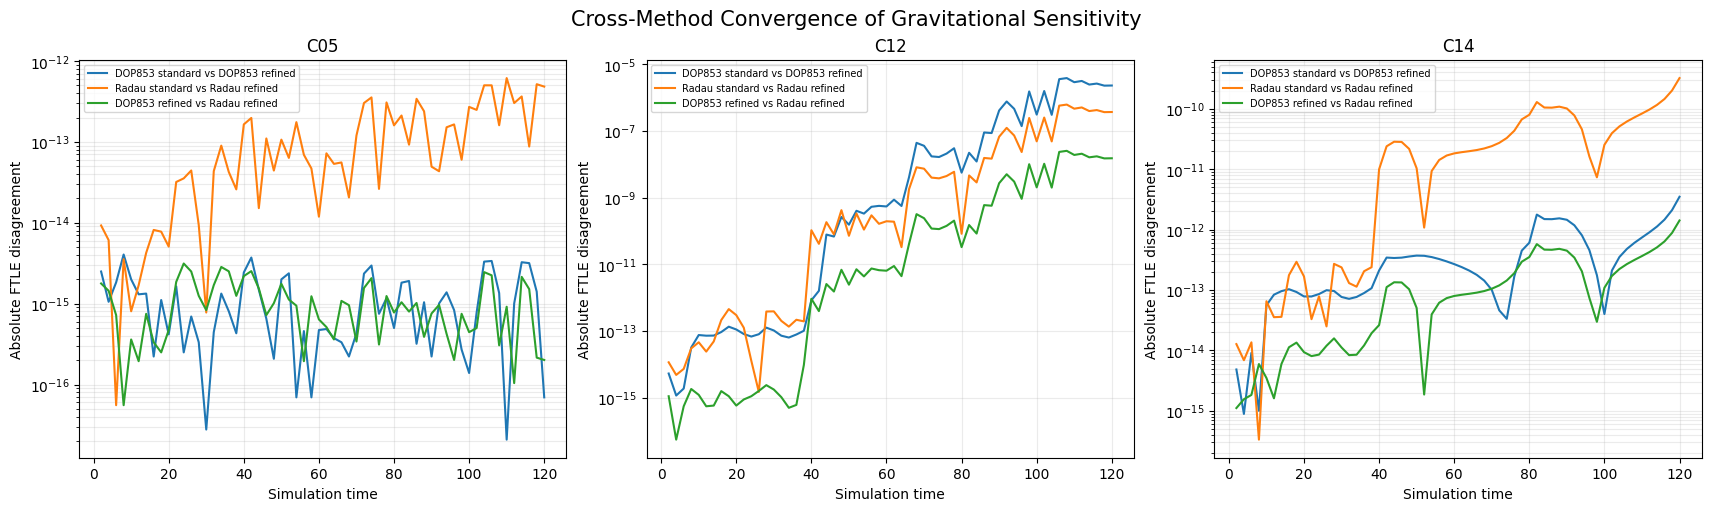

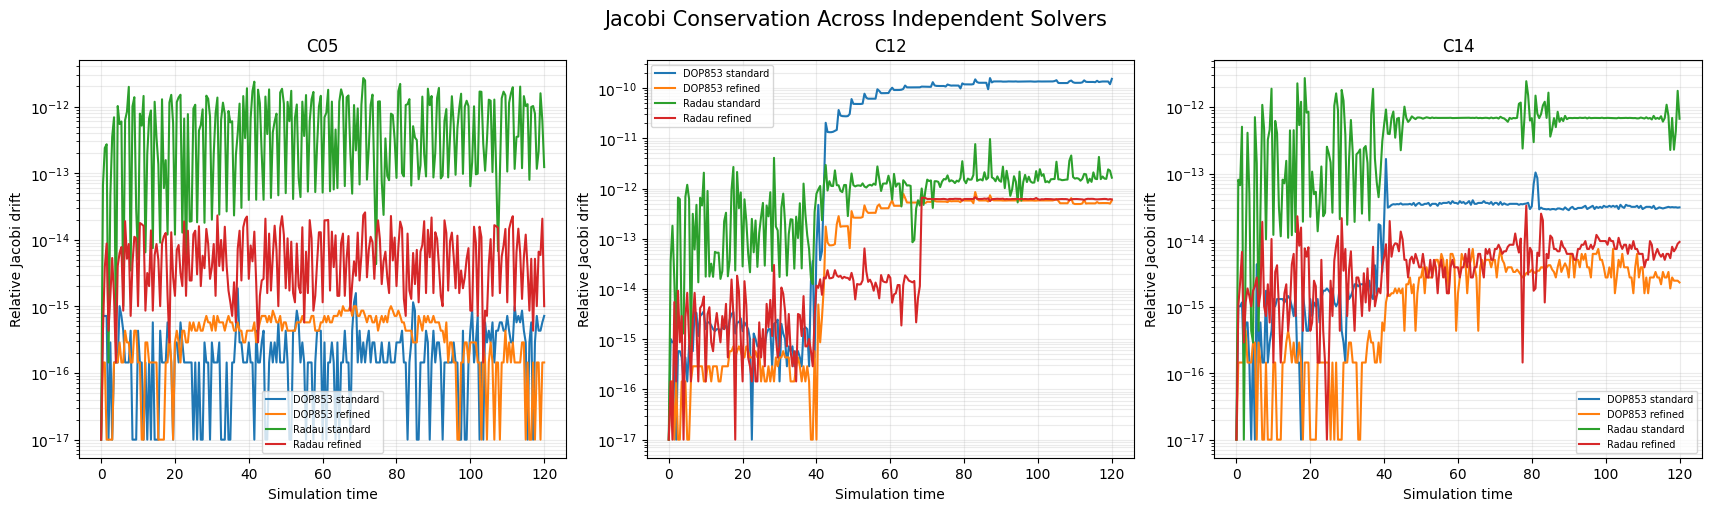


OBJECTIVE 18 — VALIDATION SUMMARY

C05
Relative final state disagreement: 1.093687e-12
Final FTLE disagreement: 2.012279e-16
Maximum position disagreement: 1.539555e-12

C12
Relative final state disagreement: 7.609832e-07
Final FTLE disagreement: 1.504431e-08
Maximum position disagreement: 5.164775e-07

C14
Relative final state disagreement: 4.009668e-10
Final FTLE disagreement: 1.416478e-12
Maximum position disagreement: 7.470001e-10

OBJECTIVE 18 COMPLETE.
Independent numerical comparisons exported.


In [134]:

# ============================================================
# OBJECTIVE 18 — INDEPENDENT SOLVER VALIDATION
# DOP853 vs RADAU
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp

G18 = 1.0
T_END18 = 120.0
BLOCK18 = 2.0
SAMPLE_DT18 = 0.5

CASE_IDS18 = ["C05", "C12", "C14"]

SOLVER_SETTINGS18 = {
    "DOP853 standard": {
        "method": "DOP853",
        "rtol": 1e-10,
        "atol": 1e-12,
        "max_step": 0.1
    },
    "DOP853 refined": {
        "method": "DOP853",
        "rtol": 1e-12,
        "atol": 1e-14,
        "max_step": 0.05
    },
    "Radau standard": {
        "method": "Radau",
        "rtol": 1e-10,
        "atol": 1e-12,
        "max_step": 0.1
    },
    "Radau refined": {
        "method": "Radau",
        "rtol": 1e-12,
        "atol": 1e-14,
        "max_step": 0.05
    }
}

if "ensemble" not in globals():
    raise RuntimeError(
        "Objective 14 ensemble is required."
    )

cases18 = {
    case["case_id"]: case
    for case in ensemble
    if case["case_id"] in CASE_IDS18
}

if len(cases18) != len(CASE_IDS18):
    raise ValueError(
        "One or more validation cases were not found."
    )


# ============================================================
# 1. PHYSICAL ACCELERATIONS
# ============================================================

def acceleration18(r, masses):

    a = np.zeros_like(r)

    for i in range(3):
        for j in range(3):

            if i == j or masses[j] == 0:
                continue

            R = r[j] - r[i]
            d2 = np.dot(R, R)

            if d2 <= 1e-24:
                raise FloatingPointError(
                    "Near-collision singularity."
                )

            a[i] += (
                G18 * masses[j] * R / d2**1.5
            )

    return a


# ============================================================
# 2. TEST-PARTICLE VARIATIONAL EQUATIONS
# ============================================================

def tangent_acceleration18(r, dr, masses):

    da = np.zeros(2)

    for j in [0, 1]:

        R = r[j] - r[2]
        dR = -dr

        d2 = np.dot(R, R)

        if d2 <= 1e-24:
            raise FloatingPointError(
                "Variational singularity."
            )

        da += G18 * masses[j] * (
            dR / d2**1.5
            - 3*np.dot(R, dR)*R/d2**2.5
        )

    return da


# ============================================================
# 3. COMBINED PHYSICAL + VARIATIONAL EQUATIONS
# ============================================================

def combined_rhs18(t, y, masses):

    r = y[:6].reshape(3, 2)
    v = y[6:12].reshape(3, 2)

    dr = y[12:14]
    dv = y[14:16]

    a = acceleration18(r, masses)

    da = tangent_acceleration18(
        r, dr, masses
    )

    return np.concatenate([
        v.ravel(),
        a.ravel(),
        dv,
        da
    ])


# ============================================================
# 4. JACOBI CONSTANT IN THE BARYCENTRIC FRAME
# ============================================================

def jacobi18(r, v, masses, t, r0, v0):

    m1, m2 = masses[:2]
    M = m1 + m2

    barycenter0 = (
        m1*r0[0] + m2*r0[1]
    ) / M

    barycenter_v = (
        m1*v0[0] + m2*v0[1]
    ) / M

    initial_R = r0[1] - r0[0]
    initial_V = v0[1] - v0[0]

    separation2 = np.dot(
        initial_R, initial_R
    )

    omega = (
        initial_R[0]*initial_V[1]
        - initial_R[1]*initial_V[0]
    ) / separation2

    origin = barycenter0 + t*barycenter_v

    q = r[2] - origin
    u = v[2] - barycenter_v

    rotation_velocity = omega*np.array([
        -q[1], q[0]
    ])

    rotating_velocity = u - rotation_velocity

    d1 = np.linalg.norm(r[2] - r[0])
    d2 = np.linalg.norm(r[2] - r[1])

    potential = (
        G18*m1/d1
        + G18*m2/d2
        + 0.5*omega**2*np.dot(q, q)
    )

    return (
        2*potential
        - np.dot(
            rotating_velocity,
            rotating_velocity
        )
    )


# ============================================================
# 5. SOLVER WITH PERIODIC TANGENT NORMALIZATION
# ============================================================

def run_validation18(case, settings):

    r0, v0, masses = case["system"]

    r0 = np.asarray(r0, dtype=float)
    v0 = np.asarray(v0, dtype=float)
    masses = np.asarray(masses, dtype=float)

    # Perturb only the massless test particle.
    dr0 = np.array([1.0, 0.0])
    dv0 = np.array([0.0, 0.0])

    y = np.concatenate([
        r0.ravel(),
        v0.ravel(),
        dr0,
        dv0
    ])

    t = 0.0
    accumulated_growth = 0.0

    times = []
    positions = []
    velocities = []
    jacobi_history = []

    ftle_times = []
    ftle_values = []

    nfev_total = 0

    while t < T_END18 - 1e-12:

        t_next = min(
            t + BLOCK18,
            T_END18
        )

        n_samples = int(round(
            (t_next-t)/SAMPLE_DT18
        ))

        grid = np.linspace(
            t,
            t_next,
            n_samples+1
        )

        sol = solve_ivp(
            combined_rhs18,
            (t, t_next),
            y,
            args=(masses,),
            method=settings["method"],
            rtol=settings["rtol"],
            atol=settings["atol"],
            max_step=settings["max_step"],
            t_eval=grid
        )

        if not sol.success:
            raise RuntimeError(sol.message)

        nfev_total += sol.nfev

        # Avoid duplicate endpoints between blocks.
        start_index = 0 if len(times) == 0 else 1

        for k in range(start_index, len(sol.t)):

            tk = sol.t[k]

            state = sol.y[:, k]

            r = state[:6].reshape(3, 2)
            v = state[6:12].reshape(3, 2)

            q = r[2] - r[0]
            u = v[2] - v[0]

            times.append(tk)
            positions.append(q.copy())
            velocities.append(u.copy())

            jacobi_history.append(
                jacobi18(
                    r, v, masses,
                    tk, r0, v0
                )
            )

        # Final state before renormalization.
        y = sol.y[:, -1].copy()

        dr = y[12:14]
        dv = y[14:16]

        growth = np.sqrt(
            np.dot(dr, dr)
            + np.dot(dv, dv)
        )

        if not np.isfinite(growth) or growth <= 0:
            raise FloatingPointError(
                "Invalid tangent growth."
            )

        accumulated_growth += np.log(growth)

        # Normalize only the tangent variables.
        y[12:16] /= growth

        t = t_next

        ftle_times.append(t)
        ftle_values.append(
            accumulated_growth/t
        )

    times = np.array(times)
    positions = np.array(positions)
    velocities = np.array(velocities)
    jacobi_history = np.array(jacobi_history)

    jacobi_error = (
        np.abs(
            jacobi_history-jacobi_history[0]
        )
        / max(
            abs(jacobi_history[0]),
            1e-15
        )
    )

    planet_distance = np.linalg.norm(
        # Planet-relative position can be reconstructed
        # independently from a full-state solver;
        # here the validation focuses on star-relative
        # phase space and the conserved invariant.
        positions,
        axis=1
    )

    return {
        "time": times,
        "position": positions,
        "velocity": velocities,
        "jacobi_error": jacobi_error,
        "ftle_time": np.array(ftle_times),
        "ftle": np.array(ftle_values),
        "nfev": nfev_total
    }


# ============================================================
# 6. PERFORM THE INDEPENDENT VALIDATIONS
# ============================================================

validation_results18 = {}

for cid in CASE_IDS18:

    validation_results18[cid] = {}

    print("\n" + "="*65)
    print("VALIDATING", cid)
    print("="*65)

    for solver_name, settings in SOLVER_SETTINGS18.items():

        print("Running:", solver_name)

        result = run_validation18(
            cases18[cid],
            settings
        )

        validation_results18[cid][solver_name] = result

        print(
            f"  Final FTLE: {result['ftle'][-1]:.8e}"
        )

        print(
            "  Maximum Jacobi drift:",
            f"{result['jacobi_error'].max():.8e}"
        )


# ============================================================
# 7. CALCULATE CROSS-SOLVER DISAGREEMENTS
# ============================================================

comparison_rows18 = []

comparison_pairs18 = [
    ("DOP853 standard", "DOP853 refined"),
    ("Radau standard", "Radau refined"),
    ("DOP853 refined", "Radau refined")
]

disagreement_histories18 = {}

for cid in CASE_IDS18:

    disagreement_histories18[cid] = {}

    for name_A, name_B in comparison_pairs18:

        A = validation_results18[cid][name_A]
        B = validation_results18[cid][name_B]

        if not np.allclose(A["time"], B["time"]):
            raise ValueError(
                "Physical output times do not agree."
            )

        if not np.allclose(
            A["ftle_time"], B["ftle_time"]
        ):
            raise ValueError(
                "FTLE observation times do not agree."
            )

        position_error = np.linalg.norm(
            A["position"]-B["position"],
            axis=1
        )

        velocity_error = np.linalg.norm(
            A["velocity"]-B["velocity"],
            axis=1
        )

        # Include both positions and velocities.
        state_A = np.concatenate([
            A["position"][-1],
            A["velocity"][-1]
        ])

        state_B = np.concatenate([
            B["position"][-1],
            B["velocity"][-1]
        ])

        relative_state_error = (
            np.linalg.norm(state_A-state_B)
            / max(np.linalg.norm(state_A), 1e-15)
        )

        ftle_error = np.abs(
            A["ftle"]-B["ftle"]
        )

        pair_label = f"{name_A} vs {name_B}"

        disagreement_histories18[cid][pair_label] = {
            "time": A["time"],
            "position_error": position_error,
            "velocity_error": velocity_error,
            "ftle_time": A["ftle_time"],
            "ftle_error": ftle_error
        }

        comparison_rows18.append({
            "case": cid,
            "comparison": pair_label,
            "max_position_error": position_error.max(),
            "final_position_error": position_error[-1],
            "max_velocity_error": velocity_error.max(),
            "relative_final_state_error":
                relative_state_error,
            "final_ftle_error": ftle_error[-1],
            "max_ftle_error": ftle_error.max()
        })

comparison_df18 = pd.DataFrame(comparison_rows18)

print("\n" + "="*80)
print("INDEPENDENT SOLVER COMPARISON")
print("="*80)

print(
    comparison_df18.to_string(
        index=False,
        float_format=lambda x: f"{x:.6e}"
    )
)


# ============================================================
# 8. FIGURE A — PHYSICAL TRAJECTORY AGREEMENT
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    constrained_layout=True
)

for ax, cid in zip(axes, CASE_IDS18):

    for name in [
        "DOP853 refined",
        "Radau refined"
    ]:

        result = validation_results18[cid][name]

        ax.plot(
            result["position"][:, 0],
            result["position"][:, 1],
            label=name,
            linewidth=1.3
        )

    ax.set_title(f"{cid}: Cross-Solver Trajectories")
    ax.set_xlabel("Star-relative x")
    ax.set_ylabel("Star-relative y")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.show()


# ============================================================
# 9. FIGURE B — POSITION DISAGREEMENT
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    constrained_layout=True
)

for ax, cid in zip(axes, CASE_IDS18):

    histories = disagreement_histories18[cid]

    for pair_label, result in histories.items():

        ax.semilogy(
            result["time"],
            np.maximum(
                result["position_error"],
                1e-17
            ),
            label=pair_label
        )

    ax.set_title(cid)
    ax.set_xlabel("Simulation time")
    ax.set_ylabel("Position disagreement")
    ax.grid(alpha=0.25, which="both")
    ax.legend(fontsize=7)

fig.suptitle(
    "Physical Trajectory Convergence Across Solvers",
    fontsize=15
)

plt.show()


# ============================================================
# 10. FIGURE C — INDEPENDENT FTLE VALIDATION
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    constrained_layout=True
)

for ax, cid in zip(axes, CASE_IDS18):

    for name, result in validation_results18[cid].items():

        ax.plot(
            result["ftle_time"],
            result["ftle"],
            label=name
        )

    ax.set_title(cid)
    ax.set_xlabel("Simulation time")
    ax.set_ylabel("FTLE")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7)

fig.suptitle(
    "Finite-Time Lyapunov Estimates: DOP853 vs Radau",
    fontsize=15
)

plt.show()


# ============================================================
# 11. FIGURE D — FTLE NUMERICAL DISAGREEMENT
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    constrained_layout=True
)

for ax, cid in zip(axes, CASE_IDS18):

    for pair_label, result in (
        disagreement_histories18[cid].items()
    ):

        ax.semilogy(
            result["ftle_time"],
            np.maximum(
                result["ftle_error"],
                1e-17
            ),
            label=pair_label
        )

    ax.set_title(cid)
    ax.set_xlabel("Simulation time")
    ax.set_ylabel("Absolute FTLE disagreement")
    ax.grid(alpha=0.25, which="both")
    ax.legend(fontsize=7)

fig.suptitle(
    "Cross-Method Convergence of Gravitational Sensitivity",
    fontsize=15
)

plt.show()


# ============================================================
# 12. FIGURE E — JACOBI CONSERVATION
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    constrained_layout=True
)

for ax, cid in zip(axes, CASE_IDS18):

    for name, result in validation_results18[cid].items():

        ax.semilogy(
            result["time"],
            np.maximum(
                result["jacobi_error"],
                1e-17
            ),
            label=name
        )

    ax.set_title(cid)
    ax.set_xlabel("Simulation time")
    ax.set_ylabel("Relative Jacobi drift")
    ax.grid(alpha=0.25, which="both")
    ax.legend(fontsize=7)

fig.suptitle(
    "Jacobi Conservation Across Independent Solvers",
    fontsize=15
)

plt.show()


# ============================================================
# 13. INDEPENDENT VALIDATION SUMMARY
# ============================================================

print("\n" + "="*75)
print("OBJECTIVE 18 — VALIDATION SUMMARY")
print("="*75)

for cid in CASE_IDS18:

    group = comparison_df18[
        comparison_df18["case"] == cid
    ]

    cross = group[
        group["comparison"].eq(
            "DOP853 refined vs Radau refined"
        )
    ].iloc[0]

    print(f"\n{cid}")

    print(
        "Relative final state disagreement:",
        f"{cross['relative_final_state_error']:.6e}"
    )

    print(
        "Final FTLE disagreement:",
        f"{cross['final_ftle_error']:.6e}"
    )

    print(
        "Maximum position disagreement:",
        f"{cross['max_position_error']:.6e}"
    )


# ============================================================
# 14. EXPORT REPRODUCIBLE RESULTS
# ============================================================

comparison_df18.to_csv(
    "objective18_independent_solver_comparison.csv",
    index=False
)

for cid in CASE_IDS18:

    for name, result in validation_results18[cid].items():

        safe_name = name.lower().replace(
            " ", "_"
        )

        table = pd.DataFrame({
            "time": result["time"],
            "x": result["position"][:, 0],
            "y": result["position"][:, 1],
            "vx": result["velocity"][:, 0],
            "vy": result["velocity"][:, 1],
            "jacobi_error": result["jacobi_error"]
        })

        table.to_csv(
            f"objective18_{cid}_{safe_name}.csv",
            index=False
        )

print("\nOBJECTIVE 18 COMPLETE.")
print("Independent numerical comparisons exported.")
